# Phantom Troupe Project 9 — Technical validation revision
## Recommender-fairness selection: persistence, uncertainty, coverage and feasibility
**Tony Nicholas Panneer Jesuraja and Parvesh Kumar** · Target: *Expert Systems with Applications*.

**Unexecuted notebook.** Run sequentially in a fresh Kaggle session. Existing MovieLens datasets must be attached. The independent Last.fm ZIP is downloaded from GroupLens when Internet is available, or can be attached as an input. All figures display and save as PDFs; all tables display and save as CSVs. The final cell creates one complete ZIP and verifies its checksums.

### What changes scientifically
- Primary RQ2 inference uses conservative simultaneous bounded-mean coordinate envelopes, propagated through demographic ranges and catalog Gini. The former bootstrap max-deviation intervals are retained only as explicitly exploratory sensitivity analyses.
- A full 27-contrast Monte Carlo diagnostic exercises the actual nonlinear metric code, including tied extrema, sparse groups and unavailable bootstrap draws. It reports binomial uncertainty and interval width. Conservative bounds may yield no supported gains; that is a valid outcome.
- The WWW 2025 DPFR sources are pinned, embedded and preserved. The reported comparator is explicitly named **FeasibilityAdaptedDPFR**: it adds admissible-swap guards and may stop at a constrained one-swap local optimum. It is not an unconstrained global oracle. Strict original-code attempts are separate diagnostics; end-to-end original-author parity is not claimed. All source changes and data adapters are documented; metric equivalence is checked at runtime. A failed reference is unavailable, not a zero-recall abstention. A failed reference never silently falls back to the old implementation. The separate 2026 extension is outside this comparator claim.
- Tuning users and audit users are separated by stable hashed IDs. Original global-time protocols remain distinguishable from an additional full-1M within-user chronology. The latter changes the target population and is not described as a new global deployment window.
- Last.fm supplies an independent **partial** domain replication for tag-calibration/exposure. Tags are not relabeled as genres and demographics are not invented. It cannot answer the age/gender RQs.
- The full-1M protocol repeats subgroup/activity and profile-stability endpoints. Simultaneous profile-gap intervals distinguish a prespecified noninferiority margin from failure to find harm.

### Interpretation contract
The five original RQs are retained. All revisions follow inspection of earlier MovieLens results and are post-review analyses, not preregistration. No result, novelty finding, statistical success or journal acceptance is assumed in advance. The proposed empirical contribution is the measured **price of persistence and confidence in shortlist size, coverage and feasibility**. These tools are established; the notebook does not claim a new concentration theorem or a first use of bootstrap/Pareto selection.

The bounds assume independent identically distributed eligible audit users conditional on the fitted models/history/catalogue. They do not validate that assumption for observational data, cover retraining uncertainty, or imply causal fairness. Fit seeds and outer resamples are not independent populations. Global-time MovieLens results remain limited by demographic sparsity.

### Relevant prior work and claim boundaries
- DPFR: Rampisela et al., WWW 2025, https://doi.org/10.1145/3696410.3714589; pinned author source reused under its license.
- Established calibrated/profile methods: https://doi.org/10.1145/3716858; time weighting is not claimed as new.
- Fairness-measure benchmarking in ESWA: https://doi.org/10.1016/j.eswa.2025.126380.
- Generic bootstrap/Pareto support also exists outside recommendation (https://arxiv.org/abs/2611.02079); no generic priority claim is made.
- Finite-class concentration tools: Hoeffding bounds as summarized in https://www.learningtheory.org/colt2009/papers/012.pdf. They are used here, not invented.
- Independent-domain source/license: GroupLens HetRec 2011 README; the tagging task is explicitly distinguished from listening recommendation.

### Inputs and execution
Attach `ml-100k.zip` and `ml-1m.zip`, or the extracted official files. An extracted input receives content hashes as well as counts. Enable Kaggle Internet for `hetrec2011-lastfm-2k.zip`, or attach that official ZIP. The full run is substantially more expensive than the prior notebook; progress is printed during long stages. Do not launch repeated copies of a queued/running cell. Results are created in a unique directory; private per-user predictions remain outside the public ZIP.

No old scientific CSV/PDF outputs or proposal example numbers are imported. New results will exist only after execution.


## 01 Configuration and reproducibility

**All RQs.** Freeze the candidate pool, chronology, relevance screen, bootstrap and reporting settings. Full defaults are 1,000 inner draws, 50 outer audits and three fitting seeds. Changing settings is a protocol amendment recorded in the manifest; no test-based tuning is permitted.

In [1]:
import os
os.environ.setdefault("OMP_NUM_THREADS","1")
os.environ.setdefault("OPENBLAS_NUM_THREADS","1")
import json, hashlib, time, platform, shutil, zipfile, io, warnings, re
from pathlib import Path
from collections import defaultdict
from dataclasses import dataclass, asdict, replace
import numpy as np
import pandas as pd
import scipy
from scipy import sparse
from scipy.spatial.distance import jensenshannon
from scipy.stats import kendalltau
import matplotlib
import matplotlib.pyplot as plt
import textwrap
from sklearn.exceptions import ConvergenceWarning
import seaborn as sns
from IPython.display import display, FileLink
from numba import njit
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

@dataclass(frozen=True)
class Settings:
    datasets: tuple = ("100k","1m")
    seeds: tuple = (20261101,20261102,20261103)
    sample_seed: int = 20261101
    max_users_1m: int = 3000
    ks: tuple = (5,10,20)
    primary_k: int = 10
    retrieve: int = 100
    lambdas: tuple = (0.0,0.1,0.3,0.5)
    n_boot: int = 1000
    min_complete: int = 900
    outer_audits: int = 50
    composition_repeats: int = 50
    thresholds: tuple = (0.7,0.8,0.9)
    support: float = 0.8
    relevance_tolerance: float = 0.02
    min_train: int = 5
    min_cell: int = 50
    alpha: float = 0.05
    bootstrap_batch: int = 32
    mf_ranks: tuple = (16,32)
    mf_penalties: tuple = (0.01,0.1)
    mf_epochs: int = 20
    mf_lr: float = 0.005
    knn_neighbours: int = 50
    drift_min_users: int = 50
    drift_min_stratum: int = 20
    recent_items: int = 20
    half_life_days: float = 90.0
    simulation_repeats: int = 200
    post_review_audits: int = 20
    dpfr_max_swaps: int = 20000
    dpfr_points: int = 101
    tie_tolerance: float = 1e-12
    calibration_repeats: int = 400
    calibration_sample_sizes: tuple = (100,400)
    replication_outer_audits: int = 20
    lastfm_catalogue: int = 1000
    author_reference_seconds: int = 180
    gap_noninferiority_margin: float = 0.01
C=Settings()
AGE_LABELS={1:'Under 18',18:'18–24',25:'25–34',35:'35–44',45:'45–49',50:'50–55',56:'56+'}
WORK=Path("/kaggle/working") if Path("/kaggle/working").exists() else Path.cwd()
RUN_ID=time.strftime("%Y%m%dT%H%M%S",time.gmtime())+"_"+os.urandom(3).hex()
ROOT=WORK/("phantom_troupe_feasibility_revision_"+RUN_ID)
if ROOT.exists():
    raise FileExistsError("Results directory exists. Rename/remove it explicitly before a new run; do not mix runs.")
for sub in ["tables","figures","logs","manifest"]:
    (ROOT/sub).mkdir(parents=True,exist_ok=True)
CACHE=WORK/("phantom_troupe_private_cache_"+RUN_ID)
CACHE.mkdir(exist_ok=True)
START=time.time()
REGISTRY=[]
def seed_for(*parts):
    return int(hashlib.sha256("|".join(map(str,parts)).encode()).hexdigest()[:8],16)
sns.set_theme(context="paper",style="whitegrid",font_scale=1.15,palette="colorblind")
plt.rcParams.update({"pdf.fonttype":42,"ps.fonttype":42,"figure.dpi":130,
                     "savefig.bbox":"tight","axes.spines.top":False,"axes.spines.right":False})
def slug(s): return re.sub(r"[^A-Za-z0-9_]+","_",str(s)).strip("_")
def table(df,name):
    df=pd.DataFrame(df)
    path=ROOT/"tables"/(slug(name)+".csv")
    df.to_csv(path,index=False)
    REGISTRY.append({"kind":"table","name":name,"path":str(path.relative_to(ROOT))})
    display(df)
    return df
def figure(fig,name,caption):
    fig.text(0,-.02,textwrap.fill(caption,150),ha="left",va="top",fontsize=9)
    path=ROOT/"figures"/(slug(name)+".pdf")
    fig.savefig(path,format="pdf")
    REGISTRY.append({"kind":"figure","name":name,"path":str(path.relative_to(ROOT)),"caption":caption})
    plt.show();plt.close(fig)
def write_json(name,obj):
    (ROOT/"manifest"/(slug(name)+".json")).write_text(json.dumps(obj,indent=2,default=str))
write_json("protocol",asdict(C))
write_json("environment",{"python":platform.python_version(),"numpy":np.__version__,"pandas":pd.__version__,
    "scipy":scipy.__version__,"matplotlib":matplotlib.__version__,"platform":platform.platform()})


write_json("revision_provenance",{
 "revision":"publication-technical-validation-revision", "run_id":RUN_ID,
 "test_results_previously_inspected":True,
 "focused_revision_date":"2026-11-09",
 "primary_protocol_changed":True,
 "post_review_outer_audits":C.post_review_audits,
 "added_sensitivities":"fixed three objective families with Bonferroni allocation; gender-only/coarse-age group-resolution diagnostics",
 "interpretation":"support is persistence, not confidence coverage; no superiority assumed"})
def safe_quantiles(D,qs=(.025,.975),minimum=1):
    D=np.asarray(D,float)
    result=np.full((len(qs),D.shape[1]),np.nan)
    for j in range(D.shape[1]):
        col=D[:,j][np.isfinite(D[:,j])]
        if len(col)>=minimum:result[:,j]=np.quantile(col,qs)
    return result
def reversal_endpoint(v,t):
    if not (np.isfinite(v) and np.isfinite(t)):return np.nan,"unavailable"
    if abs(v)<=C.tie_tolerance or abs(t)<=C.tie_tolerance:return 0.,"tie"
    return float(v*t<0),"opposite_sign" if v*t<0 else "same_sign"


def progress(stage,done,total,started):
    elapsed=time.perf_counter()-started
    print(f"{stage}: {done}/{total}; elapsed {elapsed/60:.1f} min",flush=True)

write_json('revision_contract',dict(new_results_required=True,previous_test_inspection=True,
    primary_alpha_budget=.025,profile_noninferiority_budget=.025,
    planned_families=4*len(C.seeds)*2,novelty_claim='joint empirical audit of persistence/confidence/coverage trade-offs',
    acceptance_guaranteed=False,code_executed_during_authoring=False))


## 02 Locate and verify the supplied datasets

**All RQs, data governance.** Read archives directly without extracting arbitrary files. Record actual hashes and counts. Exact official release counts are checked. MovieLens 100K and 1M stay separate; historical gender/age labels are audit attributes only.

In [2]:
SEARCH_ROOTS=[Path("/kaggle/input"),Path.cwd()/"upload",Path.cwd()]
def locate(tag):
    stem="ml-"+tag
    for base in SEARCH_ROOTS:
        if not base.exists(): continue
        paths=sorted(base.rglob(stem+".zip"))
        if paths: return paths[0]
        names="ratings.dat" if tag=="1m" else "u.data"
        paths=sorted(base.rglob(names))
        if paths: return paths[0].parent
    raise FileNotFoundError(f"Attach {stem}.zip or its extracted directory as a Kaggle input.")
def load_release(tag):
    path=locate(tag);prefix="ml-"+tag+"/"
    if path.is_file():
        archive=zipfile.ZipFile(path)
        def read(name): return archive.read(prefix+name)
        digest=hashlib.sha256(path.read_bytes()).hexdigest()
    else:
        def read(name):return (path/name).read_bytes()
        digest=hashlib.sha256(b''.join((p.name.encode()+hashlib.sha256(p.read_bytes()).digest()) for p in sorted(path.iterdir()) if p.is_file())).hexdigest()
    if tag=="1m":
        ratings=pd.read_csv(io.BytesIO(read("ratings.dat")),sep="::",engine="python",
                            names=["uid","iid","rating","timestamp"])
        users=pd.read_csv(io.BytesIO(read("users.dat")),sep="::",engine="python",
                          names=["uid","gender","age","occupation","zip"])
        movies=pd.read_csv(io.BytesIO(read("movies.dat")),sep="::",engine="python",
                           encoding="latin1",names=["iid","title","genres"])
        movies["genres"]=movies.genres.str.split("|")
        readme=read("README").decode("latin1")
        expected=(1000209,6040,3706)
    else:
        ratings=pd.read_csv(io.BytesIO(read("u.data")),sep="\t" if False else "	",
                            names=["uid","iid","rating","timestamp"])
        users=pd.read_csv(io.BytesIO(read("u.user")),sep="|",encoding="latin1",
                          names=["uid","age_raw","gender","occupation","zip"])
        users["age"]=pd.cut(users.age_raw,[-np.inf,17,24,34,44,49,55,np.inf],
                            labels=[1,18,25,35,45,50,56]).astype(int)
        genres=[line.split("|")[0] for line in read("u.genre").decode("latin1").splitlines() if line.strip()]
        raw=pd.read_csv(io.BytesIO(read("u.item")),sep="|",encoding="latin1",header=None)
        movies=raw.iloc[:,:2].copy();movies.columns=["iid","title"]
        movies["genres"]=[[genres[j] for j,v in enumerate(row[5:]) if int(v)==1] for row in raw.values]
        readme=read("README").decode("latin1")
        expected=(100000,943,1682)
    assert (len(ratings),ratings.uid.nunique(),ratings.iid.nunique())==expected
    assert ratings.rating.between(1,5).all()
    assert not ratings.duplicated(["uid","iid"]).any()
    users=users[["uid","gender","age"]].copy()
    assert ratings.uid.isin(users.uid).all() and ratings.iid.isin(movies.iid).all()
    if path.is_file():archive.close()
    return {"tag":tag,"ratings":ratings,"users":users,"movies":movies,
            "provenance":{"input":str(path),"sha256":digest,"counts":expected,"README":readme}}
RELEASES={tag:load_release(tag) for tag in C.datasets}
table([{"dataset":t,**dict(zip(["ratings","users","rated_items"],r["provenance"]["counts"])),
        "sha256":r["provenance"]["sha256"]} for t,r in RELEASES.items()],"release_audit")
for t,r in RELEASES.items():write_json("provenance_"+t,r["provenance"])

,dataset,ratings,users,rated_items,sha256
0,100k,100000,943,1682,915abc3a011e36e5f6004047bd4af17107bdd9c83903ab...
1,1m,1000209,6040,3706,95d9a0dc6593020855cef18c2b8ded41738df692484619...


## 03 Fixed chronology, user sample and training representation

**All RQs.** Use full-release event quantiles, preserve timestamp ties, then sample 1M users uniformly with complete histories. Build training-only matrices and genre profiles. No test recommendation scores are inspected in this cell.

In [3]:
def prepare(r):
    full=r["ratings"]
    dense=r['tag']=='1m_userchron'
    bounds=np.asarray(r.get('fixed_bounds',np.quantile(full.timestamp,[.70,.85],method='nearest')),dtype=np.int64)
    chosen=np.sort(full.uid.unique())
    if r["tag"]=="1m" and len(chosen)>C.max_users_1m:
        chosen=np.sort(np.random.default_rng(C.sample_seed).choice(chosen,C.max_users_1m,replace=False))
    events=full[full.uid.isin(chosen)].copy()
    uid={u:i for i,u in enumerate(chosen)}
    if dense:
        q=events.groupby('uid').timestamp
        lower=events.uid.map(q.quantile(.70,interpolation='nearest'))
        upper=events.uid.map(q.quantile(.85,interpolation='nearest'))
        train=events[events.timestamp<=lower].copy()
        val=events[(events.timestamp>lower)&(events.timestamp<=upper)].copy()
        test=events[events.timestamp>upper].copy()
    else:
        train=events[events.timestamp<=bounds[0]].copy()
        val=events[(events.timestamp>bounds[0])&(events.timestamp<=bounds[1])].copy()
        test=events[events.timestamp>bounds[1]].copy()
    catalog=np.sort(train.iid.unique());iid={v:i for i,v in enumerate(catalog)}
    for f in [train,val,test]:
        f["u"]=f.uid.map(uid);f["i"]=f.iid.map(iid).fillna(-1).astype(int)
    U,I=len(chosen),len(catalog)
    X=sparse.csr_matrix((train.rating.to_numpy(np.float32),(train.u,train.i)),shape=(U,I))
    P=X.copy();P.data=(P.data>=4).astype(np.float32);P.eliminate_zeros()
    meta=r["users"].set_index("uid").loc[chosen].reset_index(drop=True)
    meta["activity"]=np.diff(X.indptr)
    vocab=sorted({g for gs in r["movies"].genres for g in gs})
    gm=np.zeros((I,len(vocab)),np.float32);gi={g:j for j,g in enumerate(vocab)}
    mov=r["movies"].set_index("iid")
    for i,item in enumerate(catalog):
        gs=mov.loc[item,"genres"] or ["unknown"]
        for g in gs:gm[i,gi[g]]=1/len(gs)
    hist=np.asarray(P@gm);hist/=np.maximum(hist.sum(1,keepdims=True),1)
    seen=[set(X.indices[X.indptr[u]:X.indptr[u+1]]) for u in range(U)]
    result=dict(tag=r["tag"],train=train,val=val,test=test,meta=meta,X=X,P=P,G=gm,
                profiles=hist,seen=seen,U=U,I=I,catalog=catalog,bounds=bounds,vocab=vocab)
    result['tuning_users']={u for u,original_uid in enumerate(chosen) if seed_for('tuning_user',int(original_uid))%5==0}
    result['evaluation_users']=set(range(U))-result['tuning_users']
    result['split_protocol']='within_user_chronological' if dense else 'global_chronological'
    return result
DATA={t:prepare(r) for t,r in RELEASES.items()}
table([{"dataset":t,"window":w,"events":len(d[w]),"users":d[w].u.nunique(),
        "unseen_training_items":int((d[w].i<0).sum()),
        "start_utc":pd.to_datetime(d[w].timestamp.min(),unit="s",utc=True),
        "end_utc":pd.to_datetime(d[w].timestamp.max(),unit="s",utc=True)}
       for t,d in DATA.items() for w in ["train","val","test"]],"chronological_split_audit")
def cohort(d,window):
    frame=d[window];seen=[s.copy() for s in d["seen"]]
    if window=="test":
        for u,i in d["val"][["u","i"]].itertuples(index=False,name=None):
            if i>=0:seen[u].add(i)
    observed=np.sort(frame.u.unique());positives=defaultdict(set)
    for u,i,rating in frame[["u","i","rating"]].itertuples(index=False,name=None):
        if rating>=4 and i>=0 and i not in seen[u]:positives[u].add(i)
    counts=np.diff(d["X"].indptr);liked=np.diff(d["P"].indptr)
    rows=[];eligible=[]
    for u in observed:
        reason=("No training history" if counts[u]==0 else
                "Below minimum history" if counts[u]<C.min_train else
                "No liked training item" if liked[u]==0 else
                "No eligible positive" if not positives[u] else "Eligible")
        rows.append({"u":u,"reason":reason})
        if reason=="Eligible":eligible.append(u)
    return dict(users=np.array(eligible,dtype=int),positive=positives,seen=seen,
                audit=pd.DataFrame(rows))
cohort_raw=cohort

def cohort(d,window):
    original='val' if window=='tune' else window
    co=cohort_raw(d,original)
    keep=d['tuning_users'] if window=='tune' else d['evaluation_users']
    co['users']=np.array([u for u in co['users'] if u in keep],dtype=int)
    audit=co['audit'].copy()
    audit.loc[(audit.reason=='Eligible')&(~audit.u.isin(keep)),'reason']='Reserved for other user role'
    co['audit']=audit
    return co

for t,d in DATA.items():
    for w in ["val","test"]:
        audit=cohort(d,w)["audit"]
        table(audit.groupby("reason",observed=True).size().rename("users").reset_index(),
              f"{t}_{w}_exclusion_counts")
table([dict(dataset=t,role=role,eligible_users=len(cohort(d,role)['users']),
    split_protocol=d['split_protocol']) for t,d in DATA.items() for role in ['tune','val','test']], 'cohort_role_audit')


,dataset,window,events,users,unseen_training_items,start_utc,end_utc
0,100k,train,70001,674,0,1997-09-20 03:05:10+00:00,1998-02-09 15:47:51+00:00
1,100k,val,14999,247,217,1998-02-09 15:48:49+00:00,1998-03-27 22:06:54+00:00
2,100k,test,15000,226,333,1998-03-27 22:07:03+00:00,1998-04-22 23:10:38+00:00
3,1m,train,341655,2412,0,2000-04-25 23:25:58+00:00,2000-11-22 03:06:26+00:00
4,1m,val,72517,663,66,2000-11-22 03:06:33+00:00,2000-12-10 03:50:50+00:00
5,1m,test,74585,752,120,2000-12-10 04:22:45+00:00,2003-02-28 17:49:50+00:00


,reason,users
0,Below minimum history,1
1,Eligible,77
2,No eligible positive,9
3,No training history,134
4,Reserved for other user role,26


,reason,users
0,Below minimum history,1
1,Eligible,36
2,No eligible positive,18
3,No training history,156
4,Reserved for other user role,15


,reason,users
0,Below minimum history,2
1,Eligible,182
2,No eligible positive,12
3,No training history,415
4,Reserved for other user role,52


,reason,users
0,Below minimum history,5
1,Eligible,351
2,No eligible positive,12
3,No training history,295
4,Reserved for other user role,89


,dataset,role,eligible_users,split_protocol
0,100k,tune,26,global_chronological
1,100k,val,77,global_chronological
2,100k,test,36,global_chronological
3,1m,tune,52,global_chronological
4,1m,val,182,global_chronological
5,1m,test,351,global_chronological


,dataset,role,eligible_users,split_protocol
0,100k,tune,26,global_chronological
1,100k,val,77,global_chronological
2,100k,test,36,global_chronological
3,1m,tune,52,global_chronological
4,1m,val,182,global_chronological
5,1m,test,351,global_chronological


## 04 Scientific metrics, native tables and implementation checks

**RQ1–RQ5.** Define binary NDCG with all eligible positives in its ideal denominator, base-2 JSD, and catalogue-wide Gini including zeros. Checks here run only when you execute the notebook. They use constructed metric cases, not invented project results.

In [4]:
DISCOUNT=1/np.log2(np.arange(1,C.retrieve+1)+1)
def jsd(p,q):
    p=np.asarray(p,float);q=np.asarray(q,float);m=(p+q)/2
    a=np.zeros_like(m);b=np.zeros_like(m)
    np.divide(p,m,out=a,where=m>0);np.divide(q,m,out=b,where=m>0)
    with np.errstate(divide="ignore",invalid="ignore"):
        v=.5*np.sum(np.where(p>0,p*np.log2(np.maximum(a,1e-300)),0),axis=-1)
        v+=.5*np.sum(np.where(q>0,q*np.log2(np.maximum(b,1e-300)),0),axis=-1)
    return np.maximum(v,0)
def gini(e):
    e=np.asarray(e,float);v=np.sort(e,axis=-1);n=v.shape[-1]
    den=n*v.sum(axis=-1)
    return np.divide((v*(2*np.arange(1,n+1)-n-1)).sum(axis=-1),den,
                     out=np.full(np.shape(den),np.nan),where=den>0)
def ndcg_list(items,pos,k):
    hits=np.array([i in pos for i in items[:k]])
    den=DISCOUNT[:min(k,len(pos))].sum()
    return (hits*DISCOUNT[:len(hits)]).sum()/den if den else np.nan
assert np.isclose(jsd([1,0],[0,1]),1)
assert np.isclose(jsd([.5,.5],[.5,.5]),0)
assert np.isclose(gini([1,1,1]),0)
assert np.isclose(gini([3,0,0]),2/3)
assert np.isclose(ndcg_list([1,2],{1,2},2),1)
table(pd.DataFrame({"check":["JSD opposite profiles","JSD identical","Gini equal","Gini concentrated","NDCG perfect"],
                    "status":["passed"]*5}),"metric_checks")

,check,status
0,JSD opposite profiles,passed
1,JSD identical,passed
2,Gini equal,passed
3,Gini concentrated,passed
4,NDCG perfect,passed


,check,status
0,JSD opposite profiles,passed
1,JSD identical,passed
2,Gini equal,passed
3,Gini concentrated,passed
4,NDCG perfect,passed


## 05 CPU recommenders and genre reranking

**All RQs, candidate implementation.** Fit positive-count popularity, cosine item-neighbour CF and regularised explicit-rating matrix factorisation. Matrix factorisation uses seeded SGD and a documented validation-only grid. Rerank each top-100 base list at three strengths with deterministic item-ID ties.

In [5]:
@njit
def sgd_fit(us,it,ratings,U,I,rank,reg,epochs,lr,seed):
    np.random.seed(seed)
    A=np.random.normal(0,.05,(U,rank));B=np.random.normal(0,.05,(I,rank))
    bu=np.zeros(U);bi=np.zeros(I);mean=ratings.mean()
    for epoch in range(epochs):
        for z in np.random.permutation(len(ratings)):
            u=us[z];i=it[z];err=ratings[z]-mean-bu[u]-bi[i]-np.dot(A[u],B[i])
            bu[u]+=lr*(err-reg*bu[u]);bi[i]+=lr*(err-reg*bi[i])
            for f in range(rank):
                a=A[u,f];b=B[i,f]
                A[u,f]+=lr*(err*b-reg*a);B[i,f]+=lr*(err*a-reg*b)
    return A.astype(np.float32),B.astype(np.float32),bu,bi,mean
def mf_fit(d,rank,reg,seed):
    tr=d["train"]
    return sgd_fit(tr.u.to_numpy(np.int64),tr.i.to_numpy(np.int64),tr.rating.to_numpy(float),
                   d["U"],d["I"],rank,reg,C.mf_epochs,C.mf_lr,seed)
def knn_fit(d):
    P=d["P"];norm=np.sqrt(np.asarray(P.power(2).sum(0)).ravel())
    Z=P@sparse.diags(1/np.maximum(norm,1))
    sim=(Z.T@Z).tocsr();sim.setdiag(0);sim.eliminate_zeros()
    rows=[];cols=[];vals=[]
    for i in range(d["I"]):
        st,en=sim.indptr[i:i+2];ids=sim.indices[st:en];v=sim.data[st:en]
        order=np.lexsort((ids,-v))[:C.knn_neighbours]
        rows.extend([i]*len(order));cols.extend(ids[order]);vals.extend(v[order])
    return sparse.csr_matrix((vals,(rows,cols)),shape=sim.shape)
def score_user(d,model,u):
    typ,obj=model
    if typ=="Popularity":return obj.copy()
    if typ=="ItemKNN":return np.asarray((d["P"][u]@obj).toarray()).ravel()
    A,B,bu,bi,mean=obj
    return A[u]@B.T+bu[u]+bi+mean
def retrieve(d,model,co):
    lists=[];scores=[]
    for u in co["users"]:
        s=score_user(d,model,u).astype(float);s[list(co["seen"][u])]=-np.inf
        ids=np.flatnonzero(np.isfinite(s));order=np.lexsort((ids,-s[ids]))[:C.retrieve]
        ids=ids[order]
        if len(ids)<C.retrieve:raise ValueError("Fewer than 100 unseen train-catalogue items.")
        lists.append(ids);scores.append(s[ids])
    return np.asarray(lists),np.asarray(scores)
def rerank(ids,scores,profiles,G,lam,kmax=max(C.ks)):
    if lam==0:return ids[:,:kmax].copy()
    out=np.empty((len(ids),kmax),int)
    for u,(cand,score) in enumerate(zip(ids,scores)):
        rel=(score-score.min())/max(np.ptp(score),1e-12)
        mass=np.zeros(G.shape[1]);den=0.;used=np.zeros(len(cand),bool)
        for r in range(kmax):
            q=(mass+DISCOUNT[r]*G[cand])/(den+DISCOUNT[r])
            gain=(1-lam)*rel-lam*jsd(profiles[u][None,:],q)
            gain[used]=-np.inf
            j=np.lexsort((cand,-gain))[0];out[u,r]=cand[j];used[j]=True
            mass+=DISCOUNT[r]*G[cand[j]];den+=DISCOUNT[r]
    return out
def candidate_name(base,lam):return base+"__lambda_"+str(lam)
BASES=["Popularity","ItemKNN","MF"]
NAMES=[candidate_name(b,l) for b in BASES for l in C.lambdas]
PAIRS=[(NAMES.index(candidate_name(b,0.0)),NAMES.index(candidate_name(b,l)))
       for b in BASES for l in C.lambdas if l>0]# RQ1–RQ5 performance helpers: same objectives, draws, seeds and tie-break policy.
from threadpoolctl import threadpool_limits
import pickle

rerank_python_reference=rerank
RERANK_PARITY_CHECKS=set()
@njit(fastmath=False)
def _rerank_compiled(ids,scores,profiles,G,lam,kmax,discount):
    N,T=ids.shape;H=G.shape[1];out=np.empty((N,kmax),np.int64);ambiguous=np.zeros(N,np.bool_)
    for u in range(N):
        low=scores[u].min();scale=max(scores[u].max()-low,1e-12)
        mass=np.zeros(H);used=np.zeros(T,np.bool_);den=0.
        for rank in range(kmax):
            best=-np.inf;best_item=9223372036854775807;best_j=-1
            for j in range(T):
                if used[j]:continue
                divp=0.;divq=0.
                for h in range(H):
                    p=profiles[u,h];q=(mass[h]+discount[rank]*G[ids[u,j],h])/(den+discount[rank]);m=(p+q)/2
                    if m>0:
                        if p>0:divp+=p*np.log2(max(p/m,1e-300))
                        if q>0:divq+=q*np.log2(max(q/m,1e-300))
                divergence=max(.5*divp+.5*divq,0.)
                value=(1-lam)*(scores[u,j]-low)/scale-lam*divergence
                if best_j>=0 and 0<abs(value-best)<1e-11:ambiguous[u]=True
                if value>best or (value==best and ids[u,j]<best_item):
                    best=value;best_item=ids[u,j];best_j=j
            out[u,rank]=best_item;used[best_j]=True
            for h in range(H):mass[h]+=discount[rank]*G[best_item,h]
            den+=discount[rank]
    return out,ambiguous

def rerank(ids,scores,profiles,G,lam,kmax=max(C.ks)):
    if lam==0:return ids[:,:kmax].copy()
    if not np.isfinite(profiles).all():
        raise ValueError('Nonfinite reranking profiles; inspect history eligibility.')
    result,ambiguous=_rerank_compiled(ids,scores,np.asarray(profiles,float),G,lam,kmax,DISCOUNT)
    # Near ties use the exact original NumPy routine, never a changed tolerance.
    for u in np.flatnonzero(ambiguous):
        result[u]=rerank_python_reference(ids[u:u+1],scores[u:u+1],profiles[u:u+1],G,lam,kmax)[0]
    key=(float(lam),int(kmax),G.shape)
    if key not in RERANK_PARITY_CHECKS:
        count=min(len(ids),24)
        expected=rerank_python_reference(ids[:count],scores[:count],profiles[:count],G,lam,kmax)
        if not np.array_equal(result[:count],expected):
            raise AssertionError('Compiled/reference reranking mismatch. No results should be interpreted; inspect numerical ties.')
        RERANK_PARITY_CHECKS.add(key)
    return result

# A source/config/input-specific private checkpoint. Never load downloaded pickle files.
def dense_checkpoint_key(label):
    token=json.dumps(dict(version='dense_fast_v2',settings=asdict(C),label=label,
        input=RELEASES['1m']['provenance']['sha256'],
        users=REPLICATION_DATA['1m_userchron']['evaluation_users'] and
            sorted(REPLICATION_DATA['1m_userchron']['evaluation_users'])),sort_keys=True,default=str)
    return hashlib.sha256(token.encode()).hexdigest()

def dense_cached(label,compute):
    digest=dense_checkpoint_key(label);path=CACHE/('dense_'+digest+'.pickle')
    if path.exists():
        with path.open('rb') as handle:payload=pickle.load(handle)
        if payload['key']!=digest:raise RuntimeError('Dense checkpoint key mismatch')
        print(f'[Section 25] Resuming completed stage: {label}',flush=True)
        return payload['value']
    print(f'[Section 25] Starting {label}',flush=True);started=time.perf_counter()
    with threadpool_limits(limits=1):value=compute()
    temporary=path.with_suffix('.tmp')
    with temporary.open('wb') as handle:pickle.dump(dict(key=digest,value=value),handle,protocol=5)
    os.replace(temporary,path)
    print(f'[Section 25] Finished {label}: {(time.perf_counter()-started)/60:.2f} min',flush=True)
    return value


## 06 Validation-only tuning and protocol freeze

**All RQs.** Select MF rank/penalty by validation NDCG@10, with the prespecified tie rule. Record CPU times and chosen parameters for each fitting seed. Fit no model on validation or test events. The protocol fingerprint is written before any test recommendation evaluation.

In [6]:
MODELS={};TUNING=[];TIMINGS=[]
for tag,d in DATA.items():
    co=cohort(d,"tune")
    if len(co["users"])<2:raise ValueError(f"{tag}: insufficient eligible validation users.")
    t0=time.perf_counter()
    pop=np.asarray(d["P"].sum(0)).ravel()
    knn=knn_fit(d)
    TIMINGS.append({"dataset":tag,"stage":"deterministic_fit","seconds":time.perf_counter()-t0})
    for seed in C.seeds:
        choices=[]
        for rank in C.mf_ranks:
            for reg in C.mf_penalties:
                t0=time.perf_counter();fit=mf_fit(d,rank,reg,seed)
                ids,_=retrieve(d,("MF",fit),co)
                score=np.mean([ndcg_list(row,co["positive"][u],10) for row,u in zip(ids,co["users"])])
                row=dict(dataset=tag,seed=seed,rank=rank,reg=reg,validation_ndcg=score,
                         seconds=time.perf_counter()-t0)
                TUNING.append(row);choices.append((score,rank,reg,fit))
        choices.sort(key=lambda z:(-z[0],z[1],-z[2]))
        best=choices[0]
        MODELS[tag,seed]={"Popularity":("Popularity",pop),"ItemKNN":("ItemKNN",knn),"MF":("MF",best[3])}
        write_json(f"{tag}_{seed}_selected_MF",dict(rank=best[1],reg=best[2],validation_ndcg=best[0]))
table(TUNING,"validation_only_MF_grid")
write_json("frozen_protocol",{"config":asdict(C),"candidates":NAMES,"planned_pairs":PAIRS,
    "date_utc":pd.Timestamp.now(tz="UTC").isoformat(),"test_performance_inspected":True,"revision_after_prior_test_inspection":True,
    "protocol_sha256":hashlib.sha256(json.dumps(asdict(C),sort_keys=True).encode()).hexdigest()})


,dataset,seed,rank,reg,validation_ndcg,seconds
0,100k,20261101,16,0.01,0.127158,3.511422
1,100k,20261101,16,0.10,0.127148,0.282267
2,100k,20261101,32,0.01,0.125506,0.309512
3,100k,20261101,32,0.10,0.124209,0.292877
4,100k,20261102,16,0.01,0.118767,0.241431
5,100k,20261102,16,0.10,0.117107,0.215318
6,100k,20261102,32,0.01,0.144350,0.322966
7,100k,20261102,32,0.10,0.121448,0.323557
8,100k,20261103,16,0.01,0.125653,0.250494
9,100k,20261103,16,0.10,0.124497,0.258111


## 07 Prediction caches and paired metric tensors

**RQ1–RQ5.** Generate validation/test lists only after freezing choices. Store private list caches outside the results ZIP. Build per-user NDCG/calibration arrays and sparse exposure matrices, allowing shared bootstrap weights across all candidates without refitting.

**Correction and interpretation.** Group-gap metrics still require every original age and gender category. Missing groups are not dropped or replaced with zero. Sample-size overrides are used only for labelled stratum diagnostics.


In [7]:
@dataclass
class Audit:
    tag: str
    seed: int
    window: str
    k: int
    users: np.ndarray
    names: list
    utility: np.ndarray
    calibration: np.ndarray
    exposure: list
    groups: list
    group_names: list
    lists: dict
    co: dict
def make_audit(d,seed,window,k,lists,co,profiles=None,names=None):
    us=co["users"];names=list(lists) if names is None else names
    profiles=d["profiles"][us] if profiles is None else profiles
    utility=[];cal=[];exposure=[]
    for name in names:
        L=lists[name][:,:k]
        utility.append([ndcg_list(row,co["positive"][u],k) for row,u in zip(L,us)])
        q=(d["G"][L]*DISCOUNT[None,:k,None]).sum(1)/DISCOUNT[:k].sum()
        cal.append(jsd(profiles,q))
        exposure.append(sparse.csr_matrix((np.tile(DISCOUNT[:k],len(us)),
            (np.repeat(np.arange(len(us)),k),L.ravel())),shape=(len(us),d["I"])))
    meta=d["meta"].iloc[us]
    groups=[];gnames=[]
    for attr,levels in [("gender",["F","M"]),("age",[1,18,25,35,45,50,56])]:
        for level in levels:
            groups.append((meta[attr].to_numpy()==level).astype(float));gnames.append((attr,str(level)))
    return Audit(d["tag"],seed,window,k,us,names,np.array(utility),np.array(cal),
                 exposure,groups,gnames,lists,co)
AUDITS={};RETRIEVAL=[]
for tag,d in DATA.items():
    for seed in C.seeds:
        for window in ["val","test"]:
            co=cohort(d,window);us=co["users"];lists={}
            if not len(us):raise ValueError(f"{tag}: empty {window} cohort.")
            for base,model in MODELS[tag,seed].items():
                t0=time.perf_counter();ids,scores=retrieve(d,model,co)
                for u,row in zip(us,ids):
                    assert len(set(row))==C.retrieve and not(set(row)&co["seen"][u])
                rec=np.mean([len(set(row)&co["positive"][u])/len(co["positive"][u]) for row,u in zip(ids,us)])
                RETRIEVAL.append(dict(dataset=tag,seed=seed,window=window,base=base,candidate_recall=rec))
                for lam in C.lambdas:
                    lists[candidate_name(base,lam)]=rerank(ids,scores,d["profiles"][us],d["G"],lam)
                np.savez_compressed(CACHE/f"{tag}_{seed}_{window}_{base}.npz",users=us,items=ids,scores=scores)
                TIMINGS.append(dict(dataset=tag,seed=seed,window=window,stage=base+"_retrieval_reranking",
                                    seconds=time.perf_counter()-t0))
            for k in C.ks:AUDITS[tag,seed,window,k]=make_audit(d,seed,window,k,lists,co)
table(RETRIEVAL,"top100_retrieval_coverage")
def metrics(a,W):
    W=np.atleast_2d(W).astype(float);total=W.sum(1)
    out=np.full((len(W),len(a.names),4),np.nan)
    out[:,:,0]=W@a.utility.T/total[:,None]
    out[:,:,2]=W@a.calibration.T/total[:,None]
    out[:,:,1]=0.0
    for attr in dict.fromkeys(g[0] for g in a.group_names):
        gi=[j for j,g in enumerate(a.group_names) if g[0]==attr]
        counts=np.stack([W@a.groups[j] for j in gi],axis=1)
        means=np.stack([(W@(a.utility*a.groups[j][None,:]).T)/
                        np.where(counts[:,ii,None]>0,counts[:,ii,None],np.nan)
                        for ii,j in enumerate(gi)],axis=2)
        gap=means.max(2)-means.min(2)
        out[:,:,1]=np.maximum(out[:,:,1],gap)
    for m,E in enumerate(a.exposure):out[:,m,3]=gini(np.asarray(E.T@W.T).T)
    return out
def bootstrap(a,seed,prob=None,B=None,stratified=None,sample_size=None):
    rng=np.random.default_rng(seed);n=len(a.users);B=C.n_boot if B is None else B
    prob=np.ones(n)/n if prob is None else np.asarray(prob)/np.sum(prob)
    chunks=[]
    for start in range(0,B,C.bootstrap_batch):
        b=min(C.bootstrap_batch,B-start)
        if stratified is None:W=rng.multinomial(n if sample_size is None else sample_size,prob,size=b)
        else:
            W=np.zeros((b,n))
            for ids,count in stratified:
                if count and len(ids):W[:,ids]=rng.multinomial(count,np.ones(len(ids))/len(ids),size=b)
        chunks.append(metrics(a,W))
    return np.concatenate(chunks)
POINT={key:metrics(a,np.ones(len(a.users)))[0] for key,a in AUDITS.items()}
BOOT={}
for key,a in AUDITS.items():
    if a.k==C.primary_k:
        t0=time.perf_counter();BOOT[key]=bootstrap(a,seed_for("bootstrap",*key))
        TIMINGS.append(dict(dataset=a.tag,seed=a.seed,window=a.window,stage="bootstrap_1000",
                            seconds=time.perf_counter()-t0))


,dataset,seed,window,base,candidate_recall
0,100k,20261101,val,Popularity,0.442180
1,100k,20261101,val,ItemKNN,0.438815
2,100k,20261101,val,MF,0.278956
3,100k,20261101,test,Popularity,0.427221
4,100k,20261101,test,ItemKNN,0.395639
5,100k,20261101,test,MF,0.300866
6,100k,20261102,val,Popularity,0.442180
7,100k,20261102,val,ItemKNN,0.438815
8,100k,20261102,val,MF,0.300527
9,100k,20261102,test,Popularity,0.427221


## 08 Simultaneous uncertainty calibration simulations

**RQ2 and RQ4.** Diagnose max-deviation interval coverage for smooth and tied-extrema group gaps with balanced and small groups. Simulations are explicit diagnostics, not a proof of nominal coverage. Subsequent inferential tables carry an exploratory flag when calibration is weak.

**Correction and interpretation.** The primary max-deviation calculation remains exploratory. Scalar simulations are diagnostics, not validation of the 27-contrast family. Deterministic contrasts are not assigned artificial certainty.


In [8]:
def simultaneous(D,point,alpha=C.alpha):
    point=np.asarray(point,float);D=np.asarray(D,float)
    valid=np.isfinite(D).all(1);D=D[valid]
    sd=D.std(0,ddof=1) if len(D)>1 else np.zeros(len(point))
    active=sd>1e-12
    if len(D)<C.min_complete or not np.isfinite(point).all() or not active.any():
        return np.full_like(point,np.nan),np.full_like(point,np.nan),len(D),False
    q=np.quantile(np.max(np.abs((D[:,active]-point[active])/sd[active]),axis=1),1-alpha)
    lo=np.full_like(point,np.nan);hi=lo.copy()
    lo[active]=point[active]-q*sd[active];hi[active]=point[active]+q*sd[active]
    # Zero-width non-active contrasts remain undefined, rather than claiming certainty.
    return lo,hi,len(D),True
SIM=[]
for small in [False,True]:
    for tied in [False,True]:
        rng=np.random.default_rng(seed_for("simulation",small,tied));covered=[]
        ns=np.array([8,40,80]) if small else np.array([50,50,50])
        mu=np.array([.2,.2,.2]) if tied else np.array([.1,.2,.3])
        truth=mu.max()-mu.min()
        for rep in range(C.simulation_repeats):
            values=[np.clip(rng.normal(m,.04,n),0,1) for m,n in zip(mu,ns)]
            estimate=np.ptp([v.mean() for v in values])
            draws=np.stack([rng.choice(v,(C.n_boot,len(v)),replace=True).mean(1) for v in values],axis=1)
            bs=np.ptp(draws,axis=1);err=np.quantile(abs(bs-estimate),.95)
            covered.append(estimate-err<=truth<=estimate+err)
        SIM.append(dict(small_group=small,tied_extrema=tied,coverage=np.mean(covered),
                        simulations=C.simulation_repeats,nominal=.95))
SIM=pd.DataFrame(SIM)
# These scalar-gap diagnostics do not validate the complete 27-contrast family.
# Preserve exploratory status even when the small simulation appears well calibrated.
INFERENCE_EXPLORATORY=True
table(SIM,"legacy_scalar_gap_calibration_diagnostics")


,small_group,tied_extrema,coverage,simulations,nominal
0,False,False,0.970,200,0.95
1,False,True,0.805,200,0.95
2,True,False,0.870,200,0.95
3,True,True,0.800,200,0.95


,small_group,tied_extrema,coverage,simulations,nominal
0,False,False,0.970,200,0.95
1,False,True,0.805,200,0.95
2,True,False,0.870,200,0.95
3,True,True,0.800,200,0.95


## 08b. Simultaneous confidence construction — RQ2 and RQ3

The main confidence family covers all candidate configurations before relevance screening. A total error budget of 0.025 is allocated across four datasets/protocols, three fit seeds and both windows. The remaining 0.025 is reserved for simultaneous dense-profile test-gap comparisons. Bounds may be conservative or uninformative. IID user assumptions are stated rather than inferred from favorable results. See the proof and sources recorded by this cell.


In [9]:
# RQ2/RQ3: simultaneous finite-catalog confidence envelopes.
def bounded_envelope(a, alpha):
    """Hoeffding + union bound; fixed candidates, iid eligible audit users.

    Propagate simultaneous coordinate intervals through max/min and Gini.
    This is conservative; it does not assume that a bootstrap is calibrated.
    Conditional on trained models/catalogue/history and the stated user target.
    """
    M,N=a.utility.shape; I=a.exposure[0].shape[1];J=len(a.groups)
    L=np.zeros((M,4));U=np.ones((M,4));P=M*(2+J+I)
    logterm=np.log(2*P/alpha)
    rad=lambda count,span=1.:span*np.sqrt(logterm/(2*count)) if count else span
    for col,X in [(0,a.utility),(2,a.calibration)]:
        if N and np.isfinite(X).all():
            mu=X.mean(1);r=rad(N);L[:,col]=np.maximum(0,mu-r);U[:,col]=np.minimum(1,mu+r)
    gl=[];gu=[];counts=[]
    for mask in a.groups:
        ids=np.flatnonzero(mask);counts.append(len(ids))
        mu=a.utility[:,ids].mean(1) if len(ids) else np.full(M,.5)
        r=rad(len(ids));gl.append(np.maximum(0,mu-r));gu.append(np.minimum(1,mu+r))
    for attr in ['gender','age']:
        ids=[j for j,n in enumerate(a.group_names) if n[0]==attr]
        if not ids:continue
        lo=np.stack([gl[j] for j in ids],1);hi=np.stack([gu[j] for j in ids],1)
        lower=np.maximum(0,lo.max(1)-hi.min(1));upper=hi.max(1)-lo.min(1)
        if attr=='gender':L[:,1]=lower;U[:,1]=upper
        else:L[:,1]=np.maximum(L[:,1],lower);U[:,1]=np.maximum(U[:,1],upper)
    # Each user's normalized discounted exposure vector sums to one, and each
    # coordinate is bounded by 1/sum(discounts) (unique items in top K).
    Z=DISCOUNT[:a.k].sum();span=1/Z
    for m,E in enumerate(a.exposure):
        p=np.asarray(E.sum(0)).ravel()/(N*Z)
        r=rad(N,span);pl=np.maximum(0,p-r);pu=np.minimum(span,p+r)
        # |G(p)-G(q)| <= ||p-q||_1 for normalized catalog distributions.
        # Coordinate boxes are simultaneous; a deliberately conservative L1 radius.
        eps=min(2.,float(np.maximum(p-pl,pu-p).sum()))
        g=float(gini(p));L[m,3]=max(0,g-eps);U[m,3]=min(1-1/I,g+eps)
    return L,U,dict(alpha=alpha,primitive_coordinates=P,group_counts=counts,
        group_point_estimable=bool(all(counts)),target='fixed-model eligible-user population',
        assumptions='independent identically distributed users, bounded metrics, fixed catalogue/models')

def bounded_contrasts(a,alpha):
    L,U,meta=bounded_envelope(a,alpha)
    low=np.array([L[b,j]-U[r,j] for b,r in PAIRS for j in [1,2,3]])
    high=np.array([U[b,j]-L[r,j] for b,r in PAIRS for j in [1,2,3]])
    return low,high,meta

BOUND_METHOD='simultaneous_Hoeffding_coordinate_envelope'
BOUND_ALPHA=.025/(4*len(C.seeds)*2)
write_json('inference_contract',dict(primary=BOUND_METHOD,
    alpha_per_dataset_seed_window=BOUND_ALPHA,overall_budget=C.alpha,primary_budget=.025,profile_budget=.025,
    selection_adjustment='all 12 candidate configurations and all primitive coordinates covered together',
    missing_groups='full range bounds; unsupported, never imputed as equal utility',
    original_bootstrap_intervals='secondary exploratory sensitivity only',
    history='all new analyses follow inspection of earlier MovieLens results',
    proof='For P bounded primitive means, allocate alpha/P; two-sided Hoeffding. '
          'Group ranges and contrasts use simultaneous endpoint propagation. '
          'Gini of normalized exposure is 1-Lipschitz in L1. '
          'Bonferroni across dataset, seed and window families needs no between-family independence.',
    limitations='May be vacuous. Independence of real users is an assumption, not proven by simulation.',
    source='https://www.learningtheory.org/colt2009/papers/012.pdf (Theorem 1 and finite-class union bound)'))


## 09 Selection rules and reliability endpoints

**RQ1–RQ3.** Implement relevance eligibility, three-objective Pareto membership, support thresholds and abstention. Undefined group draws stay undefined. Size-matched random and deterministic controls accompany the ordinary Pareto selector. No interval-overlap equivalence claim is made.

**Correction and interpretation.** Keep the original complete 27-contrast family. A separately exported post-review sensitivity uses three fixed nine-contrast objective families at alpha/3; it does not replace the primary interval columns. Columnwise finite quantiles avoid all-NaN warnings. Every quality result records whether the test objective is estimable.


In [10]:
def nondominated(F):
    F=np.asarray(F);tol=C.tie_tolerance
    if F.ndim!=2 or not np.isfinite(F).all():
        raise ValueError("Pareto dominance requires a finite objective matrix.")
    dom=((F[:,None,:]<=F[None,:,:]+tol).all(2)&(F[:,None,:]<F[None,:,:]-tol).any(2))
    return ~dom.any(0)
def eligibility(point):
    r=point[:,0]
    return np.flatnonzero(r>=(1-C.relevance_tolerance)*np.max(r)) if np.isfinite(r).all() and np.max(r)>0 else np.array([],int)
def select_rules(point,boot,threshold=C.support,objectives=(1,2,3),eligible_override=None):
    eligible=eligibility(point) if eligible_override is None else np.asarray(sorted(eligible_override),int);sets={};supports=np.full(len(point),np.nan)
    if not len(eligible):return {r:set() for r in ["Bootstrap","PointPareto","SingleGap","SingleCalibration","SingleExposure"]},supports,0
    F=point[eligible][:,objectives]
    for j,label in zip([1,2,3],["SingleGap","SingleCalibration","SingleExposure"]):
        finite=[m for m in eligible if np.isfinite(point[m,j])]
        order=sorted(finite,key=lambda m:(point[m,j],-point[m,0],m))
        sets[label]={order[0]} if order else set()
    sets["PointPareto"]=set(eligible[nondominated(F)]) if np.isfinite(F).all() else set()
    valid=np.isfinite(boot[:,eligible][:,:,objectives]).all((1,2))
    count=int(valid.sum())
    if count>=C.min_complete:
        flags=np.array([nondominated(row[eligible][:,objectives]) for row in boot[valid]])
        supports[eligible]=flags.mean(0)
        sets["Bootstrap"]=set(eligible[supports[eligible]>=threshold])
    else:sets["Bootstrap"]=set()
    return sets,supports,count
def overlap(A,B):return len(A&B)/len(A|B) if A is not None and B is not None and A and B else np.nan
def union_overlap(A,B):
    # One-empty pairs count as zero; both-empty pairs are reported separately.
    return len(A&B)/len(A|B) if A is not None and B is not None and (A or B) else np.nan
def selection_status(point,boot,S,eligible,nvalid):
    if not len(eligible):return "no_relevance_eligible_candidates"
    if not np.isfinite(point[eligible,1:]).all():return "objective_unavailable"
    if nvalid<C.min_complete:return "insufficient_complete_bootstrap_draws"
    return "selected" if S else "threshold_abstention"


def quality(S,test,eligible,objectives=(1,2,3)):
    eligible=np.asarray(sorted(eligible),int);S=set(S)
    result=dict(size=len(S),test_dominated=np.nan,test_ndcg_loss=np.nan,
        quality_status="empty_selection",quality_available=False,
        frontier_estimable=False,test_frontier_size=np.nan,
        test_frontier_retained=np.nan,test_frontier_recall=np.nan)
    if not len(eligible):result["quality_status"]="empty_reference_pool";return result
    if not S.issubset(set(eligible)):raise ValueError("Selection outside frozen reference pool")
    if S:
        best=np.max(test[eligible,0])
        if np.isfinite(best) and best>0:result["test_ndcg_loss"]=float(np.median(1-test[sorted(S),0]/best))
    F=pair_coords(test[eligible]) if objectives=="matched_pair" else test[eligible][:,objectives]
    if not np.isfinite(F).all():result["quality_status"]="test_objective_unavailable";return result
    good=set(eligible[nondominated(F)])
    result.update(frontier_estimable=True,test_frontier_size=len(good),
                  test_frontier_retained=len(S&good),test_frontier_recall=len(S&good)/len(good))
    if S:
        result.update(test_dominated=float(len(S-good)/len(S)),quality_status="estimable",quality_available=True)
    # Empty sets have zero operational recall if the frontier is estimable;
    # dominated-member fraction and retained quality remain undefined.
    return result

def selector_status(point,boot,S,eligible,nvalid,rule):
    if not len(eligible):return 'no_relevance_eligible_candidates'
    if rule in ['Bootstrap','SizeMatchedRandom','SizeMatchedRelevance']:
        return selection_status(point,boot,S,eligible,nvalid)
    j={'SingleGap':1,'SingleCalibration':2,'SingleExposure':3}.get(rule)
    F=point[eligible,j] if j is not None else point[eligible,1:]
    if not np.isfinite(F).all():return 'objective_unavailable'
    return 'selected' if S else 'empty_selection'

def subset_audit(a,ids):
    ids=np.asarray(ids,int)
    co=dict(a.co);co["users"]=a.users[ids]
    return replace(a,users=a.users[ids],utility=a.utility[:,ids],calibration=a.calibration[:,ids],
        exposure=[e[ids] for e in a.exposure],groups=[g[ids] for g in a.groups],
        lists={name:rows[ids] for name,rows in a.lists.items()},co=co)

def controlled_rules(point,boot,eligible,random_seed):
    sets,support,complete=select_rules(point,boot,eligible_override=eligible)
    size=len(sets["Bootstrap"]);rng=np.random.default_rng(random_seed)
    sets["SizeMatchedRandom"]=set(rng.choice(eligible,size,replace=False)) if size else set()
    sets["SizeMatchedRelevance"]=set(sorted(eligible,key=lambda m:(-point[m,0],m))[:size])
    return sets,support,complete

def set_stability(seq):
    conditional=[];with_empty=[];both=one=0
    for i,A in enumerate(seq):
        for B in seq[:i]:
            conditional.append(overlap(A,B));with_empty.append(union_overlap(A,B))
            both+=not A and not B;one+=bool(A)!=bool(B)
    return dict(mean_jaccard=float(np.nanmean(conditional)) if np.isfinite(conditional).any() else np.nan,
        mean_union_jaccard=float(np.nanmean(with_empty)) if np.isfinite(with_empty).any() else np.nan,
        nonempty_pairs=int(np.isfinite(conditional).sum()),both_empty_pairs=both,one_empty_pairs=one,
        total_pairs=len(conditional),empty_rate=float(np.mean([not s for s in seq])) if seq else np.nan)

SELECTION={};CONTRASTS=[];SUPPORTS=[];METRIC_ROWS=[]
for key,a in AUDITS.items():
    point=POINT[key]
    for m,name in enumerate(a.names):
        METRIC_ROWS.append(dict(dataset=a.tag,seed=a.seed,window=a.window,K=a.k,candidate=name,
            NDCG=point[m,0],group_gap=point[m,1],genre_JSD=point[m,2],exposure_Gini=point[m,3]))
    if a.k!=10:continue
    bs=BOOT[key];SELECTION[key]=select_rules(point,bs)
    sets,support,count=SELECTION[key]
    for m,name in enumerate(a.names):SUPPORTS.append(dict(dataset=a.tag,seed=a.seed,window=a.window,
        candidate=name,support=support[m],complete_draws=count,eligible=m in eligibility(point)))
    D=np.stack([bs[:,b,j]-bs[:,r,j] for b,r in PAIRS for j in [1,2,3]],axis=1)
    est=np.array([point[b,j]-point[r,j] for b,r in PAIRS for j in [1,2,3]])
    legacy_low,legacy_high,nvalid,legacy_estimable=simultaneous(D,est)
    low,high,bound_meta=bounded_contrasts(a,BOUND_ALPHA)
    estimable=True
    pointwise=safe_quantiles(D,minimum=C.min_complete)
    # Sensitivity: three FIXED nine-contrast families, alpha/3 each. Missing
    # objectives retain their own unavailable family; nothing is selected post hoc.
    family_low=np.full(len(est),np.nan);family_high=family_low.copy()
    family_count=np.zeros(len(est),int)
    for objective_offset in range(3):
        ix=np.arange(objective_offset,len(est),3)
        flo,fhi,fn,_=simultaneous(D[:,ix],est[ix],alpha=C.alpha/3)
        family_low[ix]=flo;family_high[ix]=fhi;family_count[ix]=fn
    for c,(pair,j) in enumerate((pair,j) for pair in PAIRS for j in [1,2,3]):
        b,r=pair
        CONTRASTS.append(dict(dataset=a.tag,seed=a.seed,window=a.window,base=a.names[b],
            reranker=a.names[r],objective=["NDCG","group_gap","genre_JSD","exposure_Gini"][j],
            gain=est[c],low=low[c] if np.isfinite(est[c]) else np.nan,high=high[c] if np.isfinite(est[c]) else np.nan,interval_method=BOUND_METHOD,legacy_low=legacy_low[c],legacy_high=legacy_high[c],pointwise_low=pointwise[0,c],
            pointwise_high=pointwise[1,c],complete_draws=nvalid,estimable=bool(estimable and np.isfinite(low[c]) and np.isfinite(est[c])),
            exploratory=INFERENCE_EXPLORATORY,
            finite_point_gain=bool(np.isfinite(est[c])),
            finite_column_draws=int(np.isfinite(D[:,c]).sum()),
            family_low_sensitivity=family_low[c],family_high_sensitivity=family_high[c],
            family_complete_draws_sensitivity=int(family_count[c]),
            family_definition_sensitivity="9 contrasts/objective; alpha/3; added after first-run review"))
METRICS=pd.DataFrame(METRIC_ROWS);CONTRASTS=pd.DataFrame(CONTRASTS);SUPPORTS=pd.DataFrame(SUPPORTS)
table(METRICS,"all_candidate_metrics")
table(SUPPORTS,"bootstrap_nondominance_support")
table(CONTRASTS,"planned_27_contrasts_by_window_seed")

def comparison_quality(S,test,eligible,available=True,objectives='matched_pair'):
    if available:return quality(S,test,eligible,objectives=objectives)
    return dict(size=np.nan,test_dominated=np.nan,test_ndcg_loss=np.nan,
        quality_status='reference_execution_unavailable',quality_available=False,
        frontier_estimable=False,test_frontier_size=np.nan,
        test_frontier_retained=np.nan,test_frontier_recall=np.nan)


,dataset,seed,window,K,candidate,NDCG,group_gap,genre_JSD,exposure_Gini
0,100k,20261101,val,5,Popularity__lambda_0.0,0.136566,0.283611,0.279240,0.989698
1,100k,20261101,val,5,Popularity__lambda_0.1,0.136566,0.283611,0.274054,0.989760
2,100k,20261101,val,5,Popularity__lambda_0.3,0.133998,0.264769,0.258130,0.989781
3,100k,20261101,val,5,Popularity__lambda_0.5,0.137550,0.280030,0.233055,0.989562
4,100k,20261101,val,5,ItemKNN__lambda_0.0,0.121350,0.213781,0.258103,0.982616
...,...,...,...,...,...,...,...,...,...
427,1m,20261103,test,20,ItemKNN__lambda_0.5,0.210547,0.077357,0.143797,0.978960
428,1m,20261103,test,20,MF__lambda_0.0,0.101290,0.023140,0.239410,0.985281
429,1m,20261103,test,20,MF__lambda_0.1,0.101134,0.024943,0.237097,0.985273
430,1m,20261103,test,20,MF__lambda_0.3,0.101560,0.025708,0.230185,0.985238


,dataset,seed,window,candidate,support,complete_draws,eligible
0,100k,20261101,val,Popularity__lambda_0.0,NaN,792,True
1,100k,20261101,val,Popularity__lambda_0.1,NaN,792,True
2,100k,20261101,val,Popularity__lambda_0.3,NaN,792,True
3,100k,20261101,val,Popularity__lambda_0.5,NaN,792,True
4,100k,20261101,val,ItemKNN__lambda_0.0,NaN,792,False
...,...,...,...,...,...,...,...
139,1m,20261103,test,ItemKNN__lambda_0.5,1.0,1000,True
140,1m,20261103,test,MF__lambda_0.0,NaN,1000,False
141,1m,20261103,test,MF__lambda_0.1,NaN,1000,False
142,1m,20261103,test,MF__lambda_0.3,NaN,1000,False


,dataset,seed,window,base,reranker,objective,gain,low,high,interval_method,...,pointwise_high,complete_draws,estimable,exploratory,finite_point_gain,finite_column_draws,family_low_sensitivity,family_high_sensitivity,family_complete_draws_sensitivity,family_definition_sensitivity
0,100k,20261101,val,Popularity__lambda_0.0,Popularity__lambda_0.1,group_gap,0.000000,-1.000000,1.000000,simultaneous_Hoeffding_coordinate_envelope,...,NaN,792,True,True,True,792,NaN,NaN,792,9 contrasts/objective; alpha/3; added after fi...
1,100k,20261101,val,Popularity__lambda_0.0,Popularity__lambda_0.1,genre_JSD,0.002986,-0.543331,0.546317,simultaneous_Hoeffding_coordinate_envelope,...,0.004875,792,True,True,True,1000,-0.000060,0.006032,1000,9 contrasts/objective; alpha/3; added after fi...
2,100k,20261101,val,Popularity__lambda_0.0,Popularity__lambda_0.1,exposure_Gini,-0.000016,-0.999364,0.999364,simultaneous_Hoeffding_coordinate_envelope,...,0.000058,792,True,True,True,1000,-0.000154,0.000121,1000,9 contrasts/objective; alpha/3; added after fi...
3,100k,20261101,val,Popularity__lambda_0.0,Popularity__lambda_0.3,group_gap,0.003516,-1.000000,1.000000,simultaneous_Hoeffding_coordinate_envelope,...,NaN,792,True,True,True,792,NaN,NaN,792,9 contrasts/objective; alpha/3; added after fi...
4,100k,20261101,val,Popularity__lambda_0.0,Popularity__lambda_0.3,genre_JSD,0.009784,-0.536533,0.546317,simultaneous_Hoeffding_coordinate_envelope,...,0.013047,792,True,True,True,1000,0.004302,0.015265,1000,9 contrasts/objective; alpha/3; added after fi...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
319,1m,20261103,test,MF__lambda_0.0,MF__lambda_0.3,genre_JSD,0.018118,-0.303997,0.340233,simultaneous_Hoeffding_coordinate_envelope,...,0.020620,1000,True,True,True,1000,0.014418,0.021817,1000,9 contrasts/objective; alpha/3; added after fi...
320,1m,20261103,test,MF__lambda_0.0,MF__lambda_0.3,exposure_Gini,0.000044,-0.999715,0.999715,simultaneous_Hoeffding_coordinate_envelope,...,0.000135,1000,True,True,True,1000,-0.000100,0.000188,1000,9 contrasts/objective; alpha/3; added after fi...
321,1m,20261103,test,MF__lambda_0.0,MF__lambda_0.5,group_gap,-0.006802,-0.871794,0.873920,simultaneous_Hoeffding_coordinate_envelope,...,0.036742,1000,True,True,True,1000,-0.087324,0.073719,1000,9 contrasts/objective; alpha/3; added after fi...
322,1m,20261103,test,MF__lambda_0.0,MF__lambda_0.5,genre_JSD,0.037631,-0.284484,0.359745,simultaneous_Hoeffding_coordinate_envelope,...,0.040941,1000,True,True,True,1000,0.032398,0.042864,1000,9 contrasts/objective; alpha/3; added after fi...


## 10 Feasibility-adapted DPFR reference and matched comparison

**RQ3; post-review comparator repair.** Preserve the pinned WWW 2025 author source and metric functions. Run a strict original-algorithm diagnostic once per original dataset. The performance comparator is **FeasibilityAdaptedDPFR**, which skips proposed swaps with no eligible user, searches feasible frequency-improving swaps when needed, and records constrained one-swap local optima. Explicit dataframe copies resolve ambiguous pandas slice ownership without suppressing warnings.

The adaptation changes algorithmic behavior on infeasible proposals: it is **not an exact reproduction of original DPFR** and is not claimed as a new method. The original anchor-selection function is applied to the generated trajectory. No unconstrained global frontier guarantee or parity with the 2026 extension is asserted. Archive both original and adapted sources plus their hashes. Failed executions produce missing performance values, never zero-recall abstention. Compare only NDCG/unweighted-Gini endpoints under matched catalogues, user cohorts, candidate pools and resampling multiplicities. Retain the three-fairness-objective experiment separately.


In [11]:
# A disclosed feasibility adaptation of the pinned WWW 2025 implementation.
# Original source stays embedded and archived byte-for-byte; this is NOT author parity.
def _feasible_replacement(ns):
    f=ns['df_test'];hist=ns['df'];k=ns['k'];I=ns['num_set_all_items']
    count=np.bincount(np.asarray(f.recommendation.to_list(),int).ravel(),minlength=I)
    donors=sorted(np.flatnonzero(count>0),key=lambda i:(-count[i],int(i)))
    replacements=sorted(range(I),key=lambda i:(count[i],i))
    for donor in donors:
        selected=ns['sort_by_index_most_pop'](f,int(donor))
        for item in replacements:
            if count[donor]-count[item]<=1:break
            permitted=[u for u in selected.index
                if item not in hist.at[u,'train'] and item not in hist.at[u,'valid']
                and item not in f.at[u,'recommendation']]
            if not permitted:continue
            preferred=[u for u in permitted if item in hist.at[u,'pure_test']]
            u=(preferred or permitted)[0]
            return selected.loc[u],int(item),int(donor)
    return None


def _adapt_author_generation(source):
    # Explicit copies remove ambiguous slice assignment; they do not suppress warnings.
    source=source.replace('user_w_k_rel_item = df.loc[df.pure_test.apply(len)==curr_k]',
                          'user_w_k_rel_item = df.loc[df.pure_test.apply(len)==curr_k].copy()')
    source=source.replace('lt_k = lt_k[lt_k.recommendation.apply(len)<k]',
                          'lt_k = lt_k.loc[lt_k.recommendation.apply(len)<k].copy()')
    old='''            if candidate_users_find_relevant.any():
                row_idx = candidate_users[candidate_users_find_relevant].index[0]'''
    new='''            if candidate_users.empty:
                # This unexposed item has no admissible current donor user.
                continue
            if candidate_users_find_relevant.any():
                row_idx = candidate_users[candidate_users_find_relevant].index[0]'''
    assert source.count(old)==1
    source=source.replace(old,new)
    begin='''                if candidate_users_find_relevant.any():'''
    end='''                selected_df = selected_df.drop(row.name)'''
    st=source.index(begin,source.index('while count_most > ceil'))
    en=source.index(end,st)
    source=source[:st]+'''                if candidate_users.empty:
                    choice = feasible_replacement()
                    if choice is None:
                        constraint_stop[0] = True
                        break  # constrained one-swap local optimum, NOT a global oracle
                    row, item, most_pop_item_in_rec = choice
                    new_most_pop_item_in_rec = most_pop_item_in_rec
                    selected_df = sort_by_index_most_pop(df_test, most_pop_item_in_rec)
                elif candidate_users_find_relevant.any():
                    row_idx = candidate_users[candidate_users_find_relevant].index[0]
                    row = selected_df.loc[row_idx]
                else:
                    row_idx = candidate_users.index[0]
                    row = selected_df.loc[row_idx]

'''+source[en:]
    return source

def pair_audit(a):
    E=[]
    for name in a.names:
        L=a.lists[name][:,:a.k]
        E.append(sparse.csr_matrix((np.ones(L.size),(np.repeat(np.arange(len(L)),a.k),L.ravel())),
                                   shape=a.exposure[0].shape))
    return Audit(a.tag,a.seed,a.window,a.k,a.users,a.names,a.utility,a.calibration,E,
                 a.groups,a.group_names,a.lists,a.co)
def pair_coords(point):return np.column_stack([-point[:,0],point[:,3]])
def pair_shortlist(point,boot,eligible,threshold=.8):
    support=np.full(len(point),np.nan)
    if not len(eligible):return set(),support,0
    valid=np.isfinite(boot[:,eligible][:,:,[0,3]]).all((1,2))
    if valid.sum()<C.min_complete:return set(),support,int(valid.sum())
    support[eligible]=np.mean([nondominated(pair_coords(row[eligible])) for row in boot[valid]],axis=0)
    return set(eligible[support[eligible]>=threshold]),support,int(valid.sum())

# RQ3: pinned original-author algorithm bodies, with explicit I/O adapters.
import ast,base64,gzip,types,signal,contextlib
from collections import Counter
from math import ceil
try:
    from pytest import approx
except ImportError:
    class _Approx:
        def __init__(self,value):self.value=value
        def __eq__(self,other):return bool(np.isclose(self.value,getattr(other,"value",other),rtol=1e-6,atol=1e-12))
    def approx(value):return _Approx(value)
AUTHOR_COMMIT='d5ca1dfbcbe67f587d55493381d5601fbcd21c61'
AUTHOR_BLOBS={'pareto/generate_pareto.py': {'sha256': 'd4cac94e1263808488716419d2724a97d7adebcdad5b2eb5284c201f3265e9bd', 'gzip_base64': 'H4sIAAAAAAACA81cbW/bxrL+rl+xpWGEbGTZLg76QYgC5OTlJkDTFEmA4kA1CFpc2byiSJWkYvn4+P72OzP7Ti5p+SWnFdpY4u7Ozs7Ozjwzu8tsvSmrhm2yxSrno0z+Soo0qRn8t0nVs2K73lzjo2IzWlblmjV/pmsmC/G7eLoo85wvmqwsalX4utwWDa9E+TppLlXBgme5Il/W6luTrflI/TjfZnmTFbowTRpOFRSJcnOtvl8lVZEVF/VIfZnUUJLzJZDgVRhkF0VZ8SAaCU4qvjgvcz5ZlMUyuzDM4i+3Bv+W5NukKSvzTVV/qx6MGHz0EMpqcSm7SaqLTVLVXLV4VV1s17xofsOH1Vj/fsOXyTZv6vc837wrK5ATygw/B4zqwljXa5gYlmcFR7LUrB4R9YrNWpTDpSISL/KkrmeDHUWSzCRJ01jRDoOjNBiz4OgIxJ7UvIEfqWg9C16tk3+XxVF+Dg8vgdQs+DVZc1YumaocjYBQDYx9A9KhpE9/sIc6jCIc2xfesO0GVK6C5sBJPZLtoSFWmweK3plVEhT8Kg7Yc9XZaLSCp6cnMAzQLygHerwpjyteA7cBihE4Z5sqg2H9iHTH7McfV1f4LZrS5F1l0LLc8CJcPrtBMrfHeXkR38gebuOkuVndTppd82zMniXPn0W4GpaiMX6gw21VaJWdOJ2BEvLZ0upUMIS6XJRXYd0kzbaevUvymkt+siUryoaJkk4vaiFM9BckE03qplriz/DZ4b+ODtdHhyk7fD89/Dg9/PIsIiIcungQucP1YRofvj/8SKQE/3mZpLGUUCj/Av9tgQZNlWRFDIslbnjdHBuhUsFEmJ9gHFTnQVusWBVmVFSZYIfhUoyE2mJROnkDld6hBhET0T0YgEdZ+kAGoO1ju8efDx0+NB3oXtq1mTRpoaaoPusy5fks+K3cwBLulEoOZ/Kvp4boIEbNjvOsbmbz4DNf/BMs5rG0nMebCsZfNRmvj8tvvEryfHKdrPPgrJ9cmi2a2U3QlJtVMF2NO9WcTwAmo8oWdTCds+GadqPPPP8o243v0exdklW/f4LGwXjvRmfDNW87xXKNaj8zMy4mFBISNbKGr+MshXLxdLLMCtAuS4jz4MPXtx/jD2/idx/e/vIGzKezaMTCu6jK7eb8Ogy2YJyBXhD9oVmaJBcXYZ6sz9OE7aZsvmPgUtiOQfPdmVVvLnmRHYhFAf9+D+JS52nVfAfy6bK9oCL5fC6WcHCmRZdsNvl1iPZOVyFbQlVw+J4Km23FackLOjgKq5asFstBQoP/S5cT3WaS1UUSRjarUEzt18nGGi3a4gj9R3O94eEuYrMZW4LlaMj2s13U6Sg2rDyElHIi4N8krTET/2pFlv5iu0EHE4MhiNc8qWFooXDRyguD5UDJIICaNLyoQe0Ve1AECIgDNEV4OWlKsjphBJ0idzPRCHzuz/8QbIHz2i6aCY4hgMYTnGtY8vDVX042ZyzILJImnIuvX9ts5KZv6NxbCdBy7FaEdvVlAkI8Oh2fRmAAk11Wz04jZJigkBg9ygIE0IGcPBTcRla9GmcM5CFFGCnYkIPLUVJlh+ynkxOcthPjUwQyWQY3Cn5Et1N2E5LfJ28fsSMEHlUT48/o+OeTW7YGTMMuwTnxPNnUHJbbML0vyTcA4ay55OzG5uj2CNyixGWGRJ1847F4qmpayiThUQATuAkU9lgmdQMGj4ILWEAVeJkY5E1PpDatr1UF8oOiqugU7UFVXqFFaLU1cjLNJ0JxQ2jhqLypYfEEChWTrllcCVxEI4XScikqAFe0wkb9LEG5Ychuq1hCAsiW4Mtmzq4t2LuAJ8uK/7nlxUJyHrrLyoBPWKOtMmmrcLFFZAkc3nBNQ33qDsblbYprwYdCB9sK4dhVBOdQ0VEBu4YzSd2mRhrrEihsyg0V+mXh7XkPSQoNtOnHgAGh0pgpKl3SE2qAdMoiPI3mJ2eOuvVTM0PKeXLnmJD1e49FEBa8mTEYUg7v0fzo1OHd09rHs4jWeepjfsykq5ejUB5DVJFtaqUXZhm2dLE9NjHL35Is7yigpnmEvjYvF3PJwVjjgW6JggHdEsv/i14PMKDHMA/WPFjKrGKLbVVB7N1aAwxXTpdP68cRWZLWSO3OWeAWBmdy5NJjGFpRy10QBYxm4qIUmgd2SRNTTkhNjWd531PbJj7lI2kJ5QBJlQA+mkuAIRDmk/yI++Q856ZTsKYrfo2StVQUntRhNHVwNwgAK8ppMHKYdtC5ITSHFojhTvyDfG5+6Qr2Arhj3eCy71s70vuRwyyrZJHzzioR7nJM5oXmC4aG1gI1b/ZrWWCKoRujyqSHyJxYeQ/RiUh/xDeC9q2JWa+6MasMVtPteuOGnS1GnbJlKxaTRN5/+J/3b798jX/7/Onrp9effhmZSElpb0CxT0B+k7hjuKqCj7/QIzkO19m0pQLzQTjNV2b0bx9pAQUkAO0BE0Hr+8htUHZ9rHeD0aUnqr1Lmib2bDnOdndS/bIia2J3OgH8yoV1gLagFuLiu2TR5NdsBURzALOwPAQgITMhCuOVCHecaEciBl5Es9nqbNRVH4TJqv0EE8Fh5Kk175i9LjjpdEowRZjbGobS+MCQH+AAu2g9V4IVLzB+lefMIyDQkpaIAG1/4+ycc5qJEkISnrZYryWEHrIGVvdfqy2PbmPqMoYOAznKgyZZcbZAY1ouFXOXpWDgJU2dNWvSYWjhR+yl7S7Qg90XLHlNvutEumRdQL9OdlKPdPQFj2xsTRRWaBOqpLjg4er56Vg0e34atd1dvEISytFKR96roIK0NNqWjDq02r5VZr7AWGy5aX2wuOSLFcXdBAqEOuD0JHnFk/Ra4gUaEpUy19fgfBaK+Q4TZhB/7J3JspfG/VuZTAzxhLNBXzAfg8NUP1qTfBbt3ZMx0jy7uISVEqMWOHIwPx4zgBaLNKAzd0Rnj5FQvV1jokUq0C76YXYiki0n0ahfR+dBz7jJ3vWUDZFrUbAaGS2tcUML27Lza4FRcJvwHH6XS6mzBNKMHYPK6V2661t/XRXGvjGhvuV12Dv2aGiEHr/QqbX/PD5E88061GtAgtDdxIzC5IqekJvdfLo6i9jB/25r6nCREKLmaGLg/3UJ/8CkIBOCMZhIsJtgwzMIzkadVWfQbCzyEj1mvzuR3mjMY/BVvqPTk9WEpJvuxiqN0u0N/qmg0BcDUJKqvGozRO586tuuEEbbfuh6rK4x1q5rDyuCrFhKMOqQRV1X0ViS4lbACqLAnlF0WuP6weg23UHDYjPBTUl4FLaZHbNVVqSzAPArRFdBNJ+2+u1ucdQcjwBw3EiuFPEquQ7dEUVzw0I/DcqQGXKTphT51FGv/dcYtiOECd81GKkqgqD+UldbCacO7BYgcEhBuvrh197XOl8peTBMoGKrvIg/YBKbE6B5lJ325kYcE9ca/qLMt+uiPju7I3PbB1AFyHkESn0wUpU97wVXX7That4oXDgA4V6szlQMoTEutJtQzh7CcRfiYpHXgVCbgXCCuH+HWBRC1IymXfrJkm2SlPyiIZs1ILsx2Q+Urax6vsXs0Lr8xu1ECI0dUzEgFe1iWwpgWPids4JDPeh2keSLbY6cNJcZhKPy5Es/OAfidQMglM56yP0OPeQxaMIi2eJ5F8FCTudLLNdSl2vO0qyG6UtJUxxlou4t5esEH8Q+zM4VB8Vc5NtUScGQpMpj7PIaiIDcCv4NWBDCIdPqX+4GvLdi3hh7iqUeYVpRBca1HXc6uy+uhXjZhvyPT1o6zmuI34HCoy4fXWFgzbhjh1rMkt73sdiTcBlkzNOrtYJ0AWAUvtuUtZp1tsyquukOAn2WlAfOD361kQZgCeEITxwoEWsggQfcxCANgGghiKvLLOe9PuIFOGc6vIWZVl+SqasjGtBIQOBrNvUiwgEw89ILZtTnHILL1aiPpmKE5IC2FDsokjU3yXCLXU8tmRjv7/+AGuMmo4pzya9gJg08BjoWCDTI3KGJ6CXjxWbDGM3Wdpfrbt5cZbzNRpPv06P13sdH7Aaf3aJmS8OeCIvYBqlKVQ/ZaWdb1+dicTw+x5qr/E8nUdizlwuyp6TEpoRy0kvRw9i21jmvaxEprJQVvpEcPz+9Pb5Ry7DdsRrV89npyFm3B0yY+gpIluD30N23Vjy6Q/Ipgo+0LJ5Jb7iyPIFl9IVbomhVRieNDEPF1kt+7XefZg/G3jXxruXuvHjF+mupAi17SJZs7N6S4tpnZu3EIxiZaI9uj3/4g/0+INNxW6Z1g17UkazlOISUWzN6H+Cq19zw8GYz0OS7Ia0F+QimDRN9sXJjj+G9LozcWpHYsGfp8y5dD9NyLt1Vfad/6Tax/KTQ9025AahnbLRKw3g2HFEFnI1JMvFHeLqrs2eJJ7FwXVVbsAFiI5H5jeNBwxeXRQaYM78eS1BYX5bbHCw7buSJ9WCljhAxaogIaBU5poxTqHCmfoJu40V7mwHbnPMLYBUn1W+tKboQB4/u0NL5furXs+M3tNGteCB9IMfjJzl6rNOyeep2saeHebSX+cs8jc/beML8YTMgDHzXSt/X6A2ok7351KqlQ9IZBbXq5xNsV/VAlvuF7GIz1r/5HDm72m1a/u1G2uzGZO/5NTxM+U6f2QnxwKFzJEaaTRnqT8eB24BCdFPoWyJuknRC7UO3D1wkzhOxi0E5+mIDTZaRc0JTZh1cVtgPM1n5zKnspLVb3IOE6gWwmxUX8qaAe/rSOWIpI3OhxOIsTXk1ZpaUYHXF8KwlVAzMCjpR1uLYPZ96l7mZ+6mfybhvmFQ+3B7YU2KX4jUhhnXCRiWLkiUmIBZgKy7wQKL0DwvOSMwsOQfAPdbpkIqXVQr16+3iUrogwD4CDTqOBT0TnS2BYGOickbsVHB174E9P51acZE+kdsMyVgdWtAJ1j3nJppb+V5vG8FqN/U7PTq1fV0fm7nD253d+HqR92PIESg0JHdFaVIEdMhqxAwUHtbi1hk4++YKY0acMTFRCFPU9QsEu4mAC+RGBH7pw/miP++JcCqyD4WDJtIPu9ScB4dS+mGXksvXh8F7Tjm3DpErjujvJK3KDR4Jt02/KOlaMnFo3RZVuJtoFiJzHtl4hgktEJG/rvEykOV4TvfpU9ytecI+hRrwAg+O0wx7AhFamNsi+1PG/5ZLFHxqBjpOkAmlE67up2WSVd74bszcM+sHAOzII6D51NZt+ORn9+ypXwHE3OJtt6eiZ1g2ifOLsnEEiaJFat2AgYYPyK2ssib7N9rTVvodmtZq5Yl1ys4T0Nly2RdSi5zdxHYJc5/jhlX4hY5Fh+K8f0AXEX7+h9oV0PtE5Et7IYOcQp84I3kqzoqb2rvYdNZwMMuOCWJ2zeWA7AQeJRG9sGhqB/pySkHfXeCtPLo/F6tOQQ9Oewvp+il2jyDPT8X6cyywRz9qdnp39uGV3sjoz7LQGuZ/bjFM1H0AgRaYb6UrD7RTSHDFaA7dRFobvcm5J0DWs8zceThgWSeW91LsJzjybpc+Rm/NEVlQOJ4AdqEFhxsjtEDRZm3yZMF71rbyhp5EgS25vgGhevgl50ZfB+LquM2XGD4rC5hqYUtIvdKS1pqyKU7KQtxhg4GiRw8x7hfpCJ0l1qMhRXOVRq07DQk0SLcmQmDfMVMeXueuz3y3pJyTG+DNwNVIz8bu6rr9iBhpP2ylnNwkypXOoJAIpTgtSSr5XNL+oswr35H9AfvldonpIFpd1EhvXkqlWuscKiy+QEqiBTtbSTFFIhac6knoCIRm4myoMYacaazh+axd7ty768AUHcFFbV1Vbg792dLawTTDt6R8RVOAnIh9VCKreRIBC99l4rQN8cM0qrON/9DQJpgD9qQGKZygDGN75IPkzoRsVe6gRdE+eWHCLHFaY49DL708PU2nLaNptUFQHJokmpvdvTs2duo31fV09IiNnSO5reOaAb5b8E2zH+GJ2BCSe03umpTnRuRFSiaP62QF7oojMkMAW/C69onAdwOzRR4hYr8b3QOWUtm9se6dBzy7+ga2AtboWxIrBhnLZw7ieJtecHHAjRcSJvF0ylJ+vr2guJ+nzzwHiswZZHYwtAVFqXKooPFhhf4XCtfJTs+BY1H9AUN/0BA/SIhPPjsu/wQUuuiK9o9EBwJKzHyX0vbr4m8YoAhnqI64dIige6DUdJ6tOHhj2n3QbgDATmmnkhbkS7DGGrxdA/9bRysfGAp9F1S5thIUOiI3ioY4ZruOnZMxprHYuLJ07iW9+Sdc/bg+LqJpG9vsg+GfBMdLLD878bwZ4+Fo/sll/71R/RMh+78HuP+LAf4Tgnx9O3S5rXBN9InyKdC9xbbQdDtb6wfkPTuMXWStpTbco/lhdwo/PWK5K3agdz10o4b/XuTwlwQPjwkgvk8QsQem33uLe7T/Ma4HRB73jT4eHoHsG4V0FepBaP9eiH9P1P9fQf4CR8b3Q497hQ8DIetThBFmm0YdJR9+tUkgdhtw9vSbTewWWBD3vRHF96q1vovJ6gayfI/dg+5vOxthNmfRk9zl9gwjXdIa+S6j0cJ8LO96zujlOWDr6QuE8bCcwW8uVmAX8Ik1bT3DpXZ3DDa+sXswY2f3GrzL12MlQJ+sfks+asbKeoLjmZDPwnc/4tEr+UJDWUtq7gF7DeEy2DUB99MM1nRTVtfmGgGiRS4wDpGjZtDBOgH2s0pR791vIPpoIA1tANH6BUSjkbfVmxKb6CnAIE/elx56yxXuevveiDgaHZiLkc45grF1Y9JBdeoQcLKm7aB2u1rx3bmBMbSZipGIONIS0UhkhCnvSzv70D56+DJS8g+tS54Sbap3cWIcqF4z17onoHbJ9da1fUUmopaEw70txXZyf0uZiOs0bA/IT2HkhK/yoocYxn+YYUx8p6NJnZhXngF1nkV+/fp1u5ab1BpGqhdVBONuNI0a9Onzq9e/vB2Z93LhtVzzyq6RfGeTnlUPdNU73VN3t9VzsmSIjH6L08FX92pSz00kHQqFJfGookNc03QBtQTgIi+bFeX24rKl65E0SAf3uPpEyoBbsdClvkwoYKA5Yt534E3N/ASmqBQTSrMfidfsyJNpBkVoe9B31cX7tgx5JA6e+KZzJN+7Iot0LfvNbH7dasoGZE2VxQVec4YSYglgJYPi9muh2I3VHxo6y6HZB/zGzKqn4QsaRg16Dtr2QR0WRqn1rgY7WqSrLbAOek/Y29arbbk6F69P7csr9qVrca2+dSfbFYy5fK17tBZHZ+XI40/wR9tUCB1wwdB7UoVrxJ/gjMJAvNLvGIRHL1EFPmLzimP7nZWGQKbfryxOHdKbbvAVruLFAyPrDGubZiTP0BjYoRl43q4LQVLnbbSicvddtKOnemfj0Psa/17vatznPY0SGeNMiq+gCL22Wxr3n969+vB5Ks4q8s7RJswmI+pBTETn5BGB46lo9Z7FZZnn5RX+wnOiSZWVo/3PMt1hh4jEoDFid5kMQ0LbjZ9U3HNfQ0YNWSiS6XWjsve/vTOWzHQH5uz/Ab6JYqXoXgAA'}, 'RecBole/recbole/evaluator/metrics.py': {'sha256': 'c5eba25405dd4332da67e5b958660b36c29fbb7fd77cfc647b948ab08a411e37', 'gzip_base64': 'H4sIAAAAAAACA+09a3Pbxnbf+Sv2StMRIIGgqEnTXE3lsZJYvqpjO3Hs3k5lFQbBJYlLPBg8LMmKfle/95f1nH0vAFKk5DROQ80kJhfnvee1D0i7pL/fJzSL8nGcTY9JXU363+BYb5c8fRunlMDPMfx3dHh0ODj8ZnD4FT45ratZXvAnL8L4pg4z8kOMT2gaxonAqcq8mpTzp3ldJXk+96M87QHMux+/P337bBmD4ZGHn4eDbwZHf/X48F8Hw6/F6L8MjpYL4JH/nMXRLMzJGc2mHvkP0OmmJj+GGTyJZwwmW0NKj0w+RaN6UT2dIiAfWoTZ9c3Too58Oq79CEh+miVxZoz0esXOzk6voNEoT6hPP4ZJHVZ54ae0KuKo7O2u+On1fq4Xi7ykpJrRgpK4JCEpaUXyCTlOw2p2/CH7QOKKpiWpcjKipAizOR375Hn8kWYAXJe0kKA1gGZIiY8iHfHk3Qevd8WG5cj7WViRN07tfkDCBV0UtKRZBRQ5B5LEJRNDMEfwkKT5mCZkUeTjOqKlR8JsLAlKWj2T1rTI62zcrwqYOamXQbAh/CwsQYGKFmFUgQRXcTXzyRnMeJUv+nMQEqYkpdk4rOIcZiLPkpsePhISc8IhmjFd5EUVggigW5RnZTymhU/eoo0neUE9ZidGVMwXECRlRLOwiHPQC2wFMmdRWLGZ6dmsuW1QPFAxAaeDD0KLFx988i1FfiVjkuRl2R+FJYgn/MGToD9/0GYvGRdhILQKGLOP+jixCz4YFxqNTVwR3NYkvmtSABVAO5gfOo6ZCUc3bJhNm9cTFG6LuyXo1nQl4Ygmpd/roXv3JkWegjbTKUSXsC+Z0uoHGKFFrydGsjpd3BCYxmzBMaI8SWiERisl1nfAA+aYPy/nCQ2LTAaLhAnrCKmU8wA+rYRMaZgF4ajMk7qiAS2KvPD4YPlLDb4w5mNCgXaU1lWcKGLBKAYPuAmiZBJEdfGRLsPCGQ24JBL3dFRW6Lgv2ahH3uaLufz8A3gB/2wTtJg/k9Tf3iyosih8j2bCAlG8uPHLBfhgmPhj8MEwi6SzkwUOkF1wb/Lv+XffWzPipyGaMw05ocVNRQFW2noB8XytGF6BkWGOy5784JfwJKGTOIFZc3biaQY+tuNiUgcdX5CXIs/BT5SEZUleff/dc0er7x73MN1jlsQnAXHCpMzJPMuvMuYqeZGGSfwJ3BVUiJh3jElUp3UCmn4ErwzjzOWpESa2rMHDIUow6NEXYZaTuLrxGJMrlkUhocbc5TAZGETBfyHAq1kaR2GS3PjkHNSP2NOSoOUwCCQ2MsHvs7jCOALNQHXgyBjN4ukMUyzGG0vNAAXscL4WTDQMHAT0fRKg2sdkVlWL8ngwoJl/Fc/jBcRo6OfFdIDfBt8rKQOteoCq775SBgqAkCLLgpnbFn/e4/ciJbfI7emLO3JC3k/AIW+Hd7e/vvv17n1Zpxj27yErvbsjjnrIH8Qnw7v/un2fwlPnV8zlv3rkhXunyStwMCIJbo/unPhg6N7dERMf2L6HVFOFTswYISF3Ka7LdZGJjSP+z39DGcHJziB/QhrDiCATyMU4Jz5DYAkJP4zphARBnMVVEDglTSYeZvtJPHW1Xcp6AW7r+gpOQGgK4AsRGlxGtKAEuT7MR/+A7GVQA+cAOmN67bGPkPzBzgjvQ9Yew6NJ7hiICg+8pE4qCcv5cOg2RY0l4DCZS1Twr3nAqTk72Tia7niCuMmsqovMxNbKmqy5nh0CaH3hW4DuDOyzhT+pkyRI4jl1BKSB7ZezcEEvhpdajhjEEyYCZBabEpE8UaQ945OygKbBgolT+EQLfC75C6HHFeTLE5QuyUPDChzz4hgq5yXHD2FkSp1hl9TkgAxtyTkOBCP4tzP0D8kAv4MHHzlCKESBHug6Lk8MXMwjRX4F5X98jS0AhRQMLU1FHWkPw76S2YXEYLJaI6RPhpfaIA+2xyPMwa1h20CboAGmjWZNupQughb90DBbO0SQzIDZoOnRHEQVmjc0EcWnXW6+/NSgEKF0eI0EAUPaaGvng72/vdnzkJxBPC0KlXWK4h6ifr0Yo6O2Kb98g6SBgmvQht4xksTx84Op/wi0kYBJ/OXpj5I2fFw3Ta7Q4BS5wP9dy+ewEZB8+DeHYzyUD9qJEzIZYVGWbDBrP14fpAis8B9XoK5VANhENTK/4cUCVWcEEcsiXHkCuD9zKHZM2W2h2RaaP2ShkV4sMgP342Z+OO7GBtICAhILU9fpgwnM4MDEtkZsQMiCtI8NSV310oBT1AbE7/sGZlji3DpqbtvO96h4hWUyrNoeGLGtadzYQVXgAL3SjhwtWSN2mHnLTf1ZY14gLxYQxncecRYwUwpDEkHFVPGvA4F5n69i77Aqv2urycnXFmvOsmAhSiLMzKErfSPO0C2azLHHWM4ckkxpeXJYTNPw2mmzffTUduTE67KZDydaFJUFL1FLG86eGJ09hzAnSLc95zQp6Xo0DpdNJ29xz8K4+PtraHQde39JaCIqPBoDaFk7SP6b01cvzl89Z3BlCumLYid4FoJoJm5G6RjGL/Ygx/lsCxW6ij1sVH2wXcBHLj/DelsByFYGuPJnF3v41WSiO+YVDffOzs5zWvENzhB0uWbbQvZOrdgTzsa4ETYCC6gNaLYDXIUJ+4p707iroDwDxgJB9MTg7k8ptF7aUlorZasO+IYxXQz75rQbHH22Z+dAdCmch61IDJqeJeA6qxJ7rXF7Z4XYHM2nJrIRVZprgHNsfGdNwfyyDc62vni811n8Sw3halLxhJU4XHnytqipe9FInWWSVza7YO6X8Sfas8AgYeRFME8DtjwDnMFAm9kEBJA0Hyuwf2pMhvz5RxhnQV7EnvhUq/UWzH2AY45W0WOkjMnwCCinRfIUVzuf/DLhLPBfm8FPZ01TtTk0clNWcWLsg00NhoocfM+QmJHbVN4pxD5nwj/Vhfh0haMmRxxtaLCaeTfDSRkKrfgnWy0cW6mTa8/pnN4A+t7t3dPbuz1/gvuvEMb/JmZ6r2VSI1YuAJdVeTxJcbRzMFnGNIohEweLJIzoBjzrYmOeaPEH8vzpbEMtpXd28ZPIa/LdSFMeDQ/W8xkPhA0YqtB5DMeNVBQx+mCOz0UgbsBSx+6jeG6kps4SD+R59nO46WTqlPFIv+W8N9JXJqk1ea/az1H5jTcCq2uN0RywpVer8EE3HqdxBqsZtkIU9VHPAMotuwgjo5InJxaq6+PCwtjmmDQonzR7bE34AOSCDkkTF2urw8u2YeQcoqiKAKyHew0IVg7UjAN1Mh9kLnTvwz771Guaul1PbIuzssUsbjZZKyuXKlxa8V0Za1YbqVpY7M+ErU1rYEvT7p78Mi8qw+T4FQ8TRWelAXvmcsxa0OoWsb9EEFjomJ2kte5hurC1FCeKHuAckX2xtWQSH7owbAqImxhosS5igxPS0Xrt6nZCjfHWUdmss5nU8l7ReDqrEPDCGQ7kbpPajTBwTk7wCzacB0eucG3WBrOlA3TCJmPtpWx5EWg2iCe+GQ7XmCc2G0V44/BxheDxFe8eW+9+/VVj5dHlMiZhHUK/5eTL5u4Bk2/ZqovqKi/A6Fyd1hgYnm1DFsj6KhL35aeBk+2j/1lWxX2DHBOH4Yx9RUpvRtIsT9luAMslXSBSSi4bpztgeEbiwcIAJjFgG7Vx+M/GDlpZUnV3Q4G4mFjFWJOe2yVNE6hnZuwu4o2sbZDSGxk0WYI8XIo87C3fORGqKmgoNYdsRa9G/vUEHHOHbWTwS3JZnvUzOuXXR9jiH5aGKV6NqvA+4HCn12tZclTawmqTtIqD9gfPxjMXOXa9kAurVpFed3l1bBy7Wel8YOXNRQBZLECI/gLCzOFpzVm4IsHpMHe1Q4gmMxixy3EBXsjBXTpOSlRyvfELgxlb2Evi85XEzUDqYtSXFC3fY4v5J0YoH9tdIOYubSdmA9Ja5ULLgYawUpsyKFrnel8Ifr1ShVYfeM26Cb2RgKnQngdThP6J3kvYjKlMLYpS21bteJFIcnpYD9c9R00PWJWfmvs0EOBQHKy9Dblbq3n0G32L65LdOIuSekwJp4X3HTN6jXdgxQ3O39rRWYlqOLfpepgrgEZcZmEmV3zNwwCRNjU9e31oZup2tpY0O5K1fNS1YWOkazHSxUMCqywpBx6SJDv1NUqTXJ0ur0wCYqmuZl1qUNcgXVXJJNwoSppOd00yUYfLUNeoSBLYNvUD61GjxDQ36exqwnYV11nv3V9MzPSM+Pv7R9ZJYT5RF2ll8BsxD9Bus0AI63Qio6nANGldVk27GDZgmSfOhFQ6e+93Em1x1ioJdnqgm3ED32T/hBEwRyQJfk3UkpvtvKkVkJ1IOXY7pBDH3rrjjcXykNJAXVGFT91uiUyQltEMSOXPxthjXLq7JWfEeYXW84NL9xYAtv77Zr1Fr4OaK9153znabxRjgzn0GIFlBsOAvGN3B47iJbYDumbJynwNsiumqwG5bM7sVNiWugnblRO7WDVyY5twd47sIjW8j9QaObOJpHyt+eBz9fRdijTGWsnXmNduGrsjGoX4Mk2Mp4lkgfz4GxScM3s9BR7EJaaPUV3hF2yYwqLEK+/9Q//Qzug/nZn5XJ7ZrdzAE5sOK4/OXHu3iG/UA7CFO+haWZt1wQaHELmnU+/qRq0tgPkKR0nltuO8k85830n7ZoCrI7HlK2s+q/YZmjhfPz89fdzJevMUvXHW67HDYvaawJ63wx6yKwf4cOeycTaPx5p/rnP2B5+a4ytOQUGTJafz3OCufTdX8GkiNGelvRlsBKDke3HsDY8vPU0YktUO2VVisfdshiTPrsJiXPJX7NIcMhe9Bl9TG4cAllUPO9zvEMoSh/MbB4al1nhPYaNTfytAIZKCChy4ecCLEXafrPO2uGud+pg8Nzh9MdHuOXG67+QFteOT9BAdDRPuhlUFvT7G0iIs9DoXhtv3oBT9pZvCgAYuejxHpZ1537y0Nj8YutDyzCGLkl3x8hX4hFE+d9++efeMoM/0yes353ochyzp2L0/CDgsN7iqFoLxs4gxxTcq8RVjdmEDLF2Fo4Ty2xs+e7mHlvKyi2HxxNwGv8CleDYcOyari/jyYGhYF757WHqhAgS8VnEmfJMevZYrrxD4ZsSlNCDeZdM7PLsxkS/jYs7j/QhSwhczYSax8WBU/mJahtuA1YGDIVENAg90pBBnRhoCU0CDIrJEnJUVDceYM3U3tmsAg7AGRRQsWxBmH/aSGtYoHsjEGceTCQgPdZq/mOp6+CYrxfCE9JKh7EiFk4TGRB4MSCF6ZjzXLEzEdEAjBF7VR7/1G9dPVRa3sCG6JL4m5uO7mU47wkyEni7OBcXbn79fiYa0jk+hQm9r9hdds5dkpCaePZkPLfUmk9+mejfU+JIrtymq+/+vaFvqHX9J9Xrzcr1mbf0iK+s4hyX2q9dv7ymxDVVImBRQ1W54wS1Fxd0W2VpvCshie34WnJ6ffd5Su+pOOe6rbtfDdm39PS6gm3W2E1EB7LU9avW1dSORfM4b7J4l8+eujVZpPA/OPHIK/zcLo/gVJE77Znu3kOutZc/7m9675dI98Mbk6eb8Tu/nd1/plabr2OzstJz54lJk3+5vVDXtaeZOImssW3efpmGahrj37X9jlNFRHSdjVorYsTVpsMEHjEOgyig/7XZSQ3jXPE3GtYuOYrspsMjZLzAZdRXqi8NejG69jSYJQ5G7AAj4pz+8NF+n44MuKH4wbCcYzZ5eL4JitBCvhOElFYO6MbUtjIvWiJ/lGarouCgJs/L+vrMZorW522mNpGkNy5TcHomyx9Dc2ODLbgw1lpsxBvRkQfHE57g9bhJkdXjoQoSDfTJ6hSXZ8CXoi+JOPILXEobYyi3yKyhNzByeYoM93bDPBt2WDBfyw8nJoVCizW9wouCNs1NoTSxJ5PT2NWbPTG983rmIiOyRI1f2DxLutAOOwxy6ngZvtRsqe6oV/bevf98GY9tObNuJz99OrN1P2M3Ft6/5YpZ9sN9YgqHzv7/eoMNYo8Hg7DbpL6SAnSV/XZYbvRghMO5jee8Kn5vvd+kylEmsB8bLinH2EVP6wNGr/LlcL+/AgnnHPRiayq7dePzh2g5uic62YynCRWvE7jqGg81QPnezoWY5BU5ByH79jtMSYN+mwxf7h+4gtfDrLJ4IEu2W5BCvsKIu7P6Vfol1YB59Y/lAh5bCDEyy1hWS7MZRtx4ZWlNxkQ34hAHUijP8Ea0qEFdcWmQyPMFf6zFcQlDDN5Ux3kcOy7nQRMr/lxN9XMJ/PSFmbQHQgL1A/Euyi7801PwVpLMQr5PgRk5YVmSIYU4/4m8ORYP3usnHpkU5YQ0pdWH5vIEGRnDACjBvLXE73vrSZUHTXNpqNWqJ/m2M2z2dbRO23dMxfv5PdnO2uyvb3ZU/ye7Kn3j/5IH7ItaOyLY8b8vztjzbRy5/sMOWbX3e1udtff4Dnm90HViohfPLl8+2lXlbmbeVWf1G7pfPfvPCDDw2rMuAsV0131+Vt2cDX9DZQBpeBzT7GFPz92sbv7HAcIDv8G85VfxPzIg/IDONq1k9wr9PBuqEcZUP5uPx0eHRUX8SxkVf/GGcflZeDUZJPhqkYZwNyiIalDcZ5Okqjgb491T8xc3uD19/tUxFLU1Dx2AclFfhovNYgzTONTAhgAH2FbFLedJhv9ynraHI99VHIGCnAmU9vOB5orB9/FXC5l8QYPlKQ4uqTwak/XIgwP4vEcc2BRZvAAA='}, 'experiments/02_pareto_pair_plot.ipynb': {'sha256': 'bede41d3cd25a0b89175b72d882b44b6fd434bb6dbc134f6077529b483ef6d5f', 'gzip_base64': 'H4sIAAAAAAACA+09YXPbuLHf71ewcudEJrIiOUkv5z52zpdL7tImuTTJ9M0bWU9DSZDNhiJVkrLl2r7f/nYXAAmQAElHTtN500x7JilgsVgsFruLxeL6G6e3YFGU9Y6dyTeOcw3/519m+dWGwdfeIlmy3oC+sx1bbPMwiWeLZBvn8OuY/7BmebAM8gC+XN/yT8k232xzgjvlX7Jkmy6YaAjeD16tN0maO1jRWaXJ2lkk63kYs+UsZdk2yk9j3q7TK59CXifJap82QbwMMgf+t1nWfsxYME/SGH/N4nrdeLveXOGP8ab22zrIN1GSR+F8uLnCJ2pCxU4UvAzSOIzP6tBT1gDU1ElAcZixfJblVxFzT3vLIP10lobL055XFpLNDTOAGbFVGOUshcLhWZxAi2rR8ilmlyzLZ1CYOb5zEMYZw+7TVwe/lkWjEAri2AAmUHZS/uJU/p32XgdZvlqf9gZNhU7WwT+T+DCaQzmnqeBf/3J4ES5Z0gLvz4AzS1sKvXl9OB69aS90hIXsZaYmYpZPwA7DdPEuSIN1NumvwrNtyobLTdifAuWejEa2kllwAQN3VhT9g1q0MhSLJEpSHIj+wejoe/bd4/7A6R8snz5loxE9LhbfPZsv+GPw/fgPYwB5IOYVVJ1HYbyEWRKxPK8Oc8rSIP5Eo9yLk5jRCPV+fM7/Pn/D//784bSnEGIZLkqs8MX9Z7hxFXgDp0Tc85xKm2uQK1HG2/zx3XvexKucrf/y9i1/eQMyIPzbyQv+9vb5a615DgRmBksFlB0vOOZ/HvI/R1CphzWm8B+STXeVcUd7yLglWzlREixpIrk4wWabID8fOMC7/lugtHesM124cmIQMfDzcZ0bqcsIhDq8clZA+pUTxiAOh/jbMkzd1WlvOHy0CVKWJ4+uixZvQSAg8NPeJlx8gnnew3orB4QmfFuucmgRvmHbyvfxSC8Ho7Opl8rDNat/TdJgAWIpCFMBY6p3iEWAzv/HforvHLVqeUD7MszPrwGN26GZMPjvID9nzhIrZg5fMoI4d/IE5lmWg9Tfhtm5g4DGQ95P5yLj7yPxQYepvwUZin03YrFbktpzfN8pPgnB7w2cTRrGtbKep0Och2ez5QpGa7Mc/gRVX4J8Y65xCcL/FANagjSwgQSYMphAvFfWYYfnW8uaJ8FlmygE0becIdjVkF5hvZxp1cq2J7juEhFAgkCNsvrkqGU5kEBUqiySeBHk7oR/G0ADUyu2KYtmaxZksIrgDOBVAEK0XcfZxP1N/zDM8hTB5wEs59AhEEE3SRreFNh73rduc5UfUFam7Izt/JdBlDHPmw7zZIaj41aIg4zehFxzQ3+Gvzd/fXnzIs5vfg7j8Oblh6AThtApLGZEy8SKMHpcFvPBK6ejrRotR7NskfBuSbZbZBfIc4VmOgeSPoKPs4quOrtWVKvbIZRAksKKy3a4APojz97cMIP5PbsIoi3LXJXtBqc9vpLCjId+ILxNFCyY/zHdMq8Rfw3+mkW5Gy6hiTTztQaAMHIs+ZvankdKKPXBVcs1dYVKOw+R4j+gVLUXrYyQBiXYbKIrNwrW82Xg7I6d3RBQD4M5yLmHAPkQBOdD+FggixJfff2dL0qBhsGU2gMn2IWZP27qwTJNNq7gQiSWQhEkkATVNB6dR+b01K5y4j/oUjkEXmvpTXiR5LMc0XOpDuJfjhsgrPRL5bJiINrb+HhHnDsQRSf5aS9iF/DbiE+gOxK4KrX1dvgvJFtSRpCBsaFDp2mSBzmbJ7sJSM6zMPbT6fX3o9trok5VOPL68B9Qd097TctOxiK2wDUDOke6TP+X9zAtUEd/814+vZNfTuST/OXtT89/Fo8oOGcwSvTa/+vL4tnpgyxV3lCqKq8oX8vX5pFz+oJAWJGzRH/apEfob4VEpCVPiHOYySxeuvWGtYGJksXkeKBRq9Jww1qZb8GwVxofaLAH2mo60NevVsMA7YtlcilaNNkAVY3/YwJ6Xkzs5MzRqobmB/wJmx6QFkivqMoFMdTdyzp5vKd1cgZzFdGZIZnoAdF08/MwIyWwaqCA6oZLFYxwUYSGr3zjrfzOL9fcqXXmBjsBTIAVnOD8Jt8t6gDpDoJbb6T0Au0AAFYVljVMHFMbHVrgIMO4QdmQlANgSDdo5fq2SesVnDdwECVQgNFkFlTga+dAEsUzaMTV5iYC3LTSO/Fc/Oz78IarVyHo2/UoK7acngW2/PVrYyvEQLXJLzDBD5x3xNbOWRosQwaTcK/5++Qe5i+fZzOJkKsJQ2nJVQYIDEyarjAWSvHhP7YsvXKLRdT3f5AuwG8d3rzv93l7fZgeNW1JDhkOX7kQd1ogARPN8Hmoy2obCKUj8tGwnkyb2DxE3p6MBofj6bFjWCS5CRwazERuSTtBFLlu0XqIzYdTtKeLbyRFPOfGaSmG8ssrrO7ie3YebGAalnWXOypa+cQbOVics8Un1InhxysHBgsICyhe4bvD0AuYAHQrRWFZAnuEyqhEJXxHU+dgncDqFS4BJA4Yu8BFrOLbiZeW+kBiAYA8JlqtZbhasZQBNNSVVCwOS4h2TkpDlhVzgJtwH+hjix9iTU4YldUMsgxLplRS5dFjs0JVwYULudPedbq+PbxerW+5aqp0d7JaT51H2pd0Pe3YVWFz+ebvFWWXjDLSab02+lXBkZXaotYLMVypaiqNsmvJcpigs7MkWbosMrlCN8MwC+MV/urACNB7HMSG0krrpKWbnI2R74/uWC1j9gpolNgUYuweunyi7ZK58XY9Z6mpf/SD79fcbvZGT3tBdBlcZQ5SrWpfUzcl0FEHIPPAAKOpz6e9MIZ+ZYAsDmzviyywP92LZvx0z5WVbRcRSrl4hpq6u1yN0Wt3REY0rHV9dOwk6RLMsSvxNK2OmyAasG0UxkF0NoyTdI2QJmTiDLnPB8QbwNU+GRwVOm+tYCLOYgayHVAL0jS4IiVtW9tQoN9gNgMOQUYvvHhl+sPqAYVcLDXPeAlAi0P0hkF6VlGDld5R4QkAQIfIctcF4xkumKicBNHmPPBHw6d1ypFXDbeVKjq1wUGq+B9/a/aLSpMBrHxU7ptdmwrYVm+rDq2+yigYd1hElN5PlKJTAymKZUxBvmlBa/JXc8c3MPPmiro/URvXTefptM0P1PZviM20O7VawajOUw3dIFuA1hDGZ9xtM3A+AQeCVZrl3H+3f9Oo/M6W200ULsDcrzT/ibENOrMC3HDyLK6Xg0tGBR0sBtbLIthmjAgdsyxzLpNthN4C5zw8O2epE+SkwlFhWonbRvMA1oN5kp87BVufBxfMGYF2tRyg7YDwwGwl+gFIkOrB0gwKIP0mmGO4ZNkiDefM9Ui3QZou0UwLYhjRYztVoRm0zoi5CJLG3cNtHIL94XrNAISdLSFoXNkBhFDZBSpcs0a1FtTwcada2KCtmh2AbUrr+AtBTWJaYAiNDIp24aWha9xoAE3zJIJhCXCjkPgliUH3F2sNyoprBYHbgXOtotC2i9agIpQiZFyOD1f7j0Hvb6pwpFTIzsNV7h6OPVPVBiCwSAOU5lUbXqUgb6DjgbLpiVDAzKJHjqDXUHOxXWfbtUAFRpK/cyC4qRtmhdsPt3YpOgNHKIX5nTsZIO64fEPZGxTiAGQEGUNlcW4V4X4vlwzczdiFSrTgzgocfP7hQYn3pCO5ZwOhM2iaSAlnUGmqidycLqsjYRKDJiE1I/he9vdBGD+g13cv4U9Am+OLKMmw+3kieiLbu4eZaMKoyQEu9CEFvk0XQqcNd1JLdEkbwp1ssLByBoZTxM3dgYCKGhMVFnsQxwY/JEE0qAgG/cPQkpwXNkceQf9cbcTUHi1gxzYtZNxBA2lb/LgfJA7EtldLW2Naz+PAtnhwKWXqCdn3CmrankMrmrCwcuky9sxGW8sw1PjWpb3PAcofsJWbpBWosWGsGrGt2mEh2SoGzSHJWOPuqtJPDIWp8HNDf7l8wUIWA+SziAOqfDGp1T3oAbFAdb57n7UC3hkZWvTPUJV1ufCs6qoaqoWRCNUa6jRQq0F6aBE85S+e3d9Ov3cXdSQZVR91VZgVfts1S8/Y0uKhbvVGlwRr2TnWEDMINcOUNxWtC11yS4fa5mSxBy0VVQMXwUThDm01bsXCbU1TWFcLaTOv/mOxb0ceP43wls2AFgVRiLNyAxH7MdoHfY38gvA1b0LZXhsE6ZjWGL3eSGMndcYBYIYVvUnutm24FLstv1P5u6OGUPdLqv8a+3WA4nYTgfWhd+YOxOCKFXaijL+wK2W2uVUAMBTooIMZUBpY2/oiPsznfIxLdT+g6Gscyv3cmn+4hw1DoTULjs0TsYPoCiY8BnsjHZiIWBVXlSK4kytkiY0pAPyUx3etg00Z4rWbjKfeZ8KWv1j0N2WPrpV3C1B1DHGxFUJ753H7HyXbjj961nCVeyZTzQFQ2UNbzZKVPr6ZnWKT9u6z2PvTeG9nX81tRsN0n0ANA/a5xNIWBlMZ4AMg2OKT67VthJlq7zf9v7uveJ/g4swc5XOv8T4KCOH5k9EeqgvcUkF4+mQNzaXdUEUP8OGfWqJ8oJWxc7gvFBsNgQuCC5YGZ6zKXVqcacTDJvhRAop/WdBJLi0UpnEvG6Mo0PdvwNmggAEH8GJQnMdfuMpQSRfMQw0c7lJJ+wMjPVH2uYfjwdjzHh2ZwuiRzwR0reeVxsvQVJUvvCaIlQBiGVHEvxndNbX6nNRTsjAiw+LAopzsj7ISj6WeaKNUWpAXQTqLoXd+MZyEhvwmxtPWK4VD5GmB8vtAYGNnACgrJ7ZBiAkww7M02W7mV27BcQUVvEmBoQik86wNVGhfhlosUYj5yfzvrEGDRlbdgd6aXCK3KmCHYc5S+Jy55h3waBZDHZ8ku8HxhPJBFjD5m6l3ogS0InhEg2XTECLu+FAIKRX3FMMKfpC4fUtYwIcCmW95s/CpaB5NVQubWkOM0KYqUfGc/2rZdxBmmFoFtyqsPrByDIJ8stP4utAfEEwDtco1T8Lab6l7dg9LnYjFBbDZDN3nMzx2657dbbsZ+ZUFi/NZsEOGBRLtQPqtoiDPgcQmVt1FwZxWO1FtiLjwjyYn1pWp+JW1uOrBxrgiDvj28JpXEfFFk6nZN7s4D6Ml9kNtjD6mlt4IfsJQHGHbUvGBejY6Z7t8eFJQu2kXsAP6Mm6c2iEEEX5NIrX53/fjv+/35D8g9mWQLsFcsIaFXJ6zlLnu7k8jb7B78MAdPzqCB2vURxiD8MlYR4gOgjxyHpCbMDyLoRrA3o8m49EeRKH9K4VnIjCQ5flG5zW8HP3UdPw+DxefcBM8c/iT8ag0O8NQQRaxNYtzOnPBAbu0j0r/4YeG/f6wj4vqwu/jkef+gJjP7/Po3sNkk4dr0HszUEuQAv1BF2OFg14FC0annmHNPxiNv3s8P4KFVpxVDv/J/PFjPBsNnccD/n4fDwL3vZZDhTonyDMGwoRH5WcDqlhKIaP0bSCE0EBIFwoVLZ6E8j6QQqDKUCK4CSrzB03/r7pgfygahZVtMtHbnRbqYiEwbQtIJRBNiCeS2FV8Bk4/weHLiJY0ivMITDL8tiqGFH64tARR4X/OAzoaGLFVbj8YSIeJ32PXUGZKGhrEW7Ja8VQJh08NUXmnvZfFEeEuQJ4ZYbyTh4p50PBnoGLctyjKj4bjboMjG3dKPLqY80okquwKqho/vXv5vmNAjgLhhGtiHMTJxdndIbwvwpcpJhb+4TKTLa7f0zJ0V3AvRdxOFRp+t8VVmHleTm+3mLN2RHZXfm16eI3lES3ffTYQ495UGIsSxMzvCy7hweNN8vA88M8DtH38/gKkMEubCq/AjkahSFNx/KQpC4d1XUQRIU9BlKLQcCas0Zl54BjzeMAfxK8/BZINnw7GRxUlRK9EehAIOgaCK2XBeh4xSu2R9k9PtxnbgIwCnr3OVms8tu6cns6TaInPfduenNRhyRJt33DCIZIn66U/t8lQUDeAOp0EaTtmT5tIBFGYWs2Oo6ozhXKBeNNWwBUTtPLr5/gWDceOeQsPT3uHPC0KXw0Oy6wOsog8aczfyp3we0JD5Co4xPV1bAoBC3YYxECJgxa4yqa0aiI1/AplQC/QfCykEl35mnMN2hjIVDF+mcRl4Jxvma8e8oH3GQgH0KaUvC+N7EForIJPjCyxGnf81sYehzfSy2jikWB3ZCOD3nBnKnAVTe2z0ON8NQGNYUTOg3gZ4SY9yW/URAE5MmWEjioKzPjvrmfdnpdChtzIbiN1eRYoykqgRUhPdtzpUo095gfn5VFmOhzi0WGo0x4ePhZ5eE7e8QeRpAfeptOGtqtx1Frr+o80nSi3A02mu0DVgJoLEfQXeEyBoOMJEumsVT7g0ep6+42OGCOZycHypFs9DU+q+Lip6TPB1O+g2s9puHTbpQrxfKnnt1fY8fQQxq51qH5Vqa71sEN9KW3KrFIdKgXZBkSbPx6OnrYX9rqFOR28e/3rR+fdyfsXH3817VeTklEcOLSZRMquvWE4h6K+As1UCrezKrKssF5Pe0OcjWhFXobL/NwfDUdjMOdK26dmgXrt3f74ywvnifPm159evP7gfHgBVDj5+OL1/5gdScLM5AjJ48FKbi+R/0uKSOthuX30BR6bNO0E+v41hn8jreGzNQeNIas0sZRuYkz+BxZO/7un8oDPeGCa36RNVFosSGHULFR+P2pm55O3b3/9CMzr/Pjiw0fO0Q4m71k6SVwcsHhUnF+VKaV4MkVHOPkbzrQXqRJE8E9jDgULHL5TY9mRtdTheOKq2iGQw2z2NK40Q2H1ZNtNHuY849a1AHeLEucKR1Mabf74cbM+cmfP+Wd4z+/gQbf6tkWTYn4qlBanaLnehnlpxFGjER1IvbprtXGTY7xLNJzGhDJms858wgk3bQDAV2g7hKtWCLgnqgHA7SOU2a7uAvSmYlo3wBJLoQZOkNIMsdPmndzmBo7DqWY44ltZ2M0FLYB1H+yny0wmwuTI+jrO/lXV++rX/bC+9Md2jBrXWaFxj08mS6gNOQ9UHjUc0JGTS/OYNQRur2r84ZdNHzcvbrwtyiDmnJ5+6xRevuZqyig3xz9K5HSG+3z83tUSy5nVW5W9dAwbTut08PJLD6EvuOvBgzpf3ombSrlwd3Yq63bkp9Jl+h92uid2+pcykZWd6iNWJxOGxOLSqfTmuAvTiDHsSC9r/3UU60Roo8Jn88zdhYE4OyNbuAuVvghp7kCZxg7ddeT3HW2V/e5JdEqFE5Me7sAgApW5v9rGC75p7MjHzHdFPMBAbuN7d6JYoeHyB2XbaUYOtGpSF8uZON44biaQI8w2OIWfTKi2V7atRhMZru6FDDWoXJsvd9bmq+vf4/MWRjVNLn9PWUF5qYeUl9Fmp9zhJFf3boneDGTYx97dwhMHe3RMbecKHQsimysffZcyajp3Yu5O9N/dlf6iBQzpwOkZrDOX3CB9zFsAJL48Dxfnfn8d/D1J+9KbjiC/b4G4KzpNdWd0JD6BZY+CR4Zvgt3b1+JTPA9hCJ96LRCv9oLYdK623OMrov+FZ8AWwNboqU7PssJPQAaJA6j6p73tBiShw/dkYXj4DgQO5SZYCgdiOWJPJLE3wQKzaIyGR20Hv5T9x4lyK4R++cP02OZWEq4Hvj/iiv2RyeETTAHwsHgdH08lZvI3+UY/kdsCOvuGB6QMnBgTMENv5vNkhz4SMF/Ok9R3R8Px04EzHo6+e+oV8cdFZ/E34brEae+Ph09phSho2+qj8+7Yz2fHh0+UrolX2Z337BBdYDRwTkOfnjx7Nmjq0xfsgl+JviqRFykTX6bo4VC7MDZ14dnTogcqtp2XS9wsy7ZznCnZLFj+fZvl7jlSgVGIywiocEmvSJJxI1MTKH5Lh7vqb8BaQaiP5MNMusaU5fiQczwG+UbJJWge3u1wE5/1RU9D6CbD06k55nzA/bYDB1aRZI0kI9+Ak8QMExpguxaMzpNLkyfMuEtoPK5bCpwvcvrt5TaKhGq+X7xhDID2iDhUAhpmKwTVPTcwsEp5cweGeVNUqQSoqVoAXM87WD/goWV3azak1JPDligOLdnLTwnmeSFGvK1tN0m81DNnLSlDBaEMTmiln8X5zFoDxhgdjUDK2zCFcV66R16HshO1XpnbsHZJwNQIq8iSaIaipgM369MqJljqQGTgm1ZgFgfRlOyG3hCzwNSyI+ggebrADLi/BlRvUN/mibfrYy3VoNeFmCDAoygOxM5Q0X1MsBivBpWvh9pn5TIjYkErj1DWXoyEchksoRsmUpco5fH5a4oHJOgMZXlWoY7czi3HxPf7SuJFyjZQycClAStfytzF/1aSUI/2ok/yYKbg06+KrmHfSsgl0ylu0aEOuSao6L4x8PtklpS31VUu6VHudcOsTskGo0VOe2y1ChfAkYurR7Z+y/t+UGBdzlGfCDJnVV0sqMxwuV1vXBsgWP8GsuAvr37+5cWHj7N373/9+OvzX1/vPVGP9jlMYSOJjUnuTJJOOQ0EkQybnKaPFkKWBb0voXgdOO8wqu7fQPNSo2KH280Sg5mvKxHlPQqW3WZogp5CVfRJDKpl0CAdroJ1GF1hmdPeLyy6YGByB6ob8Na78718Y/WyPZNmLMVKa3SxplrWeeaLjLTzM8v5PRLclw6N5nseLR/fR2oJefqPsHJNZK3ugMfsctYh2lmGE3xiV8V9BKZqeIZ0bT5AamtpAjCnjcHVtQsRAjoQCijQVQjWFmWrMhWaLyEoCmfFhzbo973qr6or0JS8u1MHJwoiU8r8B12wdZirdjZ4rWeQjcmkOkAzwdDeTaFRptwPE6hKwScRj/QklzadEaGTjxEP/eTnTvgX891HFtjKAP2Ic7Aw+dVGp17Hk7LWBFqVfOIpw60JEDzALGGWUEZKJUNX9YYHoC7FnYRcE62S0tQ13ATeeX8aecMgQ5nhAhdw46WaLh4GVB6FhpFclnFJrW20Dg2/P1EfGz0jSdPJJHTP8kAv34Yl19wnvzX+XDUu35y8u+Ex0dVwQ3TLdWzyHlo0jEOXLmMQTVFuah3STn1BWGXBGrCKeN+udQTlc5FDt15ew6J8MdSo3iCRBWcpI+8jcWFVBE10eg2qnQZG+9gCUibU4HfOfmD5IdUUEfIASb53uCSyBnxCuXu5/Q/6ifPAoSS0loHwMHO8AYSC1NRSREPUcx45Tc20I621WKCuD307roiHXqe9Za0jetMKF3UkQqVWE0sLX1qdPdp4tOgcJmzjCAt8EeSDKs10huVTDVG11fBssklpTq+rkakyH2ztlSWqybai0qHKM9IVN4jrLbewtanbNvQcHb8myF7nmSgSm8NslLtamUiroA3goELhgZUC03ZRVUei7h5tVtgM561qMAuvnGWzU/HVWY5g8KAJMN+C+bGq0Ml2rNetA2S0OHyDCuu16z9FoLTw4YPy2MnAqCqUHc2UBiCFM9n0ueuNO416LrFf6US0SpM2nbBd7/yqXgINE9WN12Wcv6Bx/TxJUxbRtvuefq99bGqUHop4AbClHanaqvVySmbS61un29T6T0K4/ySE+09CuP9HCeFKaV87zmS9kU06L7kkIaHCByRNXWNSXdMdsVZZZM0UXGbUtF0fbYerG2R6Ujt44GcRazLIiqOlEd3m1X6ia2R0AfC/727+9z0Z7zd0etr7cq3z62j05vFI8w3dkUunn//Frde24e+5TZGEtXbYEc83FslluS7WCQnae49oTvK5bx9n5fr5BoLs1fOJho7KwNOqb6J1PjTQVuvzfkNFNxiMa9hV7Z1F3qSkNF6ehlkr0MlOV4moi4YZoNecRxLPPeTbDTSLMI0HVbigQuqIG0yhvLEgDyRSCpnyTjb0fQJYTmWUpot7G3iZcrHRod67XKA0EK16HcxCKbxrGUHtKHnDjya37eGubaGRbQ2aOty+BtF2G8KZnYNtg0jcNZHPKjzDs9S0dVdGAroxckT9rs2BSPCDGZHGf/Aa9algNwuXgyI8C8cl2JXnWQeO7RZPwwllpE95JFloOIZkjx0MAJ1tOXfUs4zz7593q4OiTBobadAqRWywqD1R7oXWlKXjpvMyWfZZ0ft0+10SuXiemQXp4tztn7y6eQX/Ozm5efPmBc+S4HktZ7TwjhVS+8xdV28gJM21vHmQdrTrFw82n+2SgX0Il0L7AOhtCRT3wZti/iNDr1/9+OsX76vtlsXP6SxeMNixt40MYD5VXUtIappiZNjgfgURpHu+Xtt8bVi3RCFTWiebB6CIvzT+2jKT5YpgHmJu5jbO8qrGV04qYDScWDfF1TvTRgzko2jU+a34YGkJ4M+SNLx59d/0t3sDH+3FFIVJw0cRTg2V6c4hUjZ9/TqpMCYXIMkAr8uI8HvE5ItxS/BEUPkVEln4KfapXlOiD5tPnmOYPmXmHbQodJ9pSNqJI9ol0VR0UmQJLrDqNIMK1UtOoTtqK8UCztN3iKtZaabgjYRzTHOC+U8SJ4b/McA4T8Spu32z7xlFYZlFpC2BCE/cjv6U0s9RfMPX0rrhn0UxW5uY7kG7cqvutZp6TZVLS19Fq/lsE2aJF9734tnucuddCjC64G68VXyTTIaNbcKLJDdcMCbcOpni0umabQpVU1z4jHNNpMir4/RRc5PgGHAxUyruqygJcm/I5xvLzxNclD9B7QD3lz3DzlKlXWlJnyeXPt4Xj8OqirSG2/7uBmHUAKGUzJUvxhF3LKFRsq7kG+29y3aNYdyWCV1FSiBQbwm2ebIOMCwxApWlfjhuuZtVm5ddyRMeHz6UUwGEs1jcnIdjMyzuQNU70hVOlwSCKnBxJSLHHxbpY4GAQS5cJiKpkYQz+U0+mVckmpmeFdJElNAvmTAMMV5xLJqWePN0krWhNi6HQm3BO9ZMjNaEsNlWooArMHd4NxrvOhVFEF2shVxc9Fl2S/kV//tQyrRGPIrBEC18tBUpJob6epckZJU5xJlOTKJ9wCjncPYAk2OCBWvcpOhzKWn0D/++ZGgfcGSaCenMIpEncjg+ANeLh1eHL8UB3eKJM1YjZ2HuN+mc4W21JGukPVvfEN9dM9YApI++ySS6DNL1LLXGEsh/F2uYZr5zOG4tRx6htmLZP7YB2WsdkCWA3CXU0qt5kHYEiYTCvBP+NegS4T/ZKV26cNtcy5gQGNDiCQbweLpIMsu/nlW+engXDz9kblyN5YWkv/M1/xZeFW6WaWXjO6WZybQRTz3dXNM99OjVo9Ozsyi4Sra5a8jIXR7aRRXokepPxKic4Wa5sp7INUAzHLjVD9t+3bMWDR7Tr3I44SM6f2ghxDBe4a/+2pEmjWESqntmSIkWyCVvrzNwQLyzOCdpxZeKynFRe12MweIHhOiMoRgrLPZIqVCUlseZvu6RvCLCG0iVsmD5WT0wntJRYqCLpLhtynnTImlto4Sumk+4p0K2q3TWbWqma7U6bfqHS57zuFpR2/ZvTpqv0lRu8fNvA9kUWZbCT1OowN7UYH7VKFq5DpsgIXoWz1RjJzW/fY1USpcnYsfSFprCgZOnADkFTV+u3otGKfoNB1dNXWvc7JVZ63ae7x/xVLq1E8oK0M9og98f+pXFFjnSS+RLvq1upVS5sBgIfFSp7RXhFpOjwWOxaU5pSt1RwVekOeZs/Ze3b2nE6V4G0iK3UR7+7USokm+fv9a1RQVj+SicDY+9llKs6JfIofHjc/73+Rv+9+cPyGuEKWYO6ZguWQVsyUmDr3/9y+FFuGQJ9fbPLOM5crDDrw/HozfF8xE+Y54WQmO0p1B+ts8td5QgmeJezJlReu8OeXb7gb3Ai4Z4Xfydx7JZC7w5aW0DizS3giVa2nnf1sr7ljbet7WA0TptjVCZ5naoSGNT0z2vpRvdjzypzTviJsnXX/n8P127kapY0hdbzAA64SOyCMAabL8eb4f5KOEtDmIqj/pYvF1vrlwPbKEVP3R8eMkQ4rGDN/T8Eac/3tNmXNM4tmIB0XCxCqkhKMdrWO75n5wy+l8fDx+vbvfW877f545oOhowQ/i498n7ZTkxcJ5uMekTd+VWwtLpdjt0h38KN4cRCN0/8v2LypQAnQf3RWaLzAxHnjSoVxQnCRzDbyy+CNMkXvOkJ3RMIWIPDG2jYjTjA8AvgouiB9dPbq/T2xvL3xqQNS6GGEkVwJDHBGVxU91rMPLMASzIoLEgbTi5lEsMA7xxB79h8HtK1xiW4zJcwXQVafh4RWBNWKFGg0NVG1SAsHhpBzFP8jxZ41BqmpPGB+XL5LiGHG4bKQUq7R5Pv67RQvEFJXrK1PrGwToaWPjc+8TSGJPesYX4AhImBD0xuCL9FhH+O+bMYKBOC6yjID7bBmf02+YqP0+krSwr8I+Pe5IIRQ3Q5FZJ0Q4iuA7TNOE5lOX3Ek6oQnd6mHASTygcO4/xgyDKKoyA9LucxeLH3nBzJY33ELoryI7JFx7tDhsQlh/ncpqyHSYvYWmtyObqjDK+zSIYwVRB9bEoUKLaezwcY9q1khhgR5/N4jmfiFDiyTf0Q0/9pL6jXE2wkaNvbr/5P30oLKvCtAAA'}, 'LICENSE': {'sha256': 'd96a90cb608cd6d083b9f4fc04b4d650ddf2a76391769966e8ae855a014c916d', 'gzip_base64': 'H4sIAAAAAAACA11SzW7bMAy+6ymInFrA6IYCu+ym2kojzLYMWWmWo2MrsQbHCiylQd9+pJO264AAhkh+f2QKaSB3rR2DZSz1p7fJHfoId+09PH5//AGxt5MNrnmdGKvsdHQhOD+CC0CN3RscpmaMtktgP1kLfg9t30wHm0D00IxvcLJTQIDfxcaNbjxAAy3KMJyMPdIEv4+XZrI43EETgm9dg3zQ+fZ8tGNsIunt3WAD3KEbWNQ3xOJ+FulsMzA3klN4b8HFxd6fI6D3OLmWOBJwYzucO/Lw3h7c0d0UCD5nDwxJzwETkM8Ejr5ze/raOdbpvBtc6BPoHFHvzhGLgYrzEhPK8c1PEOwwMGRw6HvO+uluniHrJ1povK0oUOXS++PXJC6w/XkaUdLOmM7jymbFP7aNVKHxvR8Gf6ForR87R4nCT8YMtpqdf7VzlutpRx/R6tUCHeD0edVbK/TNMMDO3haGurje5p84E8mHiId3zQAnP816/8d8QP2VgFotzYZrAbKGSqsXmYkMFrzG9yKBjTQrtTaAE5qXZgtqCbzcwi9ZZgmI35UWdQ1KM1lUuRRYk2WarzNZPsMT4kqF/19ZSIOkRgEJ3qikqImsEDpd4ZM/yVyabcKW0pTEuVQaOFRcG5muc66hWutK1QLlM6QtZbnUqCIKUZoHVMUaiBd8QL3ieU5SjK/RvSZ/kKpqq+XzysBK5ZnA4pNAZ/wpF1cpDJXmXBYJZLzgz2JGKWTRjMau7mCzElQiPY6/1EhVUoxUlUbjM8GU2nxAN7IWCXAta1rIUqsiYbRORKiZBHGluLLQquHLRXCE3utafBBCJniOXDWBKeL78AP7C72pw24rBAAA'}, 'RecBole/LICENSE': {'sha256': '2c33dad5fede86236b54db22e0be64e72095d151f324bcadd354ab88f40c52fe', 'gzip_base64': 'H4sIAAAAAAACA11SzW7bMAy+6ymInlrA6Ioed1NspRFmW4asNMvRsZVYg2MFlrKsbz/SSdt1QABDJL8/MoU0kLvWjsEylvrT2+QOfYT79gGen56fQK9TLhf+D2OVnY4uBOdHcAF6O9ndGxymZoy2S2A/WQt+D23fTAebQPTQjG9wslNAgN/Fxo1uPEADLYownIw90gS/j5dmsjjcQROCb12DfND59ny0Y2wi6e3dYAPcx97CXX1D3D3MIp1tBuZGoN57Cy4u9v4cYbIhTq4ljgTc2A7njjy8twd3dDcFgs/JA0PSc8AE5DOBo+/cnr52jnU67wYX+gQ6R9S7c8RioOK8woRyfPMTBDsMDBkc+p6zfrqbZ8j6iRYabysKVLn0/vg1iQtsf55GlLQzpvO4slnxl20jVWh874fBXyha68fOUaLwnTGDrWbnf9s5y/Wwo49o9WqBDnD6vOqtFfpmGGBnbwtDXVxv80+cieRDxMO7ZoCTn2a9/2M+ov5KQK2WZsO1AFlDpdWrzEQGd7zG910CG2lWam0AJzQvzRbUEni5hR+yzBIQPyst6hqUZrKocimwJss0X2eyfIEF4kqF/15ZSIOkRgEJ3qikqImsEDpd4ZMvZC7NNmFLaUriXCoNHCqujUzXOddQrXWlaoHyGdKWslxqVBGFKM0jqmINxCs+oF7xPCcpxtfoXpM/SFW11fJlZWCl8kxgcSHQGV/k4iqFodKcyyKBjBf8RcwohSya0djVHWxWgkqkx/GXGqlKipGq0mh8JphSmw/oRtYiAa5lTQtZalUkjNaJCDWTIK4UVxZaNXy5CI7Qe12LD0LIBM+RqyYwRXwffmR/AebJGsApBAAA'}, 'RecBole/recbole/properties/overall.yaml': {'sha256': '367f1bf7a97ec40e2b032b35c6b70d43ed3fa12e5f41180406098b4cb63e01ec', 'gzip_base64': 'H4sIAAAAAAACA51XbW/bNhD+7l9xSIEqATxNzYoC86ehW1sMyJKh6ZAPRSFQ0lniQokaScXxhu23746iLcWV5WxBgkjm3XPPvdMv4F3zII1uamwc3KJzsintomy7VBYriJIIpn5ewLl15gI+VQiyAL2GD7/+BgU+yBzP7UW82Ghzj2YFCcAxANm4HqDp6gwNg/RaFlqjc7SWqIAjgUI4ES86iynxWsEn0+E0ZKa1uoC7CkmLAA002oHTQKpMMF5YRPLqMrlM5ml9FE2ha2BxUnLC4Qp+vn5/MxuMK12WTFnhA6p4YZDcKLpcZlJJt/2K9wzfWtwjGLSdchYGHIXxgmORtsJVlBx+tui+jY5khsU4rLJpOwdBOl7kFeb3rSZH00JSjiIrHrCIjkMQIxaBQRHWksnYSm9SYlcSVzuRmBkXWdUnd6cOmfA1QMEzW8BW51UMC7abBuYreC+Ufb4Fpkw8HRosBu/DQ+qR+0D+AycC6AM0QOxJKS0KqtdDYsdIeUa2pWqAkXZPKbxM0pqntIdRukw3VLjZVKBON8gdyrKiensJbyX5ac/vXr7lTmZETvLvmFMKIoN5phVGk+R6KUbMdUM16wAfWzSSp4ulOgTC5LLp1muF/6eTg6qvHGeEbLjhOAqQ4VobBBR5FapnsXhBFoLMfrT5M0rZd0nyHybT3lavHi/8B2kmXF6lVv5JzrxOvn8zDbNX9uLA4pQtFKbhESkKUZ8YsY2okVlQmmjYtk7WBGECBgGnxk+oJE6SVwcYayoPonEVJIEld+wbLKne6lZhKkxJMRkrFjInvWsshZNctizHAJTYtSw7wpG6AYo51LpAtXcyXgAUkqjLrGORFXSNJLF60rOxJHvY7OxJh7VlrECQUrGCV7PZ6iULzto0lFBtJQglTo4kPgTLl7Le9JnfO07FnYl+lnu3W912Shh+HXvh/d9SxmT+3D4MDRi0BuI70wyZUxtKKvQQieQ5RbvXOYgFbCps5szhg1CpddhOhfy5PbLrSNEA43V9wdAv9y59IMcT1em25UIORpMZg66idVFpVfgseCAP/U0muD2o0NUWdoC07ZRs09KIIm2oCA+G/bjUGZvbwEfuiVJKAZPUuBuplD8CPpJ8Y+JjVvA9QPtq44doWmAutr4hZ4uslwYvzZ7QNDy/uoQWG6Hc9sI7uG93P+GtZWxZU35aJXIeO0fCFMTAiz1JD6Pw9eSPThraNXozWaczQ5gmum/o0CP02ueW5vu7Orvy8ORCxnOlbqe74MQyquUj5bKlZSMtQw/TJQDbXCienl9hn7oGUuZuvS7TPW6Gnhq7nqyYr4bYXnYUC05dP+79dgo3Wr+T3g3dMGwl7riDITxZpa/hHrckVRrdtWm2XZJ/tP6X/b1iSd1W+GLkycmfrOCv6ONttPqcxG+WSXzJf1/+Pqx7L8pMqHF4Q5RbWhSNv81SlD4zwjK6uo2+8CjamV5RXBucC4yXPI5K+TDREiKG6aG9L3QvuDn5rcNLzhC+YeBPNz0sB2QF647a9wTsaFKx0lNQBqA40D57fHykB9oA/YMSGdLmYWN0W0dKeMbXm2fVPdVlMDpc+TeSLnkCBix6zHVNt6h+1IHNsUEaNzXS3smpHD6fXf/044ez5WKwdPYR1S/9+dkSxgfvhTR3N3R8Nvr0i+emaJNxx/iAjAo1GKK+0O39xIAevNsh8LcE+ndNue1D2883GkT3vjkY6Em4dxb8RE/71xWwWz88MXcsXV7BQx+sAHgCmWayLH2RDZfPqaQ4/g5G10ovHfZVsNF7IiwfUwPTcZ+4sDgPL4XJcNMcD+gR9/G9MLA8mPKjCMwO+cDQ5rR5bfwvAtKf5d4PAAA='}}
AUTHOR_SOURCES={}
for rel,blob in AUTHOR_BLOBS.items():
    data=gzip.decompress(base64.b64decode(blob['gzip_base64']))
    assert hashlib.sha256(data).hexdigest()==blob['sha256']
    AUTHOR_SOURCES[rel]=data.decode('utf-8')
    dest=ROOT/'reference_code'/rel;dest.parent.mkdir(parents=True,exist_ok=True);dest.write_bytes(data)
AUTHOR_DECIMAL_PLACE=int(re.search(r'metric_decimal_place:\s*(\d+)',AUTHOR_SOURCES['RecBole/recbole/properties/overall.yaml']).group(1))
class _NPCompat:
    float=float
    def __getattr__(self,name):return getattr(np,name)
if not hasattr(pd.DataFrame,'applymap'):
    pd.DataFrame.applymap=pd.DataFrame.map  # API alias only; no numerical source changes.

def _author_functions(adapt=True):
    wanted={'fast_counter','fast_set_items','get_frequency_count','get_most_pop_item',
        'get_least_pop_item','get_least_pop_filtered_item','init_recommendation',
        'sort_by_index_most_pop','update_df_test_with_item','check','oracle2fair'}
    with warnings.catch_warnings():
        warnings.simplefilter('ignore',SyntaxWarning)
        generation=AUTHOR_SOURCES['pareto/generate_pareto.py']
        # Pandas ownership repair is applied in both modes; no warning is hidden.
        if adapt:generation=_adapt_author_generation(generation)
        else:
            generation=generation.replace('user_w_k_rel_item = df.loc[df.pure_test.apply(len)==curr_k]',
                'user_w_k_rel_item = df.loc[df.pure_test.apply(len)==curr_k].copy()')
            generation=generation.replace('lt_k = lt_k[lt_k.recommendation.apply(len)<k]',
                'lt_k = lt_k.loc[lt_k.recommendation.apply(len)<k].copy()')
        gen=ast.parse(generation)
    selected=[x for x in gen.body if isinstance(x,ast.FunctionDef) and x.name in wanted]
    nb=json.loads(AUTHOR_SOURCES['experiments/02_pareto_pair_plot.ipynb'])
    for c in nb['cells']:
        if c['cell_type']=='code' and any(('def '+name+'(') in ''.join(c['source']) for name in ['euclidean_dist','find_nearest','find_nearest_all']):
            for x in ast.parse(''.join(c['source'])).body:
                if isinstance(x,ast.FunctionDef) and x.name in {'euclidean_dist','find_nearest','find_nearest_all'}:selected.append(x)
    ns=dict(np=_NPCompat(),pd=pd,Counter=Counter,ceil=ceil,approx=approx,
            tqdm=lambda it,*args,**kw:it,timenow=lambda *args:'reference',print=lambda *args,**kw:None)
    ns['constraint_stop']=[False]
    ns['feasible_replacement']=lambda:_feasible_replacement(ns)
    exec(compile(ast.Module(body=selected,type_ignores=[]),'pinned_DPFR_author_functions','exec'),ns)
    # Extract metric methods without their dependency-heavy RecBole CLI scaffold.
    mt=ast.parse(AUTHOR_SOURCES['RecBole/recbole/evaluator/metrics.py'])
    for cls,method,key in [('RelMetrics','ndcg','ndcg'),('FairWORel','get_gini','get_gini')]:
        node=next(x for x in mt.body if isinstance(x,ast.ClassDef) and x.name==cls)
        fun=next(x for x in node.body if isinstance(x,ast.FunctionDef) and x.name==method)
        exec(compile(ast.Module(body=[fun],type_ignores=[]),'pinned_DPFR_author_metric','exec'),ns)
    return ns

def author_metric_fixture():
    ns=_author_functions();rows=[];rng=np.random.default_rng(13019)
    for k in [5,10]:
        I=41;N=17
        lists=np.stack([rng.choice(I,k,replace=False) for _ in range(N)])
        pos=[set(rng.choice(I,12,replace=False)) for _ in range(N)]
        hits=np.array([[i in p for i in row] for row,p in zip(lists,pos)])
        official=ns['ndcg'](None,hits,np.array([len(p) for p in pos]))[:,-1]
        project=np.array([ndcg_list(row,p,k) for row,p in zip(lists,pos)])
        freq=np.bincount(lists.ravel(),minlength=I)
        ref_gini=ns['get_gini'](None,lists,freq[freq>0].copy(),lists.size,I,k,lists.size%I)[0]
        ndiff=float(abs(official-project).max());gdiff=abs(float(ref_gini)-float(gini(freq)))
        rows.append(dict(k=k,max_ndcg_error=ndiff,gini_error=gdiff,passed=ndiff<1e-12 and gdiff<1e-12))
    if not all(x['passed'] for x in rows):raise AssertionError('Pinned-author metric parity failed')
    table(rows,'DPFR_author_metric_parity')
    return True
AUTHOR_METRIC_PARITY=author_metric_fixture()

AUTHOR_REFERENCE_LOG=[];ORACLE_CACHE={}
class AuthorReferenceTimeout(RuntimeError):pass
@contextlib.contextmanager
def _reference_timeout(seconds):
    def timeout(*args):raise AuthorReferenceTimeout('author reference exceeded wall-clock guard')
    old=signal.signal(signal.SIGALRM,timeout);signal.setitimer(signal.ITIMER_REAL,seconds)
    try:
        with warnings.catch_warnings():
            warnings.filterwarnings('ignore',message='DataFrame.applymap has been deprecated.*',category=FutureWarning)
            yield
    finally:signal.setitimer(signal.ITIMER_REAL,0);signal.signal(signal.SIGALRM,old)

def oracle_frontier(d,a,strict=False):
    # Repeated empirical user rows become distinct original-author user indices.
    key=(d['tag'],a.window,a.k,d['I'],tuple(map(int,a.users)),strict)
    if key in ORACLE_CACHE:return ORACLE_CACHE[key]
    ns=_author_functions(adapt=not strict);I=d['I'];k=a.k
    histories=[set(a.co['seen'][int(u)]) for u in a.users]
    positives=[set(a.co['positive'][int(u)]) for u in a.users]
    frame=pd.DataFrame(dict(train=histories,valid=[set() for _ in histories],pure_test=positives))
    frame['num_rel']=frame.pure_test.apply(len)
    ns.update(df=frame.copy(deep=True),df_test=frame.copy(deep=True),k=k,
              set_all_items=set(range(I)),num_set_all_items=I,dataset='ProjectMatched',
              user_with_no_item_to_recommend=[])
    ns.update(save_oracle=lambda rec,status,all_item_not_in_test=None:all_item_not_in_test,
              save_result=lambda *args,**kwargs:None)
    points=[];steps=[0];progress_clock=[time.perf_counter()]
    def collect(results):
        f=ns['df_test'];L=np.array(f.recommendation.to_list(),int)
        if len(L)!=len(frame) or any(len(set(row))!=k for row in L):raise ValueError('Invalid author list')
        if any(set(row)&histories[int(u)] for row,u in zip(L,f.index)):raise ValueError('Author history exclusion violation')
        score=(float(np.mean([ndcg_list(row,positives[int(u)],k) for row,u in zip(L,f.index)])),
               float(gini(np.bincount(L.ravel(),minlength=I))))
        score=tuple(round(value,AUTHOR_DECIMAL_PLACE) for value in score)
        points.append(score);results.append(dict(NDCG=score[0],gini_ori=score[1]));steps[0]+=1
        if time.perf_counter()-progress_clock[0]>=20:
            print(f'Author DPFR {a.tag}/{a.window}: {steps[0]} steps; {len(a.users)} audit rows',flush=True)
            progress_clock[0]=time.perf_counter()
        if steps[0]>C.dpfr_max_swaps:raise AuthorReferenceTimeout('author swap cap reached')
    ns['update_all_measure']=collect
    status='complete';anchor=np.array([np.nan,np.nan]);started=time.perf_counter()
    try:
        with _reference_timeout(C.author_reference_seconds):
            if all(frame.num_rel==k):
                ns['df_test']['recommendation']=frame.pure_test.apply(list)
                unused=set(range(I))-set.union(*positives)
            else:ns['df_test'],unused=ns['init_recommendation'](ns['df_test'])
            ns['check']()
            f=ns['df_test'];f['rel']=f.apply(lambda row:[int(i in positives[int(row.name)]) for i in row.recommendation],axis=1)
            ns['df_test']=f[['recommendation','rel','num_rel']].copy()
            results=[];collect(results);ns['oracle2fair'](unused,results)
            pts=np.array(points,float)
            # The reference anchor follows the pinned author's own discretization,
            # including duplicate-NDCG handling; no extra frontier filtering is inserted.
            an=ns['find_nearest_all'](pd.DataFrame(pts,columns=['NDCG','gini_ori']),alpha=.5)
            anchor=np.asarray(an['NDCG']['gini_ori'],float)
            if not np.isfinite(anchor).all():raise ValueError('Nonfinite author anchor')
    except (Exception,AssertionError) as exc:
        status='reference_failed:'+type(exc).__name__;pts=np.empty((0,2));anchor=np.array([np.nan,np.nan])
        detail=str(exc)
    else:detail=('strict original algorithm with explicit pandas copies' if strict else 'documented feasibility guards plus explicit pandas copies; NOT original-author algorithm parity')
    row=dict(dataset=d['tag'],window=a.window,users=len(a.users),k=k,status=status,
             steps=steps[0],seconds=time.perf_counter()-started,detail=detail,commit=AUTHOR_COMMIT,variant='strict_original' if strict else 'feasibility_adapted',
             termination=('constrained_one_swap_local_optimum' if ns['constraint_stop'][0] else 'author_stopping_rule') if status=='complete' else 'failed',
             global_oracle_claim=False)
    AUTHOR_REFERENCE_LOG.append(row)
    result=(pts,anchor,status,max(0,steps[0]-1));ORACLE_CACHE[key]=result
    return result

write_json('DPFR_author_source',dict(commit=AUTHOR_COMMIT,source_hashes={p:v['sha256'] for p,v in AUTHOR_BLOBS.items()},
    repo='https://github.com/theresiavr/DPFR-recsys-evaluation',
    body_modifications=True,metric_decimal_place=AUTHOR_DECIMAL_PLACE,compatibility=['numpy.float API proxy','pandas applymap alias when needed'],
    adapters=['CLI/pickle I/O removed','project admissible catalogue/history/cohort','fast metric collection checked against original metric methods'],
    excluded_claim='No end-to-end original-author parity or parity with the separate 2026 extension is claimed.',
    reference_failures='Failures are unavailable, not abstentions. Adapted constrained endpoints are not unconstrained global oracles.'))

PAIR_AUDITS={};PAIR_POINT={};PAIR_BOOT={};FRONTIERS={};PAIR_RESULTS=[]
for tag,d in DATA.items():
    for seed in C.seeds:
        key=(tag,seed,"val",10);a=pair_audit(AUDITS[key]);PAIR_AUDITS[key]=a
        point=metrics(a,np.ones(len(a.users)))[0];bs=bootstrap(a,seed_for("pair",tag,seed))
        PAIR_POINT[key]=point;PAIR_BOOT[key]=bs
        if seed==C.seeds[0]:
            print(f'Strict original DPFR diagnostic: {tag}',flush=True)
            oracle_frontier(d,a,strict=True)
        pts,anchor,status,steps=oracle_frontier(d,a)
        FRONTIERS[tag,seed]=(pts,anchor,status)
        eligible=eligibility(POINT[key])
        distances=np.linalg.norm(np.column_stack([point[:,0],point[:,3]])-anchor,axis=1)
        dpfr={int(min(eligible,key=lambda m:(distances[m],m)))} if len(eligible) and status=="complete" else set()
        bootset,_,_=pair_shortlist(point,bs,eligible)
        pset=set(eligible[nondominated(pair_coords(point[eligible]))]) if len(eligible) else set()
        for rule,S in [("FeasibilityAdaptedDPFR",dpfr),("PairBootstrap",bootset),("PairPointPareto",pset)]:
            PAIR_RESULTS.append(dict(dataset=tag,seed=seed,rule=rule,size=(len(S) if rule!='FeasibilityAdaptedDPFR' or status=='complete' else np.nan),
                candidates=";".join(a.names[m] for m in sorted(S)),frontier_status=status,
                swaps=steps,reference_ndcg=anchor[0],reference_gini=anchor[1]))
        table(pd.DataFrame(pts,columns=["NDCG","unweighted_Gini"]),f"{tag}_{seed}_oracle_frontier")
PAIR_RESULTS=pd.DataFrame(PAIR_RESULTS)
table(PAIR_RESULTS,"paper_DPFR_matched_pair_selection")

write_json("DPFR_implementation_boundary",{
 "paper":"https://doi.org/10.1145/3696410.3714589",
 "algorithm_source":"https://arxiv.org/html/2502.11921v1 — Sections 3.2–3.3, Appendix B Algorithms 1–2",
 "implementation":"feasibility-adapted pinned author code; strict original diagnostic retained separately",
 "metric_pair":["NDCG@10","unweighted catalogue item-frequency Gini"],
 "scope":"same project training catalogue, history exclusions, binary relevance and audit cohort; validation reference for validation selection",
 "ties":"ascending catalogue ID and user-row ID for otherwise unspecified ties; stable relevant-first reranking",
 "guards":"halt and abstain if blocked, degenerate, or swap cap reached; no substitution of an incomplete frontier",
 "outer_reference":"regenerated on each audit including user multiplicities; identical cohort references cached",
 "temporal_reference":"regenerated on later data only for retrospective comparison, never for deployment selection",
 "verification":"metric parity only; original and adapted algorithms are distinguished; adapted reference can stop at a constrained one-swap local optimum; 2026 extension not reproduced"})

def pair_rules(point,boot,eligible,anchor,status,random_seed):
    bs,_,count=pair_shortlist(point,boot,eligible)
    sets={'PairBootstrap':bs,
          'PairPointPareto':set(eligible[nondominated(pair_coords(point[eligible]))]) if len(eligible) else set()}
    dist=np.linalg.norm(np.column_stack([point[:,0],point[:,3]])-anchor,axis=1)
    sets['FeasibilityAdaptedDPFR']={int(min(eligible,key=lambda m:(dist[m],m)))} if len(eligible) and status=='complete' else set()
    rng=np.random.default_rng(random_seed);size=len(bs)
    sets['PairSizeMatchedRandom']=set(rng.choice(eligible,size,replace=False)) if size else set()
    sets['PairSizeMatchedRelevance']=set(sorted(eligible,key=lambda m:(-point[m,0],m))[:size])
    return sets,count

def temporal_comparisons(d,va,te,original_point,original_boot,seed,experiment,include_pair=False,
                         pool_override=None):
    """Retrospective re-selection. Never replaces actual validation decisions."""
    resample_key='profile_shared' if experiment.startswith('profile_') else experiment
    eligible=eligibility(original_point) if pool_override is None else np.asarray(sorted(pool_override),int)
    rows=[];common=sorted(set(va.users)&set(te.users))
    for scope in ['full_windows','same_users_retrospective']:
        v=va;t=te
        if scope=='same_users_retrospective':
            if not common:continue
            v=subset_audit(va,[i for i,u in enumerate(va.users) if u in common])
            t=subset_audit(te,[i for i,u in enumerate(te.users) if u in common])
        p=metrics(v,np.ones(len(v.users)))[0];q=metrics(t,np.ones(len(t.users)))[0]
        vb=original_boot if scope=='full_windows' else bootstrap(v,seed_for('temporal',resample_key,d['tag'],seed,scope,'val'))
        tb=bootstrap(t,seed_for('temporal',resample_key,d['tag'],seed,scope,'test'))
        vs,_,vn=controlled_rules(p,vb,eligible,seed_for('temporal_control',resample_key,seed,scope,'val'))
        ts,_,tn=controlled_rules(q,tb,eligible,seed_for('temporal_control',resample_key,seed,scope,'test'))
        for rule,S in vs.items():
            T=ts.get(rule,set())
            vstatus=selector_status(p,vb,S,eligible,vn,rule)
            tstatus=selector_status(q,tb,T,eligible,tn,rule)
            observable=vstatus in ('selected','threshold_abstention') and tstatus in ('selected','threshold_abstention')
            rows.append(dict(dataset=d['tag'],seed=seed,experiment=experiment,scope=scope,rule=rule,
                metric_family='three_fairness_objectives',validation_size=len(S),later_size=len(T),
                jaccard=overlap(S,T) if observable else np.nan,union_jaccard=union_overlap(S,T) if observable else np.nan,
                turnover_estimable=observable,validation_empty=not S,later_empty=not T,paired_user_count=len(common),
                validation_users=len(v.users),later_users=len(t.users),frozen_pool_size=len(eligible),
                validation_status=vstatus,later_status=tstatus,
                original_validation_to_later_jaccard=overlap(SELECTION.get((d['tag'],seed,'val',10),({},))[0].get(rule,set()),T) if experiment=='main' else np.nan,
                retrospective_only=True,added_after_review=True,**quality(S,q,eligible)))
        if include_pair:
            vp=pair_audit(v);tp=pair_audit(t)
            pp=metrics(vp,np.ones(len(vp.users)))[0];pq=metrics(tp,np.ones(len(tp.users)))[0]
            vpb=bootstrap(vp,seed_for('temporal_pair',d['tag'],seed,scope,'val'))
            tpb=bootstrap(tp,seed_for('temporal_pair',d['tag'],seed,scope,'test'))
            _,an,st,_=oracle_frontier(d,vp);_,at,tt,_=oracle_frontier(d,tp)
            vsets,vn=pair_rules(pp,vpb,eligible,an,st,seed_for('pair_control',seed,scope,'val'))
            tsets,tn=pair_rules(pq,tpb,eligible,at,tt,seed_for('pair_control',seed,scope,'test'))
            for rule,S in vsets.items():
                T=tsets[rule]
                observable=(st=='complete' and tt=='complete') if rule=='FeasibilityAdaptedDPFR' else (vn>=C.min_complete and tn>=C.min_complete) if rule in ['PairBootstrap','PairSizeMatchedRandom','PairSizeMatchedRelevance'] else True
                rows.append(dict(dataset=d['tag'],seed=seed,experiment=experiment,scope=scope,rule=rule,
                    metric_family='NDCG_unweighted_Gini',validation_size=len(S),later_size=len(T),
                    jaccard=overlap(S,T) if observable else np.nan,union_jaccard=union_overlap(S,T) if observable else np.nan,turnover_estimable=observable,validation_empty=not S,later_empty=not T,
                    paired_user_count=len(common),validation_users=len(v.users),later_users=len(t.users),
                    frozen_pool_size=len(eligible),validation_reference_status=st,later_reference_status=tt,
                    validation_complete_draws=vn,later_complete_draws=tn,retrospective_only=True,
                    added_after_review=True,**quality(S,pq,eligible,objectives='matched_pair')))
    return rows

def rank_diagnostics(point,boot,reference,eligible,context):
    """Tau-b computed from pair signs; equivalent tie handling without per-draw scipy calls."""
    eligible=np.asarray(eligible,int);rows=[]
    for j,label in [(1,'group_gap'),(2,'genre_JSD'),(3,'exposure_Gini')]:
        base=dict(context,objective=label,eligible_candidates=len(eligible),valid_draws=0,
            mean_kendall_to_full=np.nan,point_kendall_to_full=np.nan,winner_disagreement_to_full=np.nan)
        if len(eligible)<2 or not np.isfinite(reference[eligible,j]).all():
            base['status']='insufficient_or_undefined_reference';rows.append(base);continue
        ref=reference[eligible,j];draws=boot[:,eligible,j]
        valid=np.isfinite(draws).all(1);draws=draws[valid]
        ii,jj=np.triu_indices(len(eligible),1)
        def signs(x):
            v=x[...,ii]-x[...,jj]
            return np.where(abs(v)<=C.tie_tolerance,0,np.sign(v))
        refsign=signs(ref);rs=(refsign**2).sum()
        def taus(x):
            sx=signs(x);den=np.sqrt((sx*sx).sum(-1)*rs)
            return np.divide((sx*refsign).sum(-1),den,out=np.full(np.shape(den),np.nan),where=den>0)
        tau=taus(draws) if len(draws) else np.array([])
        point_tau=taus(point[eligible,j]) if np.isfinite(point[eligible,j]).all() else np.nan
        refwins=np.isclose(ref,ref.min(),rtol=0,atol=C.tie_tolerance)
        winners=np.isclose(draws,draws.min(1,keepdims=True),rtol=0,atol=C.tie_tolerance) if len(draws) else np.empty((0,len(eligible)))
        base.update(valid_draws=int(valid.sum()),
            mean_kendall_to_full=float(np.nanmean(tau)) if np.isfinite(tau).any() else np.nan,
            point_kendall_to_full=float(point_tau),
            winner_disagreement_to_full=float(np.mean(np.any(winners!=refwins,axis=1))) if len(draws) else np.nan,
            status='descriptive',fixed_full_validation_pool=True)
        rows.append(base)
    return rows

def nested_diagnostic(a,test,random_seed,repeats,label,reference_audit=None):
    records=[];stored=defaultdict(list);start=time.perf_counter()
    rng=np.random.default_rng(random_seed);n=len(a.users)
    for rep in range(repeats):
        w=rng.multinomial(n,np.ones(n)/n);p=metrics(a,w)[0]
        b=bootstrap(a,seed_for('diagnostic_inner',random_seed,rep),prob=w/w.sum())
        pools={'own_audit_validation_screen':eligibility(p)}
        if reference_audit is not None:
            assert np.array_equal(reference_audit.users,a.users)
            pools={'common_full_history_screen':eligibility(metrics(reference_audit,w)[0]),**pools}
        for definition,eligible in pools.items():
            sets,_,valid=controlled_rules(p,b,eligible,seed_for('diagnostic_controls',random_seed,rep))
            for rule,S in sets.items():
                stored[definition,rule].append(S)
                records.append(dict(audit=rep,rule=rule,pool_definition=definition,complete_draws=valid,
                    eligible_count=len(eligible),selected=';'.join(a.names[m] for m in sorted(S)),
                    outside_strategy_tolerance=sum(p[m,0]<(1-C.relevance_tolerance)*p[:,0].max() for m in S),
                    decision_status=selection_status(p,b,S,eligible,valid) if rule=='Bootstrap' else 'diagnostic',
                    **quality(S,test,eligible)))
        if rep==0 or (rep+1)%5==0:progress(label,rep+1,repeats,start)
    stability=[]
    for (definition,rule),seq in stored.items():
        stability.append(dict(pool_definition=definition,rule=rule,outer_audits=repeats,
            mean_size=np.mean([len(s) for s in seq]),**set_stability(seq)))
    return records,stability

adapted_source=_adapt_author_generation(AUTHOR_SOURCES['pareto/generate_pareto.py'])
(ROOT/'reference_code'/'feasibility_adapted_generate_pareto.py').write_text(adapted_source)
write_json('DPFR_feasibility_adaptation',dict(
    label='FeasibilityAdaptedDPFR',original_commit=AUTHOR_COMMIT,
    adapted_source_sha256=hashlib.sha256(adapted_source.encode()).hexdigest(),
    modifications=['explicit copies for pandas slice ownership','skip unexposed replacements with no eligible donor',
      'when proposed swap has no eligible user, search frequency-improving feasible swaps',
      'stop and label constrained one-swap local optimum when no such move exists'],
    original_source_preserved=True,original_algorithm_parity_claim=False,
    original_diagnostic='one strict algorithm attempt per original dataset; failures reported separately',
    global_oracle_claim=False,priority_or_novel_method_claim=False))

(ROOT/'reference_code'/'project_feasibility_helpers.py').write_text("# A disclosed feasibility adaptation of the pinned WWW 2025 implementation.\n# Original source stays embedded and archived byte-for-byte; this is NOT author parity.\ndef _feasible_replacement(ns):\n    f=ns['df_test'];hist=ns['df'];k=ns['k'];I=ns['num_set_all_items']\n    count=np.bincount(np.asarray(f.recommendation.to_list(),int).ravel(),minlength=I)\n    donors=sorted(np.flatnonzero(count>0),key=lambda i:(-count[i],int(i)))\n    replacements=sorted(range(I),key=lambda i:(count[i],i))\n    for donor in donors:\n        selected=ns['sort_by_index_most_pop'](f,int(donor))\n        for item in replacements:\n            if count[donor]-count[item]<=1:break\n            permitted=[u for u in selected.index\n                if item not in hist.at[u,'train'] and item not in hist.at[u,'valid']\n                and item not in f.at[u,'recommendation']]\n            if not permitted:continue\n            preferred=[u for u in permitted if item in hist.at[u,'pure_test']]\n            u=(preferred or permitted)[0]\n            return selected.loc[u],int(item),int(donor)\n    return None\n\n\ndef _adapt_author_generation(source):\n    # Explicit copies remove ambiguous slice assignment; they do not suppress warnings.\n    source=source.replace('user_w_k_rel_item = df.loc[df.pure_test.apply(len)==curr_k]',\n                          'user_w_k_rel_item = df.loc[df.pure_test.apply(len)==curr_k].copy()')\n    source=source.replace('lt_k = lt_k[lt_k.recommendation.apply(len)<k]',\n                          'lt_k = lt_k.loc[lt_k.recommendation.apply(len)<k].copy()')\n    old='''            if candidate_users_find_relevant.any():\n                row_idx = candidate_users[candidate_users_find_relevant].index[0]'''\n    new='''            if candidate_users.empty:\n                # This unexposed item has no admissible current donor user.\n                continue\n            if candidate_users_find_relevant.any():\n                row_idx = candidate_users[candidate_users_find_relevant].index[0]'''\n    assert source.count(old)==1\n    source=source.replace(old,new)\n    begin='''                if candidate_users_find_relevant.any():'''\n    end='''                selected_df = selected_df.drop(row.name)'''\n    st=source.index(begin,source.index('while count_most > ceil'))\n    en=source.index(end,st)\n    source=source[:st]+'''                if candidate_users.empty:\n                    choice = feasible_replacement()\n                    if choice is None:\n                        constraint_stop[0] = True\n                        break  # constrained one-swap local optimum, NOT a global oracle\n                    row, item, most_pop_item_in_rec = choice\n                    new_most_pop_item_in_rec = most_pop_item_in_rec\n                    selected_df = sort_by_index_most_pop(df_test, most_pop_item_in_rec)\n                elif candidate_users_find_relevant.any():\n                    row_idx = candidate_users[candidate_users_find_relevant].index[0]\n                    row = selected_df.loc[row_idx]\n                else:\n                    row_idx = candidate_users.index[0]\n                    row = selected_df.loc[row_idx]\n\n'''+source[en:]\n    return source\n")


,k,max_ndcg_error,gini_error,passed
0,5,0.000000e+00,0.0,True
1,10,1.110223e-16,0.0,True


Strict original DPFR diagnostic: 100k


,NDCG,unweighted_Gini
0,1.000000,0.657118
1,0.998964,0.656061
2,0.998137,0.655003
3,0.997101,0.653943
4,0.995701,0.652881
...,...,...
927,0.722165,0.510490
928,0.722165,0.510490
929,0.722165,0.510490
930,0.722165,0.510490


,NDCG,unweighted_Gini
0,1.000000,0.657118
1,0.998964,0.656061
2,0.998137,0.655003
3,0.997101,0.653943
4,0.995701,0.652881
...,...,...
927,0.722165,0.510490
928,0.722165,0.510490
929,0.722165,0.510490
930,0.722165,0.510490


,NDCG,unweighted_Gini
0,1.000000,0.657118
1,0.998964,0.656061
2,0.998137,0.655003
3,0.997101,0.653943
4,0.995701,0.652881
...,...,...
927,0.722165,0.510490
928,0.722165,0.510490
929,0.722165,0.510490
930,0.722165,0.510490


Strict original DPFR diagnostic: 1m


,NDCG,unweighted_Gini
0,1.000000,0.592814
1,0.999076,0.592311
2,0.998152,0.591807
3,0.997803,0.591303
4,0.997439,0.590799
...,...,...
1895,0.848597,0.480445
1896,0.848597,0.480445
1897,0.848597,0.480445
1898,0.848597,0.480445


,NDCG,unweighted_Gini
0,1.000000,0.592814
1,0.999076,0.592311
2,0.998152,0.591807
3,0.997803,0.591303
4,0.997439,0.590799
...,...,...
1895,0.848597,0.480445
1896,0.848597,0.480445
1897,0.848597,0.480445
1898,0.848597,0.480445


,NDCG,unweighted_Gini
0,1.000000,0.592814
1,0.999076,0.592311
2,0.998152,0.591807
3,0.997803,0.591303
4,0.997439,0.590799
...,...,...
1895,0.848597,0.480445
1896,0.848597,0.480445
1897,0.848597,0.480445
1898,0.848597,0.480445


,dataset,seed,rule,size,candidates,frontier_status,swaps,reference_ndcg,reference_gini
0,100k,20261101,FeasibilityAdaptedDPFR,1,Popularity__lambda_0.5,complete,931,0.863845,0.580832
1,100k,20261101,PairBootstrap,1,Popularity__lambda_0.5,complete,931,0.863845,0.580832
2,100k,20261101,PairPointPareto,1,Popularity__lambda_0.5,complete,931,0.863845,0.580832
3,100k,20261102,FeasibilityAdaptedDPFR,1,Popularity__lambda_0.5,complete,931,0.863845,0.580832
4,100k,20261102,PairBootstrap,1,Popularity__lambda_0.5,complete,931,0.863845,0.580832
5,100k,20261102,PairPointPareto,1,Popularity__lambda_0.5,complete,931,0.863845,0.580832
6,100k,20261103,FeasibilityAdaptedDPFR,1,Popularity__lambda_0.5,complete,931,0.863845,0.580832
7,100k,20261103,PairBootstrap,1,Popularity__lambda_0.5,complete,931,0.863845,0.580832
8,100k,20261103,PairPointPareto,1,Popularity__lambda_0.5,complete,931,0.863845,0.580832
9,1m,20261101,FeasibilityAdaptedDPFR,1,ItemKNN__lambda_0.3,complete,1899,0.926860,0.531342


3164

## 11 RQ1 disagreement and RQ2 later reversal registry

**RQ1–RQ2.** Use common validation eligibility and paired draws. Publish ties rather than forcing unsupported winners. RQ2 distinguishes an opposite estimated sign from an interval crossing zero, and pointwise versus simultaneous support. Replicates and contrasts share users and are not independent experiments.

**Correction and interpretation.** Unavailable validation/test gains produce missing reversal outcomes. Observed exact ties are retained in the main denominator and separately counted; a non-tied sensitivity is also reported.


In [12]:
RANKS=[];WINNERS=[];REVERSALS=[]
for tag in C.datasets:
    for seed in C.seeds:
        key=(tag,seed,"val",10);a=AUDITS[key];point=POINT[key];bs=BOOT[key];eligible=eligibility(point)
        for j,label in zip([1,2,3],["group_gap","genre_JSD","exposure_Gini"]):
            votes=np.zeros(len(a.names));valid=0;ties=0
            for row in bs:
                f=row[eligible,j]
                if not len(f) or not np.isfinite(f).all():continue
                winners=eligible[np.isclose(f,f.min(),rtol=0,atol=C.tie_tolerance)]
                votes[winners]+=1/len(winners);valid+=1;ties+=len(winners)>1
            for m in eligible:
                WINNERS.append(dict(dataset=tag,seed=seed,objective=label,candidate=a.names[m],
                                    fractional_winner_support=votes[m]/valid if valid else np.nan,
                                    valid_draws=valid,tied_draws=ties))
        for j in [1,2,3]:
            for l in [1,2,3]:
                valid=0;disagree=0;taus=[]
                for row in bs:
                    if not len(eligible) or not np.isfinite(row[eligible][:,[j,l]]).all():continue
                    x=row[eligible,j];y=row[eligible,l]
                    wx=set(eligible[np.isclose(x,x.min(),atol=1e-12,rtol=0)])
                    wy=set(eligible[np.isclose(y,y.min(),atol=1e-12,rtol=0)])
                    disagree+=wx!=wy;valid+=1
                    taus.append(kendalltau(x,y).statistic if len(x)>1 else np.nan)
                RANKS.append(dict(dataset=tag,seed=seed,objective_x=j,objective_y=l,
                                 disagreement=disagree/valid if valid else np.nan,
                                 mean_kendall=np.nanmean(taus) if np.isfinite(taus).any() else np.nan,
                                 eligible_models=len(eligible),valid_draws=valid))
        v=CONTRASTS.query("dataset==@tag and seed==@seed and window=='val'")
        t=CONTRASTS.query("dataset==@tag and seed==@seed and window=='test'")
        merged=v.merge(t,on=["dataset","seed","base","reranker","objective"],suffixes=("_val","_test"))
        for _,r in merged.iterrows():
            row=r.to_dict()
            row["validation_status"]=("undefined" if not np.isfinite(r.low_val) else
                                      "supported" if r.low_val>0 else "unsupported")
            row["supported_val"]=bool(r.low_val>0) if np.isfinite(r.low_val) else np.nan
            row["pointwise_supported_val"]=bool(r.pointwise_low_val>0) if np.isfinite(r.pointwise_low_val) else np.nan
            row["reversal"],row["reversal_status"]=reversal_endpoint(r.gain_val,r.gain_test)
            row["reversal_observed"]=row["reversal_status"]!="unavailable"
            row["non_tied_observed"]=row["reversal_status"] in ("opposite_sign","same_sign")
            row["test_inconclusive"]=bool(r.low_test<=0<=r.high_test) if np.isfinite(r.low_test) else np.nan
            REVERSALS.append(row)
RANKS=pd.DataFrame(RANKS);WINNERS=pd.DataFrame(WINNERS);REVERSALS=pd.DataFrame(REVERSALS)
table(RANKS,"RQ1_objective_agreement")
table(WINNERS,"RQ1_winner_support")
table(REVERSALS,"RQ2_validation_test_contrast_registry")


,dataset,seed,objective_x,objective_y,disagreement,mean_kendall,eligible_models,valid_draws
0,100k,20261101,1,1,0.000000,1.000000,4,792
1,100k,20261101,1,2,0.458333,0.464797,4,792
2,100k,20261101,1,3,0.666667,-0.113190,4,792
3,100k,20261101,2,1,0.458333,0.464797,4,792
4,100k,20261101,2,2,0.000000,1.000000,4,1000
5,100k,20261101,2,3,0.421000,-0.020000,4,1000
6,100k,20261101,3,1,0.666667,-0.113190,4,792
7,100k,20261101,3,2,0.421000,-0.020000,4,1000
8,100k,20261101,3,3,0.000000,1.000000,4,1000
9,100k,20261102,1,1,0.000000,1.000000,4,754


,dataset,seed,objective,candidate,fractional_winner_support,valid_draws,tied_draws
0,100k,20261101,group_gap,Popularity__lambda_0.0,0.035564,792,97
1,100k,20261101,group_gap,Popularity__lambda_0.1,0.035564,792,97
2,100k,20261101,group_gap,Popularity__lambda_0.3,0.366372,792,97
3,100k,20261101,group_gap,Popularity__lambda_0.5,0.562500,792,97
4,100k,20261101,genre_JSD,Popularity__lambda_0.0,0.000000,1000,0
...,...,...,...,...,...,...,...
103,1m,20261103,exposure_Gini,Popularity__lambda_0.5,0.000000,1000,0
104,1m,20261103,exposure_Gini,ItemKNN__lambda_0.0,0.000000,1000,0
105,1m,20261103,exposure_Gini,ItemKNN__lambda_0.1,0.000000,1000,0
106,1m,20261103,exposure_Gini,ItemKNN__lambda_0.3,0.000000,1000,0


,dataset,seed,window_val,base,reranker,objective,gain_val,low_val,high_val,interval_method_val,...,family_complete_draws_sensitivity_test,family_definition_sensitivity_test,validation_status,supported_val,pointwise_supported_val,reversal,reversal_status,reversal_observed,non_tied_observed,test_inconclusive
0,100k,20261101,val,Popularity__lambda_0.0,Popularity__lambda_0.1,group_gap,0.000000,-1.000000,1.000000,simultaneous_Hoeffding_coordinate_envelope,...,0,9 contrasts/objective; alpha/3; added after fi...,unsupported,False,NaN,NaN,unavailable,False,False,NaN
1,100k,20261101,val,Popularity__lambda_0.0,Popularity__lambda_0.1,genre_JSD,0.002986,-0.543331,0.546317,simultaneous_Hoeffding_coordinate_envelope,...,1000,9 contrasts/objective; alpha/3; added after fi...,unsupported,False,True,0.0,same_sign,True,True,True
2,100k,20261101,val,Popularity__lambda_0.0,Popularity__lambda_0.1,exposure_Gini,-0.000016,-0.999364,0.999364,simultaneous_Hoeffding_coordinate_envelope,...,1000,9 contrasts/objective; alpha/3; added after fi...,unsupported,False,False,1.0,opposite_sign,True,True,True
3,100k,20261101,val,Popularity__lambda_0.0,Popularity__lambda_0.3,group_gap,0.003516,-1.000000,1.000000,simultaneous_Hoeffding_coordinate_envelope,...,0,9 contrasts/objective; alpha/3; added after fi...,unsupported,False,NaN,NaN,unavailable,False,False,NaN
4,100k,20261101,val,Popularity__lambda_0.0,Popularity__lambda_0.3,genre_JSD,0.009784,-0.536533,0.546317,simultaneous_Hoeffding_coordinate_envelope,...,1000,9 contrasts/objective; alpha/3; added after fi...,unsupported,False,True,0.0,same_sign,True,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
157,1m,20261103,val,MF__lambda_0.0,MF__lambda_0.3,genre_JSD,0.018897,-0.428433,0.466228,simultaneous_Hoeffding_coordinate_envelope,...,1000,9 contrasts/objective; alpha/3; added after fi...,unsupported,False,True,0.0,same_sign,True,True,True
158,1m,20261103,val,MF__lambda_0.0,MF__lambda_0.3,exposure_Gini,0.000188,-0.999715,0.999715,simultaneous_Hoeffding_coordinate_envelope,...,1000,9 contrasts/objective; alpha/3; added after fi...,unsupported,False,True,0.0,same_sign,True,True,True
159,1m,20261103,val,MF__lambda_0.0,MF__lambda_0.5,group_gap,0.000893,-1.000000,1.000000,simultaneous_Hoeffding_coordinate_envelope,...,1000,9 contrasts/objective; alpha/3; added after fi...,unsupported,False,False,1.0,opposite_sign,True,True,True
160,1m,20261103,val,MF__lambda_0.0,MF__lambda_0.5,genre_JSD,0.041743,-0.405588,0.489073,simultaneous_Hoeffding_coordinate_envelope,...,1000,9 contrasts/objective; alpha/3; added after fi...,unsupported,False,True,0.0,same_sign,True,True,True


,dataset,seed,window_val,base,reranker,objective,gain_val,low_val,high_val,interval_method_val,...,family_complete_draws_sensitivity_test,family_definition_sensitivity_test,validation_status,supported_val,pointwise_supported_val,reversal,reversal_status,reversal_observed,non_tied_observed,test_inconclusive
0,100k,20261101,val,Popularity__lambda_0.0,Popularity__lambda_0.1,group_gap,0.000000,-1.000000,1.000000,simultaneous_Hoeffding_coordinate_envelope,...,0,9 contrasts/objective; alpha/3; added after fi...,unsupported,False,NaN,NaN,unavailable,False,False,NaN
1,100k,20261101,val,Popularity__lambda_0.0,Popularity__lambda_0.1,genre_JSD,0.002986,-0.543331,0.546317,simultaneous_Hoeffding_coordinate_envelope,...,1000,9 contrasts/objective; alpha/3; added after fi...,unsupported,False,True,0.0,same_sign,True,True,True
2,100k,20261101,val,Popularity__lambda_0.0,Popularity__lambda_0.1,exposure_Gini,-0.000016,-0.999364,0.999364,simultaneous_Hoeffding_coordinate_envelope,...,1000,9 contrasts/objective; alpha/3; added after fi...,unsupported,False,False,1.0,opposite_sign,True,True,True
3,100k,20261101,val,Popularity__lambda_0.0,Popularity__lambda_0.3,group_gap,0.003516,-1.000000,1.000000,simultaneous_Hoeffding_coordinate_envelope,...,0,9 contrasts/objective; alpha/3; added after fi...,unsupported,False,NaN,NaN,unavailable,False,False,NaN
4,100k,20261101,val,Popularity__lambda_0.0,Popularity__lambda_0.3,genre_JSD,0.009784,-0.536533,0.546317,simultaneous_Hoeffding_coordinate_envelope,...,1000,9 contrasts/objective; alpha/3; added after fi...,unsupported,False,True,0.0,same_sign,True,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
157,1m,20261103,val,MF__lambda_0.0,MF__lambda_0.3,genre_JSD,0.018897,-0.428433,0.466228,simultaneous_Hoeffding_coordinate_envelope,...,1000,9 contrasts/objective; alpha/3; added after fi...,unsupported,False,True,0.0,same_sign,True,True,True
158,1m,20261103,val,MF__lambda_0.0,MF__lambda_0.3,exposure_Gini,0.000188,-0.999715,0.999715,simultaneous_Hoeffding_coordinate_envelope,...,1000,9 contrasts/objective; alpha/3; added after fi...,unsupported,False,True,0.0,same_sign,True,True,True
159,1m,20261103,val,MF__lambda_0.0,MF__lambda_0.5,group_gap,0.000893,-1.000000,1.000000,simultaneous_Hoeffding_coordinate_envelope,...,1000,9 contrasts/objective; alpha/3; added after fi...,unsupported,False,False,1.0,opposite_sign,True,True,True
160,1m,20261103,val,MF__lambda_0.0,MF__lambda_0.5,genre_JSD,0.041743,-0.405588,0.489073,simultaneous_Hoeffding_coordinate_envelope,...,1000,9 contrasts/objective; alpha/3; added after fi...,unsupported,False,True,0.0,same_sign,True,True,True


## 12 RQ3 nested audits, size controls and threshold sensitivity

**RQ3 core contribution.** Recompute relevance eligibility for each of 50 outer empirical audits, then run 1,000 inner user draws. Keep fitted models fixed. Compare singleton objective winners, point Pareto and bootstrap sets with size-matched random and relevance-ranked controls. Report Jaccard only for nonempty pairs and count empty-pair outcomes separately. The matched feasibility-adapted DPFR analysis regenerates its reference for each weighted outer audit.

**Correction and interpretation.** Report both conditional overlap among two nonempty sets and union overlap that gives one-empty comparisons zero. Both-empty comparisons are not treated as perfect stability. Export empty-set rates and selection-failure reasons. The feasibility-adapted DPFR pair comparison receives size controls and matched unweighted test quality.


**Approved post-review additions.** Adds configuration-level later-frontier recall, per-candidate inclusion frequencies and comparative temporal turnover. Regenerates the feasibility-adapted DPFR reference within each weighted outer audit. Progress prints every five audits.


In [13]:
OUTER=[];OVERLAPS=[];THRESHOLDS=[];TEMPORAL=[];MATCHED=[];INCLUSION=[]
rq3_started=time.perf_counter()
for tag in C.datasets:
    for seed in C.seeds:
        key=(tag,seed,"val",10);a=AUDITS[key];point=POINT[key];test=POINT[tag,seed,"test",10]
        pair=PAIR_AUDITS[key]
        pair_test_audit=pair_audit(AUDITS[tag,seed,"test",10])
        pair_test=metrics(pair_test_audit,np.ones(len(pair_test_audit.users)))[0]
        anchor=FRONTIERS[tag,seed][1];front_status=FRONTIERS[tag,seed][2]
        stage_started=time.perf_counter();print(f"RQ3 starting {tag}, seed {seed}",flush=True)
        rng=np.random.default_rng(seed_for("outer",tag,seed));stored=defaultdict(list);pairsets=defaultdict(list)
        for rep in range(C.outer_audits):
            w=rng.multinomial(len(a.users),np.ones(len(a.users))/len(a.users))
            prob=w/w.sum();p=metrics(a,w)[0]
            b=bootstrap(a,seed_for("inner",tag,seed,rep),prob=prob)
            sets,support,nvalid=select_rules(p,b);eligible=eligibility(p)
            S=sets.get("Bootstrap",set());size=len(S)
            sets["SizeMatchedRandom"]=set(rng.choice(eligible,size,replace=False)) if size else set()
            sets["SizeMatchedRelevance"]=set(sorted(eligible,key=lambda m:(-p[m,0],m))[:size])
            for rule,T in sets.items():
                stored[rule].append(T)
                OUTER.append(dict(dataset=tag,seed=seed,audit=rep,rule=rule,complete_draws=nvalid,
                    eligible_count=len(eligible),eligible_candidates=";".join(a.names[m] for m in eligible),decision_status=(selection_status(p,b,T,eligible,nvalid) if rule=="Bootstrap"
                                     else "selected" if T else "empty_or_unavailable"),
                    **quality(T,test,eligible),
                    selected=";".join(a.names[m] for m in sorted(T))))
            for threshold in C.thresholds:
                st,_,_=select_rules(p,b,threshold=threshold)
                THRESHOLDS.append(dict(dataset=tag,seed=seed,audit=rep,threshold=threshold,
                    **quality(st["Bootstrap"],test,eligible)))
            # Rebuild the oracle on repeated audit rows (not a fixed full-cohort anchor).
            weighted_pair=subset_audit(pair,np.repeat(np.arange(len(pair.users)),w.astype(int)))
            _,anchor,front_status,swap_count=oracle_frontier(DATA[tag],weighted_pair)
            pp=metrics(pair,w)[0];pb=bootstrap(pair,seed_for("pairinner",tag,seed,rep),prob=prob)
            T,_,_=pair_shortlist(pp,pb,eligible)
            dist=np.linalg.norm(np.column_stack([pp[:,0],pp[:,3]])-anchor,axis=1)
            D={min(eligible,key=lambda m:(dist[m],m))} if len(eligible) and front_status=="complete" else set()
            P=set(eligible[nondominated(pair_coords(pp[eligible]))]) if len(eligible) else set()
            pair_rng=np.random.default_rng(seed_for("pair_size_control",tag,seed,rep))
            pair_random=set(pair_rng.choice(eligible,len(T),replace=False)) if T else set()
            pair_relevance=set(sorted(eligible,key=lambda m:(-pp[m,0],m))[:len(T)])
            for rule,T0 in [("FeasibilityAdaptedDPFR",D),("PairBootstrap",T),("PairPointPareto",P),
                            ("PairSizeMatchedRandom",pair_random),("PairSizeMatchedRelevance",pair_relevance)]:
                available=(rule!='FeasibilityAdaptedDPFR' or front_status=='complete')
                pairsets[rule].append(T0 if available else None)
                MATCHED.append(dict(dataset=tag,seed=seed,audit=rep,rule=rule,**comparison_quality(T0,pair_test,eligible,available=available),
                                    reference_status=front_status,oracle_swaps=swap_count))
            if (rep+1)%5==0 or rep==0:progress(f"RQ3 {tag} seed {seed}",rep+1,C.outer_audits,stage_started)
        for family,storage in [("main",stored),("matched_pair",pairsets)]:
            for rule,seq in storage.items():
                valid_seq=[S for S in seq if S is not None]
                for m,name in enumerate(a.names):
                    INCLUSION.append(dict(dataset=tag,seed=seed,family=family,rule=rule,candidate=name,
                        selected_audits=sum(m in S for S in valid_seq),audit_count=len(valid_seq),attempted_audits=len(seq),
                        inclusion_frequency=np.mean([m in S for S in valid_seq]) if valid_seq else np.nan))
                OVERLAPS.append(dict(dataset=tag,seed=seed,family=family,rule=rule,
                    attempted_audits=len(seq),available_audits=len(valid_seq),unavailable_audits=len(seq)-len(valid_seq),
                    **set_stability(valid_seq)))
        TEMPORAL.extend(temporal_comparisons(DATA[tag],AUDITS[key],AUDITS[tag,seed,"test",10],
            POINT[key],BOOT[key],seed,"main",include_pair=True))
OUTER=pd.DataFrame(OUTER);OVERLAPS=pd.DataFrame(OVERLAPS);THRESHOLDS=pd.DataFrame(THRESHOLDS)
TEMPORAL=pd.DataFrame(TEMPORAL);MATCHED=pd.DataFrame(MATCHED)
table(OUTER,"RQ3_outer_audit_registry");table(OVERLAPS,"RQ3_set_stability")
table(THRESHOLDS,"RQ3_threshold_sensitivity");table(TEMPORAL,"RQ3_frozen_temporal_diagnostics")
table(MATCHED,"RQ3_matched_DPFR_audits")


table(INCLUSION,"RQ3_candidate_inclusion_frequencies")
TIMINGS.append(dict(stage="RQ3_nested_audits_complete",seconds=time.perf_counter()-rq3_started))


RQ3 starting 100k, seed 20261101
RQ3 100k seed 20261101: 1/50; elapsed 0.1 min
RQ3 100k seed 20261101: 5/50; elapsed 0.6 min
RQ3 100k seed 20261101: 10/50; elapsed 1.2 min
RQ3 100k seed 20261101: 15/50; elapsed 1.8 min
RQ3 100k seed 20261101: 20/50; elapsed 2.4 min
RQ3 100k seed 20261101: 25/50; elapsed 2.9 min
RQ3 100k seed 20261101: 30/50; elapsed 3.5 min
RQ3 100k seed 20261101: 35/50; elapsed 4.1 min
RQ3 100k seed 20261101: 40/50; elapsed 4.6 min
RQ3 100k seed 20261101: 45/50; elapsed 5.2 min
RQ3 100k seed 20261101: 50/50; elapsed 5.7 min
RQ3 starting 100k, seed 20261102
RQ3 100k seed 20261102: 1/50; elapsed 0.1 min
RQ3 100k seed 20261102: 5/50; elapsed 0.6 min
RQ3 100k seed 20261102: 10/50; elapsed 1.1 min
RQ3 100k seed 20261102: 15/50; elapsed 1.7 min
RQ3 100k seed 20261102: 20/50; elapsed 2.2 min
RQ3 100k seed 20261102: 25/50; elapsed 2.8 min
RQ3 100k seed 20261102: 30/50; elapsed 3.3 min
RQ3 100k seed 20261102: 35/50; elapsed 3.9 min
RQ3 100k seed 20261102: 40/50; elapsed 4.5 mi

,dataset,seed,audit,rule,complete_draws,eligible_count,eligible_candidates,decision_status,size,test_dominated,test_ndcg_loss,quality_status,quality_available,frontier_estimable,test_frontier_size,test_frontier_retained,test_frontier_recall,selected
0,100k,20261101,0,SingleGap,546,7,Popularity__lambda_0.0;Popularity__lambda_0.1;...,selected,1,NaN,0.179440,test_objective_unavailable,False,False,NaN,NaN,NaN,Popularity__lambda_0.5
1,100k,20261101,0,SingleCalibration,546,7,Popularity__lambda_0.0;Popularity__lambda_0.1;...,selected,1,NaN,0.000000,test_objective_unavailable,False,False,NaN,NaN,NaN,ItemKNN__lambda_0.3
2,100k,20261101,0,SingleExposure,546,7,Popularity__lambda_0.0;Popularity__lambda_0.1;...,selected,1,NaN,0.003961,test_objective_unavailable,False,False,NaN,NaN,NaN,ItemKNN__lambda_0.1
3,100k,20261101,0,PointPareto,546,7,Popularity__lambda_0.0;Popularity__lambda_0.1;...,selected,3,NaN,0.003961,test_objective_unavailable,False,False,NaN,NaN,NaN,Popularity__lambda_0.5;ItemKNN__lambda_0.1;Ite...
4,100k,20261101,0,Bootstrap,546,7,Popularity__lambda_0.0;Popularity__lambda_0.1;...,insufficient_complete_bootstrap_draws,0,NaN,NaN,test_objective_unavailable,False,False,NaN,NaN,NaN,
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2095,1m,20261103,49,SingleExposure,983,4,Popularity__lambda_0.0;Popularity__lambda_0.1;...,selected,1,0.000000,0.000000,estimable,True,True,2.0,1.0,0.5,Popularity__lambda_0.5
2096,1m,20261103,49,PointPareto,983,4,Popularity__lambda_0.0;Popularity__lambda_0.1;...,selected,3,0.666667,0.015066,estimable,True,True,2.0,1.0,0.5,Popularity__lambda_0.0;Popularity__lambda_0.1;...
2097,1m,20261103,49,Bootstrap,983,4,Popularity__lambda_0.0;Popularity__lambda_0.1;...,selected,1,0.000000,0.000000,estimable,True,True,2.0,1.0,0.5,Popularity__lambda_0.5
2098,1m,20261103,49,SizeMatchedRandom,983,4,Popularity__lambda_0.0;Popularity__lambda_0.1;...,selected,1,1.000000,0.016537,estimable,True,True,2.0,0.0,0.0,Popularity__lambda_0.1


,dataset,seed,family,rule,attempted_audits,available_audits,unavailable_audits,mean_jaccard,mean_union_jaccard,nonempty_pairs,both_empty_pairs,one_empty_pairs,total_pairs,empty_rate
0,100k,20261101,main,SingleGap,50,50,0,0.230444,0.180165,946,15,264,1225,0.12
1,100k,20261101,main,SingleCalibration,50,50,0,0.364898,0.364898,1225,0,0,1225,0.00
2,100k,20261101,main,SingleExposure,50,50,0,0.191020,0.191020,1225,0,0,1225,0.00
3,100k,20261101,main,PointPareto,50,50,0,0.257367,0.201214,946,15,264,1225,0.12
4,100k,20261101,main,Bootstrap,50,50,0,0.666667,0.013889,3,1081,141,1225,0.94
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
67,1m,20261103,matched_pair,FeasibilityAdaptedDPFR,50,50,0,0.175510,0.175510,1225,0,0,1225,0.00
68,1m,20261103,matched_pair,PairBootstrap,50,50,0,0.266260,0.183628,820,36,369,1225,0.18
69,1m,20261103,matched_pair,PairPointPareto,50,50,0,0.246218,0.246218,1225,0,0,1225,0.00
70,1m,20261103,matched_pair,PairSizeMatchedRandom,50,50,0,0.125203,0.086347,820,36,369,1225,0.18


,dataset,seed,audit,threshold,size,test_dominated,test_ndcg_loss,quality_status,quality_available,frontier_estimable,test_frontier_size,test_frontier_retained,test_frontier_recall
0,100k,20261101,0,0.7,0,NaN,NaN,test_objective_unavailable,False,False,NaN,NaN,NaN
1,100k,20261101,0,0.8,0,NaN,NaN,test_objective_unavailable,False,False,NaN,NaN,NaN
2,100k,20261101,0,0.9,0,NaN,NaN,test_objective_unavailable,False,False,NaN,NaN,NaN
3,100k,20261101,1,0.7,0,NaN,NaN,test_objective_unavailable,False,False,NaN,NaN,NaN
4,100k,20261101,1,0.8,0,NaN,NaN,test_objective_unavailable,False,False,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
895,1m,20261103,48,0.8,1,0.0,0.0,estimable,True,True,3.0,1.0,0.333333
896,1m,20261103,48,0.9,1,0.0,0.0,estimable,True,True,3.0,1.0,0.333333
897,1m,20261103,49,0.7,1,0.0,0.0,estimable,True,True,2.0,1.0,0.500000
898,1m,20261103,49,0.8,1,0.0,0.0,estimable,True,True,2.0,1.0,0.500000


,dataset,seed,experiment,scope,rule,metric_family,validation_size,later_size,jaccard,union_jaccard,...,quality_status,quality_available,frontier_estimable,test_frontier_size,test_frontier_retained,test_frontier_recall,validation_reference_status,later_reference_status,validation_complete_draws,later_complete_draws
0,100k,20261101,main,full_windows,SingleGap,three_fairness_objectives,1,0,NaN,NaN,...,test_objective_unavailable,False,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,100k,20261101,main,full_windows,SingleCalibration,three_fairness_objectives,1,1,1.000000,1.000000,...,test_objective_unavailable,False,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,100k,20261101,main,full_windows,SingleExposure,three_fairness_objectives,1,1,1.000000,1.000000,...,test_objective_unavailable,False,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,100k,20261101,main,full_windows,PointPareto,three_fairness_objectives,1,0,NaN,NaN,...,test_objective_unavailable,False,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,100k,20261101,main,full_windows,Bootstrap,three_fairness_objectives,0,0,NaN,NaN,...,test_objective_unavailable,False,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
139,1m,20261103,main,same_users_retrospective,PairBootstrap,NDCG_unweighted_Gini,2,0,NaN,0.000000,...,estimable,True,True,3.0,1.0,0.333333,complete,complete,1000.0,1000.0
140,1m,20261103,main,same_users_retrospective,PairPointPareto,NDCG_unweighted_Gini,5,3,0.333333,0.333333,...,estimable,True,True,3.0,2.0,0.666667,complete,complete,1000.0,1000.0
141,1m,20261103,main,same_users_retrospective,FeasibilityAdaptedDPFR,NDCG_unweighted_Gini,1,1,0.000000,0.000000,...,estimable,True,True,3.0,0.0,0.000000,complete,complete,1000.0,1000.0
142,1m,20261103,main,same_users_retrospective,PairSizeMatchedRandom,NDCG_unweighted_Gini,2,0,NaN,0.000000,...,estimable,True,True,3.0,1.0,0.333333,complete,complete,1000.0,1000.0


,dataset,seed,audit,rule,size,test_dominated,test_ndcg_loss,quality_status,quality_available,frontier_estimable,test_frontier_size,test_frontier_retained,test_frontier_recall,reference_status,oracle_swaps
0,100k,20261101,0,FeasibilityAdaptedDPFR,1,0.00,0.000000,estimable,True,True,1,1,1.0,complete,1003
1,100k,20261101,0,PairBootstrap,0,NaN,NaN,empty_selection,False,True,1,0,0.0,complete,1003
2,100k,20261101,0,PairPointPareto,2,0.50,0.109704,estimable,True,True,1,1,1.0,complete,1003
3,100k,20261101,0,PairSizeMatchedRandom,0,NaN,NaN,empty_selection,False,True,1,0,0.0,complete,1003
4,100k,20261101,0,PairSizeMatchedRelevance,0,NaN,NaN,empty_selection,False,True,1,0,0.0,complete,1003
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1495,1m,20261103,49,FeasibilityAdaptedDPFR,1,0.00,0.000000,estimable,True,True,1,1,1.0,complete,2208
1496,1m,20261103,49,PairBootstrap,0,NaN,NaN,empty_selection,False,True,1,0,0.0,complete,2208
1497,1m,20261103,49,PairPointPareto,4,0.75,0.012496,estimable,True,True,1,1,1.0,complete,2208
1498,1m,20261103,49,PairSizeMatchedRandom,0,NaN,NaN,empty_selection,False,True,1,0,0.0,complete,2208


,dataset,seed,family,rule,candidate,selected_audits,audit_count,attempted_audits,inclusion_frequency
0,100k,20261101,main,SingleGap,Popularity__lambda_0.0,6,50,50,0.12
1,100k,20261101,main,SingleGap,Popularity__lambda_0.1,0,50,50,0.00
2,100k,20261101,main,SingleGap,Popularity__lambda_0.3,10,50,50,0.20
3,100k,20261101,main,SingleGap,Popularity__lambda_0.5,17,50,50,0.34
4,100k,20261101,main,SingleGap,ItemKNN__lambda_0.0,7,50,50,0.14
...,...,...,...,...,...,...,...,...,...
859,1m,20261103,matched_pair,PairSizeMatchedRelevance,ItemKNN__lambda_0.5,6,50,50,0.12
860,1m,20261103,matched_pair,PairSizeMatchedRelevance,MF__lambda_0.0,0,50,50,0.00
861,1m,20261103,matched_pair,PairSizeMatchedRelevance,MF__lambda_0.1,0,50,50,0.00
862,1m,20261103,matched_pair,PairSizeMatchedRelevance,MF__lambda_0.3,0,50,50,0.00


## 13 RQ3 same-user temporal sensitivity

**RQ2–RQ3.** Restrict descriptive metrics to users eligible in both periods, keeping the original validation decision frozen. This separates some composition effects from time effects, while explicitly conditioning on later observability. It does not turn the cohort into a representative sample.

In [14]:
COMMON=[]
for tag in C.datasets:
    for seed in C.seeds:
        va=AUDITS[tag,seed,"val",10];te=AUDITS[tag,seed,"test",10]
        common=set(va.users)&set(te.users)
        for a in [va,te]:
            w=np.array([u in common for u in a.users],float)
            if not w.sum():continue
            p=metrics(a,w)[0]
            for m,name in enumerate(a.names):
                COMMON.append(dict(dataset=tag,seed=seed,window=a.window,candidate=name,
                    common_users=len(common),NDCG=p[m,0],group_gap=p[m,1],genre_JSD=p[m,2],
                    exposure_Gini=p[m,3],decision_revised=False))
COMMON=pd.DataFrame(COMMON)
table(COMMON,"same_user_temporal_metrics")

,dataset,seed,window,candidate,common_users,NDCG,group_gap,genre_JSD,exposure_Gini,decision_revised
0,100k,20261101,val,Popularity__lambda_0.0,24,0.091787,NaN,0.198661,0.984764,False
1,100k,20261101,val,Popularity__lambda_0.1,24,0.091787,NaN,0.196683,0.984802,False
2,100k,20261101,val,Popularity__lambda_0.3,24,0.092331,NaN,0.191127,0.984818,False
3,100k,20261101,val,Popularity__lambda_0.5,24,0.093549,NaN,0.173987,0.984782,False
4,100k,20261101,val,ItemKNN__lambda_0.0,24,0.097894,NaN,0.177988,0.979461,False
...,...,...,...,...,...,...,...,...,...,...
139,1m,20261103,test,ItemKNN__lambda_0.5,128,0.209531,0.233044,0.176469,0.984425,False
140,1m,20261103,test,MF__lambda_0.0,128,0.119923,0.120050,0.274970,0.988577,False
141,1m,20261103,test,MF__lambda_0.1,128,0.118724,0.110105,0.270365,0.988570,False
142,1m,20261103,test,MF__lambda_0.3,128,0.117882,0.128465,0.256118,0.988509,False


,dataset,seed,window,candidate,common_users,NDCG,group_gap,genre_JSD,exposure_Gini,decision_revised
0,100k,20261101,val,Popularity__lambda_0.0,24,0.091787,NaN,0.198661,0.984764,False
1,100k,20261101,val,Popularity__lambda_0.1,24,0.091787,NaN,0.196683,0.984802,False
2,100k,20261101,val,Popularity__lambda_0.3,24,0.092331,NaN,0.191127,0.984818,False
3,100k,20261101,val,Popularity__lambda_0.5,24,0.093549,NaN,0.173987,0.984782,False
4,100k,20261101,val,ItemKNN__lambda_0.0,24,0.097894,NaN,0.177988,0.979461,False
...,...,...,...,...,...,...,...,...,...,...
139,1m,20261103,test,ItemKNN__lambda_0.5,128,0.209531,0.233044,0.176469,0.984425,False
140,1m,20261103,test,MF__lambda_0.0,128,0.119923,0.120050,0.274970,0.988577,False
141,1m,20261103,test,MF__lambda_0.1,128,0.118724,0.110105,0.270365,0.988570,False
142,1m,20261103,test,MF__lambda_0.3,128,0.117882,0.128465,0.256118,0.988509,False


## 14 RQ4 coverage, subgroup composition and resampling targets

**RQ4.** Publish marginal and age-by-gender counts, training activity and fixed coarse-age sensitivities. Simulate 100-user audits at declared F shares without pretending repeated users are new observations. Compare ordinary resampling and conditional fixed-stratum resampling with the same composition target. Original group levels remain fixed; missing groups produce invalid draws.

**Correction and interpretation.** Activity-stratum resampling now draws the number of users actually in the stratum. Fixed recorded-gender resampling does not guarantee original-age coverage.


**Approved post-review additions.** Adds objective-wise rank/winner diagnostics for composition and activity. Activity-stratum nested stability uses 20 additional outer audits with 1,000 inner draws; group coverage is not inferred from total stratum size.


In [15]:
GROUPS=[];COMPOSITION=[];ACTIVITY=[];RANK_DIAGNOSTICS=[];ACTIVITY_OUTER=[];ACTIVITY_STABILITY=[]
for tag,d in DATA.items():
    for window in ["val","test"]:
        a=AUDITS[tag,C.seeds[0],window,10];meta=d["meta"].iloc[a.users].copy()
        meta["coarse_age"]=np.select([meta.age<25,meta.age<45],["<25","25–44"],default="45+")
        for attr in ["gender","age","coarse_age"]:
            for level in sorted(d["meta"][attr].unique()) if attr!="coarse_age" else ["<25","25–44","45+"]:
                count=int((meta[attr]==level).sum())
                GROUPS.append(dict(dataset=tag,window=window,attribute=attr,group=str(level),
                                   distinct_users=count,exploratory=count<C.min_cell))
        for age in [1,18,25,35,45,50,56]:
            for gender in ["F","M"]:
                count=int(((meta.age==age)&(meta.gender==gender)).sum())
                GROUPS.append(dict(dataset=tag,window=window,attribute="age_by_gender",
                    group=f"{age}:{gender}",distinct_users=count,exploratory=count<C.min_cell))
    for seed in C.seeds:
        key=(tag,seed,"val",10);a=AUDITS[key];meta=d["meta"].iloc[a.users];gender=meta.gender.to_numpy()
        female=np.flatnonzero(gender=="F");male=np.flatnonzero(gender=="M")
        baseline=SELECTION[key][0]["Bootstrap"];rng=np.random.default_rng(seed_for("composition",tag,seed))
        for share in [.4,.25,.1]:
            nf=int(100*share);nm=100-nf
            if not len(female) or not len(male):continue
            comp_started=time.perf_counter()
            for rep in range(C.composition_repeats):
                ids=np.r_[rng.choice(female,nf,replace=True),rng.choice(male,nm,replace=True)]
                w=np.bincount(ids,minlength=len(a.users));point=metrics(a,w)[0]
                for method in ["ordinary","fixed_stratum"]:
                    # Retain outer multiplicities as empirical probabilities within each stratum.
                    irng=np.random.default_rng(seed_for(tag,seed,share,rep,method));draws=[]
                    for start in range(0,C.n_boot,C.bootstrap_batch):
                        b=min(C.bootstrap_batch,C.n_boot-start)
                        if method=="ordinary":W=irng.multinomial(100,w/w.sum(),size=b)
                        else:
                            W=np.zeros((b,len(w)))
                            W[:,female]=irng.multinomial(nf,w[female]/nf,size=b)
                            W[:,male]=irng.multinomial(nm,w[male]/nm,size=b)
                        draws.append(metrics(a,W))
                    bs=np.concatenate(draws);sets,_,valid=select_rules(point,bs)
                    S=sets["Bootstrap"]
                    RANK_DIAGNOSTICS.extend(rank_diagnostics(point,bs,POINT[key],eligibility(POINT[key]),
                        dict(dataset=tag,seed=seed,experiment="composition",F_share=share,audit=rep,method=method)))
                    COMPOSITION.append(dict(dataset=tag,seed=seed,F_share=share,audit=rep,
                        method=method,size=len(S),overlap_to_full=overlap(S,baseline),
                        union_overlap_to_full=union_overlap(S,baseline),
                        decision_status=selection_status(point,bs,S,eligibility(point),valid),
                        undefined_draws=C.n_boot-valid,distinct_audit_users=int((w>0).sum()),
                        distinct_F=int((w[female]>0).sum()),distinct_M=int((w[male]>0).sum())))
                if (rep+1)%10==0:progress(f"RQ4 {tag} seed {seed}, F={share}",rep+1,C.composition_repeats,comp_started)
        q=np.quantile(meta.activity,[1/3,2/3])
        strata=np.digitize(meta.activity,q,right=True)
        for st in range(3):
            w=(strata==st).astype(float)
            if not w.sum():continue
            bs=bootstrap(a,seed_for("activity",tag,seed,st),prob=w/w.sum(),sample_size=int(w.sum()))
            point=metrics(a,w)[0];sets,_,valid=select_rules(point,bs)
            RANK_DIAGNOSTICS.extend(rank_diagnostics(point,bs,POINT[key],eligibility(POINT[key]),
                dict(dataset=tag,seed=seed,experiment="activity",activity_stratum=st)))
            ACTIVITY.append(dict(dataset=tag,seed=seed,activity_stratum=st,distinct_users=int(w.sum()),
                complete_draws=valid,shortlist_size=len(sets["Bootstrap"]),
                exploratory=w.sum()<50,
                overlap_to_full=overlap(sets["Bootstrap"],SELECTION[key][0]["Bootstrap"]),
                decision_status=selection_status(point,bs,sets["Bootstrap"],eligibility(point),valid)))
            st_audit=subset_audit(a,np.flatnonzero(w))
            records,stability=nested_diagnostic(st_audit,POINT[tag,seed,"test",10],
                seed_for("activity_nested",tag,seed,st),C.post_review_audits,
                f"RQ4 {tag} seed {seed}, activity {st}")
            for r in records:r.update(dataset=tag,seed=seed,activity_stratum=st,added_after_review=True)
            for r in stability:r.update(dataset=tag,seed=seed,activity_stratum=st,added_after_review=True)
            ACTIVITY_OUTER.extend(records);ACTIVITY_STABILITY.extend(stability)
GROUPS=pd.DataFrame(GROUPS);COMPOSITION=pd.DataFrame(COMPOSITION);ACTIVITY=pd.DataFrame(ACTIVITY)
table(GROUPS,"RQ4_subgroup_resolution");table(COMPOSITION,"RQ4_composition_audits")
table(ACTIVITY,"RQ4_training_activity_strata")
MARGINAL=[]
for tag,d in DATA.items():
    for seed in C.seeds:
        for window in ["val","test"]:
            a=AUDITS[tag,seed,window,10];meta=d["meta"].iloc[a.users].copy()
            meta["coarse_age"]=np.select([meta.age<25,meta.age<45],["<25","25–44"],default="45+")
            for attr in ["gender","age","coarse_age"]:
                for level,gg in meta.groupby(attr,observed=True):
                    ids=np.flatnonzero(meta[attr].to_numpy()==level)
                    for m,name in enumerate(a.names):
                        MARGINAL.append(dict(dataset=tag,seed=seed,window=window,attribute=attr,
                            group=str(level),candidate=name,distinct_users=len(ids),
                            mean_NDCG=float(a.utility[m,ids].mean()),exploratory=len(ids)<50,
                            coarse_sensitivity=attr=="coarse_age"))
MARGINAL=pd.DataFrame(MARGINAL)
table(MARGINAL,"RQ4_marginal_group_utility")
coverage_sensitivity=[]
for tag,d in DATA.items():
    observed=np.sort(d["val"].u.unique())
    co=cohort(d,"val")
    counts=np.diff(d["X"].indptr);likes=np.diff(d["P"].indptr)
    for threshold in [1,5,10,20]:
        valid=[u for u in observed if counts[u]>=threshold and likes[u]>=1 and co["positive"][u]]
        coverage_sensitivity.append(dict(dataset=tag,minimum_train_ratings=threshold,
            validation_users=len(observed),eligible_users=len(valid),coverage=len(valid)/len(observed)))
table(coverage_sensitivity,"minimum_history_coverage_sensitivity")


table(RANK_DIAGNOSTICS,"RQ4_objective_rank_and_winner_diagnostics")
table(ACTIVITY_OUTER,"RQ4_activity_nested_audits")
table(ACTIVITY_STABILITY,"RQ4_activity_nested_stability")


RQ4 100k seed 20261101, F=0.4: 10/50; elapsed 0.1 min
RQ4 100k seed 20261101, F=0.4: 20/50; elapsed 0.2 min
RQ4 100k seed 20261101, F=0.4: 30/50; elapsed 0.3 min
RQ4 100k seed 20261101, F=0.4: 40/50; elapsed 0.4 min
RQ4 100k seed 20261101, F=0.4: 50/50; elapsed 0.5 min
RQ4 100k seed 20261101, F=0.25: 10/50; elapsed 0.1 min
RQ4 100k seed 20261101, F=0.25: 20/50; elapsed 0.2 min
RQ4 100k seed 20261101, F=0.25: 30/50; elapsed 0.3 min
RQ4 100k seed 20261101, F=0.25: 40/50; elapsed 0.4 min
RQ4 100k seed 20261101, F=0.25: 50/50; elapsed 0.5 min
RQ4 100k seed 20261101, F=0.1: 10/50; elapsed 0.1 min
RQ4 100k seed 20261101, F=0.1: 20/50; elapsed 0.2 min
RQ4 100k seed 20261101, F=0.1: 30/50; elapsed 0.3 min
RQ4 100k seed 20261101, F=0.1: 40/50; elapsed 0.4 min
RQ4 100k seed 20261101, F=0.1: 50/50; elapsed 0.5 min
RQ4 100k seed 20261101, activity 0: 1/20; elapsed 0.0 min
RQ4 100k seed 20261101, activity 0: 5/20; elapsed 0.0 min
RQ4 100k seed 20261101, activity 0: 10/20; elapsed 0.0 min
RQ4 100k s

,dataset,window,attribute,group,distinct_users,exploratory
0,100k,val,gender,F,14,True
1,100k,val,gender,M,63,False
2,100k,val,age,1,3,True
3,100k,val,age,18,19,True
4,100k,val,age,25,29,True
...,...,...,...,...,...,...
99,1m,test,age_by_gender,45:M,17,True
100,1m,test,age_by_gender,50:F,6,True
101,1m,test,age_by_gender,50:M,12,True
102,1m,test,age_by_gender,56:F,1,True


,dataset,seed,F_share,audit,method,size,overlap_to_full,union_overlap_to_full,decision_status,undefined_draws,distinct_audit_users,distinct_F,distinct_M
0,100k,20261101,0.4,0,ordinary,0,NaN,NaN,insufficient_complete_bootstrap_draws,440,52,14,38
1,100k,20261101,0.4,0,fixed_stratum,0,NaN,NaN,insufficient_complete_bootstrap_draws,450,52,14,38
2,100k,20261101,0.4,1,ordinary,1,NaN,0.0,selected,34,55,12,43
3,100k,20261101,0.4,1,fixed_stratum,1,NaN,0.0,selected,35,55,12,43
4,100k,20261101,0.4,2,ordinary,0,NaN,NaN,insufficient_complete_bootstrap_draws,369,53,14,39
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1795,1m,20261103,0.1,47,fixed_stratum,0,NaN,0.0,insufficient_complete_bootstrap_draws,187,79,8,71
1796,1m,20261103,0.1,48,ordinary,1,0.5,0.5,selected,75,79,8,71
1797,1m,20261103,0.1,48,fixed_stratum,1,0.5,0.5,selected,56,79,8,71
1798,1m,20261103,0.1,49,ordinary,1,0.0,0.0,selected,64,76,8,68


,dataset,seed,activity_stratum,distinct_users,complete_draws,shortlist_size,exploratory,overlap_to_full,decision_status
0,100k,20261101,0,26,459,0,True,NaN,insufficient_complete_bootstrap_draws
1,100k,20261101,1,25,0,0,True,NaN,objective_unavailable
2,100k,20261101,2,26,0,0,True,NaN,objective_unavailable
3,100k,20261102,0,26,461,0,True,NaN,insufficient_complete_bootstrap_draws
4,100k,20261102,1,25,0,0,True,NaN,objective_unavailable
5,100k,20261102,2,26,0,0,True,NaN,objective_unavailable
6,100k,20261103,0,26,441,0,True,NaN,insufficient_complete_bootstrap_draws
7,100k,20261103,1,25,0,0,True,NaN,objective_unavailable
8,100k,20261103,2,26,0,0,True,NaN,objective_unavailable
9,1m,20261101,0,62,927,1,False,0.5,selected


,dataset,seed,window,attribute,group,candidate,distinct_users,mean_NDCG,exploratory,coarse_sensitivity
0,100k,20261101,val,gender,F,Popularity__lambda_0.0,14,0.064097,True,False
1,100k,20261101,val,gender,F,Popularity__lambda_0.1,14,0.064097,True,False
2,100k,20261101,val,gender,F,Popularity__lambda_0.3,14,0.063896,True,False
3,100k,20261101,val,gender,F,Popularity__lambda_0.5,14,0.074922,True,False
4,100k,20261101,val,gender,F,ItemKNN__lambda_0.0,14,0.041393,True,False
...,...,...,...,...,...,...,...,...,...,...
1687,1m,20261103,test,coarse_age,<25,ItemKNN__lambda_0.5,88,0.236483,False,True
1688,1m,20261103,test,coarse_age,<25,MF__lambda_0.0,88,0.126511,False,True
1689,1m,20261103,test,coarse_age,<25,MF__lambda_0.1,88,0.125357,False,True
1690,1m,20261103,test,coarse_age,<25,MF__lambda_0.3,88,0.125584,False,True


,dataset,minimum_train_ratings,validation_users,eligible_users,coverage
0,100k,1,247,104,0.421053
1,100k,5,247,103,0.417004
2,100k,10,247,102,0.412955
3,100k,20,247,98,0.396761
4,1m,1,663,235,0.354449
5,1m,5,663,234,0.352941
6,1m,10,663,221,0.333333
7,1m,20,663,210,0.316742


,dataset,seed,experiment,F_share,audit,method,objective,eligible_candidates,valid_draws,mean_kendall_to_full,point_kendall_to_full,winner_disagreement_to_full,status,fixed_full_validation_pool,activity_stratum
0,100k,20261101,composition,0.4,0.0,ordinary,group_gap,4,560,0.489730,1.000000,0.4375,descriptive,True,NaN
1,100k,20261101,composition,0.4,0.0,ordinary,genre_JSD,4,1000,1.000000,1.000000,0.0000,descriptive,True,NaN
2,100k,20261101,composition,0.4,0.0,ordinary,exposure_Gini,4,1000,0.754333,1.000000,0.0360,descriptive,True,NaN
3,100k,20261101,composition,0.4,0.0,fixed_stratum,group_gap,4,550,0.500231,1.000000,0.4400,descriptive,True,NaN
4,100k,20261101,composition,0.4,0.0,fixed_stratum,genre_JSD,4,1000,1.000000,1.000000,0.0000,descriptive,True,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5449,1m,20261103,activity,NaN,NaN,NaN,genre_JSD,8,1000,0.999571,1.000000,0.0000,descriptive,True,1.0
5450,1m,20261103,activity,NaN,NaN,NaN,exposure_Gini,8,1000,0.896500,0.928571,0.0060,descriptive,True,1.0
5451,1m,20261103,activity,NaN,NaN,NaN,group_gap,8,298,0.483494,0.483494,0.0000,descriptive,True,2.0
5452,1m,20261103,activity,NaN,NaN,NaN,genre_JSD,8,1000,0.990500,1.000000,0.0000,descriptive,True,2.0


,audit,rule,pool_definition,complete_draws,eligible_count,selected,outside_strategy_tolerance,decision_status,size,test_dominated,...,quality_status,quality_available,frontier_estimable,test_frontier_size,test_frontier_retained,test_frontier_recall,dataset,seed,activity_stratum,added_after_review
0,0,SingleGap,own_audit_validation_screen,0,3,,0,diagnostic,0,NaN,...,test_objective_unavailable,False,False,NaN,NaN,NaN,100k,20261101,0,True
1,0,SingleCalibration,own_audit_validation_screen,0,3,ItemKNN__lambda_0.3,0,diagnostic,1,NaN,...,test_objective_unavailable,False,False,NaN,NaN,NaN,100k,20261101,0,True
2,0,SingleExposure,own_audit_validation_screen,0,3,ItemKNN__lambda_0.0,0,diagnostic,1,NaN,...,test_objective_unavailable,False,False,NaN,NaN,NaN,100k,20261101,0,True
3,0,PointPareto,own_audit_validation_screen,0,3,,0,diagnostic,0,NaN,...,test_objective_unavailable,False,False,NaN,NaN,NaN,100k,20261101,0,True
4,0,Bootstrap,own_audit_validation_screen,0,3,,0,objective_unavailable,0,NaN,...,test_objective_unavailable,False,False,NaN,NaN,NaN,100k,20261101,0,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2515,19,SingleExposure,own_audit_validation_screen,0,1,Popularity__lambda_0.1,0,diagnostic,1,0.0,...,estimable,True,True,1.0,1.0,1.0,1m,20261103,2,True
2516,19,PointPareto,own_audit_validation_screen,0,1,,0,diagnostic,0,NaN,...,empty_selection,False,True,1.0,0.0,0.0,1m,20261103,2,True
2517,19,Bootstrap,own_audit_validation_screen,0,1,,0,objective_unavailable,0,NaN,...,empty_selection,False,True,1.0,0.0,0.0,1m,20261103,2,True
2518,19,SizeMatchedRandom,own_audit_validation_screen,0,1,,0,diagnostic,0,NaN,...,empty_selection,False,True,1.0,0.0,0.0,1m,20261103,2,True


,pool_definition,rule,outer_audits,mean_size,mean_jaccard,mean_union_jaccard,nonempty_pairs,both_empty_pairs,one_empty_pairs,total_pairs,empty_rate,dataset,seed,activity_stratum,added_after_review
0,own_audit_validation_screen,SingleGap,20,0.35,0.285714,0.053571,21,78,91,190,0.65,100k,20261101,0,True
1,own_audit_validation_screen,SingleCalibration,20,1.00,0.189474,0.189474,190,0,0,190,0.00,100k,20261101,0,True
2,own_audit_validation_screen,SingleExposure,20,1.00,0.273684,0.273684,190,0,0,190,0.00,100k,20261101,0,True
3,own_audit_validation_screen,PointPareto,20,0.65,0.174603,0.032738,21,78,91,190,0.65,100k,20261101,0,True
4,own_audit_validation_screen,Bootstrap,20,0.00,NaN,NaN,0,190,0,190,1.00,100k,20261101,0,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
121,own_audit_validation_screen,SingleExposure,20,1.00,0.247368,0.247368,190,0,0,190,0.00,1m,20261103,2,True
122,own_audit_validation_screen,PointPareto,20,0.75,0.666667,0.101010,15,91,84,190,0.70,1m,20261103,2,True
123,own_audit_validation_screen,Bootstrap,20,0.00,NaN,NaN,0,190,0,190,1.00,1m,20261103,2,True
124,own_audit_validation_screen,SizeMatchedRandom,20,0.00,NaN,NaN,0,190,0,190,1.00,1m,20261103,2,True


,pool_definition,rule,outer_audits,mean_size,mean_jaccard,mean_union_jaccard,nonempty_pairs,both_empty_pairs,one_empty_pairs,total_pairs,empty_rate,dataset,seed,activity_stratum,added_after_review
0,own_audit_validation_screen,SingleGap,20,0.35,0.285714,0.053571,21,78,91,190,0.65,100k,20261101,0,True
1,own_audit_validation_screen,SingleCalibration,20,1.00,0.189474,0.189474,190,0,0,190,0.00,100k,20261101,0,True
2,own_audit_validation_screen,SingleExposure,20,1.00,0.273684,0.273684,190,0,0,190,0.00,100k,20261101,0,True
3,own_audit_validation_screen,PointPareto,20,0.65,0.174603,0.032738,21,78,91,190,0.65,100k,20261101,0,True
4,own_audit_validation_screen,Bootstrap,20,0.00,NaN,NaN,0,190,0,190,1.00,100k,20261101,0,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
121,own_audit_validation_screen,SingleExposure,20,1.00,0.247368,0.247368,190,0,0,190,0.00,1m,20261103,2,True
122,own_audit_validation_screen,PointPareto,20,0.75,0.666667,0.101010,15,91,84,190,0.70,1m,20261103,2,True
123,own_audit_validation_screen,Bootstrap,20,0.00,NaN,NaN,0,190,0,190,1.00,1m,20261103,2,True
124,own_audit_validation_screen,SizeMatchedRandom,20,0.00,NaN,NaN,0,190,0,190,1.00,1m,20261103,2,True


## 15 RQ5 observed history change and profile experiments

**RQ5.** Compute prior genre drift from training to validation liked histories, requiring at least two liked items in each. Relate it to later **within-user** candidate-pair calibration sign reversals. Compare full, latest-20 and 90-day-half-life profiles, evaluated against one common full available-history profile. Preserve the original candidate retrieval lists and frozen recommender parameters. When repeat-user thresholds fail, show descriptive findings and mark association inference unavailable.

**Correction and interpretation.** The logistic association uses one full-cohort feature scale throughout its cluster bootstrap. Non-converged draws are excluded and counted. Passing history feasibility gates does not establish statistical power.


In [16]:
def history_profiles(d,frame,users,mode):
    liked=frame.loc[(frame.rating>=4)&(frame.i>=0)].sort_values(['u','timestamp','i'])
    grouped={int(u):g for u,g in liked.groupby('u',sort=False)}
    out=[];origin=frame.timestamp.max()
    for u in users:
        rows=grouped.get(int(u))
        if rows is None or not len(rows):
            out.append(np.full(d['G'].shape[1],np.nan));continue
        if mode=='recent':rows=rows.tail(C.recent_items)
        weights=np.exp2(-(origin-rows.timestamp.to_numpy())/86400/C.half_life_days) if mode=='weighted' else np.ones(len(rows))
        prof=(d['G'][rows.i.to_numpy()]*weights[:,None]).sum(0)
        out.append(prof/prof.sum())
    return np.asarray(out)
PROFILE_AUDITS={}
DRIFT=[];PROFILE=[];ASSOCIATION=[];DRIFT_STATUS=[]
for tag,d in DATA.items():
    for seed in C.seeds:
        va=AUDITS[tag,seed,"val",10];te=AUDITS[tag,seed,"test",10]
        common=sorted(set(va.users)&set(te.users));vi={u:i for i,u in enumerate(va.users)};ti={u:i for i,u in enumerate(te.users)}
        counts_train=d["train"].query("rating>=4").groupby("u").size()
        counts_val=d["val"].query("rating>=4 and i>=0").groupby("u").size()
        users=np.array([u for u in common if counts_train.get(u,0)>=2 and counts_val.get(u,0)>=2],int)
        trprof=history_profiles(d,d["train"],users,"full")
        vlprof=history_profiles(d,d["val"],users,"full")
        drift=jsd(trprof,vlprof) if len(users) else np.array([])
        cut=np.quantile(drift,[1/3,2/3]) if len(drift) else [np.nan,np.nan]
        bins=np.digitize(drift,cut,right=True) if len(drift) else np.array([],int)
        stratum_counts=np.bincount(bins,minlength=3)
        feasible=len(users)>=C.drift_min_users and stratum_counts.min()>=C.drift_min_stratum
        DRIFT_STATUS.append(dict(dataset=tag,seed=seed,common_users=len(common),
            usable_prior_change_users=len(users),low_n=stratum_counts[0],mid_n=stratum_counts[1],
            high_n=stratum_counts[2],association_feasible=feasible))
        rows=[]
        for index,u in enumerate(users):
            for pair,(b,r) in enumerate(PAIRS):
                dv=va.calibration[b,vi[u]]-va.calibration[r,vi[u]]
                dt=te.calibration[b,ti[u]]-te.calibration[r,ti[u]]
                tie=abs(dv)<=1e-12 or abs(dt)<=1e-12
                rows.append(dict(user_index=index,pair=pair,drift=drift[index],stratum=int(bins[index]),
                    log_activity=np.log1p(d["meta"].iloc[u].activity),reversal=int(dv*dt<0),
                    tie=tie))
        df=pd.DataFrame(rows,columns=["user_index","pair","drift","stratum","log_activity","reversal","tie"])
        if len(df):
            for st,g in df.groupby("stratum"):
                valid=g[~g.tie]
                DRIFT.append(dict(dataset=tag,seed=seed,stratum=st,distinct_users=g.user_index.nunique(),
                    pair_observations=len(g),ties=int(g.tie.sum()),
                    reversal_rate=valid.reversal.mean(),non_tied_pair_observations=len(valid),feasible=feasible))
        # Exploratory cluster bootstrap for a descriptive logistic association.
        if feasible and len(df) and df.loc[~df.tie,"reversal"].nunique()==2:
            fitdf=df[~df.tie].copy()
            pair_dummies=pd.get_dummies(fitdf.pair,prefix="pair",drop_first=True,dtype=float)
            X=np.column_stack([fitdf[["drift","log_activity"]].to_numpy(),pair_dummies])
            Y=fitdf.reversal.to_numpy()
            scaler=StandardScaler().fit(X);X=scaler.transform(X)
            model=LogisticRegression(C=1e6,max_iter=2000)
            model.fit(X,Y);coef=float(model.coef_[0,0])
            rng=np.random.default_rng(seed_for("drift_logit",tag,seed));betas=[]
            for b in range(C.n_boot):
                sampled=rng.choice(np.unique(fitdf.user_index),size=fitdf.user_index.nunique(),replace=True)
                ids=np.concatenate([np.flatnonzero(fitdf.user_index.to_numpy()==u) for u in sampled])
                if len(np.unique(Y[ids]))<2:continue
                with warnings.catch_warnings(record=True) as caught:
                    warnings.simplefilter("always",ConvergenceWarning)
                    model.fit(X[ids],Y[ids])
                if any(issubclass(w.category,ConvergenceWarning) for w in caught):continue
                if np.isfinite(model.coef_[0,0]):betas.append(float(model.coef_[0,0]))
            lo,hi=np.quantile(betas,[.025,.975]) if len(betas)>=C.min_complete else (np.nan,np.nan)
            ASSOCIATION.append(dict(dataset=tag,seed=seed,standardised_drift_log_odds=coef,
                low=lo,high=hi,valid_cluster_draws=len(betas),exploratory=True,
                status="exploratory_estimate" if len(betas)>=C.min_complete else "insufficient_converged_draws",
                coefficient_scale="one full-cohort SD; fixed across cluster draws"))
        else:
            ASSOCIATION.append(dict(dataset=tag,seed=seed,standardised_drift_log_odds=np.nan,
                low=np.nan,high=np.nan,valid_cluster_draws=0,exploratory=True,
                status="insufficient histories or outcome variation"))
        strategy_audits={}
        for window,a in [("val",va),("test",te)]:
            history=d["train"] if window=="val" else pd.concat([d["train"],d["val"]],ignore_index=True)
            common_eval=history_profiles(d,history,a.users,"full")
            for mode in ["full","recent","weighted"]:
                prof=history_profiles(d,history,a.users,mode)
                lists={}
                for base,model0 in MODELS[tag,seed].items():
                    ids,scores=retrieve(d,model0,a.co)
                    for lam in C.lambdas:lists[candidate_name(base,lam)]=rerank(ids,scores,prof,d["G"],lam)
                aa=make_audit(d,seed,window,10,lists,a.co,profiles=common_eval)
                point=metrics(aa,np.ones(len(aa.users)))[0]
                strategy_audits[window,mode]=aa
                PROFILE_AUDITS[tag,seed,window,mode]=aa
                for m,name in enumerate(aa.names):
                    PROFILE.append(dict(dataset=tag,seed=seed,window=window,strategy=mode,candidate=name,
                        NDCG=point[m,0],group_gap=point[m,1],common_profile_JSD=point[m,2],
                        exposure_Gini=point[m,3],profile_basis="full available prior history"))
        for mode in ["full","recent","weighted"]:
            v=strategy_audits["val",mode];t=strategy_audits["test",mode]
            rev=[];tied_pairs=0
            for u in users:
                for b,r in PAIRS:
                    dv=v.calibration[b,vi[u]]-v.calibration[r,vi[u]]
                    dt=t.calibration[b,ti[u]]-t.calibration[r,ti[u]]
                    if abs(dv)>1e-12 and abs(dt)>1e-12:rev.append(dv*dt<0)
                    else:tied_pairs+=1
            PROFILE.append(dict(dataset=tag,seed=seed,window="paired",strategy=mode,candidate="ALL_PLANNED_PAIRS",
                                reversal_rate=np.mean(rev) if rev else np.nan,paired_users=len(users),
                                observed_non_tied_pair_count=len(rev),tied_pair_count=tied_pairs,
                                association_feasible=feasible))
DRIFT=pd.DataFrame(DRIFT);PROFILE=pd.DataFrame(PROFILE);ASSOCIATION=pd.DataFrame(ASSOCIATION)
DRIFT_STATUS=pd.DataFrame(DRIFT_STATUS)
table(DRIFT_STATUS,"RQ5_repeat_user_feasibility");table(DRIFT,"RQ5_prior_change_strata")
table(ASSOCIATION,"RQ5_exploratory_logistic_association");table(PROFILE,"RQ5_profile_strategy_metrics")


,dataset,seed,common_users,usable_prior_change_users,low_n,mid_n,high_n,association_feasible
0,100k,20261101,24,21,7,7,7,False
1,100k,20261102,24,21,7,7,7,False
2,100k,20261103,24,21,7,7,7,False
3,1m,20261101,128,106,36,35,35,True
4,1m,20261102,128,106,36,35,35,True
5,1m,20261103,128,106,36,35,35,True


,dataset,seed,stratum,distinct_users,pair_observations,ties,reversal_rate,non_tied_pair_observations,feasible
0,100k,20261101,0,7,63,20,0.046512,43,False
1,100k,20261101,1,7,63,17,0.000000,46,False
2,100k,20261101,2,7,63,22,0.000000,41,False
3,100k,20261102,0,7,63,17,0.043478,46,False
4,100k,20261102,1,7,63,23,0.000000,40,False
5,100k,20261102,2,7,63,21,0.000000,42,False
6,100k,20261103,0,7,63,19,0.068182,44,False
7,100k,20261103,1,7,63,18,0.000000,45,False
8,100k,20261103,2,7,63,19,0.000000,44,False
9,1m,20261101,0,36,324,101,0.022422,223,True


,dataset,seed,standardised_drift_log_odds,low,high,valid_cluster_draws,exploratory,status,coefficient_scale
0,100k,20261101,NaN,NaN,NaN,0,True,insufficient histories or outcome variation,NaN
1,100k,20261102,NaN,NaN,NaN,0,True,insufficient histories or outcome variation,NaN
2,100k,20261103,NaN,NaN,NaN,0,True,insufficient histories or outcome variation,NaN
3,1m,20261101,0.061672,-0.817443,0.624090,1000,True,exploratory_estimate,one full-cohort SD; fixed across cluster draws
4,1m,20261102,-0.156334,-1.083371,0.415552,1000,True,exploratory_estimate,one full-cohort SD; fixed across cluster draws
5,1m,20261103,0.009917,-0.604790,0.537510,1000,True,exploratory_estimate,one full-cohort SD; fixed across cluster draws


,dataset,seed,window,strategy,candidate,NDCG,group_gap,common_profile_JSD,exposure_Gini,profile_basis,reversal_rate,paired_users,observed_non_tied_pair_count,tied_pair_count,association_feasible
0,100k,20261101,val,full,Popularity__lambda_0.0,0.128877,0.230455,0.210059,0.984013,full available prior history,NaN,NaN,NaN,NaN,NaN
1,100k,20261101,val,full,Popularity__lambda_0.1,0.128877,0.230455,0.207073,0.984029,full available prior history,NaN,NaN,NaN,NaN,NaN
2,100k,20261101,val,full,Popularity__lambda_0.3,0.127498,0.226938,0.200275,0.984066,full available prior history,NaN,NaN,NaN,NaN,NaN
3,100k,20261101,val,full,Popularity__lambda_0.5,0.128918,0.225275,0.186688,0.983991,full available prior history,NaN,NaN,NaN,NaN,NaN
4,100k,20261101,val,full,ItemKNN__lambda_0.0,0.113843,0.205617,0.184405,0.974123,full available prior history,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
445,1m,20261103,test,weighted,MF__lambda_0.3,0.110019,0.029272,0.262794,0.989263,full available prior history,NaN,NaN,NaN,NaN,NaN
446,1m,20261103,test,weighted,MF__lambda_0.5,0.108875,0.036084,0.242827,0.989279,full available prior history,NaN,NaN,NaN,NaN,NaN
447,1m,20261103,paired,full,ALL_PLANNED_PAIRS,NaN,NaN,NaN,NaN,NaN,0.035874,106.0,669.0,285.0,True
448,1m,20261103,paired,recent,ALL_PLANNED_PAIRS,NaN,NaN,NaN,NaN,NaN,0.134848,106.0,660.0,294.0,True


,dataset,seed,window,strategy,candidate,NDCG,group_gap,common_profile_JSD,exposure_Gini,profile_basis,reversal_rate,paired_users,observed_non_tied_pair_count,tied_pair_count,association_feasible
0,100k,20261101,val,full,Popularity__lambda_0.0,0.128877,0.230455,0.210059,0.984013,full available prior history,NaN,NaN,NaN,NaN,NaN
1,100k,20261101,val,full,Popularity__lambda_0.1,0.128877,0.230455,0.207073,0.984029,full available prior history,NaN,NaN,NaN,NaN,NaN
2,100k,20261101,val,full,Popularity__lambda_0.3,0.127498,0.226938,0.200275,0.984066,full available prior history,NaN,NaN,NaN,NaN,NaN
3,100k,20261101,val,full,Popularity__lambda_0.5,0.128918,0.225275,0.186688,0.983991,full available prior history,NaN,NaN,NaN,NaN,NaN
4,100k,20261101,val,full,ItemKNN__lambda_0.0,0.113843,0.205617,0.184405,0.974123,full available prior history,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
445,1m,20261103,test,weighted,MF__lambda_0.3,0.110019,0.029272,0.262794,0.989263,full available prior history,NaN,NaN,NaN,NaN,NaN
446,1m,20261103,test,weighted,MF__lambda_0.5,0.108875,0.036084,0.242827,0.989279,full available prior history,NaN,NaN,NaN,NaN,NaN
447,1m,20261103,paired,full,ALL_PLANNED_PAIRS,NaN,NaN,NaN,NaN,NaN,0.035874,106.0,669.0,285.0,True
448,1m,20261103,paired,recent,ALL_PLANNED_PAIRS,NaN,NaN,NaN,NaN,NaN,0.134848,106.0,660.0,294.0,True


## 16 RQ5 profile uncertainty and shortlist sensitivity

**RQ5.** Compare each time-aware strategy with full-history reranking on identical users. Compute paired group-gap changes and empirical shortlist membership, recording empty sets. The intervals are pointwise exploratory diagnostics across profiles/candidates; they do not certify that group utility did not worsen.

**Correction and interpretation.** Undefined gap changes and supported-worsening flags remain missing. Failure to detect worsening is not evidence of no harm.


**Approved post-review additions.** Adds strategy-specific nested user-audit stability and comparative temporal turnover, with a common frozen full-history validation candidate pool for the primary strategy contrast and a strategy-specific eligibility sensitivity. Each profile strategy is evaluated against the same full available-history target. Paired profile group-gap intervals remain exploratory, with explicit missingness.


In [17]:
PROFILE_GAPS=[];PROFILE_SETS=[]
for tag in C.datasets:
    for seed in C.seeds:
        full_sets={}
        for mode in ["full","recent","weighted"]:
            for window in ["val","test"]:
                a=PROFILE_AUDITS[tag,seed,window,mode]
                p=metrics(a,np.ones(len(a.users)))[0]
                # Identical seed across strategies provides paired resampling weights.
                bs=bootstrap(a,seed_for("profile_paired",tag,seed,window))
                sets,support,valid=select_rules(p,bs)
                S=sets["Bootstrap"]
                if mode=="full":full_sets[window]=S
                PROFILE_SETS.append(dict(dataset=tag,seed=seed,window=window,strategy=mode,
                    shortlist_size=len(S),overlap_to_full=overlap(S,full_sets[window]),
                    complete_draws=valid,abstention=not S))
                if window=="test":
                    if mode=="full":fullpoint=p.copy();fullboot=bs.copy()
                    else:
                        delta=bs[:,:,1]-fullboot[:,:,1]
                        for m,name in enumerate(a.names):
                            validcol=delta[:,m][np.isfinite(delta[:,m])]
                            lo,hi=np.quantile(validcol,[.025,.975]) if len(validcol)>=C.min_complete else (np.nan,np.nan)
                            PROFILE_GAPS.append(dict(dataset=tag,seed=seed,strategy=mode,candidate=name,
                                gap_change=p[m,1]-fullpoint[m,1],low=lo,high=hi,complete_draws=len(validcol),
                                supported_worsening=bool(lo>0) if np.isfinite(lo) else np.nan,
                                status="exploratory_estimable" if np.isfinite(lo) else "not_estimable",
                                no_harm_established=False,exploratory=True))
PROFILE_GAPS=pd.DataFrame(PROFILE_GAPS);PROFILE_SETS=pd.DataFrame(PROFILE_SETS)
table(PROFILE_GAPS,"RQ5_paired_group_gap_changes")
table(PROFILE_SETS,"RQ5_profile_shortlist_sensitivity")

# Approved post-review RQ5 extension: actual audit and temporal stability.
PROFILE_NESTED=[];PROFILE_STABILITY=[];PROFILE_TEMPORAL=[];HISTORY_SENSITIVITY=[]
for tag,d in DATA.items():
    for seed in C.seeds:
        reference=PROFILE_AUDITS[tag,seed,'val','full']
        refpoint=metrics(reference,np.ones(len(reference.users)))[0]
        common_pool=eligibility(refpoint)
        for mode in ['full','recent','weighted']:
            va=PROFILE_AUDITS[tag,seed,'val',mode];te=PROFILE_AUDITS[tag,seed,'test',mode]
            testpoint=metrics(te,np.ones(len(te.users)))[0]
            records,stability=nested_diagnostic(va,testpoint,
                seed_for('profile_nested_shared',tag,seed),C.post_review_audits,
                f'RQ5 {tag} seed {seed}, {mode}',reference_audit=reference)
            for row in records:row.update(dataset=tag,seed=seed,strategy=mode,added_after_review=True)
            for row in stability:row.update(dataset=tag,seed=seed,strategy=mode,added_after_review=True)
            PROFILE_NESTED.extend(records);PROFILE_STABILITY.extend(stability)
            p=metrics(va,np.ones(len(va.users)))[0]
            vb=bootstrap(va,seed_for('profile_temporal_validation_shared',tag,seed))
            PROFILE_TEMPORAL.extend(temporal_comparisons(d,va,te,p,vb,seed,'profile_'+mode,
                pool_override=common_pool))
        common=set(reference.users)&set(PROFILE_AUDITS[tag,seed,'test','full'].users)
        ct=d['train'].query('rating>=4 and i>=0').groupby('u').size()
        cv=d['val'].query('rating>=4 and i>=0').groupby('u').size()
        for minimum in [1,2,3,5]:
            users=np.array(sorted(u for u in common if ct.get(u,0)>=minimum and cv.get(u,0)>=minimum),int)
            drift=jsd(history_profiles(d,d['train'],users,'full'),history_profiles(d,d['val'],users,'full')) if len(users) else np.array([])
            cut=np.quantile(drift,[1/3,2/3]) if len(users) else [np.nan,np.nan]
            bins=np.digitize(drift,cut,right=True) if len(users) else np.array([],int)
            counts=np.bincount(bins,minlength=3)
            HISTORY_SENSITIVITY.append(dict(dataset=tag,seed=seed,min_liked_per_history=minimum,
                distinct_users=len(users),low_n=counts[0],mid_n=counts[1],high_n=counts[2],
                association_feasible=len(users)>=C.drift_min_users and counts.min()>=C.drift_min_stratum,
                original_primary_gate=minimum==2,diagnostic_only=True,added_after_review=True))
PROFILE_NESTED=pd.DataFrame(PROFILE_NESTED);PROFILE_STABILITY=pd.DataFrame(PROFILE_STABILITY)
PROFILE_TEMPORAL=pd.DataFrame(PROFILE_TEMPORAL)
table(PROFILE_NESTED,'RQ5_profile_nested_audits')
table(PROFILE_STABILITY,'RQ5_profile_nested_stability')
table(PROFILE_TEMPORAL,'RQ5_profile_comparative_temporal_turnover')
table(HISTORY_SENSITIVITY,'RQ5_minimum_liked_history_sensitivity')
PROFILE_DIFFS=[]
for (tag,seed),group in PROFILE_NESTED.groupby(['dataset','seed']):
    full=group[group.strategy=='full']
    for mode in ['recent','weighted']:
        paired=group[group.strategy==mode].merge(full,on=['dataset','seed','audit','rule','pool_definition'],suffixes=('_strategy','_full'))
        for (rule,pool),g in paired.groupby(['rule','pool_definition']):
            for endpoint in ['size','test_dominated','test_ndcg_loss','test_frontier_recall']:
                delta=g[endpoint+'_strategy']-g[endpoint+'_full'];valid=delta[np.isfinite(delta)]
                PROFILE_DIFFS.append(dict(dataset=tag,seed=seed,strategy=mode,rule=rule,pool_definition=pool,
                    endpoint=endpoint,paired_audits=len(g),observed_pairs=len(valid),
                    mean_difference=valid.mean(),median_difference=valid.median(),
                    strategy_lower=int((valid<-C.tie_tolerance).sum()),tied=int((abs(valid)<=C.tie_tolerance).sum()),
                    strategy_higher=int((valid>C.tie_tolerance).sum()),descriptive_only=True))
table(PROFILE_DIFFS,'RQ5_paired_profile_control_differences')


,dataset,seed,strategy,candidate,gap_change,low,high,complete_draws,supported_worsening,status,no_harm_established,exploratory
0,100k,20261101,recent,Popularity__lambda_0.0,NaN,NaN,NaN,0,NaN,not_estimable,False,True
1,100k,20261101,recent,Popularity__lambda_0.1,NaN,NaN,NaN,0,NaN,not_estimable,False,True
2,100k,20261101,recent,Popularity__lambda_0.3,NaN,NaN,NaN,0,NaN,not_estimable,False,True
3,100k,20261101,recent,Popularity__lambda_0.5,NaN,NaN,NaN,0,NaN,not_estimable,False,True
4,100k,20261101,recent,ItemKNN__lambda_0.0,NaN,NaN,NaN,0,NaN,not_estimable,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...
139,1m,20261103,weighted,ItemKNN__lambda_0.5,-0.000502,-0.002349,0.002247,1000,False,exploratory_estimable,False,True
140,1m,20261103,weighted,MF__lambda_0.0,0.000000,0.000000,0.000000,1000,False,exploratory_estimable,False,True
141,1m,20261103,weighted,MF__lambda_0.1,0.000000,0.000000,0.000000,1000,False,exploratory_estimable,False,True
142,1m,20261103,weighted,MF__lambda_0.3,0.000000,-0.002354,0.000000,1000,False,exploratory_estimable,False,True


,dataset,seed,window,strategy,shortlist_size,overlap_to_full,complete_draws,abstention
0,100k,20261101,val,full,0,NaN,799,True
1,100k,20261101,test,full,0,NaN,0,True
2,100k,20261101,val,recent,0,NaN,799,True
3,100k,20261101,test,recent,0,NaN,0,True
4,100k,20261101,val,weighted,0,NaN,799,True
5,100k,20261101,test,weighted,0,NaN,0,True
6,100k,20261102,val,full,0,NaN,774,True
7,100k,20261102,test,full,0,NaN,0,True
8,100k,20261102,val,recent,0,NaN,774,True
9,100k,20261102,test,recent,0,NaN,0,True


RQ5 100k seed 20261101, full: 1/20; elapsed 0.0 min
RQ5 100k seed 20261101, full: 5/20; elapsed 0.0 min
RQ5 100k seed 20261101, full: 10/20; elapsed 0.0 min
RQ5 100k seed 20261101, full: 15/20; elapsed 0.1 min
RQ5 100k seed 20261101, full: 20/20; elapsed 0.1 min
RQ5 100k seed 20261101, recent: 1/20; elapsed 0.0 min
RQ5 100k seed 20261101, recent: 5/20; elapsed 0.0 min
RQ5 100k seed 20261101, recent: 10/20; elapsed 0.0 min
RQ5 100k seed 20261101, recent: 15/20; elapsed 0.1 min
RQ5 100k seed 20261101, recent: 20/20; elapsed 0.1 min
RQ5 100k seed 20261101, weighted: 1/20; elapsed 0.0 min
RQ5 100k seed 20261101, weighted: 5/20; elapsed 0.0 min
RQ5 100k seed 20261101, weighted: 10/20; elapsed 0.0 min
RQ5 100k seed 20261101, weighted: 15/20; elapsed 0.1 min
RQ5 100k seed 20261101, weighted: 20/20; elapsed 0.1 min
RQ5 100k seed 20261102, full: 1/20; elapsed 0.0 min
RQ5 100k seed 20261102, full: 5/20; elapsed 0.0 min
RQ5 100k seed 20261102, full: 10/20; elapsed 0.0 min
RQ5 100k seed 20261102, 

,audit,rule,pool_definition,complete_draws,eligible_count,selected,outside_strategy_tolerance,decision_status,size,test_dominated,...,quality_status,quality_available,frontier_estimable,test_frontier_size,test_frontier_retained,test_frontier_recall,dataset,seed,strategy,added_after_review
0,0,SingleGap,common_full_history_screen,0,2,,0,diagnostic,0,NaN,...,test_objective_unavailable,False,False,NaN,NaN,NaN,100k,20261101,full,True
1,0,SingleCalibration,common_full_history_screen,0,2,Popularity__lambda_0.1,0,diagnostic,1,NaN,...,test_objective_unavailable,False,False,NaN,NaN,NaN,100k,20261101,full,True
2,0,SingleExposure,common_full_history_screen,0,2,Popularity__lambda_0.0,0,diagnostic,1,NaN,...,test_objective_unavailable,False,False,NaN,NaN,NaN,100k,20261101,full,True
3,0,PointPareto,common_full_history_screen,0,2,,0,diagnostic,0,NaN,...,test_objective_unavailable,False,False,NaN,NaN,NaN,100k,20261101,full,True
4,0,Bootstrap,common_full_history_screen,0,2,,0,objective_unavailable,0,NaN,...,test_objective_unavailable,False,False,NaN,NaN,NaN,100k,20261101,full,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5035,19,SingleExposure,own_audit_validation_screen,1000,4,ItemKNN__lambda_0.5,0,diagnostic,1,0.00,...,estimable,True,True,1.0,1.0,1.0,1m,20261103,weighted,True
5036,19,PointPareto,own_audit_validation_screen,1000,4,ItemKNN__lambda_0.0;ItemKNN__lambda_0.1;ItemKN...,0,diagnostic,4,0.75,...,estimable,True,True,1.0,1.0,1.0,1m,20261103,weighted,True
5037,19,Bootstrap,own_audit_validation_screen,1000,4,ItemKNN__lambda_0.3;ItemKNN__lambda_0.5,0,selected,2,0.50,...,estimable,True,True,1.0,1.0,1.0,1m,20261103,weighted,True
5038,19,SizeMatchedRandom,own_audit_validation_screen,1000,4,ItemKNN__lambda_0.1;ItemKNN__lambda_0.5,0,diagnostic,2,0.50,...,estimable,True,True,1.0,1.0,1.0,1m,20261103,weighted,True


,pool_definition,rule,outer_audits,mean_size,mean_jaccard,mean_union_jaccard,nonempty_pairs,both_empty_pairs,one_empty_pairs,total_pairs,empty_rate,dataset,seed,strategy,added_after_review
0,common_full_history_screen,SingleGap,20,0.80,0.250000,0.163043,120,6,64,190,0.2,100k,20261101,full,True
1,common_full_history_screen,SingleCalibration,20,1.00,0.431579,0.431579,190,0,0,190,0.0,100k,20261101,full,True
2,common_full_history_screen,SingleExposure,20,1.00,0.284211,0.284211,190,0,0,190,0.0,100k,20261101,full,True
3,common_full_history_screen,PointPareto,20,1.45,0.252083,0.164402,120,6,64,190,0.2,100k,20261101,full,True
4,common_full_history_screen,Bootstrap,20,0.00,NaN,NaN,0,190,0,190,1.0,100k,20261101,full,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
247,own_audit_validation_screen,SingleExposure,20,1.00,0.447368,0.447368,190,0,0,190,0.0,1m,20261103,weighted,True
248,own_audit_validation_screen,PointPareto,20,2.90,0.318596,0.318596,190,0,0,190,0.0,1m,20261103,weighted,True
249,own_audit_validation_screen,Bootstrap,20,1.40,0.331579,0.331579,190,0,0,190,0.0,1m,20261103,weighted,True
250,own_audit_validation_screen,SizeMatchedRandom,20,1.40,0.170175,0.170175,190,0,0,190,0.0,1m,20261103,weighted,True


,dataset,seed,experiment,scope,rule,metric_family,validation_size,later_size,jaccard,union_jaccard,...,added_after_review,size,test_dominated,test_ndcg_loss,quality_status,quality_available,frontier_estimable,test_frontier_size,test_frontier_retained,test_frontier_recall
0,100k,20261101,profile_full,full_windows,SingleGap,three_fairness_objectives,1,0,NaN,NaN,...,True,1,NaN,0.000000,test_objective_unavailable,False,False,NaN,NaN,NaN
1,100k,20261101,profile_full,full_windows,SingleCalibration,three_fairness_objectives,1,1,1.0,1.0,...,True,1,NaN,0.000000,test_objective_unavailable,False,False,NaN,NaN,NaN
2,100k,20261101,profile_full,full_windows,SingleExposure,three_fairness_objectives,1,1,1.0,1.0,...,True,1,NaN,0.000000,test_objective_unavailable,False,False,NaN,NaN,NaN
3,100k,20261101,profile_full,full_windows,PointPareto,three_fairness_objectives,1,0,NaN,NaN,...,True,1,NaN,0.000000,test_objective_unavailable,False,False,NaN,NaN,NaN
4,100k,20261101,profile_full,full_windows,Bootstrap,three_fairness_objectives,0,0,NaN,NaN,...,True,0,NaN,NaN,test_objective_unavailable,False,False,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
247,1m,20261103,profile_weighted,same_users_retrospective,SingleExposure,three_fairness_objectives,1,1,1.0,1.0,...,True,1,0.0,0.000000,estimable,True,True,3.0,1.0,0.333333
248,1m,20261103,profile_weighted,same_users_retrospective,PointPareto,three_fairness_objectives,4,3,0.4,0.4,...,True,4,0.5,0.060134,estimable,True,True,3.0,2.0,0.666667
249,1m,20261103,profile_weighted,same_users_retrospective,Bootstrap,three_fairness_objectives,1,1,1.0,1.0,...,True,1,0.0,0.000000,estimable,True,True,3.0,1.0,0.333333
250,1m,20261103,profile_weighted,same_users_retrospective,SizeMatchedRandom,three_fairness_objectives,1,1,0.0,0.0,...,True,1,1.0,0.128389,estimable,True,True,3.0,0.0,0.000000


,dataset,seed,min_liked_per_history,distinct_users,low_n,mid_n,high_n,association_feasible,original_primary_gate,diagnostic_only,added_after_review
0,100k,20261101,1,24,8,8,8,False,False,True,True
1,100k,20261101,2,21,7,7,7,False,True,True,True
2,100k,20261101,3,17,6,5,6,False,False,True,True
3,100k,20261101,5,14,5,4,5,False,False,True,True
4,100k,20261102,1,24,8,8,8,False,False,True,True
5,100k,20261102,2,21,7,7,7,False,True,True,True
6,100k,20261102,3,17,6,5,6,False,False,True,True
7,100k,20261102,5,14,5,4,5,False,False,True,True
8,100k,20261103,1,24,8,8,8,False,False,True,True
9,100k,20261103,2,21,7,7,7,False,True,True,True


,dataset,seed,strategy,rule,pool_definition,endpoint,paired_audits,observed_pairs,mean_difference,median_difference,strategy_lower,tied,strategy_higher,descriptive_only
0,100k,20261101,recent,Bootstrap,common_full_history_screen,size,20,20,0.000000,0.000000,0,20,0,True
1,100k,20261101,recent,Bootstrap,common_full_history_screen,test_dominated,20,0,NaN,NaN,0,0,0,True
2,100k,20261101,recent,Bootstrap,common_full_history_screen,test_ndcg_loss,20,0,NaN,NaN,0,0,0,True
3,100k,20261101,recent,Bootstrap,common_full_history_screen,test_frontier_recall,20,0,NaN,NaN,0,0,0,True
4,100k,20261101,recent,Bootstrap,own_audit_validation_screen,size,20,20,0.000000,0.000000,0,20,0,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
667,1m,20261103,weighted,SizeMatchedRelevance,common_full_history_screen,test_frontier_recall,20,20,0.025000,0.000000,3,11,6,True
668,1m,20261103,weighted,SizeMatchedRelevance,own_audit_validation_screen,size,20,20,0.000000,0.000000,1,18,1,True
669,1m,20261103,weighted,SizeMatchedRelevance,own_audit_validation_screen,test_dominated,20,20,0.108333,0.000000,1,15,4,True
670,1m,20261103,weighted,SizeMatchedRelevance,own_audit_validation_screen,test_ndcg_loss,20,20,-0.000224,-0.000361,15,2,3,True


,dataset,seed,strategy,rule,pool_definition,endpoint,paired_audits,observed_pairs,mean_difference,median_difference,strategy_lower,tied,strategy_higher,descriptive_only
0,100k,20261101,recent,Bootstrap,common_full_history_screen,size,20,20,0.000000,0.000000,0,20,0,True
1,100k,20261101,recent,Bootstrap,common_full_history_screen,test_dominated,20,0,NaN,NaN,0,0,0,True
2,100k,20261101,recent,Bootstrap,common_full_history_screen,test_ndcg_loss,20,0,NaN,NaN,0,0,0,True
3,100k,20261101,recent,Bootstrap,common_full_history_screen,test_frontier_recall,20,0,NaN,NaN,0,0,0,True
4,100k,20261101,recent,Bootstrap,own_audit_validation_screen,size,20,20,0.000000,0.000000,0,20,0,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
667,1m,20261103,weighted,SizeMatchedRelevance,common_full_history_screen,test_frontier_recall,20,20,0.025000,0.000000,3,11,6,True
668,1m,20261103,weighted,SizeMatchedRelevance,own_audit_validation_screen,size,20,20,0.000000,0.000000,1,18,1,True
669,1m,20261103,weighted,SizeMatchedRelevance,own_audit_validation_screen,test_dominated,20,20,0.108333,0.000000,1,15,4,True
670,1m,20261103,weighted,SizeMatchedRelevance,own_audit_validation_screen,test_ndcg_loss,20,20,-0.000224,-0.000361,15,2,3,True


## 17 RQ1 four planned exhibits

**RQ1.** Display two figures and two tables: relevance eligibility, objective disagreement, candidate objective values, and within-objective winner support. Figures use measured outputs only. Primary figures use the first prespecified fitting seed; complete seed/K sensitivities remain in exported tables.

,dataset,candidate,NDCG,relative_loss,eligible
12,100k,Popularity__lambda_0.0,0.128877,0.000313,True
13,100k,Popularity__lambda_0.1,0.128877,0.000313,True
14,100k,Popularity__lambda_0.3,0.127498,0.011012,True
15,100k,Popularity__lambda_0.5,0.128918,0.000000,True
16,100k,ItemKNN__lambda_0.0,0.113843,0.116930,False
17,100k,ItemKNN__lambda_0.1,0.113010,0.123398,False
18,100k,ItemKNN__lambda_0.3,0.110471,0.143092,False
19,100k,ItemKNN__lambda_0.5,0.108576,0.157788,False
20,100k,MF__lambda_0.0,0.077704,0.397259,False
21,100k,MF__lambda_0.1,0.080578,0.374965,False


,dataset,candidate,group_gap,genre_JSD,exposure_Gini,eligible
12,100k,Popularity__lambda_0.0,0.230455,0.210059,0.984013,True
13,100k,Popularity__lambda_0.1,0.230455,0.207073,0.984029,True
14,100k,Popularity__lambda_0.3,0.226938,0.200275,0.984066,True
15,100k,Popularity__lambda_0.5,0.225275,0.186688,0.983991,True
16,100k,ItemKNN__lambda_0.0,0.205617,0.184405,0.974123,False
17,100k,ItemKNN__lambda_0.1,0.205617,0.182059,0.974069,False
18,100k,ItemKNN__lambda_0.3,0.200865,0.175421,0.974106,False
19,100k,ItemKNN__lambda_0.5,0.195091,0.163736,0.974044,False
20,100k,MF__lambda_0.0,0.224024,0.279445,0.990744,False
21,100k,MF__lambda_0.1,0.224024,0.276433,0.990733,False


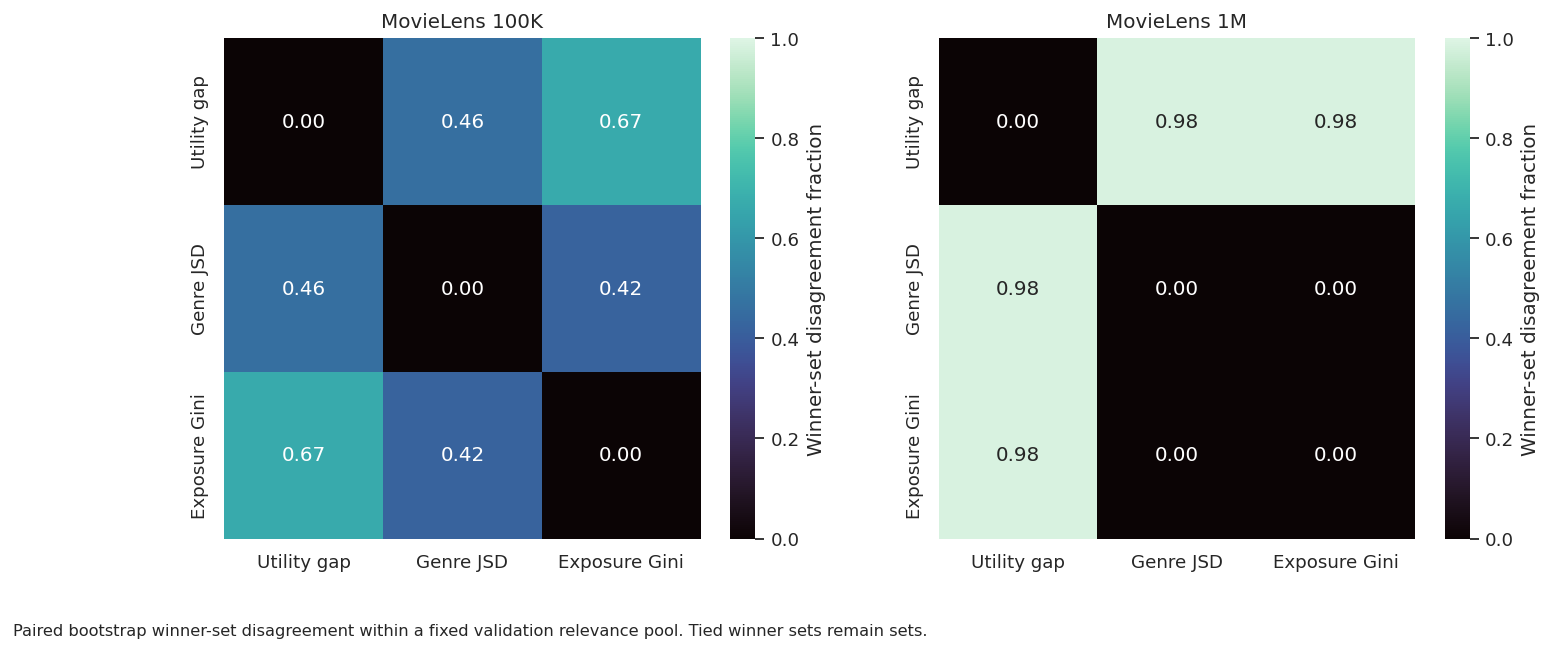

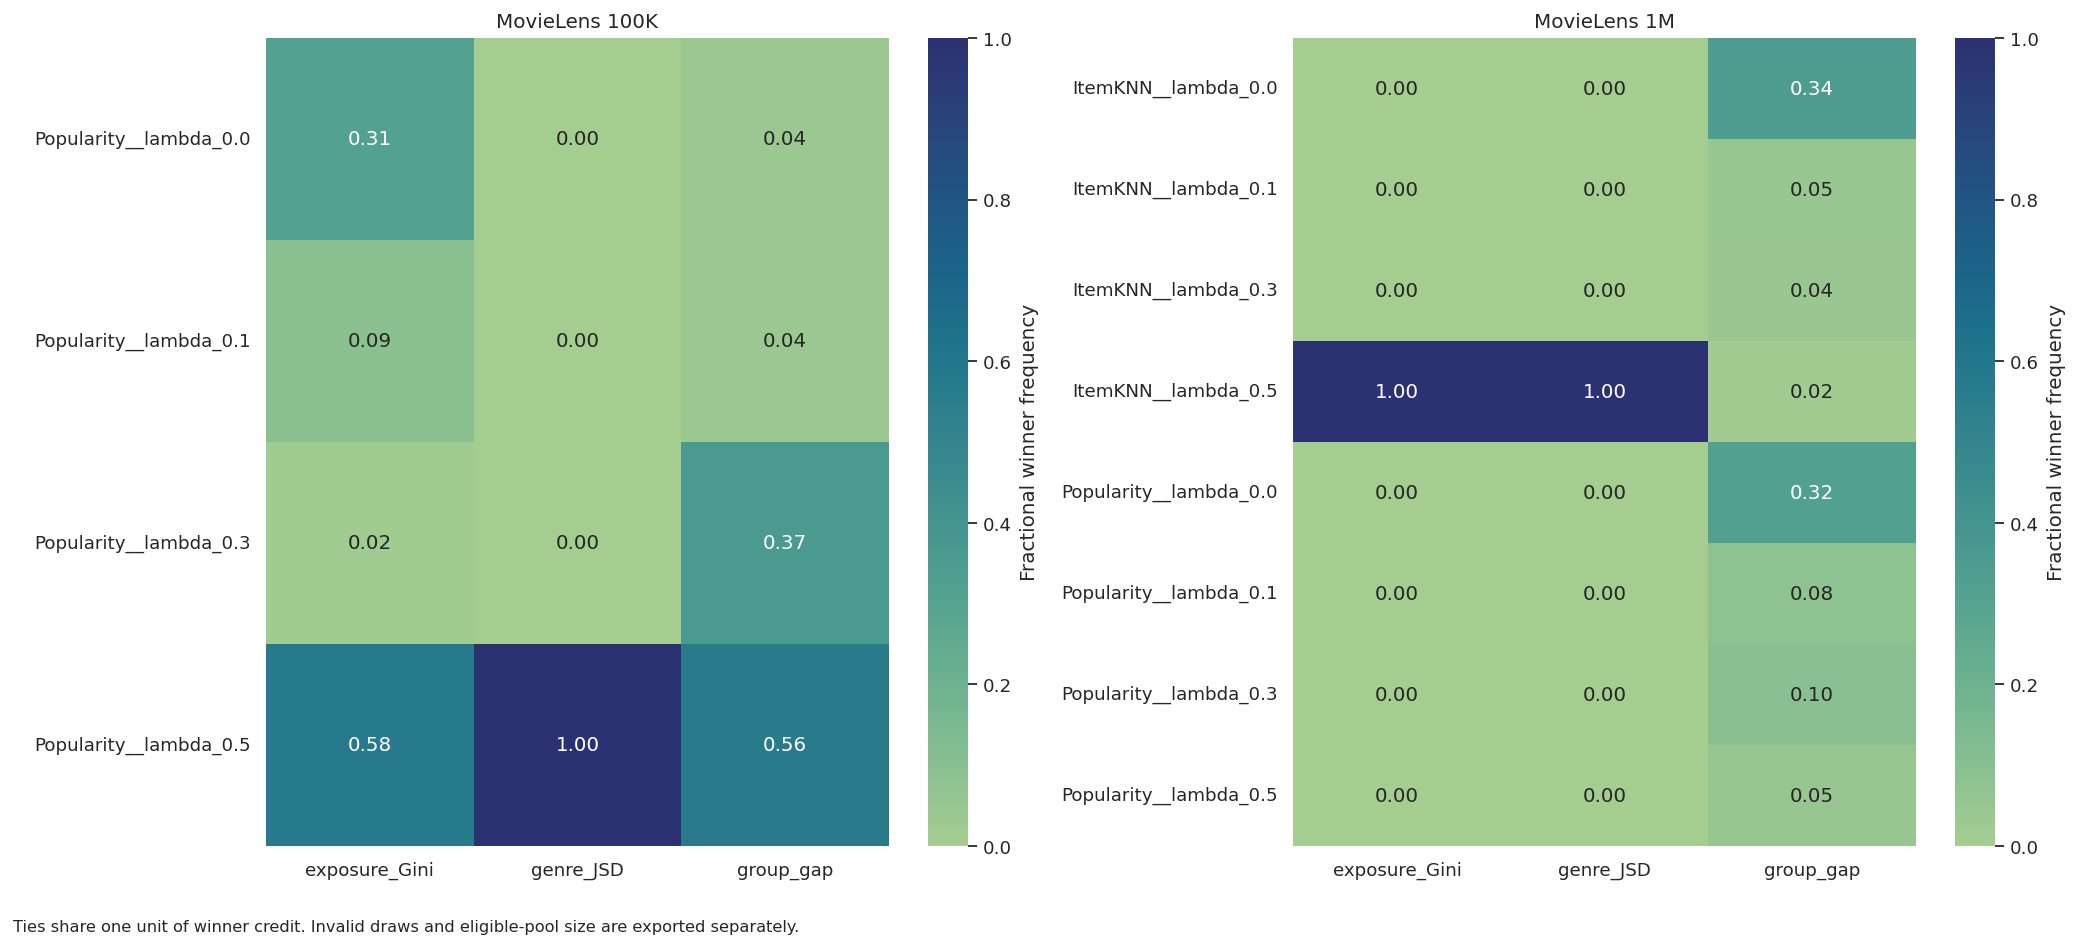

In [18]:
primary=C.seeds[0]
v=METRICS.query("window=='val' and K==10 and seed==@primary").copy()
v["relative_loss"]=v.groupby("dataset").NDCG.transform(lambda s:1-s/s.max() if s.max()>0 else np.nan)
v["eligible"]=v.relative_loss<=C.relevance_tolerance+1e-12
table(v[["dataset","candidate","NDCG","relative_loss","eligible"]],"RQ1_Table1_relevance_screen")
table(v[["dataset","candidate","group_gap","genre_JSD","exposure_Gini","eligible"]],"RQ1_Table2_objectives")
fig,axes=plt.subplots(1,len(C.datasets),figsize=(13,5),squeeze=False)
labels=["Utility gap","Genre JSD","Exposure Gini"]
for ax,tag in zip(axes[0],C.datasets):
    q=RANKS.query("dataset==@tag and seed==@primary")
    mat=q.pivot(index="objective_x",columns="objective_y",values="disagreement").reindex(index=[1,2,3],columns=[1,2,3])
    sns.heatmap(mat,annot=True,fmt=".2f",vmin=0,vmax=1,cmap="mako",ax=ax,
                xticklabels=labels,yticklabels=labels,cbar_kws={"label":"Winner-set disagreement fraction"})
    ax.set_title("MovieLens "+tag.upper());ax.set_xlabel("");ax.set_ylabel("")
figure(fig,"RQ1_Figure1_disagreement","Paired bootstrap winner-set disagreement within a fixed validation relevance pool. Tied winner sets remain sets.")
fig,axes=plt.subplots(1,len(C.datasets),figsize=(16,7),squeeze=False)
for ax,tag in zip(axes[0],C.datasets):
    q=WINNERS.query("dataset==@tag and seed==@primary")
    if len(q):
        mat=q.pivot(index="candidate",columns="objective",values="fractional_winner_support")
        sns.heatmap(mat,annot=True,fmt=".2f",cmap="crest",vmin=0,vmax=1,ax=ax,
                    cbar_kws={"label":"Fractional winner frequency"})
    else:ax.text(.5,.5,"No relevance-eligible comparisons",ha="center")
    ax.set_title("MovieLens "+tag.upper());ax.set_xlabel("");ax.set_ylabel("")
fig.tight_layout()
figure(fig,"RQ1_Figure2_winner_support","Ties share one unit of winner credit. Invalid draws and eligible-pool size are exported separately.")

## 18 RQ2 four planned exhibits

**RQ2.** Display simultaneous contrast intervals and later reversals by validation support, with exact contrast denominators. Compare adjusted and pointwise support in tables. Intervals describe conditional user-sampling variability, and calibration limitations remain visible.

**Correction and interpretation.** Missing outcomes are excluded from observable reversal denominators; planned, observed, missing, tied and non-tied counts are saved.


,dataset,seed,base,reranker,objective,gain,low,high,exploratory
0,100k,20261101,Popularity__lambda_0.0,Popularity__lambda_0.1,group_gap,0.000000,-1.000000,1.000000,True
1,100k,20261101,Popularity__lambda_0.0,Popularity__lambda_0.1,genre_JSD,0.002986,-0.543331,0.546317,True
2,100k,20261101,Popularity__lambda_0.0,Popularity__lambda_0.1,exposure_Gini,-0.000016,-0.999364,0.999364,True
3,100k,20261101,Popularity__lambda_0.0,Popularity__lambda_0.3,group_gap,0.003516,-1.000000,1.000000,True
4,100k,20261101,Popularity__lambda_0.0,Popularity__lambda_0.3,genre_JSD,0.009784,-0.536533,0.546317,True
...,...,...,...,...,...,...,...,...,...
292,1m,20261103,MF__lambda_0.0,MF__lambda_0.3,genre_JSD,0.018897,-0.428433,0.466228,True
293,1m,20261103,MF__lambda_0.0,MF__lambda_0.3,exposure_Gini,0.000188,-0.999715,0.999715,True
294,1m,20261103,MF__lambda_0.0,MF__lambda_0.5,group_gap,0.000893,-1.000000,1.000000,True
295,1m,20261103,MF__lambda_0.0,MF__lambda_0.5,genre_JSD,0.041743,-0.405588,0.489073,True


,dataset,seed,window,base,reranker,objective,gain,low,high,complete_draws,finite_column_draws,family_low_sensitivity,family_high_sensitivity,family_complete_draws_sensitivity,family_definition_sensitivity
0,100k,20261101,val,Popularity__lambda_0.0,Popularity__lambda_0.1,group_gap,0.000000,-1.000000,1.000000,792,792,NaN,NaN,792,9 contrasts/objective; alpha/3; added after fi...
1,100k,20261101,val,Popularity__lambda_0.0,Popularity__lambda_0.1,genre_JSD,0.002986,-0.543331,0.546317,792,1000,-0.000060,0.006032,1000,9 contrasts/objective; alpha/3; added after fi...
2,100k,20261101,val,Popularity__lambda_0.0,Popularity__lambda_0.1,exposure_Gini,-0.000016,-0.999364,0.999364,792,1000,-0.000154,0.000121,1000,9 contrasts/objective; alpha/3; added after fi...
3,100k,20261101,val,Popularity__lambda_0.0,Popularity__lambda_0.3,group_gap,0.003516,-1.000000,1.000000,792,792,NaN,NaN,792,9 contrasts/objective; alpha/3; added after fi...
4,100k,20261101,val,Popularity__lambda_0.0,Popularity__lambda_0.3,genre_JSD,0.009784,-0.536533,0.546317,792,1000,0.004302,0.015265,1000,9 contrasts/objective; alpha/3; added after fi...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
319,1m,20261103,test,MF__lambda_0.0,MF__lambda_0.3,genre_JSD,0.018118,-0.303997,0.340233,1000,1000,0.014418,0.021817,1000,9 contrasts/objective; alpha/3; added after fi...
320,1m,20261103,test,MF__lambda_0.0,MF__lambda_0.3,exposure_Gini,0.000044,-0.999715,0.999715,1000,1000,-0.000100,0.000188,1000,9 contrasts/objective; alpha/3; added after fi...
321,1m,20261103,test,MF__lambda_0.0,MF__lambda_0.5,group_gap,-0.006802,-0.871794,0.873920,1000,1000,-0.087324,0.073719,1000,9 contrasts/objective; alpha/3; added after fi...
322,1m,20261103,test,MF__lambda_0.0,MF__lambda_0.5,genre_JSD,0.037631,-0.284484,0.359745,1000,1000,0.032398,0.042864,1000,9 contrasts/objective; alpha/3; added after fi...


,dataset,seed,validation_status,planned_comparisons,comparisons,missing_outcomes,tied_comparisons,non_tied_comparisons,reversals,reversal_rate,pointwise_support_count,non_tied_reversal_rate
0,100k,20261101,unsupported,27,18,9,0,18,2.0,0.111111,10,0.111111
1,100k,20261102,unsupported,27,18,9,0,18,2.0,0.111111,11,0.111111
2,100k,20261103,unsupported,27,18,9,0,18,2.0,0.111111,11,0.111111
3,1m,20261101,unsupported,27,27,0,0,27,6.0,0.222222,14,0.222222
4,1m,20261102,unsupported,27,27,0,0,27,8.0,0.296296,13,0.296296
5,1m,20261103,unsupported,27,27,0,0,27,8.0,0.296296,14,0.296296


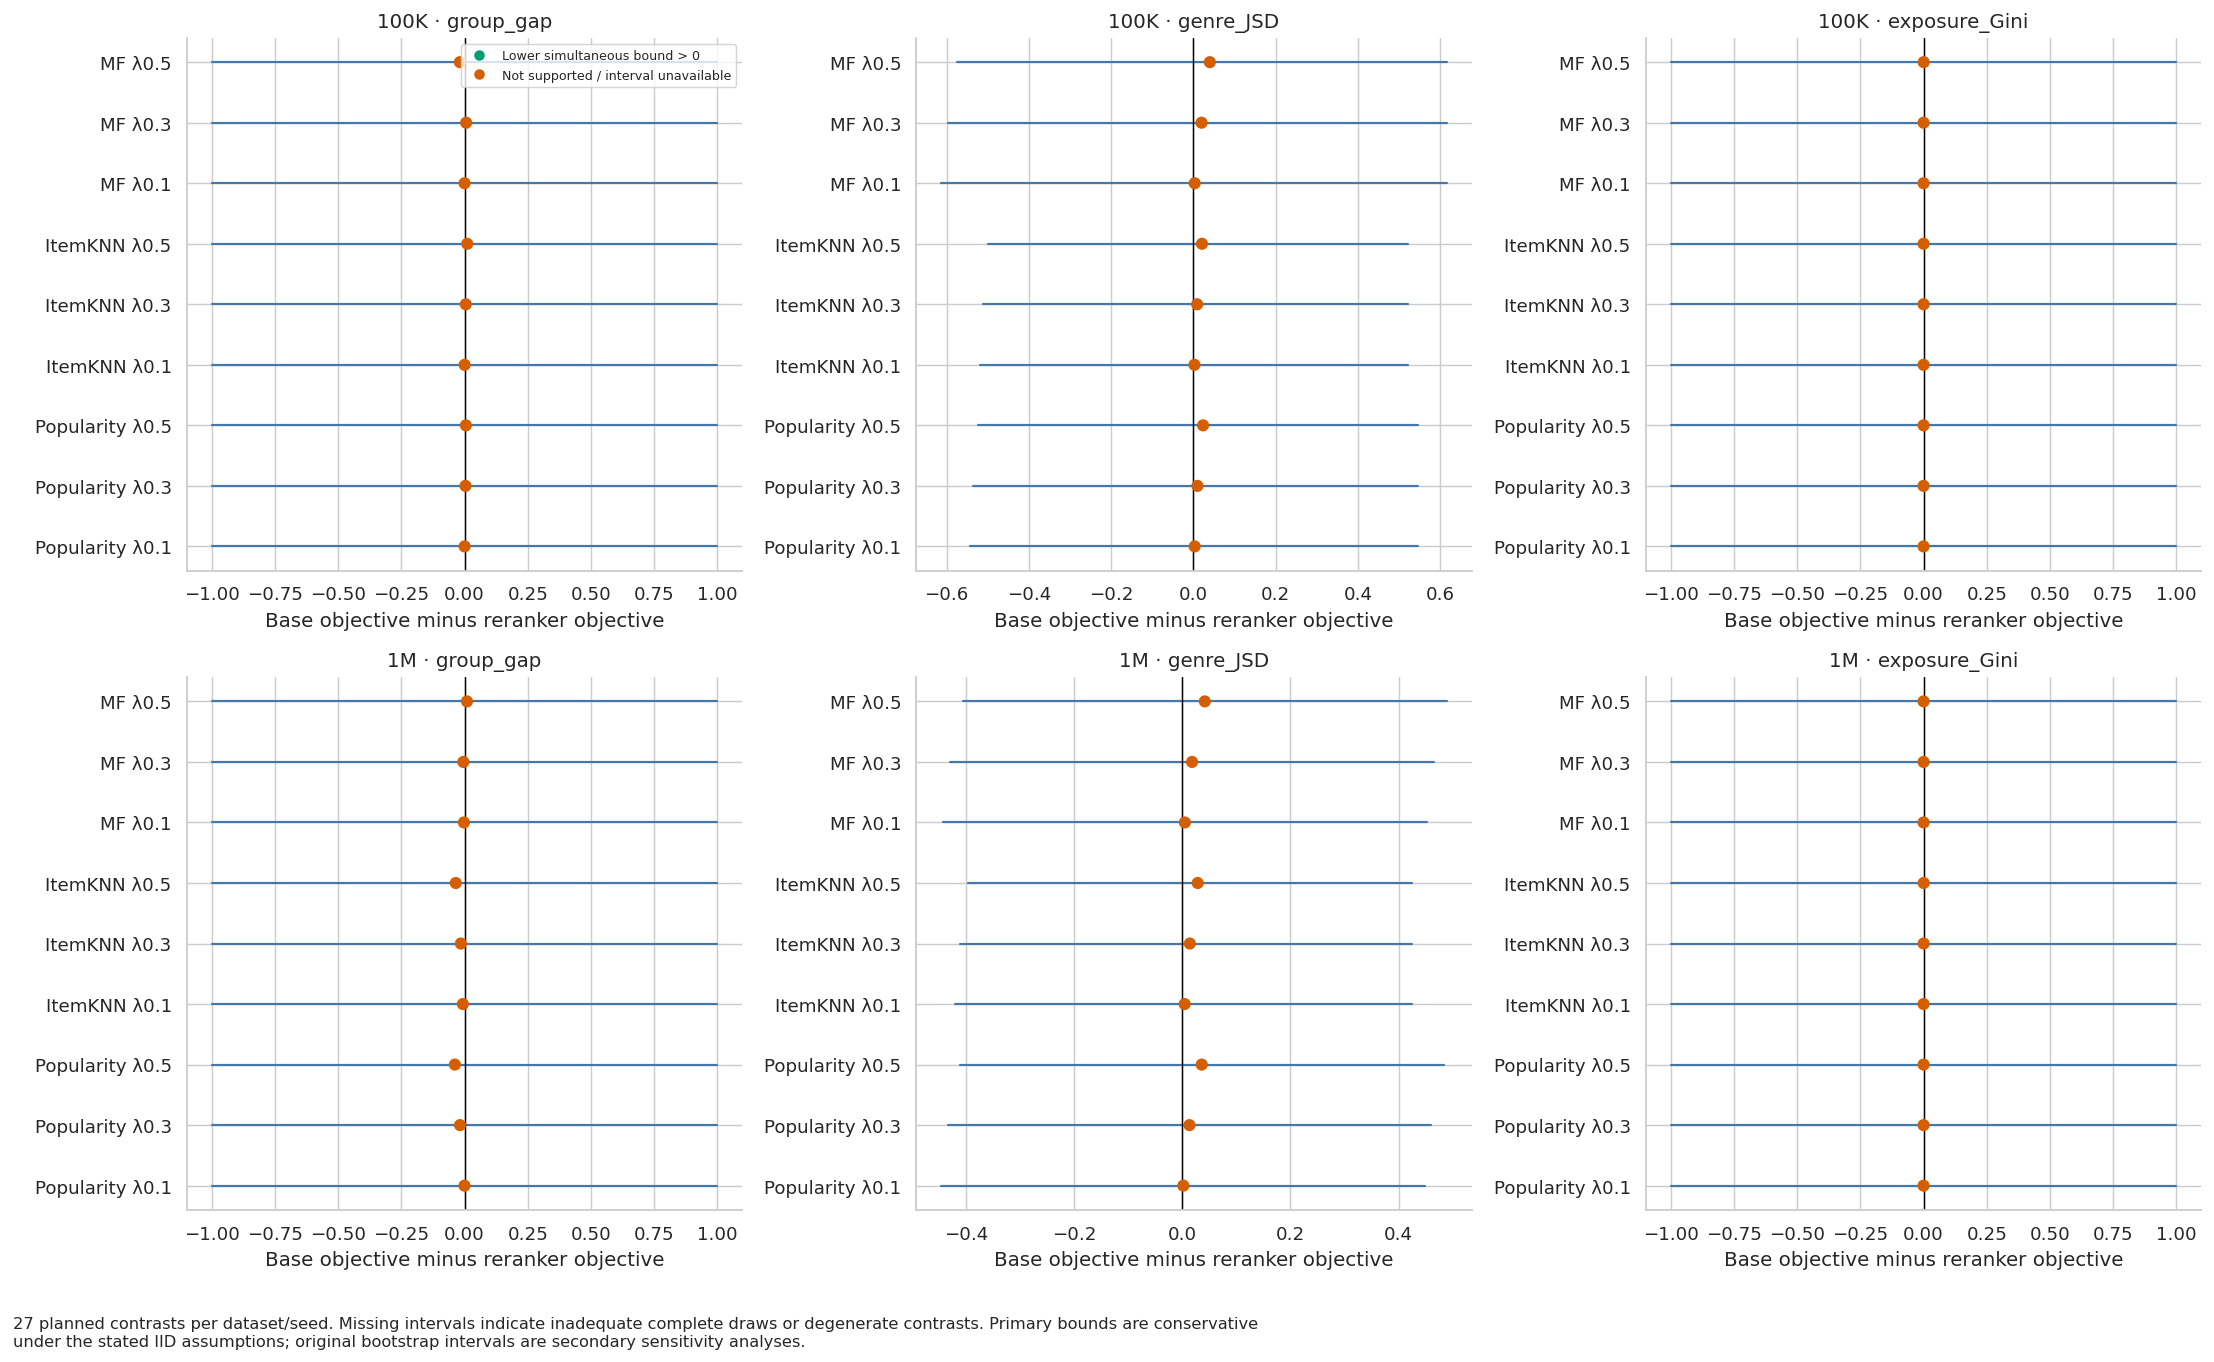

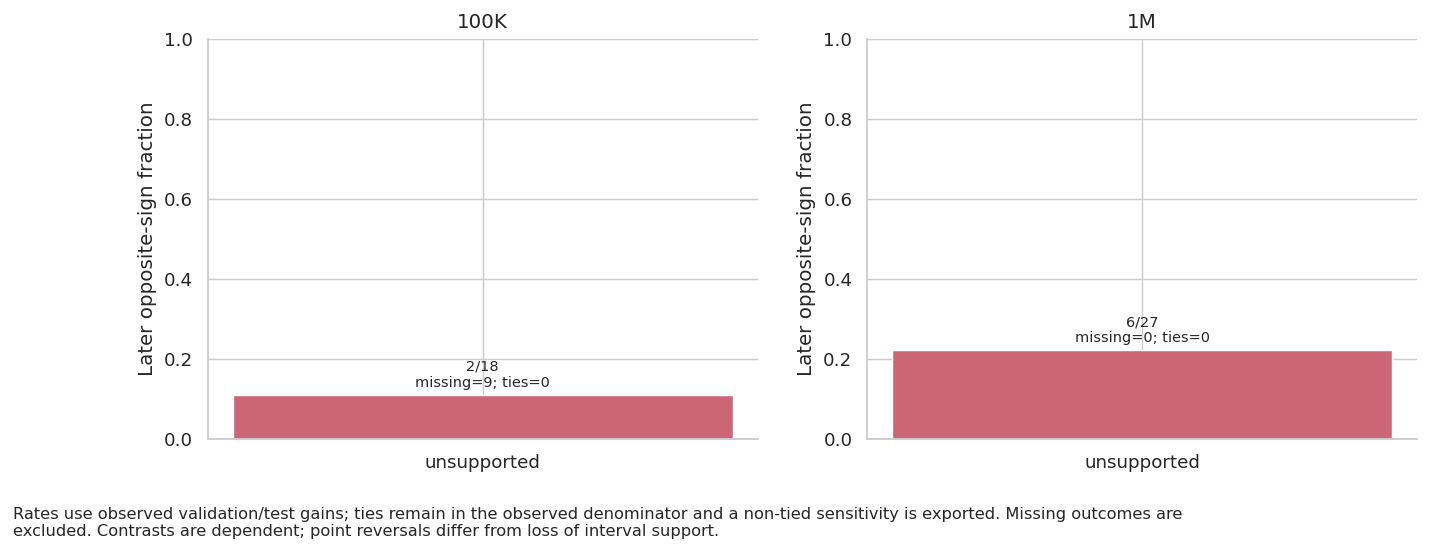

In [19]:
table(CONTRASTS.query("window=='val'")[["dataset","seed","base","reranker","objective","gain","low","high","exploratory"]],
      "RQ2_Table1_simultaneous_contrasts")
table(CONTRASTS[["dataset","seed","window","base","reranker","objective","gain",
      "low","high","complete_draws","finite_column_draws","family_low_sensitivity",
      "family_high_sensitivity","family_complete_draws_sensitivity","family_definition_sensitivity"]],
      "RQ2_fixed_family_interval_sensitivity")
summary=REVERSALS.groupby(["dataset","seed","validation_status"],dropna=False).agg(
    planned_comparisons=("reversal","size"),comparisons=("reversal","count"),
    missing_outcomes=("reversal_status",lambda s:int((s=="unavailable").sum())),
    tied_comparisons=("reversal_status",lambda s:int((s=="tie").sum())),
    non_tied_comparisons=("non_tied_observed","sum"),
    reversals=("reversal",lambda s:s.sum(min_count=1)),reversal_rate=("reversal","mean"),
    pointwise_support_count=("pointwise_supported_val","sum")).reset_index()
summary["non_tied_reversal_rate"]=summary.reversals/summary.non_tied_comparisons.replace(0,np.nan)
assert (summary.comparisons+summary.missing_outcomes==summary.planned_comparisons).all()
table(summary,"RQ2_Table2_reversal_denominators")
fig,axes=plt.subplots(len(C.datasets),3,figsize=(17,10),squeeze=False)
for row,tag in enumerate(C.datasets):
    for col,objective in enumerate(["group_gap","genre_JSD","exposure_Gini"]):
        ax=axes[row,col];q=CONTRASTS.query("dataset==@tag and seed==@primary and window=='val' and objective==@objective").reset_index(drop=True)
        y=np.arange(len(q));ok=np.isfinite(q.low)&np.isfinite(q.high)
        ax.scatter(q.gain,y,c=np.where(q.low>0,"#009E73","#D55E00"),s=35,zorder=3)
        for j in np.flatnonzero(ok):ax.plot([q.low[j],q.high[j]],[j,j],color="#4477AA")
        ax.axvline(0,color="black",lw=.8);ax.set_yticks(y,[s.split("__")[0]+" λ"+s.split("_")[-1] for s in q.reranker])
        ax.set_title(tag.upper()+" · "+objective);ax.set_xlabel("Base objective minus reranker objective")
from matplotlib.lines import Line2D
axes[0,0].legend(handles=[Line2D([],[],marker="o",ls="",color="#009E73",label="Lower simultaneous bound > 0"),
                         Line2D([],[],marker="o",ls="",color="#D55E00",label="Not supported / interval unavailable")],fontsize=7)
fig.tight_layout()
figure(fig,"RQ2_Figure1_simultaneous_intervals","27 planned contrasts per dataset/seed. Missing intervals indicate inadequate complete draws or degenerate contrasts. Primary bounds are conservative under the stated IID assumptions; original bootstrap intervals are secondary sensitivity analyses.")
fig,axes=plt.subplots(1,len(C.datasets),figsize=(12,4),squeeze=False)
for ax,tag in zip(axes[0],C.datasets):
    q=summary.query("dataset==@tag and seed==@primary")
    ax.bar(q.validation_status,q.reversal_rate,color=["#CC6677","#44AA99","#DDCC77"][:len(q)])
    for j,r in enumerate(q.itertuples()):
        label=(f"{int(r.reversals)}/{r.comparisons}" if np.isfinite(r.reversal_rate) else "Not estimable")
        ax.text(j,(r.reversal_rate if np.isfinite(r.reversal_rate) else 0)+.02,
                label+f"\nmissing={r.missing_outcomes}; ties={r.tied_comparisons}",ha="center",fontsize=8)
    ax.set_ylim(0,1);ax.set_ylabel("Later opposite-sign fraction");ax.set_title(tag.upper())
figure(fig,"RQ2_Figure2_later_reversals","Rates use observed validation/test gains; ties remain in the observed denominator and a non-tied sensitivity is exported. Missing outcomes are excluded. Contrasts are dependent; point reversals differ from loss of interval support.")


## 19 RQ3 four planned exhibits

**RQ3.** Jointly show stability and selectivity, abstention and threshold sensitivity, plus the separately matched DPFR comparison. Report unsupported reference frontiers explicitly. Larger sets cannot count as evidence of improvement without size controls.

**Correction and interpretation.** Read conditional stability jointly with abstention, union overlap and estimable-quality counts. No chart or summary assumes the bootstrap selector wins.


**Approved post-review additions.** Both dominated-member fraction (retained quality) and frontier recall (retained alternatives) accompany set size and abstention. FeasibilityAdaptedDPFR denotes the explicitly modified algorithm, not verified original-author parity.


,dataset,seed,rule,mean_size,empty_rate,test_dominated,median_test_loss,mean_eligible,quality_estimable_audits,nonempty_audits,...,family,attempted_audits,available_audits,unavailable_audits,mean_jaccard,mean_union_jaccard,nonempty_pairs,both_empty_pairs,one_empty_pairs,total_pairs
0,100k,20261101,Bootstrap,0.08,0.94,NaN,0.000000,3.20,0,3,...,main,50,50,0,0.666667,0.013889,3,1081,141,1225
1,100k,20261101,PointPareto,1.78,0.12,NaN,0.000725,3.20,0,44,...,main,50,50,0,0.257367,0.201214,946,15,264,1225
2,100k,20261101,SingleCalibration,1.00,0.00,NaN,0.000000,3.20,0,50,...,main,50,50,0,0.364898,0.364898,1225,0,0,1225
3,100k,20261101,SingleExposure,1.00,0.00,NaN,0.000000,3.20,0,50,...,main,50,50,0,0.191020,0.191020,1225,0,0,1225
4,100k,20261101,SingleGap,0.88,0.12,NaN,0.000000,3.20,0,44,...,main,50,50,0,0.230444,0.180165,946,15,264,1225
5,100k,20261101,SizeMatchedRandom,0.08,0.94,NaN,0.024606,3.20,0,3,...,main,50,50,0,0.166667,0.003472,3,1081,141,1225
6,100k,20261101,SizeMatchedRelevance,0.08,0.94,NaN,0.000000,3.20,0,3,...,main,50,50,0,0.666667,0.013889,3,1081,141,1225
7,100k,20261102,Bootstrap,0.04,0.96,NaN,0.000000,2.78,0,2,...,main,50,50,0,0.000000,0.000000,1,1128,96,1225
8,100k,20261102,PointPareto,1.14,0.30,NaN,0.000000,2.78,0,35,...,main,50,50,0,0.282661,0.150164,595,105,525,1225
9,100k,20261102,SingleCalibration,1.00,0.00,NaN,0.000000,2.78,0,50,...,main,50,50,0,0.401633,0.401633,1225,0,0,1225


,dataset,seed,rule,attempted_audits,available_audits,unavailable_audits
0,100k,20261101,FeasibilityAdaptedDPFR,50,50,0
1,100k,20261101,PairBootstrap,50,50,0
2,100k,20261101,PairPointPareto,50,50,0
3,100k,20261101,PairSizeMatchedRandom,50,50,0
4,100k,20261101,PairSizeMatchedRelevance,50,50,0
5,100k,20261102,FeasibilityAdaptedDPFR,50,50,0
6,100k,20261102,PairBootstrap,50,50,0
7,100k,20261102,PairPointPareto,50,50,0
8,100k,20261102,PairSizeMatchedRandom,50,50,0
9,100k,20261102,PairSizeMatchedRelevance,50,50,0


,dataset,seed,rule,mean_size,empty_rate,test_dominated,median_test_loss,quality_estimable_audits,mean_test_frontier_recall,frontier_estimable_audits,family,attempted_audits,available_audits,unavailable_audits,mean_jaccard,mean_union_jaccard,nonempty_pairs,both_empty_pairs,one_empty_pairs,total_pairs
0,100k,20261101,FeasibilityAdaptedDPFR,1.00,0.00,0.420000,0.000000,50,0.56,50,matched_pair,50,50,0,0.185306,0.185306,1225,0,0,1225
1,100k,20261101,PairBootstrap,0.68,0.32,0.235294,0.000000,34,0.49,50,matched_pair,50,50,0,0.269162,0.136652,561,120,544,1225
2,100k,20261101,PairPointPareto,1.54,0.00,0.395000,0.000734,50,0.78,50,matched_pair,50,50,0,0.235170,0.235170,1225,0,0,1225
3,100k,20261101,PairSizeMatchedRandom,0.68,0.32,0.647059,0.002618,34,0.22,50,matched_pair,50,50,0,0.142602,0.072398,561,120,544,1225
4,100k,20261101,PairSizeMatchedRelevance,0.68,0.32,0.411765,0.000000,34,0.39,50,matched_pair,50,50,0,0.237077,0.120362,561,120,544,1225
5,100k,20261102,FeasibilityAdaptedDPFR,1.00,0.00,0.380000,0.000000,50,0.60,50,matched_pair,50,50,0,0.197551,0.197551,1225,0,0,1225
6,100k,20261102,PairBootstrap,0.86,0.20,0.125000,0.000000,40,0.70,50,matched_pair,50,50,0,0.362821,0.239831,780,45,400,1225
7,100k,20261102,PairPointPareto,1.62,0.00,0.326667,0.000690,50,0.91,50,matched_pair,50,50,0,0.286190,0.286190,1225,0,0,1225
8,100k,20261102,PairSizeMatchedRandom,0.86,0.20,0.362500,0.000000,40,0.50,50,matched_pair,50,50,0,0.194444,0.128531,780,45,400,1225
9,100k,20261102,PairSizeMatchedRelevance,0.86,0.20,0.425000,0.000000,40,0.46,50,matched_pair,50,50,0,0.276496,0.182768,780,45,400,1225


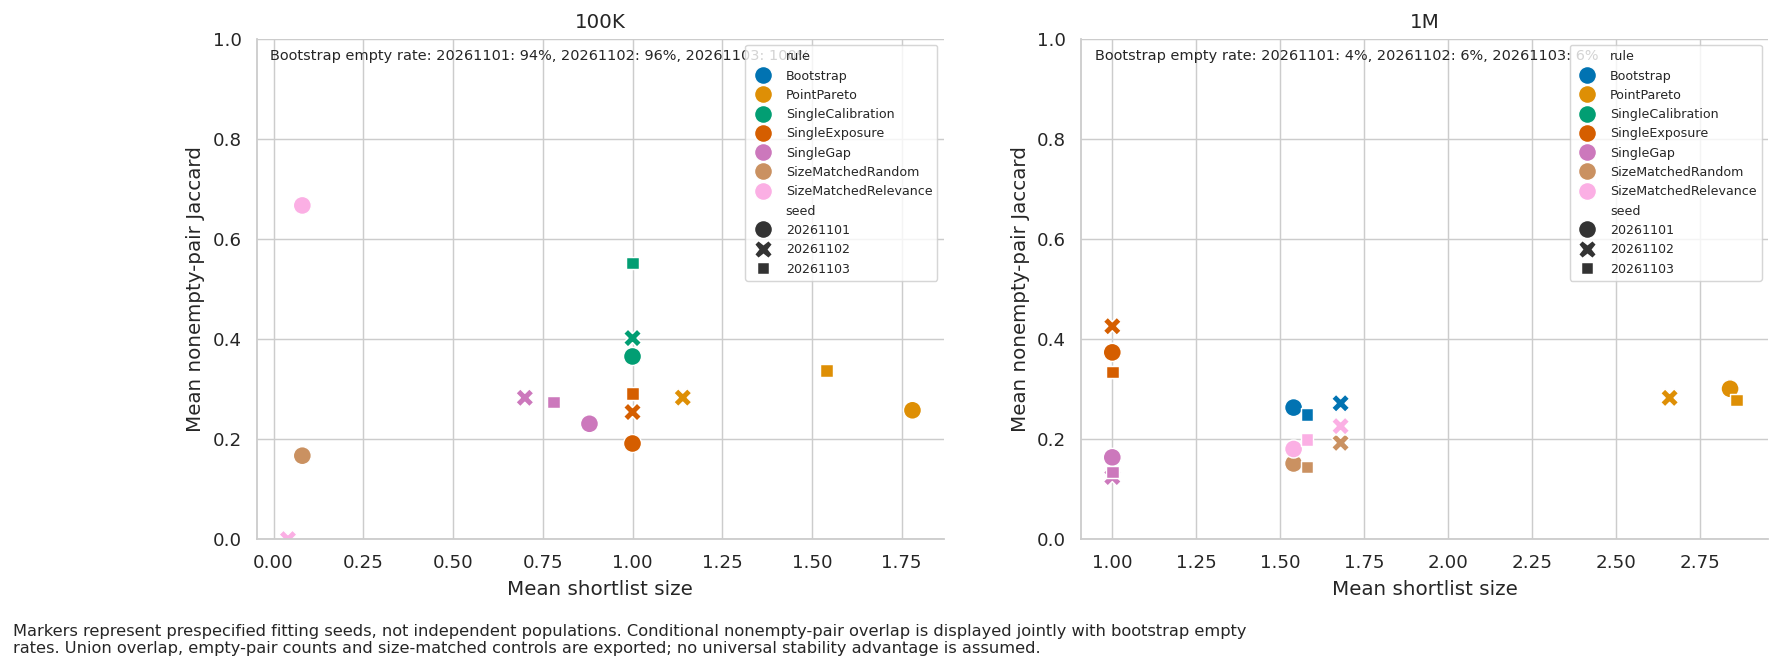

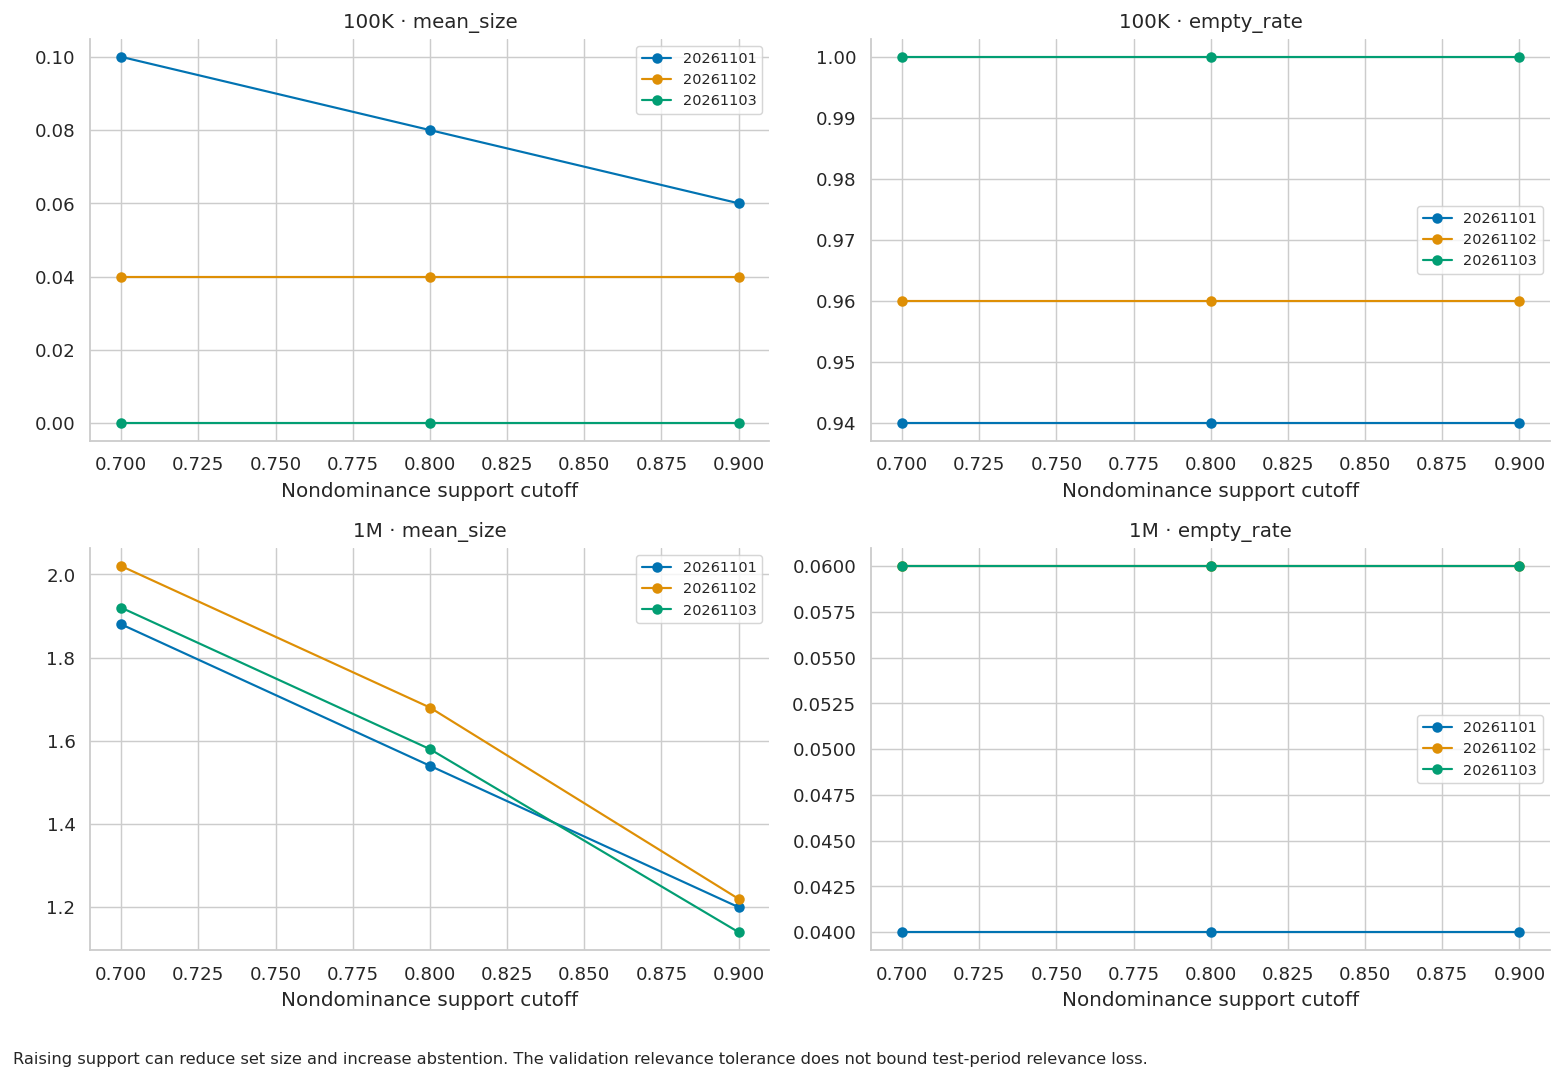

In [20]:
sel_summary=OUTER.groupby(["dataset","seed","rule"]).agg(mean_size=("size","mean"),
    empty_rate=("size",lambda s:np.mean(s.dropna()==0) if s.notna().any() else np.nan),test_dominated=("test_dominated","mean"),
    median_test_loss=("test_ndcg_loss","median"),mean_eligible=("eligible_count","mean"),
    quality_estimable_audits=("quality_available","sum"),
    nonempty_audits=("size",lambda s:int((s>0).sum())),
    mean_test_frontier_recall=("test_frontier_recall","mean"),
    frontier_estimable_audits=("frontier_estimable","sum")).reset_index()
table(sel_summary.merge(OVERLAPS.query("family=='main'").drop(columns="empty_rate"),on=["dataset","seed","rule"],how="left"),
      "RQ3_Table1_stability_selectivity_quality")
pair_availability=MATCHED.groupby(['dataset','seed','rule']).agg(
    attempted_audits=('reference_status','size'),available_audits=('size','count')).reset_index()
pair_availability['unavailable_audits']=pair_availability.attempted_audits-pair_availability.available_audits
table(pair_availability,'RQ3_comparator_availability')
pair_summary=MATCHED.groupby(["dataset","seed","rule"]).agg(
    mean_size=("size","mean"),empty_rate=("size",lambda s:np.mean(s.dropna()==0) if s.notna().any() else np.nan),
    test_dominated=("test_dominated","mean"),median_test_loss=("test_ndcg_loss","median"),
    quality_estimable_audits=("quality_available","sum"),
    mean_test_frontier_recall=("test_frontier_recall","mean"),
    frontier_estimable_audits=("frontier_estimable","sum")).reset_index()
table(pair_summary.merge(OVERLAPS.query("family=='matched_pair'").drop(columns="empty_rate"),
      on=["dataset","seed","rule"],how="left"),"RQ3_Table2_matched_DPFR")
fig,axes=plt.subplots(1,len(C.datasets),figsize=(15,5),squeeze=False)
for ax,tag in zip(axes[0],C.datasets):
    q=sel_summary.merge(OVERLAPS.query("family=='main'").drop(columns="empty_rate"),on=["dataset","seed","rule"])
    q=q.query("dataset==@tag")
    sns.scatterplot(data=q,x="mean_size",y="mean_jaccard",hue="rule",style="seed",s=100,ax=ax)
    ax.set_title(tag.upper());ax.set_xlabel("Mean shortlist size");ax.set_ylabel("Mean nonempty-pair Jaccard")
    ax.set_ylim(0,1);ax.legend(fontsize=7,loc="best")
    bq=q[q.rule=="Bootstrap"]
    ax.text(.02,.98,"Bootstrap empty rate: "+", ".join(f"{r.seed}: {r.empty_rate:.0%}" for r in bq.itertuples()),
            transform=ax.transAxes,va="top",fontsize=8)
figure(fig,"RQ3_Figure1_stability_size","Markers represent prespecified fitting seeds, not independent populations. Conditional nonempty-pair overlap is displayed jointly with bootstrap empty rates. Union overlap, empty-pair counts and size-matched controls are exported; no universal stability advantage is assumed.")
fig,axes=plt.subplots(len(C.datasets),2,figsize=(12,8),squeeze=False)
th=THRESHOLDS.groupby(["dataset","seed","threshold"]).agg(mean_size=("size","mean"),
    empty_rate=("size",lambda s:np.mean(s.dropna()==0) if s.notna().any() else np.nan)).reset_index()
for row,tag in enumerate(C.datasets):
    for col,y in enumerate(["mean_size","empty_rate"]):
        q=th.query("dataset==@tag")
        for seed,g in q.groupby("seed"):axes[row,col].plot(g.threshold,g[y],marker="o",label=str(seed))
        axes[row,col].set_title(tag.upper()+" · "+y);axes[row,col].set_xlabel("Nondominance support cutoff")
        axes[row,col].legend(fontsize=8)
fig.tight_layout()
figure(fig,"RQ3_Figure2_threshold_sensitivity","Raising support can reduce set size and increase abstention. The validation relevance tolerance does not bound test-period relevance loss.")


## 20 RQ4 four planned exhibits

**RQ4.** Show original subgroup resolution and composition sensitivity with distinct-user denominators. Conditional resampling cannot create additional observations. Marginal and intersectional counts remain separate, and coarse ages do not replace the original bands.

,dataset,window,attribute,group,distinct_users,exploratory
0,100k,val,gender,F,14,True
1,100k,val,gender,M,63,False
2,100k,val,age,1,3,True
3,100k,val,age,18,19,True
4,100k,val,age,25,29,True
...,...,...,...,...,...,...
99,1m,test,age_by_gender,45:M,17,True
100,1m,test,age_by_gender,50:F,6,True
101,1m,test,age_by_gender,50:M,12,True
102,1m,test,age_by_gender,56:F,1,True


,dataset,seed,F_share,method,mean_size,mean_overlap,mean_undefined,empty_rate,observed_overlap_audits,mean_union_overlap,distinct_F,distinct_M,distinct_total
0,100k,20261101,0.10,fixed_stratum,0.20,NaN,354.64,0.86,0,0.000000,7.34,47.58,54.92
1,100k,20261101,0.10,ordinary,0.18,NaN,359.28,0.86,0,0.000000,7.34,47.58,54.92
2,100k,20261101,0.25,fixed_stratum,0.36,NaN,261.52,0.68,0,0.000000,11.82,44.50,56.32
3,100k,20261101,0.25,ordinary,0.32,NaN,264.08,0.70,0,0.000000,11.82,44.50,56.32
4,100k,20261101,0.40,fixed_stratum,0.36,NaN,274.32,0.66,0,0.000000,13.32,39.00,52.32
5,100k,20261101,0.40,ordinary,0.36,NaN,275.54,0.66,0,0.000000,13.32,39.00,52.32
6,100k,20261102,0.10,fixed_stratum,0.18,NaN,420.68,0.88,0,0.000000,7.32,48.10,55.42
7,100k,20261102,0.10,ordinary,0.16,NaN,424.40,0.90,0,0.000000,7.32,48.10,55.42
8,100k,20261102,0.25,fixed_stratum,0.36,NaN,297.70,0.74,0,0.000000,11.68,44.34,56.02
9,100k,20261102,0.25,ordinary,0.34,NaN,303.28,0.76,0,0.000000,11.68,44.34,56.02


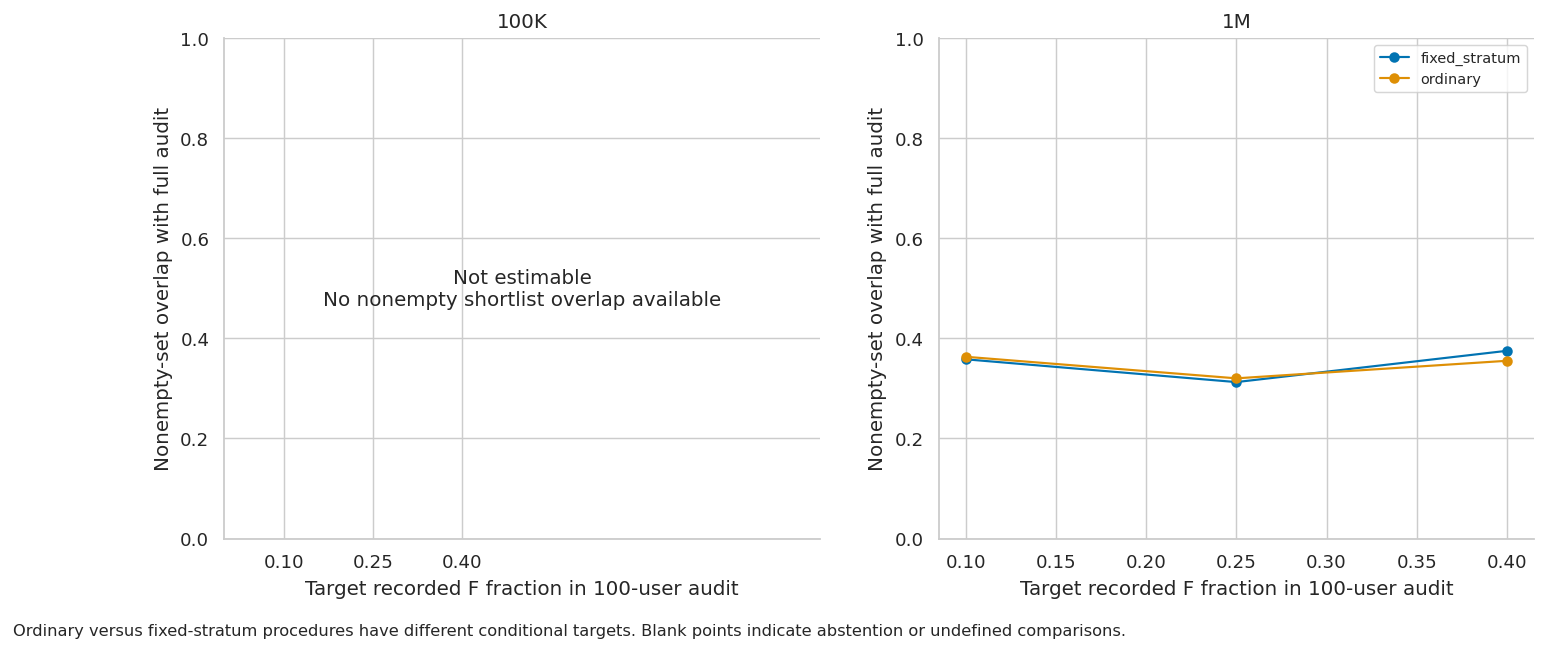

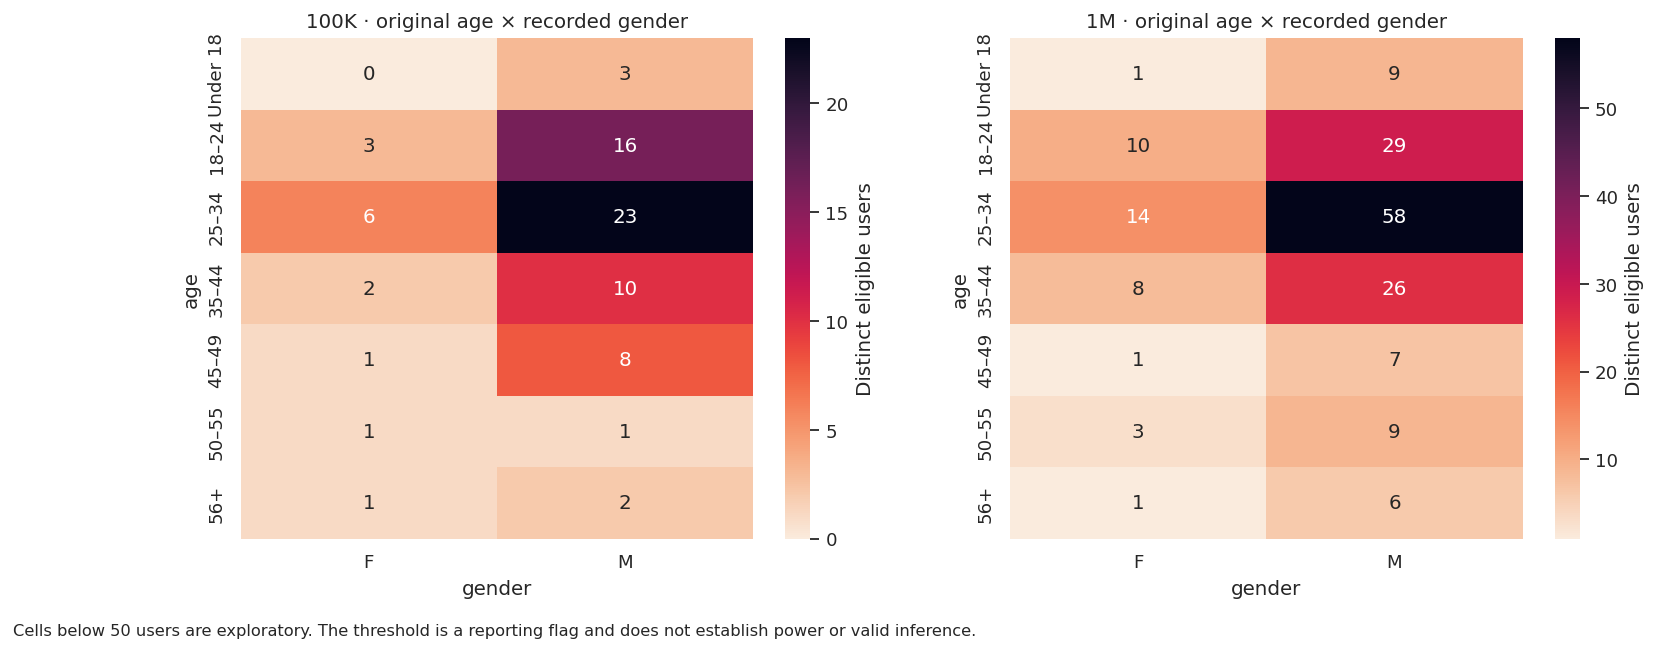

In [21]:
table(GROUPS,"RQ4_Table1_original_group_counts")
comp_summary=COMPOSITION.groupby(["dataset","seed","F_share","method"]).agg(
    mean_size=("size","mean"),mean_overlap=("overlap_to_full","mean"),
    mean_undefined=("undefined_draws","mean"),
    empty_rate=("size",lambda s:np.mean(s==0)),
    observed_overlap_audits=("overlap_to_full","count"),
    mean_union_overlap=("union_overlap_to_full","mean"),distinct_F=("distinct_F","mean"),
    distinct_M=("distinct_M","mean"),distinct_total=("distinct_audit_users","mean")).reset_index()
table(comp_summary,"RQ4_Table2_composition_resampling")
fig,axes=plt.subplots(1,len(C.datasets),figsize=(13,5),squeeze=False)
for ax,tag in zip(axes[0],C.datasets):
    q=comp_summary.query("dataset==@tag and seed==@primary")
    if not q.mean_overlap.notna().any():
        ax.text(.5,.5,'Not estimable\nNo nonempty shortlist overlap available',transform=ax.transAxes,ha='center',va='center')
        ax.set_xlim(0,1);ax.set_xticks([.1,.25,.4])
    else:
        for method,g in q.groupby('method'):ax.plot(g.F_share,g.mean_overlap,marker='o',label=method)
        ax.legend(fontsize=8)
    ax.set_ylim(0,1);ax.set_title(tag.upper());ax.set_xlabel("Target recorded F fraction in 100-user audit")
    ax.set_ylabel("Nonempty-set overlap with full audit")
figure(fig,"RQ4_Figure1_composition_stress","Ordinary versus fixed-stratum procedures have different conditional targets. Blank points indicate abstention or undefined comparisons.")
fig,axes=plt.subplots(1,len(C.datasets),figsize=(14,5),squeeze=False)
for ax,tag in zip(axes[0],C.datasets):
    q=GROUPS.query("dataset==@tag and window=='val' and attribute=='age_by_gender'").copy()
    q[["age","gender"]]=q.group.str.split(":",expand=True)
    mat=q.pivot(index="age",columns="gender",values="distinct_users").reindex(["1","18","25","35","45","50","56"])
    mat.index=mat.index.map(lambda x:AGE_LABELS[int(x)])
    sns.heatmap(mat,annot=True,fmt=".0f",cmap="rocket_r",ax=ax,cbar_kws={"label":"Distinct eligible users"})
    ax.set_title(tag.upper()+" · original age × recorded gender")
figure(fig,"RQ4_Figure2_resolution_map","Cells below 50 users are exploratory. The threshold is a reporting flag and does not establish power or valid inference.")

## 21 RQ5 four planned exhibits

**RQ5.** Display feasibility, observed-change reversals and profile trade-offs. If the repeat-user gate fails, figures state that limitation and tables retain counts. No synthetic values fill missing evidence. Group-gap changes and profile shortlist overlap are available in the detailed exports.

**Correction and interpretation.** Group-gap comparisons with missing original demographic groups are explicitly labelled not estimable, including the reference point.


,dataset,seed,common_users,usable_prior_change_users,low_n,mid_n,high_n,association_feasible
0,100k,20261101,24,21,7,7,7,False
1,100k,20261102,24,21,7,7,7,False
2,100k,20261103,24,21,7,7,7,False
3,1m,20261101,128,106,36,35,35,True
4,1m,20261102,128,106,36,35,35,True
5,1m,20261103,128,106,36,35,35,True


,dataset,seed,strategy,candidate,gap_change,low,high,complete_draws,supported_worsening,status,no_harm_established,exploratory,window,shortlist_size,overlap_to_full,complete_draws_selection,abstention
0,100k,20261101,recent,Popularity__lambda_0.0,NaN,NaN,NaN,0,NaN,not_estimable,False,True,test,0,NaN,0,True
1,100k,20261101,recent,Popularity__lambda_0.1,NaN,NaN,NaN,0,NaN,not_estimable,False,True,test,0,NaN,0,True
2,100k,20261101,recent,Popularity__lambda_0.3,NaN,NaN,NaN,0,NaN,not_estimable,False,True,test,0,NaN,0,True
3,100k,20261101,recent,Popularity__lambda_0.5,NaN,NaN,NaN,0,NaN,not_estimable,False,True,test,0,NaN,0,True
4,100k,20261101,recent,ItemKNN__lambda_0.0,NaN,NaN,NaN,0,NaN,not_estimable,False,True,test,0,NaN,0,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
139,1m,20261103,weighted,ItemKNN__lambda_0.5,-0.000502,-0.002349,0.002247,1000,False,exploratory_estimable,False,True,test,1,1.0,1000,False
140,1m,20261103,weighted,MF__lambda_0.0,0.000000,0.000000,0.000000,1000,False,exploratory_estimable,False,True,test,1,1.0,1000,False
141,1m,20261103,weighted,MF__lambda_0.1,0.000000,0.000000,0.000000,1000,False,exploratory_estimable,False,True,test,1,1.0,1000,False
142,1m,20261103,weighted,MF__lambda_0.3,0.000000,-0.002354,0.000000,1000,False,exploratory_estimable,False,True,test,1,1.0,1000,False


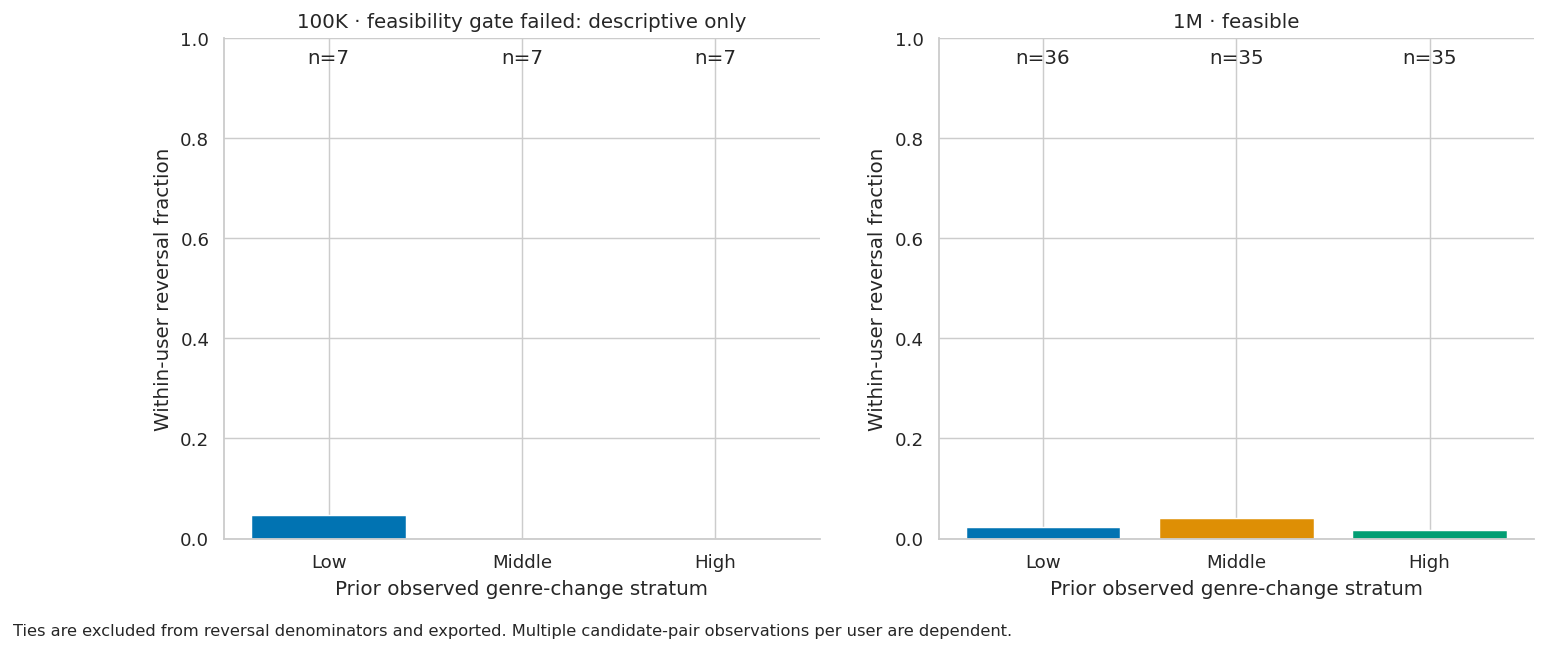

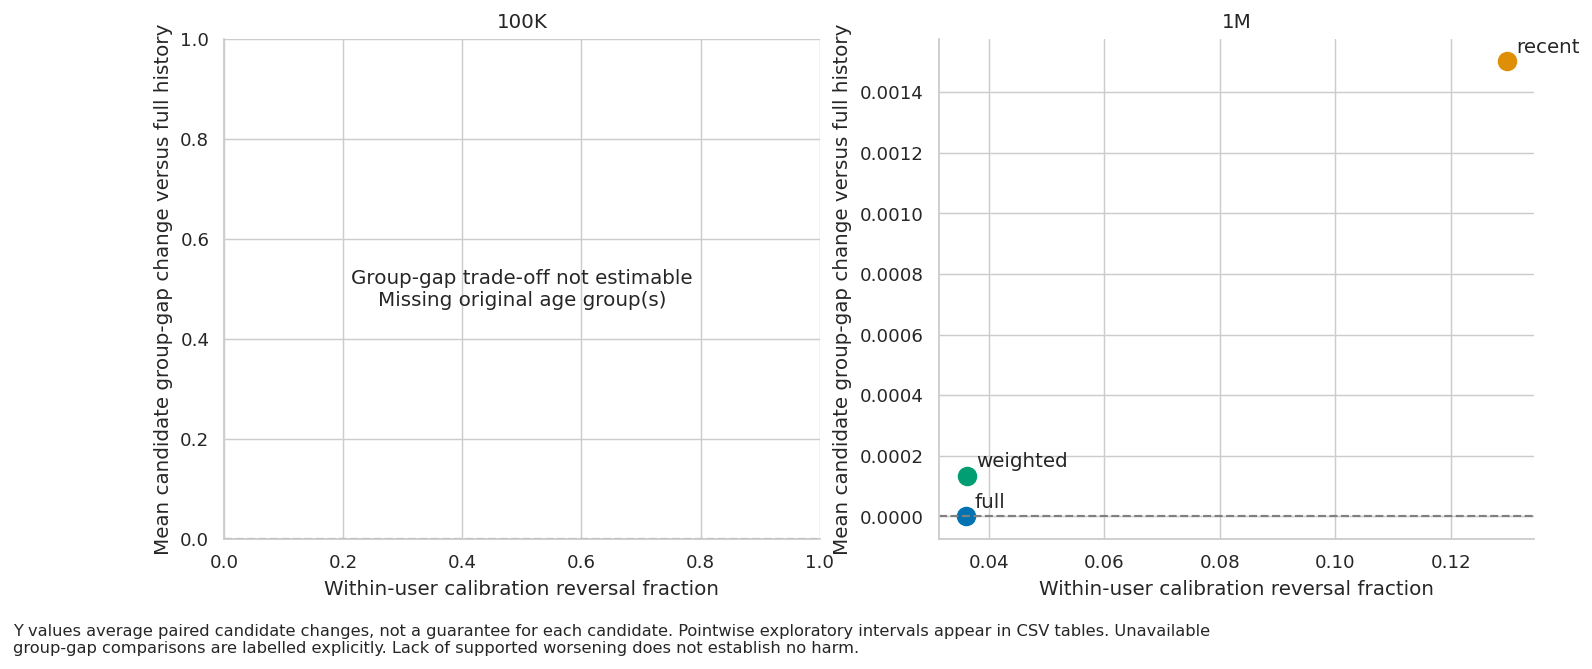

In [22]:
table(DRIFT_STATUS,"RQ5_Table1_repeat_user_funnel")
table(PROFILE_GAPS.merge(PROFILE_SETS.query("window=='test'"),
     on=["dataset","seed","strategy"],how="left",suffixes=("","_selection")),
     "RQ5_Table2_profile_changes_and_uncertainty")
fig,axes=plt.subplots(1,len(C.datasets),figsize=(13,5),squeeze=False)
for ax,tag in zip(axes[0],C.datasets):
    q=DRIFT.query("dataset==@tag and seed==@primary") if len(DRIFT) else pd.DataFrame()
    if len(q):
        ax.bar(q.stratum,q.reversal_rate,color=sns.color_palette("colorblind",3))
        ax.set_xticks([0,1,2],["Low","Middle","High"])
        for r in q.itertuples():ax.text(r.stratum,.95,f"n={r.distinct_users}",ha="center")
        status=bool(q.feasible.all())
        ax.set_title(tag.upper()+(" · feasible" if status else " · feasibility gate failed: descriptive only"))
    else:ax.text(.5,.5,"Insufficient repeat-user histories",ha="center",va="center",transform=ax.transAxes)
    ax.set_ylim(0,1);ax.set_xlabel("Prior observed genre-change stratum");ax.set_ylabel("Within-user reversal fraction")
figure(fig,"RQ5_Figure1_prior_change","Ties are excluded from reversal denominators and exported. Multiple candidate-pair observations per user are dependent.")
fig,axes=plt.subplots(1,len(C.datasets),figsize=(13,5),squeeze=False)
for ax,tag in zip(axes[0],C.datasets):
    q=PROFILE.query("dataset==@tag and seed==@primary and window=='paired'")
    for mode in ["full","recent","weighted"]:
        x=q.loc[q.strategy==mode,"reversal_rate"]
        g=PROFILE_GAPS.query("dataset==@tag and seed==@primary and strategy==@mode")
        y=0 if mode=="full" else g.gap_change.mean()
        if mode=="full" and not np.isfinite(POINT[tag,primary,"test",10][:,1]).all():y=np.nan
        if len(x) and np.isfinite(x.iloc[0]) and np.isfinite(y):
            ax.scatter(x.iloc[0],y,s=100,label=mode)
            ax.annotate(mode,(x.iloc[0],y),xytext=(5,5),textcoords="offset points")
    if not np.isfinite(POINT[tag,primary,"test",10][:,1]).all():
        ax.text(.5,.5,"Group-gap trade-off not estimable\nMissing original age group(s)",
                transform=ax.transAxes,ha="center",va="center")
    ax.axhline(0,color="gray",ls="--");ax.set_title(tag.upper())
    ax.set_xlabel("Within-user calibration reversal fraction")
    ax.set_ylabel("Mean candidate group-gap change versus full history")
figure(fig,"RQ5_Figure2_profile_tradeoffs","Y values average paired candidate changes, not a guarantee for each candidate. Pointwise exploratory intervals appear in CSV tables. Unavailable group-gap comparisons are labelled explicitly. Lack of supported worsening does not establish no harm.")


## Additional RQ3–RQ4 sensitivity: fixed demographic resolution
**RQ3/RQ4; added after reviewing the first run.** Preserve all original primary outcomes. Separately recompute validation selection and frozen test quality under two declared diagnostic definitions: gender-only utility gap, and the maximum of gender gap and fixed coarse-age gap (<25, 25–44, 45+). These require all groups in their respective definition. They are not substitutes for absent original age groups, independent confirmations, or evidence that fine-grained fairness has been achieved. The same 2% eligibility and support rules apply. This modest sensitivity uses full audits, not a second nested experiment. Save each definition and its group counts, bootstrap completeness and quality availability.


In [23]:
from dataclasses import replace
RESOLUTION=[]
for tag,d in DATA.items():
    for seed in C.seeds:
        for definition in ["gender_only","gender_and_fixed_coarse_age"]:
            audits={};points={};boots={}
            for window in ["val","test"]:
                a=AUDITS[tag,seed,window,10]
                keep=[j for j,g in enumerate(a.group_names) if g[0]=="gender"]
                groups=[a.groups[j] for j in keep];names=[a.group_names[j] for j in keep]
                if definition=="gender_and_fixed_coarse_age":
                    age=d["meta"].iloc[a.users].age.to_numpy()
                    for label,mask in [("<25",age<25),("25–44",(age>=25)&(age<45)),("45+",age>=45)]:
                        groups.append(mask.astype(float));names.append(("age",label))
                # Each sensitivity declares its own fixed group definition; the primary
                # audit objects remain unchanged.
                aa=replace(a,groups=groups,group_names=names)
                audits[window]=aa;points[window]=metrics(aa,np.ones(len(aa.users)))[0]
                boots[window]=bootstrap(aa,seed_for("resolution_sensitivity",tag,seed,window,definition))
            point=points["val"];eligible=eligibility(point)
            sets,support,complete=select_rules(point,boots["val"])
            for rule,S in sets.items():
                RESOLUTION.append(dict(dataset=tag,seed=seed,definition=definition,rule=rule,
                    complete_validation_draws=complete,
                    min_validation_group=min(int(g.sum()) for g in audits["val"].groups),
                    min_test_group=min(int(g.sum()) for g in audits["test"].groups),
                    decision_status=selection_status(point,boots["val"],S,eligible,complete) if rule=="Bootstrap" else "diagnostic",
                    added_after_first_run=True,**quality(S,points["test"],eligible)))
table(RESOLUTION,"RQ3_RQ4_group_resolution_sensitivity")


,dataset,seed,definition,rule,complete_validation_draws,min_validation_group,min_test_group,decision_status,added_after_first_run,size,test_dominated,test_ndcg_loss,quality_status,quality_available,frontier_estimable,test_frontier_size,test_frontier_retained,test_frontier_recall
0,100k,20261101,gender_only,SingleGap,1000,14,7,diagnostic,True,1,0.00,0.000000,estimable,True,True,1,1,1.0
1,100k,20261101,gender_only,SingleCalibration,1000,14,7,diagnostic,True,1,0.00,0.000000,estimable,True,True,1,1,1.0
2,100k,20261101,gender_only,SingleExposure,1000,14,7,diagnostic,True,1,0.00,0.000000,estimable,True,True,1,1,1.0
3,100k,20261101,gender_only,PointPareto,1000,14,7,diagnostic,True,1,0.00,0.000000,estimable,True,True,1,1,1.0
4,100k,20261101,gender_only,Bootstrap,1000,14,7,selected,True,1,0.00,0.000000,estimable,True,True,1,1,1.0
5,100k,20261101,gender_and_fixed_coarse_age,SingleGap,1000,14,6,diagnostic,True,1,0.00,0.000000,estimable,True,True,2,1,0.5
6,100k,20261101,gender_and_fixed_coarse_age,SingleCalibration,1000,14,6,diagnostic,True,1,0.00,0.000000,estimable,True,True,2,1,0.5
7,100k,20261101,gender_and_fixed_coarse_age,SingleExposure,1000,14,6,diagnostic,True,1,0.00,0.000000,estimable,True,True,2,1,0.5
8,100k,20261101,gender_and_fixed_coarse_age,PointPareto,1000,14,6,diagnostic,True,1,0.00,0.000000,estimable,True,True,2,1,0.5
9,100k,20261101,gender_and_fixed_coarse_age,Bootstrap,1000,14,6,selected,True,1,0.00,0.000000,estimable,True,True,2,1,0.5


,dataset,seed,definition,rule,complete_validation_draws,min_validation_group,min_test_group,decision_status,added_after_first_run,size,test_dominated,test_ndcg_loss,quality_status,quality_available,frontier_estimable,test_frontier_size,test_frontier_retained,test_frontier_recall
0,100k,20261101,gender_only,SingleGap,1000,14,7,diagnostic,True,1,0.00,0.000000,estimable,True,True,1,1,1.0
1,100k,20261101,gender_only,SingleCalibration,1000,14,7,diagnostic,True,1,0.00,0.000000,estimable,True,True,1,1,1.0
2,100k,20261101,gender_only,SingleExposure,1000,14,7,diagnostic,True,1,0.00,0.000000,estimable,True,True,1,1,1.0
3,100k,20261101,gender_only,PointPareto,1000,14,7,diagnostic,True,1,0.00,0.000000,estimable,True,True,1,1,1.0
4,100k,20261101,gender_only,Bootstrap,1000,14,7,selected,True,1,0.00,0.000000,estimable,True,True,1,1,1.0
5,100k,20261101,gender_and_fixed_coarse_age,SingleGap,1000,14,6,diagnostic,True,1,0.00,0.000000,estimable,True,True,2,1,0.5
6,100k,20261101,gender_and_fixed_coarse_age,SingleCalibration,1000,14,6,diagnostic,True,1,0.00,0.000000,estimable,True,True,2,1,0.5
7,100k,20261101,gender_and_fixed_coarse_age,SingleExposure,1000,14,6,diagnostic,True,1,0.00,0.000000,estimable,True,True,2,1,0.5
8,100k,20261101,gender_and_fixed_coarse_age,PointPareto,1000,14,6,diagnostic,True,1,0.00,0.000000,estimable,True,True,2,1,0.5
9,100k,20261101,gender_and_fixed_coarse_age,Bootstrap,1000,14,6,selected,True,1,0.00,0.000000,estimable,True,True,2,1,0.5


## Additional RQ3 contribution audit and analysis integrity
**RQ2/RQ3/RQ5.** Summarise within-audit bootstrap-versus-control differences for size, test dominated-member fraction and relevance loss. These are descriptive paired differences across dependent empirical audits, not confidence intervals or independent replications. Report better/tied/worse counts and paired observed denominators instead of declaring universal superiority. Check reversal accounting, matched size controls and unavailable profile outcomes. Export relevance screens across all seeds so exclusions and deterministic candidate behaviour remain visible. No settings are selected from this summary.


In [24]:
PAIRED=[]
for (tag,seed),g in OUTER.groupby(["dataset","seed"]):
    b=g[g.rule=="Bootstrap"]
    for control in ["PointPareto","SingleGap","SingleCalibration","SingleExposure","SizeMatchedRandom","SizeMatchedRelevance"]:
        c=g[g.rule==control]
        j=b.merge(c,on=["dataset","seed","audit"],suffixes=("_bootstrap","_control"))
        for endpoint in ["size","test_dominated","test_ndcg_loss","test_frontier_recall"]:
            diff=j[endpoint+"_bootstrap"]-j[endpoint+"_control"]
            finite=diff[np.isfinite(diff)]
            PAIRED.append(dict(dataset=tag,seed=seed,control=control,endpoint=endpoint,
                paired_audits=len(j),observed_pairs=len(finite),unavailable_pairs=len(j)-len(finite),
                mean_difference=finite.mean(),median_difference=finite.median(),
                bootstrap_lower=int((finite < -C.tie_tolerance).sum()),
                tied=int((abs(finite)<=C.tie_tolerance).sum()),
                bootstrap_higher=int((finite>C.tie_tolerance).sum()),
                interpretation="descriptive dependent audits; smaller size is selectivity; higher frontier recall retains more later nondominated configurations"))
table(PAIRED,"RQ3_paired_control_differences")
status=OUTER.groupby(["dataset","seed","rule","decision_status"],dropna=False).size().rename("audits").reset_index()
table(status,"RQ3_selection_status_counts")
for rule in ["SizeMatchedRandom","SizeMatchedRelevance"]:
    chk=OUTER[OUTER.rule=="Bootstrap"].merge(OUTER[OUTER.rule==rule],on=["dataset","seed","audit"])
    assert (chk.size_x==chk.size_y).all()
assert REVERSALS.loc[~REVERSALS.reversal_observed,"reversal"].isna().all()
assert PROFILE_GAPS.loc[PROFILE_GAPS.status=="not_estimable","supported_worsening"].isna().all()
screens=METRICS.query("window=='val' and K==10").copy()
screens["relative_loss"]=screens.groupby(["dataset","seed"]).NDCG.transform(lambda x:1-x/x.max())
screens["eligible"]=screens.relative_loss<=C.relevance_tolerance+C.tie_tolerance
table(screens,"RQ1_all_seed_relevance_screens")
write_json("analysis_integrity",{"checks_passed":True,"inference":"exploratory",
    "test_previously_inspected":True,"reversal_missing_excluded":True,
    "both_empty_not_perfect_stability":True,"size_controls_matched":True,
    "main_27_contrast_family_preserved":True,"support_is_not_confidence":True})


,dataset,seed,control,endpoint,paired_audits,observed_pairs,unavailable_pairs,mean_difference,median_difference,bootstrap_lower,tied,bootstrap_higher,interpretation
0,100k,20261101,PointPareto,size,50,50,0,-1.700000,-1.0,42,8,0,descriptive dependent audits; smaller size is ...
1,100k,20261101,PointPareto,test_dominated,50,0,50,NaN,NaN,0,0,0,descriptive dependent audits; smaller size is ...
2,100k,20261101,PointPareto,test_ndcg_loss,50,3,47,-0.008000,0.0,1,2,0,descriptive dependent audits; smaller size is ...
3,100k,20261101,PointPareto,test_frontier_recall,50,0,50,NaN,NaN,0,0,0,descriptive dependent audits; smaller size is ...
4,100k,20261101,SingleGap,size,50,50,0,-0.800000,-1.0,41,8,1,descriptive dependent audits; smaller size is ...
...,...,...,...,...,...,...,...,...,...,...,...,...,...
139,1m,20261103,SizeMatchedRandom,test_frontier_recall,50,50,0,0.263333,0.0,1,28,21,descriptive dependent audits; smaller size is ...
140,1m,20261103,SizeMatchedRelevance,size,50,50,0,0.000000,0.0,0,50,0,descriptive dependent audits; smaller size is ...
141,1m,20261103,SizeMatchedRelevance,test_dominated,50,47,3,-0.191489,0.0,11,36,0,descriptive dependent audits; smaller size is ...
142,1m,20261103,SizeMatchedRelevance,test_ndcg_loss,50,47,3,-0.011550,0.0,17,25,5,descriptive dependent audits; smaller size is ...


,dataset,seed,rule,decision_status,audits
0,100k,20261101,Bootstrap,insufficient_complete_bootstrap_draws,41
1,100k,20261101,Bootstrap,objective_unavailable,6
2,100k,20261101,Bootstrap,selected,3
3,100k,20261101,PointPareto,empty_or_unavailable,6
4,100k,20261101,PointPareto,selected,44
...,...,...,...,...,...
61,1m,20261103,SingleGap,selected,50
62,1m,20261103,SizeMatchedRandom,empty_or_unavailable,3
63,1m,20261103,SizeMatchedRandom,selected,47
64,1m,20261103,SizeMatchedRelevance,empty_or_unavailable,3


,dataset,seed,window,K,candidate,NDCG,group_gap,genre_JSD,exposure_Gini,relative_loss,eligible
12,100k,20261101,val,10,Popularity__lambda_0.0,0.128877,0.230455,0.210059,0.984013,0.000313,True
13,100k,20261101,val,10,Popularity__lambda_0.1,0.128877,0.230455,0.207073,0.984029,0.000313,True
14,100k,20261101,val,10,Popularity__lambda_0.3,0.127498,0.226938,0.200275,0.984066,0.011012,True
15,100k,20261101,val,10,Popularity__lambda_0.5,0.128918,0.225275,0.186688,0.983991,0.000000,True
16,100k,20261101,val,10,ItemKNN__lambda_0.0,0.113843,0.205617,0.184405,0.974123,0.116930,False
...,...,...,...,...,...,...,...,...,...,...,...
379,1m,20261103,val,10,ItemKNN__lambda_0.5,0.169486,0.248864,0.173275,0.986205,0.005046,True
380,1m,20261103,val,10,MF__lambda_0.0,0.090429,0.142876,0.293035,0.988946,0.469143,False
381,1m,20261103,val,10,MF__lambda_0.1,0.091048,0.151068,0.287196,0.988891,0.465513,False
382,1m,20261103,val,10,MF__lambda_0.3,0.090632,0.151418,0.274137,0.988758,0.467954,False


## Post-review endpoint reporting: coverage, temporal comparisons and profile stability
**RQ3–RQ5.** Display new coverage-versus-selectivity and temporal-comparison figures, plus the profile-strategy audit comparison. Frontier recall counts candidate configurations in a frozen eligible pool; identical objective vectors can represent different configurations, so it is not geometric diversity coverage. Recall includes zero for operational abstention only when the reference frontier is estimable. Dominated-member fractions remain conditional on a nonempty selection. Tables retain exact estimable denominators and status codes.

Size-conditioned summaries are descriptive; conditioning on size can select different audits for different rules. Paired comparisons use common audit IDs, and bootstrap-versus-control differences are not confidence intervals. The added profile experiments use identical outer/inner seeds across strategies. Comparative validation-to-test re-selection is retrospective; actual validation decisions are never revised using test data. Same-user results condition on later observability. All new analyses are post-review, and may return null or negative findings.


,dataset,seed,rule,size,audits,frontier_estimable_audits,mean_frontier_recall,mean_dominated_fraction,median_test_loss
0,100k,20261101,Bootstrap,0,47,0,NaN,NaN,NaN
1,100k,20261101,Bootstrap,1,2,0,NaN,NaN,0.000000
2,100k,20261101,Bootstrap,2,1,0,NaN,NaN,0.024606
3,100k,20261101,PointPareto,0,6,0,NaN,NaN,NaN
4,100k,20261101,PointPareto,1,20,0,NaN,NaN,0.000000
...,...,...,...,...,...,...,...,...,...
109,1m,20261103,SizeMatchedRelevance,0,3,3,0.000000,NaN,NaN
110,1m,20261103,SizeMatchedRelevance,1,24,24,0.430556,0.291667,0.000830
111,1m,20261103,SizeMatchedRelevance,2,15,15,0.766667,0.500000,0.001818
112,1m,20261103,SizeMatchedRelevance,3,7,7,0.928571,0.428571,0.009925


,dataset,seed,rule,mean_size,empty_rate,mean_recall,mean_dominated,estimable_frontiers
0,100k,20261101,Bootstrap,0.08,0.94,NaN,NaN,0
1,100k,20261101,PointPareto,1.78,0.12,NaN,NaN,0
2,100k,20261101,SingleCalibration,1.00,0.00,NaN,NaN,0
3,100k,20261101,SingleExposure,1.00,0.00,NaN,NaN,0
4,100k,20261101,SingleGap,0.88,0.12,NaN,NaN,0
5,100k,20261101,SizeMatchedRandom,0.08,0.94,NaN,NaN,0
6,100k,20261101,SizeMatchedRelevance,0.08,0.94,NaN,NaN,0
7,100k,20261102,Bootstrap,0.04,0.96,NaN,NaN,0
8,100k,20261102,PointPareto,1.14,0.30,NaN,NaN,0
9,100k,20261102,SingleCalibration,1.00,0.00,NaN,NaN,0


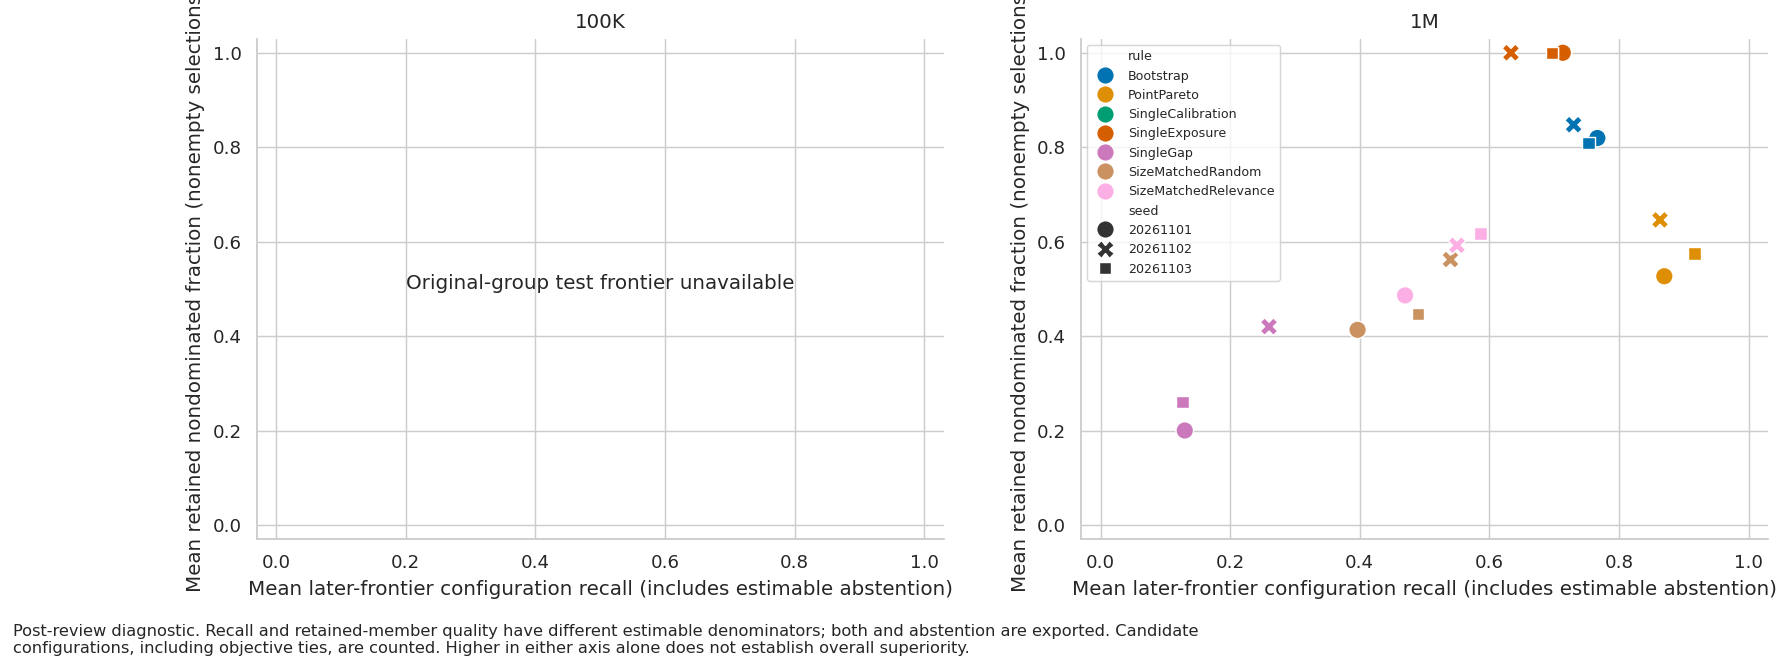

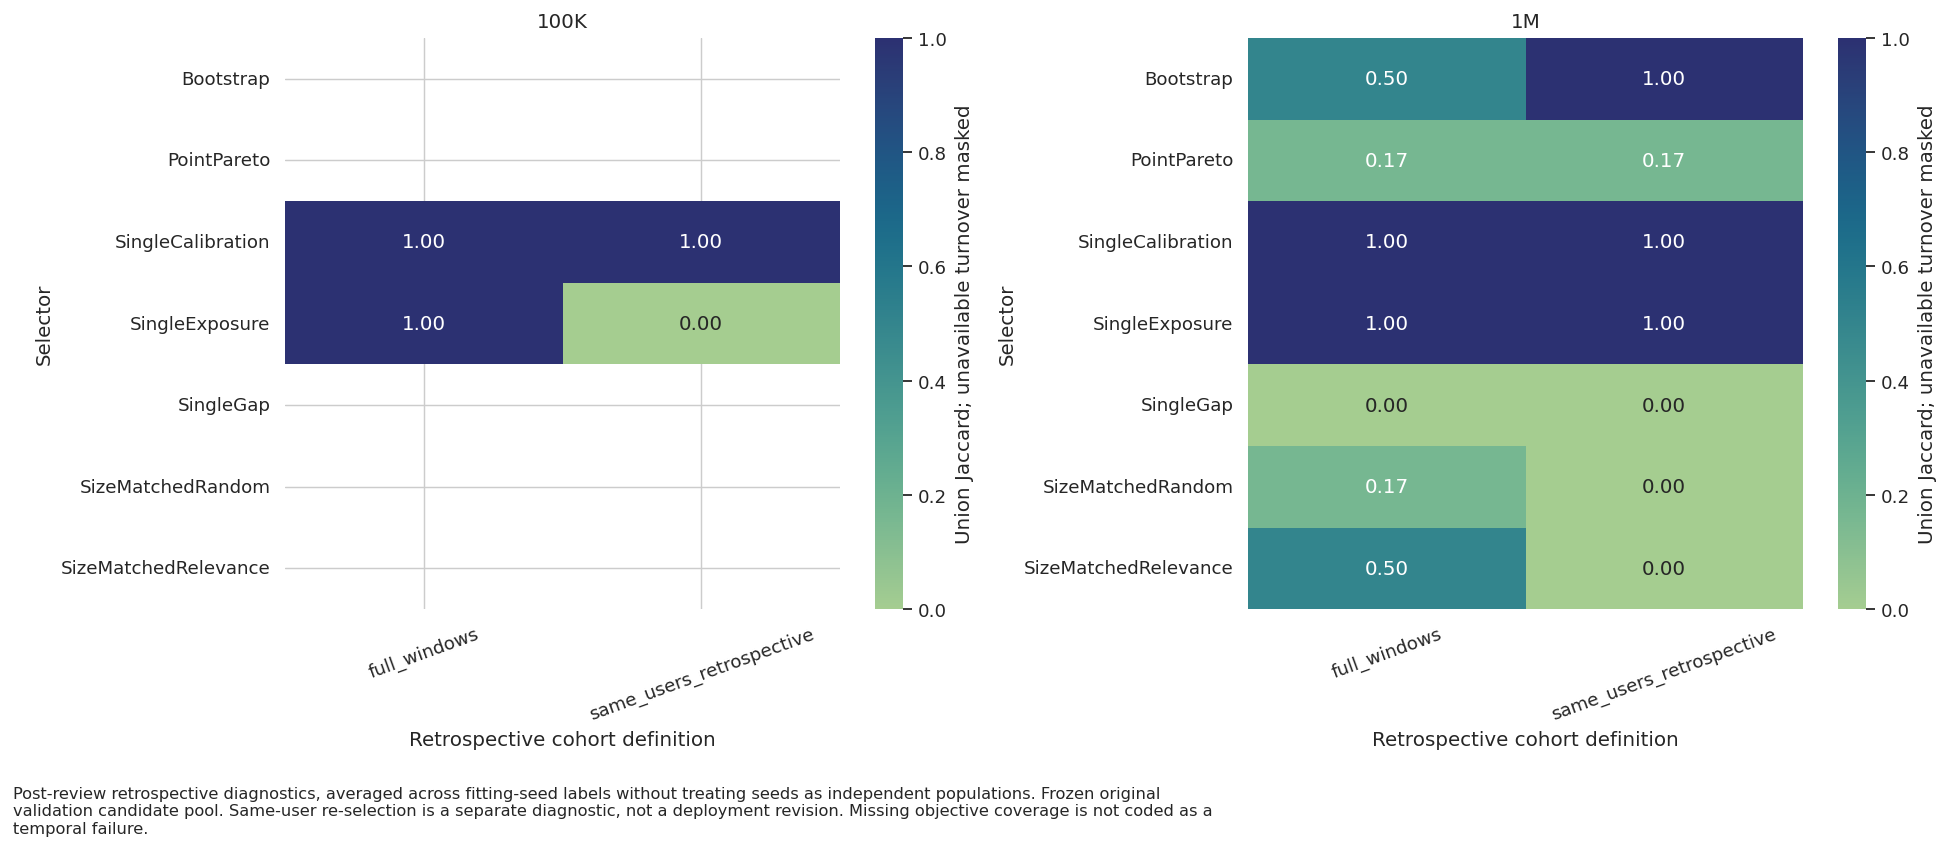

,dataset,seed,pool_definition,rule,strategy,audit_pairs,conditional_observed_pairs,mean_paired_conditional_change,union_observed_pairs,mean_paired_union_change,interpretation
0,100k,20261101,common_full_history_screen,Bootstrap,recent,190,0,NaN,0,NaN,dependent audit pairs; descriptive differences...
1,100k,20261101,common_full_history_screen,Bootstrap,weighted,190,0,NaN,0,NaN,dependent audit pairs; descriptive differences...
2,100k,20261101,common_full_history_screen,PointPareto,recent,190,120,-0.002778,184,-0.001812,dependent audit pairs; descriptive differences...
3,100k,20261101,common_full_history_screen,PointPareto,weighted,190,120,-0.011806,184,-0.007699,dependent audit pairs; descriptive differences...
4,100k,20261101,common_full_history_screen,SingleCalibration,recent,190,190,0.000000,190,0.000000,dependent audit pairs; descriptive differences...
...,...,...,...,...,...,...,...,...,...,...,...
163,1m,20261103,own_audit_validation_screen,SingleGap,weighted,190,190,-0.005263,190,-0.005263,dependent audit pairs; descriptive differences...
164,1m,20261103,own_audit_validation_screen,SizeMatchedRandom,recent,190,190,0.017105,190,0.017105,dependent audit pairs; descriptive differences...
165,1m,20261103,own_audit_validation_screen,SizeMatchedRandom,weighted,190,190,-0.020175,190,-0.020175,dependent audit pairs; descriptive differences...
166,1m,20261103,own_audit_validation_screen,SizeMatchedRelevance,recent,190,190,-0.022982,190,-0.022982,dependent audit pairs; descriptive differences...


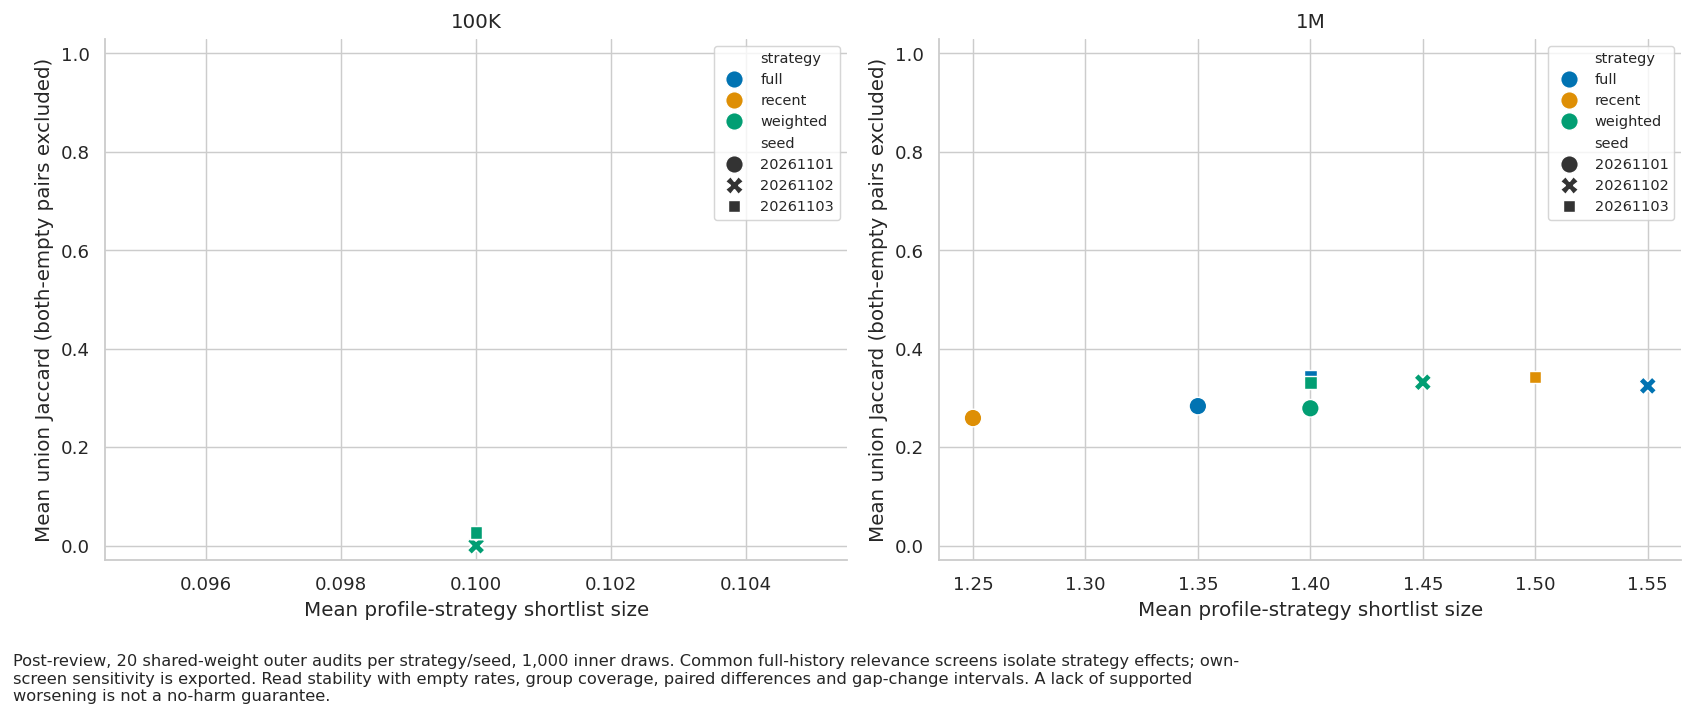

In [25]:
# Configuration recall is complementary to conditional retained-member quality.
size_conditioned=OUTER.groupby(['dataset','seed','rule','size'],dropna=False).agg(
    audits=('audit','size'),frontier_estimable_audits=('frontier_estimable','sum'),
    mean_frontier_recall=('test_frontier_recall','mean'),
    mean_dominated_fraction=('test_dominated','mean'),median_test_loss=('test_ndcg_loss','median')).reset_index()
table(size_conditioned,'RQ3_size_conditioned_coverage_and_quality')
# Coverage summaries on the same audit IDs as each comparator.
coverage_summary=OUTER.groupby(['dataset','seed','rule']).agg(
    mean_size=('size','mean'),empty_rate=('size',lambda s:np.mean(s==0)),
    mean_recall=('test_frontier_recall','mean'),mean_dominated=('test_dominated','mean'),
    estimable_frontiers=('frontier_estimable','sum')).reset_index()
table(coverage_summary,'RQ3_frontier_recall_and_retained_quality')
fig,axes=plt.subplots(1,len(C.datasets),figsize=(15,5),squeeze=False)
for ax,tag in zip(axes[0],C.datasets):
    q=coverage_summary[coverage_summary.dataset==tag].copy()
    q['retained_nondominated_fraction']=1-q.mean_dominated
    if q.mean_recall.notna().any():
        sns.scatterplot(data=q,x='mean_recall',y='retained_nondominated_fraction',hue='rule',style='seed',s=95,ax=ax)
        ax.legend(fontsize=7,loc='best')
    else:ax.text(.5,.5,'Original-group test frontier unavailable',transform=ax.transAxes,ha='center')
    ax.set(xlim=(-.03,1.03),ylim=(-.03,1.03),title=tag.upper(),
        xlabel='Mean later-frontier configuration recall (includes estimable abstention)',
        ylabel='Mean retained nondominated fraction (nonempty selections)')
figure(fig,'RQ3_Figure3_frontier_coverage','Post-review diagnostic. Recall and retained-member quality have different estimable denominators; both and abstention are exported. Candidate configurations, including objective ties, are counted. Higher in either axis alone does not establish overall superiority.')
fig,axes=plt.subplots(1,len(C.datasets),figsize=(15,6),squeeze=False)
for ax,tag in zip(axes[0],C.datasets):
    q=TEMPORAL[(TEMPORAL.dataset==tag)&(TEMPORAL.metric_family=='three_fairness_objectives')]
    mat=q.groupby(['rule','scope']).union_jaccard.mean().unstack()
    if mat.notna().any().any():sns.heatmap(mat,annot=True,fmt='.2f',vmin=0,vmax=1,cmap='crest',ax=ax,cbar_kws={'label':'Union Jaccard; unavailable turnover masked'})
    else:ax.text(.5,.5,'Turnover not estimable',transform=ax.transAxes,ha='center')
    ax.set_title(tag.upper());ax.set_xlabel('Retrospective cohort definition');ax.set_ylabel('Selector')
    ax.tick_params(axis='x',rotation=20)
fig.tight_layout()
figure(fig,'RQ3_Figure4_comparative_turnover','Post-review retrospective diagnostics, averaged across fitting-seed labels without treating seeds as independent populations. Frozen original validation candidate pool. Same-user re-selection is a separate diagnostic, not a deployment revision. Missing objective coverage is not coded as a temporal failure.')
# Profile strategies: direct paired audit-pair differences in Jaccard.
profile_stability_pairs=[]
for (tag,seed,pool,rule),g in PROFILE_NESTED.groupby(['dataset','seed','pool_definition','rule']):
    full=g[g.strategy=='full'][['audit','selected']]
    for mode in ['recent','weighted']:
        paired=g[g.strategy==mode][['audit','selected']].merge(full,on='audit',suffixes=('_strategy','_full')).sort_values('audit')
        conditional=[];union=[]
        for i in range(len(paired)):
            a=paired.iloc[i]
            A=set(filter(None,a.selected_strategy.split(';')));F=set(filter(None,a.selected_full.split(';')))
            for j in range(i):
                b=paired.iloc[j]
                B=set(filter(None,b.selected_strategy.split(';')));G=set(filter(None,b.selected_full.split(';')))
                conditional.append(overlap(A,B)-overlap(F,G))
                union.append(union_overlap(A,B)-union_overlap(F,G))
        cv=np.array(conditional);uv=np.array(union)
        profile_stability_pairs.append(dict(dataset=tag,seed=seed,pool_definition=pool,rule=rule,strategy=mode,
            audit_pairs=len(cv),conditional_observed_pairs=int(np.isfinite(cv).sum()),
            mean_paired_conditional_change=float(np.nanmean(cv)) if np.isfinite(cv).any() else np.nan,
            union_observed_pairs=int(np.isfinite(uv).sum()),
            mean_paired_union_change=float(np.nanmean(uv)) if np.isfinite(uv).any() else np.nan,
            interpretation='dependent audit pairs; descriptive differences only; no no-harm conclusion'))
table(profile_stability_pairs,'RQ5_paired_stability_changes')
fig,axes=plt.subplots(1,len(C.datasets),figsize=(13,5),squeeze=False)
for ax,tag in zip(axes[0],C.datasets):
    q=PROFILE_STABILITY[(PROFILE_STABILITY.dataset==tag)&(PROFILE_STABILITY.rule=='Bootstrap')&
        (PROFILE_STABILITY.pool_definition=='common_full_history_screen')]
    if q.mean_union_jaccard.notna().any():
        sns.scatterplot(data=q,x='mean_size',y='mean_union_jaccard',hue='strategy',style='seed',s=95,ax=ax)
    else:ax.text(.5,.5,'No estimable non-both-empty audit pairs',transform=ax.transAxes,ha='center')
    ax.set(title=tag.upper(),xlabel='Mean profile-strategy shortlist size',ylabel='Mean union Jaccard (both-empty pairs excluded)',ylim=(-.03,1.03))
    ax.legend(fontsize=8)
fig.tight_layout()
figure(fig,'RQ5_Figure3_profile_audit_stability','Post-review, 20 shared-weight outer audits per strategy/seed, 1,000 inner draws. Common full-history relevance screens isolate strategy effects; own-screen sensitivity is exported. Read stability with empty rates, group coverage, paired differences and gap-change intervals. A lack of supported worsening is not a no-harm guarantee.')
# Log implemented endpoints and boundaries rather than automatic claims of success.
write_json('focused_revision_endpoint_map',{
    'RQ3':['frontier_configuration_recall','size_conditioned_quality','candidate_inclusion_frequency',
           'comparative_full_and_same_user_temporal_turnover','per_audit_paper_method_DPFR_reference'],
    'RQ4':['composition_objective_rank_and_winner_diagnostics','activity_nested_selector_stability'],
    'RQ5':['paired_profile_nested_selector_stability','comparative_profile_temporal_turnover',
           'paired_profile_quality_and_stability_differences','minimum_liked_history_sensitivity'],
    'status':'post-review exploratory implementation; hypotheses can fail; feasibility can be inadequate',
    'comparator_scope':['pinned WWW 2025 author code','2026 extension excluded from comparative claims'],
    'test_results_previously_inspected':True})


## 23. Full-family interval calibration — RQ2/RQ4

Run the complete 27-contrast simulation with all candidate/objective dependence retained. Known population truth is calculated from the finite simulation population; draws are iid with replacement. Report coverage, missingness, false-positive support, interval width and exact binomial Monte Carlo intervals. The former max-deviation method is a comparator, not the primary inference procedure. This is potentially long-running and prints progress.


Full-family calibration: 25/400; elapsed 0.0 min
Full-family calibration: 50/400; elapsed 0.1 min
Full-family calibration: 75/400; elapsed 0.1 min
Full-family calibration: 100/400; elapsed 0.1 min
Full-family calibration: 125/400; elapsed 0.2 min
Full-family calibration: 150/400; elapsed 0.2 min
Full-family calibration: 175/400; elapsed 0.2 min
Full-family calibration: 200/400; elapsed 0.2 min
Full-family calibration: 225/400; elapsed 0.3 min
Full-family calibration: 250/400; elapsed 0.3 min
Full-family calibration: 275/400; elapsed 0.3 min
Full-family calibration: 300/400; elapsed 0.4 min
Full-family calibration: 325/400; elapsed 0.4 min
Full-family calibration: 350/400; elapsed 0.4 min
Full-family calibration: 375/400; elapsed 0.4 min
Full-family calibration: 400/400; elapsed 0.5 min
Full-family calibration: 25/400; elapsed 0.5 min
Full-family calibration: 50/400; elapsed 0.6 min
Full-family calibration: 75/400; elapsed 0.6 min
Full-family calibration: 100/400; elapsed 0.7 min
Full-f

,tied,sparse_group,n,rep,method,estimable,family_covered,interval_width,wrong_positive
0,False,False,100,0,legacy_bootstrap_max_deviation,True,True,0.068121,False
1,False,False,100,0,simultaneous_Hoeffding_coordinate_envelope,True,True,1.581730,False
2,False,False,100,1,legacy_bootstrap_max_deviation,True,True,0.072722,False
3,False,False,100,1,simultaneous_Hoeffding_coordinate_envelope,True,True,1.578861,False
4,False,False,100,2,legacy_bootstrap_max_deviation,True,True,0.079061,False
...,...,...,...,...,...,...,...,...,...
6395,True,True,400,397,simultaneous_Hoeffding_coordinate_envelope,True,True,1.343058,False
6396,True,True,400,398,legacy_bootstrap_max_deviation,False,False,NaN,False
6397,True,True,400,398,simultaneous_Hoeffding_coordinate_envelope,True,True,1.344184,False
6398,True,True,400,399,legacy_bootstrap_max_deviation,True,True,0.058539,False


,tied,sparse_group,n,method,repetitions,coverage,coverage_low,coverage_high,wrong_positive_rate,estimable_rate,mean_width,target,bootstrap_draws
0,False,False,100,legacy_bootstrap_max_deviation,400,0.9175,0.886089,0.942532,0.0000,1.0000,0.076318,finite-population iid draws; full 27-contrast ...,1000
1,False,False,100,simultaneous_Hoeffding_coordinate_envelope,400,1.0000,0.990820,1.000000,0.0000,1.0000,1.575966,finite-population iid draws; full 27-contrast ...,1000
2,False,False,400,legacy_bootstrap_max_deviation,400,0.9600,0.935854,0.976967,0.0000,1.0000,0.041629,finite-population iid draws; full 27-contrast ...,1000
3,False,False,400,simultaneous_Hoeffding_coordinate_envelope,400,1.0000,0.990820,1.000000,0.0000,1.0000,1.153870,finite-population iid draws; full 27-contrast ...,1000
4,False,True,100,legacy_bootstrap_max_deviation,400,0.0350,0.019264,0.058027,0.0000,0.0475,0.075836,finite-population iid draws; full 27-contrast ...,1000
5,False,True,100,simultaneous_Hoeffding_coordinate_envelope,400,1.0000,0.990820,1.000000,0.0000,1.0000,1.576292,finite-population iid draws; full 27-contrast ...,1000
6,False,True,400,legacy_bootstrap_max_deviation,400,0.6600,0.611274,0.706338,0.0025,0.7450,0.045036,finite-population iid draws; full 27-contrast ...,1000
7,False,True,400,simultaneous_Hoeffding_coordinate_envelope,400,1.0000,0.990820,1.000000,0.0000,1.0000,1.344674,finite-population iid draws; full 27-contrast ...,1000
8,True,False,100,legacy_bootstrap_max_deviation,400,0.9850,0.967639,0.994476,0.0000,1.0000,0.086472,finite-population iid draws; full 27-contrast ...,1000
9,True,False,100,simultaneous_Hoeffding_coordinate_envelope,400,1.0000,0.990820,1.000000,0.0000,1.0000,1.576171,finite-population iid draws; full 27-contrast ...,1000


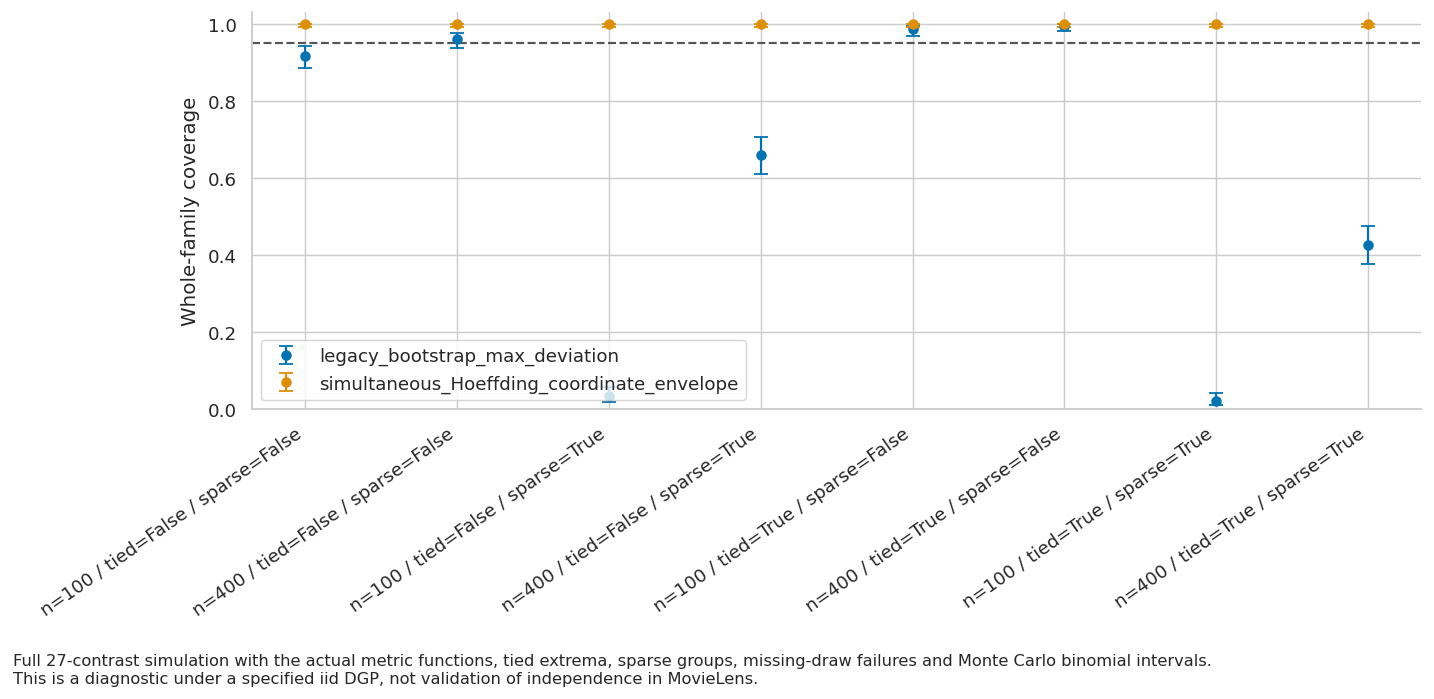

In [26]:
# RQ2: stress the complete 27-dimensional contrast family, not a scalar proxy.
from scipy.stats import beta

def full_family_calibration():
    records=[];Npop=4000;I=20;K=5;M=12;started=time.perf_counter()
    for tied in [False,True]:
      for sparse_group in [False,True]:
        rng=np.random.default_rng(seed_for('calibration_population',tied,sparse_group))
        age=rng.choice(7,Npop,p=([.01,.04,.10,.20,.25,.20,.20] if sparse_group else [1/7]*7))
        sex=rng.integers(0,2,Npop);groups=[(sex==g).astype(float) for g in [0,1]]+[(age==g).astype(float) for g in range(7)]
        names=[('gender',g) for g in ['F','M']]+[('age',str(g)) for g in range(7)]
        shared=rng.uniform(.2,.8,Npop)
        if tied:
            for aa in range(7):
                for ss in range(2):
                    mask=(age==aa)&(sex==ss)
                    if mask.any():shared[mask]+=.5-shared[mask].mean()
        utility=[];calibration=[];exposure=[]
        for m in range(M):
            # Equal conditional utility across groups in tied-extrema scenarios.
            shift=0 if tied else (age-3)*(.01+.001*m)
            if tied:
                noise=rng.uniform(-.025,.025,Npop)
                for aa in range(7):
                    for ss in range(2):
                        mask=(age==aa)&(sex==ss)
                        if mask.any():noise[mask]-=noise[mask].mean()
                utility.append(shared+.008*(m//4)+noise)
            else:utility.append(np.clip(shared+shift+.008*(m//4)+.002*(m%4)*rng.normal(size=Npop),0,1))
            calibration.append(np.clip(.35*(1-shared)+.01*(m%4)+.02*rng.random(Npop),0,1))
            L=np.stack([rng.choice(I,K,replace=False) for _ in range(Npop)])
            exposure.append(sparse.csr_matrix((np.tile(DISCOUNT[:K],Npop),
                (np.repeat(np.arange(Npop),K),L.ravel())),shape=(Npop,I)))
        pop=Audit('simulation',0,'val',K,np.arange(Npop),NAMES,np.array(utility),np.array(calibration),exposure,groups,names,{}, {})
        truth=metrics(pop,np.ones(Npop))[0]
        if tied:assert np.max(abs(truth[:,1]))<1e-10, 'Tied-population fixture has unequal group means'
        truth_delta=np.array([truth[b,j]-truth[r,j] for b,r in PAIRS for j in [1,2,3]])
        for n in C.calibration_sample_sizes:
            for rep in range(C.calibration_repeats):
                ids=rng.integers(0,Npop,n);a=subset_audit(pop,ids)
                point=metrics(a,np.ones(n))[0];pt=np.array([point[b,j]-point[r,j] for b,r in PAIRS for j in [1,2,3]])
                bs=bootstrap(a,seed_for('full_family_mc',tied,sparse_group,n,rep))
                D=np.stack([bs[:,b,j]-bs[:,r,j] for b,r in PAIRS for j in [1,2,3]],axis=1)
                bl,bh,_,_=simultaneous(D,pt)
                hl,hh,meta=bounded_contrasts(a,C.alpha)
                for method,low,high in [('legacy_bootstrap_max_deviation',bl,bh),(BOUND_METHOD,hl,hh)]:
                    estimable=bool(np.isfinite(low).all() and np.isfinite(high).all())
                    covered=bool(estimable and np.all(low<=truth_delta+1e-12) and np.all(high>=truth_delta-1e-12))
                    records.append(dict(tied=tied,sparse_group=sparse_group,n=n,rep=rep,method=method,
                        estimable=estimable,family_covered=covered,
                        interval_width=float(np.mean(high-low)) if estimable else np.nan,
                        wrong_positive=bool(estimable and np.any((low>0)&(truth_delta<=0)))))
                if (rep+1)%25==0:progress('Full-family calibration',rep+1,C.calibration_repeats,started)
    raw=pd.DataFrame(records);table(raw,'inference_full_family_simulation_draws')
    rows=[]
    for keys,g in raw.groupby(['tied','sparse_group','n','method']):
        R=len(g);s=int(g.family_covered.sum());f=int(g.wrong_positive.sum())
        rows.append(dict(zip(['tied','sparse_group','n','method'],keys),repetitions=R,
            coverage=s/R,coverage_low=float(beta.ppf(.025,s,R-s+1)) if s else 0.,
            coverage_high=float(beta.ppf(.975,s+1,R-s)) if s<R else 1.,
            wrong_positive_rate=f/R,estimable_rate=g.estimable.mean(),mean_width=g.interval_width.mean(),
            target='finite-population iid draws; full 27-contrast family',bootstrap_draws=C.n_boot))
    return table(rows,'inference_full_family_calibration')
FULL_CALIBRATION=full_family_calibration()
fig,ax=plt.subplots(figsize=(11,5));q=FULL_CALIBRATION.copy();q['scenario']=q.apply(lambda r:f"n={r['n']} / tied={r.tied} / sparse={r.sparse_group}",axis=1)
for method,g in q.groupby('method'):
    xx=np.arange(len(g));ax.errorbar(xx,g.coverage,yerr=[g.coverage-g.coverage_low,g.coverage_high-g.coverage],fmt='o',capsize=4,label=method)
ax.axhline(.95,color='#555555',ls='--');ax.set_xticks(np.arange(len(g)),g.scenario,rotation=35,ha='right');ax.set(ylabel='Whole-family coverage',ylim=(0,1.03))
ax.legend(loc='lower left');fig.tight_layout();figure(fig,'Validation_Figure1_full_family_coverage',
    'Full 27-contrast simulation with the actual metric functions, tied extrema, sparse groups, missing-draw failures and Monte Carlo binomial intervals. This is a diagnostic under a specified iid DGP, not validation of independence in MovieLens.')


## 24. Dense movie and independent music replication — RQ1/RQ2/RQ3

Load all 6,040 MovieLens 1M users for a separate within-user chronological protocol. This is related-data sensitivity, not independent replication. The independent Last.fm task recommends first observed user–artist tagging interactions with train-derived tag metadata, a fixed top-1,000 training catalog and no invented demographics. It addresses tag-calibration/exposure analogues only. Both use separate tuning/audit user roles, shared-weight selector controls and frozen test-quality definitions. References: https://grouplens.org/datasets/hetrec-2011/ and the archived README. No old results are imported.


,dataset,role,users
0,1m_userchron,tune,1175
1,1m_userchron,audit_validation,4646
2,1m_userchron,audit_test,4582


Replication fitting 1m_userchron 20261101
Retrieving 1m_userchron/20261101/val/Popularity
Retrieving 1m_userchron/20261101/val/ItemKNN
Retrieving 1m_userchron/20261101/val/MF
Retrieving 1m_userchron/20261101/test/Popularity
Retrieving 1m_userchron/20261101/test/ItemKNN
Retrieving 1m_userchron/20261101/test/MF
Replication audit 1m_userchron 20261101 5 / 20
Replication audit 1m_userchron 20261101 10 / 20
Replication audit 1m_userchron 20261101 15 / 20
Replication audit 1m_userchron 20261101 20 / 20
Replication fitting 1m_userchron 20261102
Retrieving 1m_userchron/20261102/val/Popularity
Retrieving 1m_userchron/20261102/val/ItemKNN
Retrieving 1m_userchron/20261102/val/MF
Retrieving 1m_userchron/20261102/test/Popularity
Retrieving 1m_userchron/20261102/test/ItemKNN
Retrieving 1m_userchron/20261102/test/MF
Replication audit 1m_userchron 20261102 5 / 20
Replication audit 1m_userchron 20261102 10 / 20
Replication audit 1m_userchron 20261102 15 / 20
Replication audit 1m_userchron 20261102 20 /

,dataset,role,users
0,lastfm_tag,tune,42
1,lastfm_tag,audit_validation,155
2,lastfm_tag,audit_test,135


Replication fitting lastfm_tag 20261101
Retrieving lastfm_tag/20261101/val/Popularity
Retrieving lastfm_tag/20261101/val/ItemKNN
Retrieving lastfm_tag/20261101/val/MF
Retrieving lastfm_tag/20261101/test/Popularity
Retrieving lastfm_tag/20261101/test/ItemKNN
Retrieving lastfm_tag/20261101/test/MF
Replication audit lastfm_tag 20261101 5 / 20
Replication audit lastfm_tag 20261101 10 / 20
Replication audit lastfm_tag 20261101 15 / 20
Replication audit lastfm_tag 20261101 20 / 20
Replication fitting lastfm_tag 20261102
Retrieving lastfm_tag/20261102/val/Popularity
Retrieving lastfm_tag/20261102/val/ItemKNN
Retrieving lastfm_tag/20261102/val/MF
Retrieving lastfm_tag/20261102/test/Popularity
Retrieving lastfm_tag/20261102/test/ItemKNN
Retrieving lastfm_tag/20261102/test/MF
Replication audit lastfm_tag 20261102 5 / 20
Replication audit lastfm_tag 20261102 10 / 20
Replication audit lastfm_tag 20261102 15 / 20
Replication audit lastfm_tag 20261102 20 / 20
Replication fitting lastfm_tag 20261103


,dataset,seed,objective_x,objective_y,valid_draws,disagreement,mean_kendall
0,1m_userchron,20261101,1,1,1000,0.000,1.000000
1,1m_userchron,20261101,1,2,1000,0.568,0.359000
2,1m_userchron,20261101,1,3,1000,0.568,0.359000
3,1m_userchron,20261101,2,1,1000,0.568,0.359000
4,1m_userchron,20261101,2,2,1000,0.000,1.000000
5,1m_userchron,20261101,2,3,1000,0.000,1.000000
6,1m_userchron,20261101,3,1,1000,0.568,0.359000
7,1m_userchron,20261101,3,2,1000,0.000,1.000000
8,1m_userchron,20261101,3,3,1000,0.000,1.000000
9,1m_userchron,20261102,1,1,1000,0.000,1.000000


,dataset,seed,audit,rule,size,complete_draws,selected,test_dominated,frontier_recall,test_loss,quality_estimable
0,1m_userchron,20261101,0,SingleGap,1,1000,ItemKNN__lambda_0.1,1.000000,0.0,0.004339,True
1,1m_userchron,20261101,0,SingleCalibration,1,1000,ItemKNN__lambda_0.5,0.000000,1.0,0.016084,True
2,1m_userchron,20261101,0,SingleExposure,1,1000,ItemKNN__lambda_0.5,0.000000,1.0,0.016084,True
3,1m_userchron,20261101,0,PointPareto,3,1000,ItemKNN__lambda_0.1;ItemKNN__lambda_0.3;ItemKN...,0.666667,1.0,0.013650,True
4,1m_userchron,20261101,0,Bootstrap,1,1000,ItemKNN__lambda_0.5,0.000000,1.0,0.016084,True
...,...,...,...,...,...,...,...,...,...,...,...
775,lastfm_tag,20261103,19,SingleExposure,1,1000,ItemKNN__lambda_0.0,1.000000,0.0,0.030692,True
776,lastfm_tag,20261103,19,PointPareto,4,1000,ItemKNN__lambda_0.0;ItemKNN__lambda_0.1;ItemKN...,0.750000,1.0,0.031400,True
777,lastfm_tag,20261103,19,Bootstrap,1,1000,ItemKNN__lambda_0.5,0.000000,1.0,0.000000,True
778,lastfm_tag,20261103,19,SizeMatchedRandom,1,1000,ItemKNN__lambda_0.5,0.000000,1.0,0.000000,True


,dataset,seed,window,base,reranker,objective,gain,low,high,supported,interval_method
0,1m_userchron,20261101,val,Popularity__lambda_0.0,Popularity__lambda_0.1,group_gap,0.000009,-0.293005,0.292553,False,simultaneous_Hoeffding_coordinate_envelope
1,1m_userchron,20261101,val,Popularity__lambda_0.0,Popularity__lambda_0.1,genre_JSD,0.003215,-0.085422,0.091853,False,simultaneous_Hoeffding_coordinate_envelope
2,1m_userchron,20261101,val,Popularity__lambda_0.0,Popularity__lambda_0.1,exposure_Gini,0.000001,-0.999726,0.999726,False,simultaneous_Hoeffding_coordinate_envelope
3,1m_userchron,20261101,val,Popularity__lambda_0.0,Popularity__lambda_0.3,group_gap,0.000390,-0.292693,0.292553,False,simultaneous_Hoeffding_coordinate_envelope
4,1m_userchron,20261101,val,Popularity__lambda_0.0,Popularity__lambda_0.3,genre_JSD,0.015091,-0.073547,0.103729,False,simultaneous_Hoeffding_coordinate_envelope
...,...,...,...,...,...,...,...,...,...,...,...
265,lastfm_tag,20261103,test,MF__lambda_0.0,MF__lambda_0.1,exposure_Gini,0.000662,-0.999000,0.999000,False,simultaneous_Hoeffding_coordinate_envelope
266,lastfm_tag,20261103,test,MF__lambda_0.0,MF__lambda_0.3,genre_JSD,0.009075,-0.492237,0.505424,False,simultaneous_Hoeffding_coordinate_envelope
267,lastfm_tag,20261103,test,MF__lambda_0.0,MF__lambda_0.3,exposure_Gini,-0.000540,-0.999000,0.999000,False,simultaneous_Hoeffding_coordinate_envelope
268,lastfm_tag,20261103,test,MF__lambda_0.0,MF__lambda_0.5,genre_JSD,0.022579,-0.478733,0.505424,False,simultaneous_Hoeffding_coordinate_envelope


,dataset,seed,rule,mean_size,mean_jaccard,mean_union_jaccard,nonempty_pairs,both_empty_pairs,one_empty_pairs,total_pairs,empty_rate
0,1m_userchron,20261101,SingleGap,1.00,0.268421,0.268421,190,0,0,190,0.0
1,1m_userchron,20261101,SingleCalibration,1.00,1.000000,1.000000,190,0,0,190,0.0
2,1m_userchron,20261101,SingleExposure,1.00,1.000000,1.000000,190,0,0,190,0.0
3,1m_userchron,20261101,PointPareto,1.95,0.587281,0.587281,190,0,0,190,0.0
4,1m_userchron,20261101,Bootstrap,1.05,0.950000,0.950000,190,0,0,190,0.0
5,1m_userchron,20261101,SizeMatchedRandom,1.05,0.228947,0.228947,190,0,0,190,0.0
6,1m_userchron,20261101,SizeMatchedRelevance,1.05,0.334211,0.334211,190,0,0,190,0.0
7,1m_userchron,20261102,SingleGap,1.00,0.310526,0.310526,190,0,0,190,0.0
8,1m_userchron,20261102,SingleCalibration,1.00,1.000000,1.000000,190,0,0,190,0.0
9,1m_userchron,20261102,SingleExposure,1.00,1.000000,1.000000,190,0,0,190,0.0


,dataset,seed,rule,mean_size,mean_jaccard,mean_union_jaccard,nonempty_pairs,both_empty_pairs,one_empty_pairs,total_pairs,empty_rate,mean_dominated,mean_recall
0,1m_userchron,20261101,SingleGap,1.00,0.268421,0.268421,190,0,0,190,0.0,0.550000,0.45
1,1m_userchron,20261101,SingleCalibration,1.00,1.000000,1.000000,190,0,0,190,0.0,0.000000,1.00
2,1m_userchron,20261101,SingleExposure,1.00,1.000000,1.000000,190,0,0,190,0.0,0.000000,1.00
3,1m_userchron,20261101,PointPareto,1.95,0.587281,0.587281,190,0,0,190,0.0,0.337500,1.00
4,1m_userchron,20261101,Bootstrap,1.05,0.950000,0.950000,190,0,0,190,0.0,0.025000,1.00
5,1m_userchron,20261101,SizeMatchedRandom,1.05,0.228947,0.228947,190,0,0,190,0.0,0.675000,0.35
6,1m_userchron,20261101,SizeMatchedRelevance,1.05,0.334211,0.334211,190,0,0,190,0.0,0.975000,0.05
7,1m_userchron,20261102,SingleGap,1.00,0.310526,0.310526,190,0,0,190,0.0,0.500000,0.50
8,1m_userchron,20261102,SingleCalibration,1.00,1.000000,1.000000,190,0,0,190,0.0,0.000000,1.00
9,1m_userchron,20261102,SingleExposure,1.00,1.000000,1.000000,190,0,0,190,0.0,0.000000,1.00


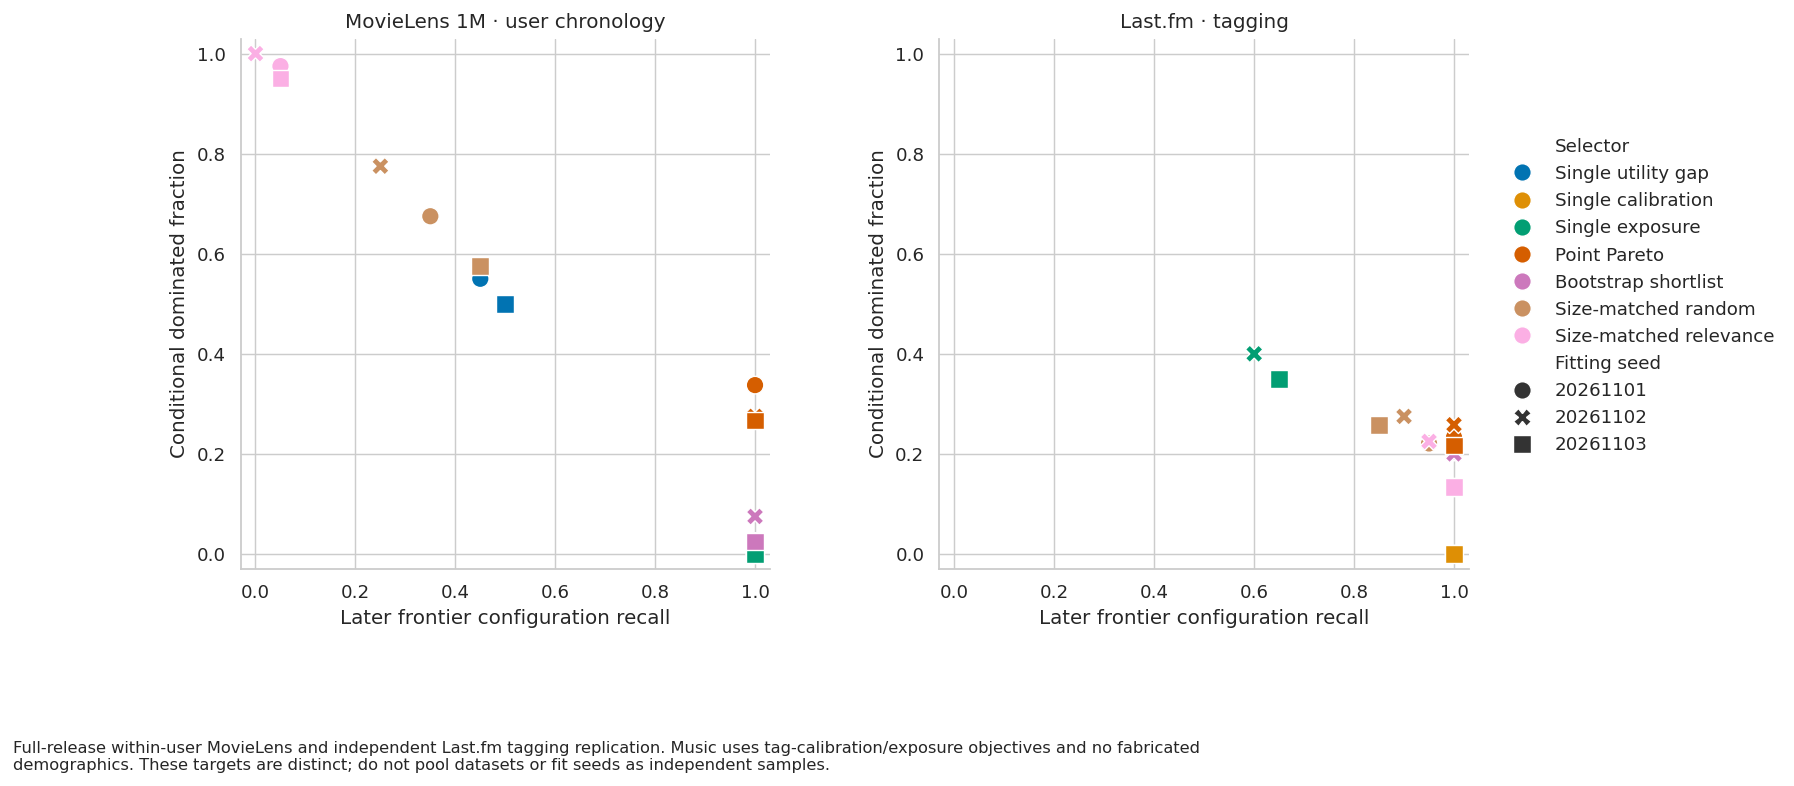

In [27]:
# RQ1–RQ5: a denser movie protocol plus a separate, partially applicable music-domain check.
import urllib.request

def lastfm_release():
    paths=[]
    for base in SEARCH_ROOTS:
        if base.exists():paths+=list(base.rglob('hetrec2011-lastfm-2k.zip'))
    if paths:path=sorted(set(paths))[0]
    else:
        path=WORK/'hetrec2011-lastfm-2k.zip'
        extracted=sorted(Path('/kaggle/input').rglob('user_taggedartists-timestamps.dat'))
        if len(extracted)>1:raise RuntimeError('Multiple Last.fm copies attached; keep one.')
        if extracted:
            temporary=path.with_suffix('.tmp')
            with zipfile.ZipFile(temporary,'w',compression=zipfile.ZIP_DEFLATED) as bundle:
                for member in sorted(extracted[0].parent.iterdir()):
                    if member.is_file() and (member.suffix.lower()=='.dat' or 'readme' in member.name.lower()):
                        bundle.write(member,arcname=member.name)
            with zipfile.ZipFile(temporary) as bundle:assert bundle.testzip() is None
            os.replace(temporary,path)
        elif not path.exists():
            try:
                with urllib.request.urlopen('https://files.grouplens.org/datasets/hetrec2011/hetrec2011-lastfm-2k.zip',timeout=90) as response:
                    data=response.read()
                temporary=path.with_suffix('.tmp');temporary.write_bytes(data)
                with zipfile.ZipFile(temporary) as bundle:assert bundle.testzip() is None
                os.replace(temporary,path)
            except Exception as exc:raise RuntimeError('Attach official Last.fm ZIP/extracted files or enable Internet.') from exc
    with zipfile.ZipFile(path) as archive:
        def raw(stem):
            name=next(x for x in archive.namelist() if Path(x).name==stem)
            return archive.read(name)
        events=pd.read_csv(io.BytesIO(raw('user_taggedartists-timestamps.dat')),sep='\t')
        assert {'userID','artistID','tagID','timestamp'}<=set(events.columns)
        events['timestamp']=(events.timestamp//1000).astype(np.int64)
        ratings=events.groupby(['userID','artistID'],as_index=False).timestamp.min()
        ratings.columns=['uid','iid','timestamp'];ratings['rating']=5
        bounds=np.quantile(ratings.timestamp,[.70,.85],method='nearest').astype(np.int64)
        tr=ratings[ratings.timestamp<=bounds[0]]
        top=tr.groupby('iid').uid.nunique().sort_values(ascending=False,kind='stable').head(C.lastfm_catalogue).index
        # Tag vocabulary and artist tags use training-time annotations only.
        annotations=events[(events.timestamp<=bounds[0])&events.artistID.isin(top)]
        vocab=set(annotations.tagID.value_counts().head(64).index)
        mapping=annotations.groupby('artistID').tagID.apply(lambda s:sorted(set('tag_'+str(x) if x in vocab else 'other_tag' for x in s)))
        movies=pd.DataFrame({'iid':sorted(top)})
        movies['title']=movies.iid.astype(str);movies['genres']=movies.iid.map(mapping).apply(lambda x:x if isinstance(x,list) and x else ['unannotated'])
        ratings=ratings[ratings.iid.isin(top)].copy()
        users=pd.DataFrame({'uid':sorted(ratings.uid.unique())});users['gender']=None;users['age']=np.nan
        readmes=[x for x in archive.namelist() if 'readme' in Path(x).name.lower()]
        readme=archive.read(readmes[0]).decode('latin1') if readmes else 'See official GroupLens HetRec 2011 documentation.'
    provenance=dict(input=str(path),sha256=hashlib.sha256(path.read_bytes()).hexdigest(),
        source='https://grouplens.org/datasets/hetrec-2011/',task='first observed user–artist tagging interaction recommendation',
        scope='tag-distribution calibration and item exposure only; tags are not asserted to be genres',
        demographics='not supplied; no demographic attributes are inferred or synthesized',README=readme)
    write_json('provenance_lastfm_tag',dict(provenance,training_tag_cutoff=int(bounds[0]),tag_vocabulary_size=len(vocab),catalogue_size=len(top)))
    return dict(tag='lastfm_tag',ratings=ratings,users=users,movies=movies,provenance=provenance,fixed_bounds=bounds)

def replication_retrieve(d,model,co,seed,window,base):
    # Private current-run cache; profiles change reranking, never retrieval.
    path=CACHE/f'replication_{d["tag"]}_{seed}_{window}_{base}.npz'
    if path.exists():
        with np.load(path) as saved:
            if not np.array_equal(saved['users'],co['users']):raise RuntimeError('Retrieval cache user mismatch')
            return saved['items'].copy(),saved['scores'].copy()
    print(f'Retrieving {d["tag"]}/{seed}/{window}/{base}',flush=True)
    ids,scores=retrieve(d,model,co)
    np.savez_compressed(path,users=co['users'],items=ids,scores=scores)
    return ids,scores

REPLICATION_DATA={}
dense_release=dict(RELEASES['1m'],tag='1m_userchron')
REPLICATION_DATA['1m_userchron']=prepare(dense_release)
REPLICATION_DATA['lastfm_tag']=prepare(lastfm_release())
REPLICATION_OBJECTIVES={'1m_userchron':(1,2,3),'lastfm_tag':(2,3)}
REPLICATION_AUDITS={};REPLICATION_MODELS={};REPLICATION_OUTER=[];REPLICATION_CONTRASTS=[];REPLICATION_SUMMARY=[];REPLICATION_AGREEMENT=[]

def generic_rules(p,b,objectives,seed):
    eligible=eligibility(p);sets={};rng=np.random.default_rng(seed)
    for j,label in [(1,'SingleGap'),(2,'SingleCalibration'),(3,'SingleExposure')]:
        if j in objectives and len(eligible) and np.isfinite(p[eligible,j]).all():
            sets[label]={min(eligible,key=lambda m:(p[m,j],-p[m,0],m))}
    finite=len(eligible)>0 and np.isfinite(p[eligible][:,objectives]).all()
    sets['PointPareto']=set(eligible[nondominated(p[eligible][:,objectives])]) if finite else set()
    valid=np.isfinite(b[:,eligible][:,:,objectives]).all((1,2)) if len(eligible) else np.zeros(len(b),bool)
    if finite and valid.sum()>=C.min_complete:
        support=np.mean([nondominated(x[eligible][:,objectives]) for x in b[valid]],axis=0)
        sets['Bootstrap']=set(eligible[support>=C.support])
    else:sets['Bootstrap']=set()
    k=len(sets['Bootstrap'])
    sets['SizeMatchedRandom']=set(rng.choice(eligible,k,replace=False)) if k else set()
    sets['SizeMatchedRelevance']=set(sorted(eligible,key=lambda m:(-p[m,0],m))[:k])
    return sets,eligible,int(valid.sum())

def replication_quality(S,q,pool,objectives):
    if not len(pool) or not np.isfinite(q[pool][:,objectives]).all():
        return dict(test_dominated=np.nan,frontier_recall=np.nan,test_loss=np.nan,quality_estimable=False)
    front=set(pool[nondominated(q[pool][:,objectives])])
    return dict(test_dominated=np.mean([i not in front for i in S]) if S else np.nan,
        frontier_recall=len(S&front)/len(front),test_loss=float(np.median(1-q[list(S),0]/max(q[pool,0].max(),1e-12))) if S else np.nan,
        quality_estimable=True)

for tag,d in REPLICATION_DATA.items():
    objectives=REPLICATION_OBJECTIVES[tag];tc=cohort(d,'tune');vc=cohort(d,'val');ec=cohort(d,'test')
    if min(len(tc['users']),len(vc['users']),len(ec['users']))<10:
        raise RuntimeError(f'{tag}: fewer than 10 eligible users in one required role; inspect cohort rules, do not silently skip replication.')
    table([dict(dataset=tag,role=r,users=len(c['users'])) for r,c in [('tune',tc),('audit_validation',vc),('audit_test',ec)]],tag+'_role_counts')
    for seed in C.seeds:
        print('Replication fitting',tag,seed,flush=True);choices=[]
        for rank in C.mf_ranks:
          for penalty in C.mf_penalties:
            model=('MF',mf_fit(d,rank,penalty,seed));ids,_=retrieve(d,model,tc)
            sc=np.mean([ndcg_list(row,tc['positive'][u],10) for row,u in zip(ids,tc['users'])])
            choices.append((sc,rank,penalty,model))
        choices.sort(key=lambda x:(-x[0],x[1],-x[2]))
        models={'Popularity':('Popularity',np.asarray(d['P'].sum(0)).ravel()),'ItemKNN':('ItemKNN',knn_fit(d)),'MF':choices[0][3]}
        REPLICATION_MODELS[tag,seed]=models
        write_json(f'{tag}_{seed}_tuning',dict(selected_rank=choices[0][1],selected_penalty=choices[0][2],tuning_users=len(tc['users']),audit_users=len(vc['users'])))
        for window,co in [('val',vc),('test',ec)]:
            lists={}
            for base,model in models.items():
                ids,scores=replication_retrieve(d,model,co,seed,window,base)
                for lam in C.lambdas:lists[candidate_name(base,lam)]=rerank(ids,scores,d['profiles'][co['users']],d['G'],lam)
            a=make_audit(d,seed,window,10,lists,co);REPLICATION_AUDITS[tag,seed,window]=a
            pt=metrics(a,np.ones(len(a.users)))[0];lo,hi,meta=bounded_contrasts(a,BOUND_ALPHA)
            if window=='val':
                b0=bootstrap(a,seed_for('replication_rank',tag,seed));pool=eligibility(pt)
                for jj in objectives:
                    for kk in objectives:
                        valid=0;different=0;taus=[]
                        for draw in b0:
                            if len(pool)<2 or not np.isfinite(draw[pool][:,[jj,kk]]).all():continue
                            x=draw[pool,jj];y=draw[pool,kk]
                            wx=set(pool[np.isclose(x,x.min(),atol=1e-12,rtol=0)]);wy=set(pool[np.isclose(y,y.min(),atol=1e-12,rtol=0)])
                            valid+=1;different+=wx!=wy;taus.append(kendalltau(x,y).statistic)
                        REPLICATION_AGREEMENT.append(dict(dataset=tag,seed=seed,objective_x=jj,objective_y=kk,
                            valid_draws=valid,disagreement=different/valid if valid else np.nan,
                            mean_kendall=float(np.nanmean(taus)) if np.isfinite(taus).any() else np.nan))
            for c,((bb,rr),j) in enumerate((pair,j) for pair in PAIRS for j in [1,2,3]):
                if j not in objectives:continue
                REPLICATION_CONTRASTS.append(dict(dataset=tag,seed=seed,window=window,base=a.names[bb],reranker=a.names[rr],objective={1:'group_gap',2:'genre_JSD',3:'exposure_Gini'}[j],
                    gain=pt[bb,j]-pt[rr,j],low=lo[c],high=hi[c],supported=bool(lo[c]>0),interval_method=BOUND_METHOD))
        a=REPLICATION_AUDITS[tag,seed,'val'];te=REPLICATION_AUDITS[tag,seed,'test'];test=metrics(te,np.ones(len(te.users)))[0]
        rng=np.random.default_rng(seed_for('replication_outer',tag,seed));storage=defaultdict(list)
        for rep in range(C.replication_outer_audits):
            w=rng.multinomial(len(a.users),np.ones(len(a.users))/len(a.users));pt=metrics(a,w)[0]
            b=bootstrap(a,seed_for('replication_inner',tag,seed,rep),prob=w/w.sum())
            sets,pool,complete=generic_rules(pt,b,objectives,seed_for('replication_controls',tag,seed,rep))
            for rule,S in sets.items():
                storage[rule].append(S);REPLICATION_OUTER.append(dict(dataset=tag,seed=seed,audit=rep,rule=rule,size=len(S),
                    complete_draws=complete,selected=';'.join(a.names[i] for i in sorted(S)),**replication_quality(S,test,pool,objectives)))
            if (rep+1)%5==0:print('Replication audit',tag,seed,rep+1,'/',C.replication_outer_audits,flush=True)
        for rule,seq in storage.items():REPLICATION_SUMMARY.append(dict(dataset=tag,seed=seed,rule=rule,mean_size=np.mean([len(s) for s in seq]),**set_stability(seq)))
REPLICATION_AGREEMENT=table(REPLICATION_AGREEMENT,'Replication_RQ1_objective_agreement')
REPLICATION_OUTER=table(REPLICATION_OUTER,'Replication_RQ3_outer_audits')
REPLICATION_CONTRASTS=table(REPLICATION_CONTRASTS,'Replication_RQ2_contrasts')
REPLICATION_SUMMARY=table(REPLICATION_SUMMARY,'Replication_RQ3_stability')
rep_quality=REPLICATION_OUTER.groupby(['dataset','seed','rule']).agg(mean_dominated=('test_dominated','mean'),mean_recall=('frontier_recall','mean')).reset_index()
REPLICATION_SUMMARY=REPLICATION_SUMMARY.merge(rep_quality,on=['dataset','seed','rule'])
table(REPLICATION_SUMMARY,'Replication_RQ3_stability')
rep_rules=['SingleGap','SingleCalibration','SingleExposure','PointPareto','Bootstrap','SizeMatchedRandom','SizeMatchedRelevance']
rep_palette=dict(zip(rep_rules,sns.color_palette('colorblind',len(rep_rules))))
rep_markers=dict(zip(C.seeds,['o','X','s']))
fig,axes=plt.subplots(1,2,figsize=(14,6));
for ax,tag in zip(axes,REPLICATION_DATA):
    q=REPLICATION_SUMMARY.query('dataset==@tag');sns.scatterplot(data=q,x='mean_recall',y='mean_dominated',hue='rule',hue_order=rep_rules,palette=rep_palette,style='seed',style_order=list(C.seeds),markers=rep_markers,s=95,ax=ax)
    ax.set(title={'1m_userchron':'MovieLens 1M · user chronology','lastfm_tag':'Last.fm · tagging'}[tag],xlabel='Later frontier configuration recall',ylabel='Conditional dominated fraction',xlim=(-.03,1.03),ylim=(-.03,1.03))
    if ax.legend_:ax.legend_.remove()
handles,labels=axes[0].get_legend_handles_labels();fig.legend(handles,[{'rule':'Selector','seed':'Fitting seed','SingleGap':'Single utility gap','SingleCalibration':'Single calibration','SingleExposure':'Single exposure','PointPareto':'Point Pareto','Bootstrap':'Bootstrap shortlist','SizeMatchedRandom':'Size-matched random','SizeMatchedRelevance':'Size-matched relevance'}.get(x,x) for x in labels],loc='center left',bbox_to_anchor=(.81,.55),frameon=False)
fig.subplots_adjust(right=.80,bottom=.20,wspace=.32);figure(fig,'Replication_Figure1_coverage_quality',
    'Full-release within-user MovieLens and independent Last.fm tagging replication. Music uses tag-calibration/exposure objectives and no fabricated demographics. These targets are distinct; do not pool datasets or fit seeds as independent samples.')


## 25. Dense subgroup, activity and profile validation — RQ4/RQ5

Repeat original-group resolution, activity stability, observed-drift association and profile stability on the denser movie target. Profile strategies share a common relevance-screen baseline and the same outer user weights. Test-gap comparisons use simultaneous conservative intervals; the declared noninferiority margin is 0.01 NDCG gap units. Neither an inconclusive interval nor a nonsignificant coefficient proves no harm or no association. Logistic cluster intervals remain explicitly exploratory.


**Runtime revision:** full bootstrap counts/seeds are retained. Compiled reranking, one-time cluster indexing and candidate retrieval caching remove repeated work. Progress reports identify seed/stage/model and regression completion; partial regression and completed-stage checkpoints resume when this cell is rerun in the same live session. A fresh kernel still requires preceding cells.


[Section 25] Seed 20261101 (1/3)
[Section 25] Starting activity/20261101/0
Dense activity 20261101/0: 1/20; elapsed 0.0 min
Dense activity 20261101/0: 5/20; elapsed 0.1 min
Dense activity 20261101/0: 10/20; elapsed 0.2 min
Dense activity 20261101/0: 15/20; elapsed 0.2 min
Dense activity 20261101/0: 20/20; elapsed 0.3 min
[Section 25] Finished activity/20261101/0: 0.31 min
[Section 25] Starting activity/20261101/1
Dense activity 20261101/1: 1/20; elapsed 0.0 min
Dense activity 20261101/1: 5/20; elapsed 0.1 min
Dense activity 20261101/1: 10/20; elapsed 0.1 min
Dense activity 20261101/1: 15/20; elapsed 0.2 min
Dense activity 20261101/1: 20/20; elapsed 0.3 min
[Section 25] Finished activity/20261101/1: 0.29 min
[Section 25] Starting activity/20261101/2
Dense activity 20261101/2: 1/20; elapsed 0.0 min
Dense activity 20261101/2: 5/20; elapsed 0.1 min
Dense activity 20261101/2: 10/20; elapsed 0.1 min
Dense activity 20261101/2: 15/20; elapsed 0.2 min
Dense activity 20261101/2: 20/20; elapsed 0

,dataset,window,age,gender,distinct_users,below_50
0,1m_userchron,val,1,F,57,False
1,1m_userchron,val,1,M,104,False
2,1m_userchron,val,18,F,230,False
3,1m_userchron,val,18,M,611,False
4,1m_userchron,val,25,F,436,False
5,1m_userchron,val,25,M,1189,False
6,1m_userchron,val,35,F,255,False
7,1m_userchron,val,35,M,650,False
8,1m_userchron,val,45,F,148,False
9,1m_userchron,val,45,M,276,False


,pool_definition,rule,outer_audits,mean_size,mean_jaccard,mean_union_jaccard,nonempty_pairs,both_empty_pairs,one_empty_pairs,total_pairs,empty_rate,seed,stratum,distinct_users
0,own_audit_validation_screen,SingleGap,20,1.00,0.215789,0.215789,190,0,0,190,0.0,20261101,0,1565
1,own_audit_validation_screen,SingleCalibration,20,1.00,0.531579,0.531579,190,0,0,190,0.0,20261101,0,1565
2,own_audit_validation_screen,SingleExposure,20,1.00,0.531579,0.531579,190,0,0,190,0.0,20261101,0,1565
3,own_audit_validation_screen,PointPareto,20,1.95,0.379825,0.379825,190,0,0,190,0.0,20261101,0,1565
4,own_audit_validation_screen,Bootstrap,20,1.05,0.531579,0.531579,190,0,0,190,0.0,20261101,0,1565
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
58,own_audit_validation_screen,SingleExposure,20,1.00,0.557895,0.557895,190,0,0,190,0.0,20261103,2,1545
59,own_audit_validation_screen,PointPareto,20,1.65,0.463158,0.463158,190,0,0,190,0.0,20261103,2,1545
60,own_audit_validation_screen,Bootstrap,20,1.05,0.539474,0.539474,190,0,0,190,0.0,20261103,2,1545
61,own_audit_validation_screen,SizeMatchedRandom,20,1.05,0.226316,0.226316,190,0,0,190,0.0,20261103,2,1545


,seed,repeat_users,usable_users,low_n,mid_n,high_n,coefficient,low,high,valid_draws,status,exploratory
0,20261101,4439,4239,1413,1413,1413,-0.121525,-0.254762,-0.003254,1000,exploratory cluster interval,True
1,20261102,4439,4239,1413,1413,1413,-0.082771,-0.213197,0.033065,1000,exploratory cluster interval,True
2,20261103,4439,4239,1413,1413,1413,-0.115028,-0.253600,0.002810,1000,exploratory cluster interval,True


,pool_definition,rule,outer_audits,mean_size,mean_jaccard,mean_union_jaccard,nonempty_pairs,both_empty_pairs,one_empty_pairs,total_pairs,empty_rate,seed,strategy
0,common_full_history_screen,SingleGap,20,1.00,0.384211,0.384211,190,0,0,190,0.0,20261101,full
1,common_full_history_screen,SingleCalibration,20,1.00,1.000000,1.000000,190,0,0,190,0.0,20261101,full
2,common_full_history_screen,SingleExposure,20,1.00,1.000000,1.000000,190,0,0,190,0.0,20261101,full
3,common_full_history_screen,PointPareto,20,1.85,0.601316,0.601316,190,0,0,190,0.0,20261101,full
4,common_full_history_screen,Bootstrap,20,1.10,0.905263,0.905263,190,0,0,190,0.0,20261101,full
...,...,...,...,...,...,...,...,...,...,...,...,...,...
121,own_audit_validation_screen,SingleExposure,20,1.00,1.000000,1.000000,190,0,0,190,0.0,20261103,weighted
122,own_audit_validation_screen,PointPareto,20,1.95,0.609211,0.609211,190,0,0,190,0.0,20261103,weighted
123,own_audit_validation_screen,Bootstrap,20,1.20,0.821053,0.821053,190,0,0,190,0.0,20261103,weighted
124,own_audit_validation_screen,SizeMatchedRandom,20,1.20,0.274561,0.274561,190,0,0,190,0.0,20261103,weighted


,seed,strategy,candidate,gap_change,low,high,supported_worsening,noninferiority_margin,noninferiority_supported,interval_method,interpretation
0,20261101,recent,Popularity__lambda_0.0,0.000000,-0.295748,0.295748,False,0.01,False,simultaneous_Hoeffding_coordinate_envelope,noninferiority uses the stated margin; no abso...
1,20261101,recent,Popularity__lambda_0.1,-0.000686,-0.295779,0.295985,False,0.01,False,simultaneous_Hoeffding_coordinate_envelope,noninferiority uses the stated margin; no abso...
2,20261101,recent,Popularity__lambda_0.3,-0.000849,-0.295482,0.296077,False,0.01,False,simultaneous_Hoeffding_coordinate_envelope,noninferiority uses the stated margin; no abso...
3,20261101,recent,Popularity__lambda_0.5,-0.000604,-0.299084,0.297004,False,0.01,False,simultaneous_Hoeffding_coordinate_envelope,noninferiority uses the stated margin; no abso...
4,20261101,recent,ItemKNN__lambda_0.0,0.000000,-0.329628,0.329628,False,0.01,False,simultaneous_Hoeffding_coordinate_envelope,noninferiority uses the stated margin; no abso...
...,...,...,...,...,...,...,...,...,...,...,...
67,20261103,weighted,ItemKNN__lambda_0.5,-0.000208,-0.329462,0.329128,False,0.01,False,simultaneous_Hoeffding_coordinate_envelope,noninferiority uses the stated margin; no abso...
68,20261103,weighted,MF__lambda_0.0,0.000000,-0.269817,0.269817,False,0.01,False,simultaneous_Hoeffding_coordinate_envelope,noninferiority uses the stated margin; no abso...
69,20261103,weighted,MF__lambda_0.1,-0.000169,-0.269675,0.270128,False,0.01,False,simultaneous_Hoeffding_coordinate_envelope,noninferiority uses the stated margin; no abso...
70,20261103,weighted,MF__lambda_0.3,-0.000060,-0.269664,0.269947,False,0.01,False,simultaneous_Hoeffding_coordinate_envelope,noninferiority uses the stated margin; no abso...


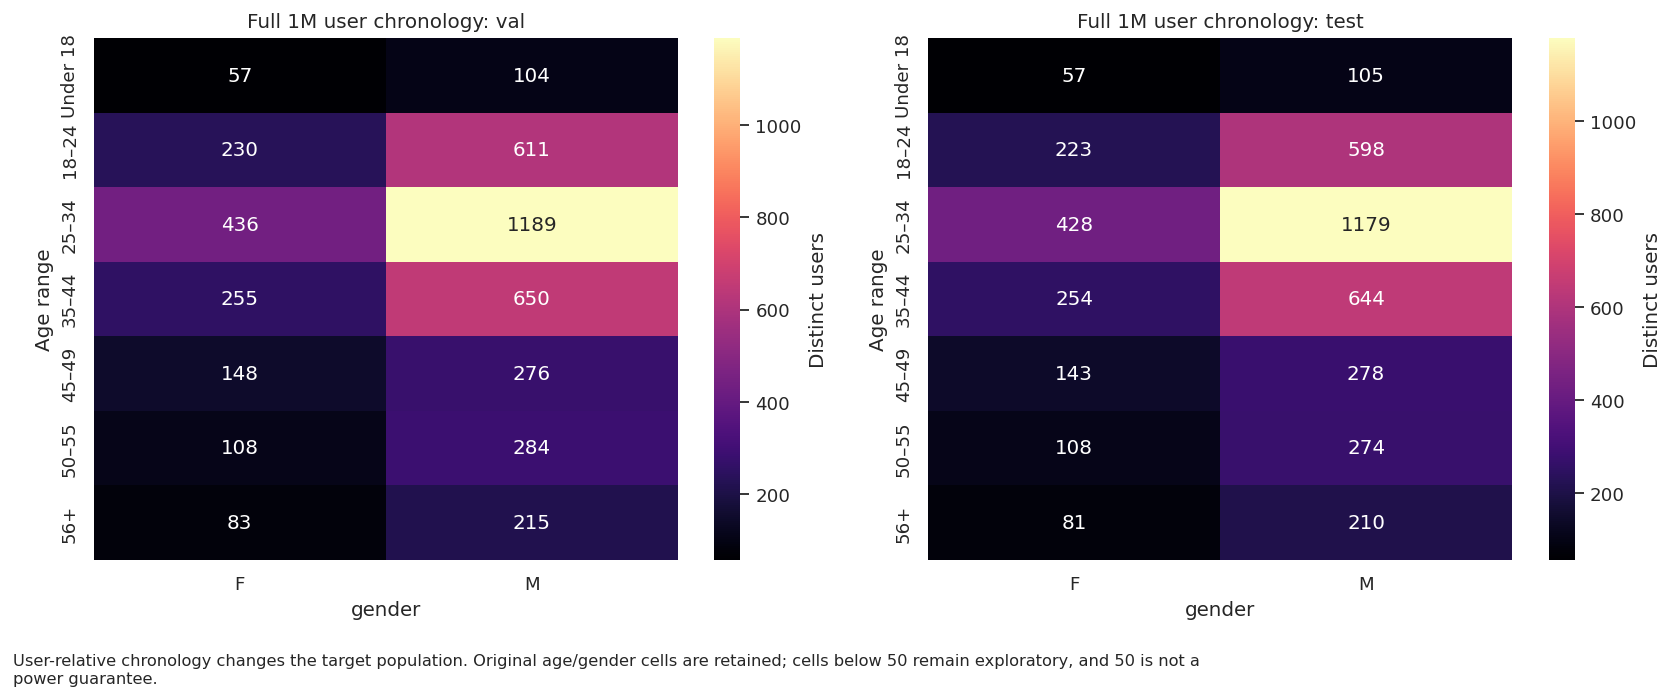

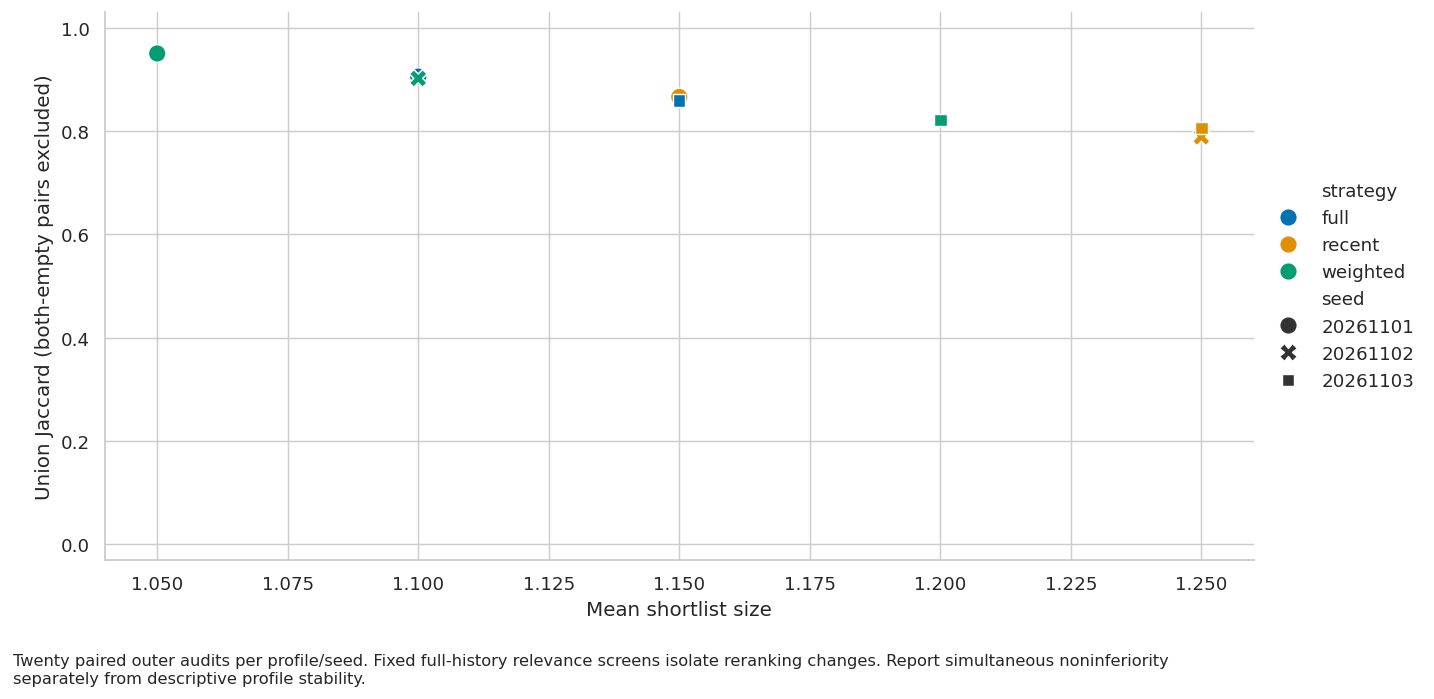

[Section 25] COMPLETE: 14.1 min


In [28]:
# RQ4/RQ5: dense subgroup/activity/profile endpoints; unchanged simulation settings.
# Rerunning THIS cell in the same live session resumes private stage checkpoints.
DENSE_GROUPS=[];DENSE_ACTIVITY=[];DENSE_PROFILES=[];DENSE_ASSOC=[];DENSE_GAPS=[]
d=REPLICATION_DATA['1m_userchron'];tag='1m_userchron'
section25_started=time.perf_counter()
for window in ['val','test']:
    a=REPLICATION_AUDITS[tag,C.seeds[0],window];meta=d['meta'].iloc[a.users]
    for age in [1,18,25,35,45,50,56]:
        for gender in ['F','M']:
            count=int(((meta.age==age)&(meta.gender==gender)).sum())
            DENSE_GROUPS.append(dict(dataset=tag,window=window,age=age,gender=gender,distinct_users=count,below_50=count<50))

for seed in C.seeds:
    print(f'[Section 25] Seed {seed} ({C.seeds.index(seed)+1}/{len(C.seeds)})',flush=True)
    a=REPLICATION_AUDITS[tag,seed,'val'];te=REPLICATION_AUDITS[tag,seed,'test']
    test=metrics(te,np.ones(len(te.users)))[0]
    act=d['meta'].iloc[a.users].activity.to_numpy();cut=np.quantile(act,[1/3,2/3]);bins=np.digitize(act,cut,right=True)
    for st in range(3):
        sub=subset_audit(a,np.flatnonzero(bins==st))
        if len(sub.users)<2:continue
        _,stability=dense_cached(f'activity/{seed}/{st}',lambda: nested_diagnostic(
            sub,test,seed_for('dense_activity',seed,st),C.post_review_audits,f'Dense activity {seed}/{st}'))
        DENSE_ACTIVITY.extend(dict(row,seed=seed,stratum=st,distinct_users=len(sub.users)) for row in stability)

    def fit_dense_drift():
        common=sorted(set(a.users)&set(te.users))
        ct=d['train'].query('rating>=4').groupby('u').size()
        cv=d['val'].query('rating>=4 and i>=0').groupby('u').size()
        users=np.array([u for u in common if ct.get(u,0)>=2 and cv.get(u,0)>=2],int)
        drift=jsd(history_profiles(d,d['train'],users,'full'),history_profiles(d,d['val'],users,'full'))
        bins=np.digitize(drift,np.quantile(drift,[1/3,2/3]),right=True);sizes=np.bincount(bins,minlength=3)
        vi={u:i for i,u in enumerate(a.users)};ti={u:i for i,u in enumerate(te.users)};rows=[]
        for j,u in enumerate(users):
            for pair,(bb,rr) in enumerate(PAIRS):
                dv=a.calibration[bb,vi[u]]-a.calibration[rr,vi[u]]
                dt=te.calibration[bb,ti[u]]-te.calibration[rr,ti[u]]
                if abs(dv)<=C.tie_tolerance or abs(dt)<=C.tie_tolerance:continue
                rows.append(dict(user=u,pair=pair,drift=drift[j],log_activity=np.log1p(d['meta'].iloc[u].activity),reversal=int(dv*dt<0)))
        data=pd.DataFrame(rows)
        result=dict(seed=seed,repeat_users=len(common),usable_users=len(users),low_n=sizes[0],mid_n=sizes[1],high_n=sizes[2],
            coefficient=np.nan,low=np.nan,high=np.nan,valid_draws=0,status='insufficient histories/outcome variation',exploratory=True)
        if not(len(users)>=C.drift_min_users and sizes.min()>=C.drift_min_stratum and len(data) and data.reversal.nunique()==2):return result
        X=np.column_stack([data[['drift','log_activity']].to_numpy(),pd.get_dummies(data.pair,drop_first=True,dtype=float)])
        X=StandardScaler().fit_transform(X);Y=data.reversal.to_numpy()
        fit=LogisticRegression(C=1e6,max_iter=2000);fit.fit(X,Y);coef=float(fit.coef_[0,0])
        cluster=data.user.to_numpy();ids=np.unique(cluster)
        # Build once. Same sampled users, multiplicities, row order and fits as before.
        row_lists=data.groupby('user',sort=False).indices
        row_indices={int(u):np.asarray(row_lists[u],int) for u in ids}
        rng=np.random.default_rng(seed_for('dense_logit',seed));betas=[];start_rep=0
        checkpoint=CACHE/('dense_logit_partial_'+dense_checkpoint_key(str(seed))+'.pickle')
        if checkpoint.exists():
            with checkpoint.open('rb') as handle:saved=pickle.load(handle)
            betas=saved['betas'];start_rep=saved['next_rep'];rng.bit_generator.state=saved['rng_state']
            print(f'[Section 25] Resuming drift bootstrap at {start_rep}/{C.n_boot}',flush=True)
        started=time.perf_counter()
        for rep in range(start_rep,C.n_boot):
            sampled=rng.choice(ids,len(ids),replace=True)
            indices=np.concatenate([row_indices[int(u)] for u in sampled])
            if len(np.unique(Y[indices]))>=2:
                fit.fit(X[indices],Y[indices]);betas.append(float(fit.coef_[0,0]))
            if (rep+1)%25==0 or rep+1==C.n_boot:
                temporary=checkpoint.with_suffix('.tmp')
                with temporary.open('wb') as handle:pickle.dump(dict(next_rep=rep+1,betas=betas,rng_state=rng.bit_generator.state),handle,protocol=5)
                os.replace(temporary,checkpoint)
                elapsed=time.perf_counter()-started;done=rep+1-start_rep
                eta=elapsed/max(done,1)*(C.n_boot-rep-1)/60
                print(f'[Section 25] Drift {seed}: {rep+1}/{C.n_boot}; valid={len(betas)}; elapsed={elapsed/60:.1f} min; estimated remaining={eta:.1f} min',flush=True)
        if len(betas)>=C.min_complete:
            low,high=np.quantile(betas,[.025,.975])
            result.update(coefficient=coef,low=low,high=high,valid_draws=len(betas),status='exploratory cluster interval')
        return result
    DENSE_ASSOC.append(dense_cached(f'drift/{seed}',fit_dense_drift))
    reference=None;profiles={};profile_test_envelopes={}
    for mode in ['full','recent','weighted']:
        def profile_audits():
            pair={}
            for window,base_a in [('val',a),('test',te)]:
                print(f'[Section 25] Profiles {seed}/{mode}/{window}: preparing histories',flush=True)
                history=d['train'] if window=='val' else pd.concat([d['train'],d['val']],ignore_index=True)
                target=history_profiles(d,history,base_a.users,'full')
                prof=target if mode=='full' else history_profiles(d,history,base_a.users,mode)
                lists={}
                for base,model in REPLICATION_MODELS[tag,seed].items():
                    ids,scores=replication_retrieve(d,model,base_a.co,seed,window,base)
                    for lam in C.lambdas:
                        started=time.perf_counter()
                        lists[candidate_name(base,lam)]=rerank(ids,scores,prof,d['G'],lam,kmax=10)
                        print(f'[Section 25] {seed}/{mode}/{window}/{base}/lambda={lam}: {(time.perf_counter()-started):.1f}s',flush=True)
                pair[window]=make_audit(d,seed,window,10,lists,base_a.co,profiles=target)
            return pair
        pair=dense_cached(f'profiles/{seed}/{mode}',profile_audits)
        for window,aa in pair.items():profiles[mode,window]=aa
        profile_test_envelopes[mode]=bounded_envelope(pair['test'],.025/(len(C.seeds)*3))[:2]
        if mode=='full':reference=profiles[mode,'val']
        testpoint=metrics(profiles[mode,'test'],np.ones(len(te.users)))[0]
        _,stab=dense_cached(f'profile_stability/{seed}/{mode}',lambda: nested_diagnostic(
            profiles[mode,'val'],testpoint,seed_for('dense_profile_shared',seed),C.post_review_audits,
            f'Dense profiles {seed}/{mode}',reference_audit=reference))
        DENSE_PROFILES.extend(dict(row,seed=seed,strategy=mode) for row in stab)
    full_test=metrics(profiles['full','test'],np.ones(len(te.users)))[0];fl,fh=profile_test_envelopes['full']
    for mode in ['recent','weighted']:
        alt=metrics(profiles[mode,'test'],np.ones(len(te.users)))[0];lo,hi=profile_test_envelopes[mode]
        for m,name in enumerate(a.names):
            lower=lo[m,1]-fh[m,1];upper=hi[m,1]-fl[m,1]
            DENSE_GAPS.append(dict(seed=seed,strategy=mode,candidate=name,gap_change=alt[m,1]-full_test[m,1],low=lower,high=upper,
                supported_worsening=lower>0,noninferiority_margin=C.gap_noninferiority_margin,
                noninferiority_supported=upper<=C.gap_noninferiority_margin,interval_method=BOUND_METHOD,
                interpretation='noninferiority uses the stated margin; no absolute no-harm guarantee'))
DENSE_GROUPS=table(DENSE_GROUPS,'Dense_RQ4_original_group_counts');DENSE_ACTIVITY=table(DENSE_ACTIVITY,'Dense_RQ4_activity_stability')
DENSE_ASSOC=table(DENSE_ASSOC,'Dense_RQ5_drift_association');DENSE_PROFILES=table(DENSE_PROFILES,'Dense_RQ5_profile_stability')
DENSE_GAPS=table(DENSE_GAPS,'Dense_RQ5_simultaneous_gap_changes')
fig,axes=plt.subplots(1,2,figsize=(13,5))
for ax,window in zip(axes,['val','test']):
    q=DENSE_GROUPS.query('window==@window').pivot(index='age',columns='gender',values='distinct_users')
    q.index=q.index.map(AGE_LABELS)
    sns.heatmap(q,annot=True,fmt='d',cmap='magma',ax=ax,cbar_kws={'label':'Distinct users'})
    ax.set_title('Full 1M user chronology: '+window);ax.set_ylabel('Age range')
fig.tight_layout();figure(fig,'Dense_Figure1_group_resolution','User-relative chronology changes the target population. Original age/gender cells are retained; cells below 50 remain exploratory, and 50 is not a power guarantee.')
fig,ax=plt.subplots(figsize=(11,5));q=DENSE_PROFILES.query("rule=='Bootstrap' and pool_definition=='common_full_history_screen'")
sns.scatterplot(data=q,x='mean_size',y='mean_union_jaccard',hue='strategy',style='seed',s=95,ax=ax)
ax.set(xlabel='Mean shortlist size',ylabel='Union Jaccard (both-empty pairs excluded)',ylim=(-.03,1.03));ax.legend(loc='center left',bbox_to_anchor=(1,.5),frameon=False)
fig.tight_layout();figure(fig,'Dense_Figure2_profile_stability','Twenty paired outer audits per profile/seed. Fixed full-history relevance screens isolate reranking changes. Report simultaneous noninferiority separately from descriptive profile stability.')
print(f'[Section 25] COMPLETE: {(time.perf_counter()-section25_started)/60:.1f} min',flush=True)
TIMINGS.append(dict(stage='dense_section25',seconds=time.perf_counter()-section25_started))


## 26. Final figure layout — RQ2/RQ3/RQ5

Reuse the seven corrected layouts from the latest notebook, including support-cutoff value labels. These cells regenerate figures from this new run’s CSVs, not old outputs. Captions distinguish conservative primary bounds from exploratory bootstrap sensitivities. No scientific table is edited by these cells.


### Updated figure cell 53

Presentation only: use this run’s saved scientific estimates; retain the latest layout, legends and non-overlapping annotations.


In [29]:
# Copy this setup cell below the completed project notebook, then run it once.
from pathlib import Path
from datetime import datetime, timezone
import json, hashlib, shutil, zipfile, os, textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator, ScalarFormatter, PercentFormatter, FuncFormatter
from IPython.display import display, FileLink

# Optional: set the exact completed results directory if ROOT is unavailable.
FIGURE_PATCH_RESULTS_DIR = None  # e.g. '/kaggle/working/phantom_troupe_results_corrected_...'
PATCH_WORK = Path('/kaggle/working') if Path('/kaggle/working').exists() else Path.cwd()
PATCH_ROOT = ROOT.resolve()
PATCH_CONFIG = asdict(C)
PATCH_DATASETS = list(PATCH_CONFIG['datasets'])
PATCH_SEEDS = list(map(int, PATCH_CONFIG['seeds']))
PATCH_PRIMARY_SEED = PATCH_SEEDS[0]
PATCH_TARGETS = [
    'RQ2_Figure1_simultaneous_intervals',
    'RQ3_Figure1_stability_size',
    'RQ3_Figure2_threshold_sensitivity',
    'RQ3_Figure3_frontier_coverage',
    'RQ3_Figure4_comparative_turnover',
    'RQ5_Figure2_profile_tradeoffs',
    'RQ5_Figure3_profile_audit_stability',
]
PATCH_LOG_PATH = PATCH_ROOT/'manifest/figure_layout_patch.json'
PATCH_LOG = json.loads(PATCH_LOG_PATH.read_text()) if PATCH_LOG_PATH.exists() else {
    'patch_id':'phantom_figure_layout_v1', 'source_run':PATCH_ROOT.name,
    'purpose':'layout only; statistics and scientific CSV tables unchanged', 'figures':{}}
if PATCH_LOG.get('source_run') != PATCH_ROOT.name:
    raise RuntimeError('Figure patch metadata belongs to a different results run.')
PATCH_ORIGINAL_TABLE_HASHES = {
    p.name:hashlib.sha256(p.read_bytes()).hexdigest()
    for p in (PATCH_ROOT/'tables').glob('*.csv') if p.name!='displayed_output_inventory.csv'}
PATCH_BACKUP = PATCH_WORK/'phantom_figure_layout_backups'/PATCH_ROOT.name
PATCH_BACKUP.mkdir(parents=True,exist_ok=True)
PATCH_STYLE = {
    'font.size':11, 'axes.titlesize':13, 'axes.labelsize':11,
    'xtick.labelsize':10, 'ytick.labelsize':10, 'legend.fontsize':9,
    'pdf.fonttype':42, 'ps.fonttype':42, 'axes.spines.top':False,
    'axes.spines.right':False, 'figure.dpi':130, 'axes.grid':False,
}
PATCH_RULES = ['Bootstrap','PointPareto','SingleCalibration','SingleExposure','SingleGap',
               'SizeMatchedRandom','SizeMatchedRelevance']
PATCH_RULE_LABELS = {
    'Bootstrap':'Bootstrap shortlist','PointPareto':'Point Pareto',
    'SingleCalibration':'Single calibration','SingleExposure':'Single exposure',
    'SingleGap':'Single utility gap','SizeMatchedRandom':'Size-matched random',
    'SizeMatchedRelevance':'Size-matched relevance'}
PATCH_COLORS = dict(zip(PATCH_RULES,
    ['#0072B2','#E69F00','#009E73','#CC79A7','#D55E00','#56B4E9','#666666']))
PATCH_MARKERS = dict(zip(PATCH_SEEDS,['o','X','s']))
PATCH_PROFILE_COLORS = {'full':'#0072B2','recent':'#E69F00','weighted':'#009E73'}
PATCH_PROFILE_LABELS = {'full':'Full history','recent':'Recent history','weighted':'Time weighted'}

def patch_read_table(stem):
    path=PATCH_ROOT/'tables'/f'{stem}.csv'
    if not path.is_file():raise FileNotFoundError(f'Required result table is absent: {path.name}')
    return pd.read_csv(path)

def patch_grid(ax):
    ax.grid(True,color='#E2E5E9',linewidth=.7,zorder=0)
    ax.set_axisbelow(True)

def patch_rule_points(ax,frame,x,y):
    for rule in PATCH_RULES:
        for seed in PATCH_SEEDS:
            q=frame[(frame.rule==rule)&(frame.seed==seed)]
            ax.scatter(q[x],q[y],color=PATCH_COLORS[rule],marker=PATCH_MARKERS[seed],
                       s=82,edgecolors='white',linewidths=.6,alpha=.9,zorder=3)

def patch_legend(fig,profiles=False):
    if profiles:
        handles=[Line2D([],[],marker='o',ls='',color=PATCH_PROFILE_COLORS[k],
                  label=PATCH_PROFILE_LABELS[k],markersize=7) for k in ['full','recent','weighted']]
    else:
        handles=[Line2D([],[],marker='o',ls='',color=PATCH_COLORS[k],
                  label=PATCH_RULE_LABELS[k],markersize=7) for k in PATCH_RULES]
    handles += [Line2D([],[],marker=PATCH_MARKERS[s],ls='',color='#333333',
                label=f'Seed {s}',markersize=7) for s in PATCH_SEEDS]
    fig.legend(handles=handles,loc='center left',bbox_to_anchor=(.815,.54),
               frameon=False,handletextpad=.7,labelspacing=.85)

def patch_note(fig,caption):
    # The footer has its own reserved area instead of overlapping plot labels.
    fig.text(.035,.025,textwrap.fill(caption,155),fontsize=9,ha='left',va='bottom',linespacing=1.35)

def patch_save(fig,name,caption):
    if name not in PATCH_TARGETS:raise ValueError('This patch only replaces the seven declared figures.')
    target=PATCH_ROOT/'figures'/f'{name}.pdf'
    if not target.is_file():raise FileNotFoundError(f'Expected original figure missing: {target.name}')
    current_hash=hashlib.sha256(target.read_bytes()).hexdigest()
    backup=PATCH_BACKUP/target.name
    if not backup.exists():shutil.copy2(target,backup)
    patch_note(fig,caption)
    temp=target.with_suffix('.layout.tmp')
    try:
        fig.savefig(temp,format='pdf',bbox_inches='tight',pad_inches=.18,facecolor='white')
        os.replace(temp,target)
    finally:
        if temp.exists():temp.unlink()
    old=PATCH_LOG['figures'].get(name,{})
    PATCH_LOG['figures'][name]={
        'path':str(target.relative_to(PATCH_ROOT)),
        'original_sha256':old.get('original_sha256',current_hash),
        'updated_sha256':hashlib.sha256(target.read_bytes()).hexdigest(),
        'updated_utc':datetime.now(timezone.utc).isoformat(), 'caption':caption}
    PATCH_LOG_PATH.write_text(json.dumps(PATCH_LOG,indent=2))
    # Only the updated figure is displayed; there are no table/model outputs.
    plt.show()
    plt.close(fig)


### Updated figure cell 55

Presentation only: use this run’s saved scientific estimates; retain the latest layout, legends and non-overlapping annotations.


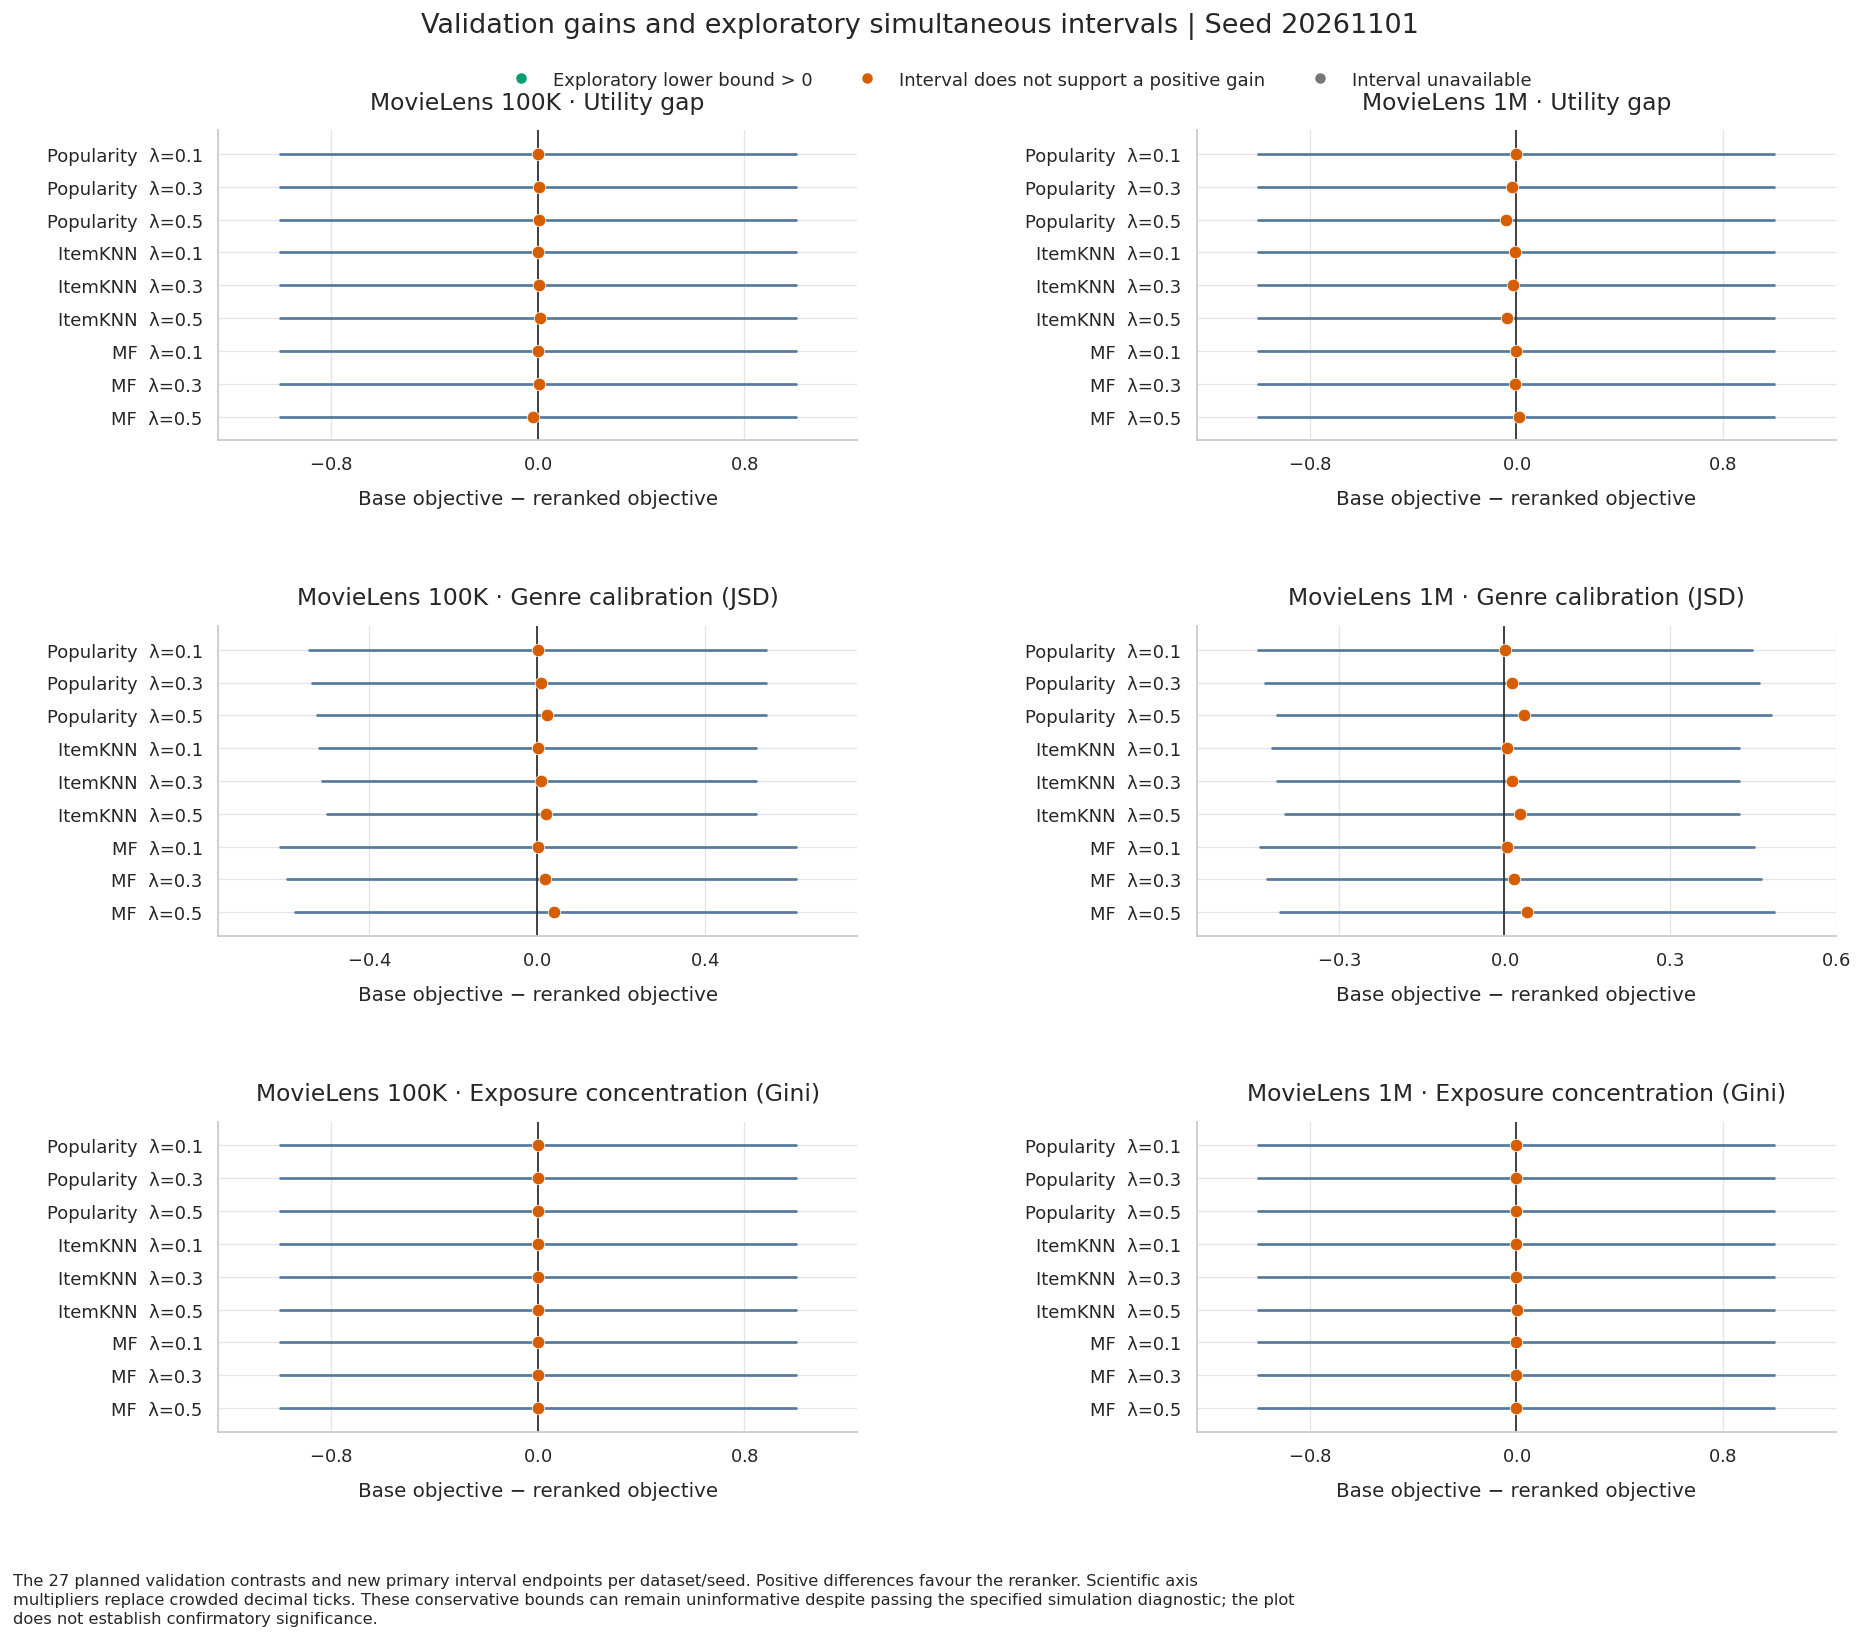

In [30]:
# RQ2: unchanged simultaneous contrasts; larger six-panel layout and scientific ticks.
patch_contrasts=patch_read_table('RQ2_Table1_simultaneous_contrasts')
patch_objectives=[('group_gap','Utility gap'),('genre_JSD','Genre calibration (JSD)'),
                  ('exposure_Gini','Exposure concentration (Gini)')]
with mpl.rc_context(PATCH_STYLE):
    fig,axes=plt.subplots(3,len(PATCH_DATASETS),figsize=(15,13),squeeze=False)
    fig.subplots_adjust(left=.14,right=.97,top=.91,bottom=.14,hspace=.6,wspace=.53)
    fig.suptitle(f'Validation gains and exploratory simultaneous intervals | Seed {PATCH_PRIMARY_SEED}',y=.98,fontsize=15)
    for col,tag in enumerate(PATCH_DATASETS):
        for row,(objective,title) in enumerate(patch_objectives):
            ax=axes[row,col]
            q=patch_contrasts[(patch_contrasts.dataset==tag)&(patch_contrasts.seed==PATCH_PRIMARY_SEED)&
                               (patch_contrasts.objective==objective)].copy().reset_index(drop=True)
            for j,r in q.iterrows():
                finite=np.isfinite(r.low) and np.isfinite(r.high)
                color='#009E73' if finite and r.low>0 else '#D55E00' if finite else '#777777'
                if finite:ax.plot([r.low,r.high],[j,j],color='#567A9C',linewidth=1.5,zorder=2)
                if np.isfinite(r.gain):ax.scatter(r.gain,j,color=color,s=48,zorder=3,edgecolors='white',linewidth=.4)
            names=[f"{x.split('__')[0]}  λ={x.rsplit('_',1)[-1]}" for x in q.reranker]
            ax.set_yticks(np.arange(len(q)),names);ax.invert_yaxis()
            ax.axvline(0,color='#333333',linewidth=1)
            ax.set_title(f'MovieLens {tag.upper()} · {title}',pad=12)
            ax.set_xlabel('Base objective − reranked objective',labelpad=9)
            ax.xaxis.set_major_locator(MaxNLocator(nbins=4,min_n_ticks=3))
            formatter=ScalarFormatter(useMathText=True);formatter.set_powerlimits((-3,3));formatter.set_useOffset(False)
            ax.xaxis.set_major_formatter(formatter);ax.xaxis.get_offset_text().set_fontsize(10)
            ax.margins(x=.12,y=.09);patch_grid(ax)
    handles=[Line2D([],[],marker='o',ls='',color='#009E73',label='Exploratory lower bound > 0'),
             Line2D([],[],marker='o',ls='',color='#D55E00',label='Interval does not support a positive gain'),
             Line2D([],[],marker='o',ls='',color='#777777',label='Interval unavailable')]
    fig.legend(handles=handles,loc='upper center',bbox_to_anchor=(.55,.955),ncol=3,frameon=False,fontsize=10)
    patch_save(fig,'RQ2_Figure1_simultaneous_intervals',
        'The 27 planned validation contrasts and new primary interval endpoints per dataset/seed. Positive differences favour the reranker. '
        'Scientific axis multipliers replace crowded decimal ticks. These conservative bounds can remain uninformative despite passing the specified simulation diagnostic; '
        'the plot does not establish confirmatory significance.')


### Updated figure cell 57

Presentation only: use this run’s saved scientific estimates; retain the latest layout, legends and non-overlapping annotations.


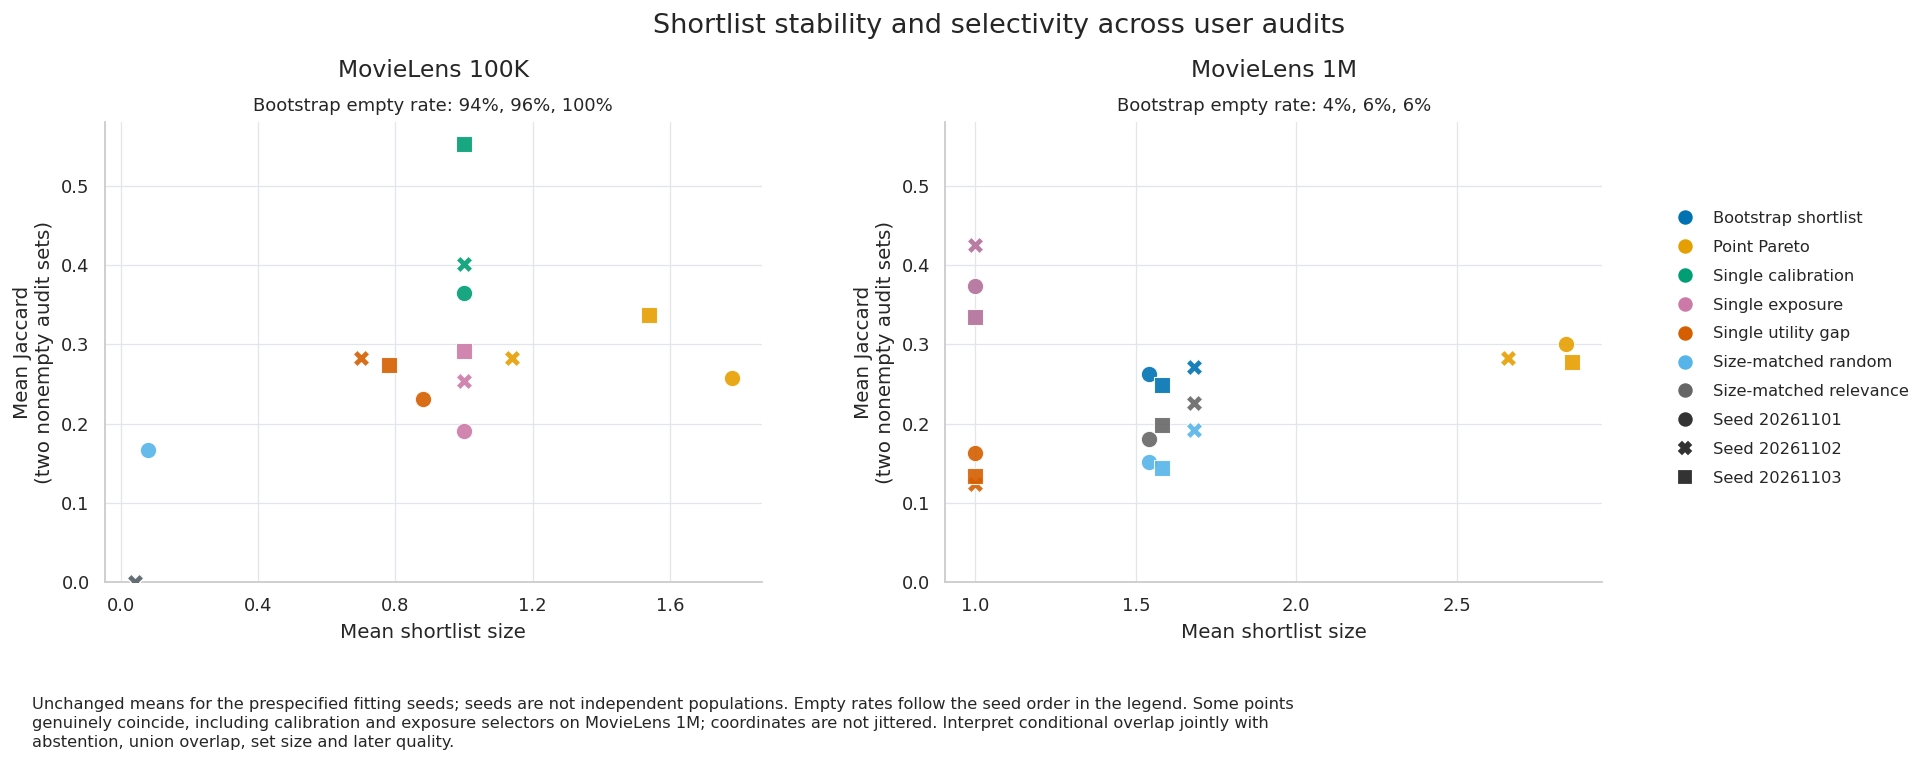

In [31]:
# RQ3: preserve exact point coordinates; move the shared legend outside the axes.
patch_stability=patch_read_table('RQ3_Table1_stability_selectivity_quality')
with mpl.rc_context(PATCH_STYLE):
    fig,axes=plt.subplots(1,len(PATCH_DATASETS),figsize=(16,6),squeeze=False)
    fig.subplots_adjust(left=.07,right=.79,bottom=.24,top=.83,wspace=.28)
    fig.suptitle('Shortlist stability and selectivity across user audits',y=.97,fontsize=15)
    for ax,tag in zip(axes[0],PATCH_DATASETS):
        q=patch_stability[patch_stability.dataset==tag]
        patch_rule_points(ax,q,'mean_size','mean_jaccard')
        ax.set_title(f'MovieLens {tag.upper()}',pad=25)
        ax.set_xlabel('Mean shortlist size');ax.set_ylabel('Mean Jaccard\n(two nonempty audit sets)')
        ax.set_ylim(0,.58);ax.xaxis.set_major_locator(MaxNLocator(5));patch_grid(ax)
        rates=q[q.rule=='Bootstrap'].sort_values('seed')
        ax.text(.5,1.025,'Bootstrap empty rate: '+', '.join(f'{r.empty_rate:.0%}' for r in rates.itertuples()),
                transform=ax.transAxes,ha='center',fontsize=10)
    patch_legend(fig)
    patch_save(fig,'RQ3_Figure1_stability_size',
        'Unchanged means for the prespecified fitting seeds; seeds are not independent populations. Empty rates follow the seed order in the legend. '
        'Some points genuinely coincide, including calibration and exposure selectors on MovieLens 1M; coordinates are not jittered. '
        'Interpret conditional overlap jointly with abstention, union overlap, set size and later quality.')


### Updated figure cell 59

Presentation only: use this run’s saved scientific estimates; retain the latest layout, legends and non-overlapping annotations.


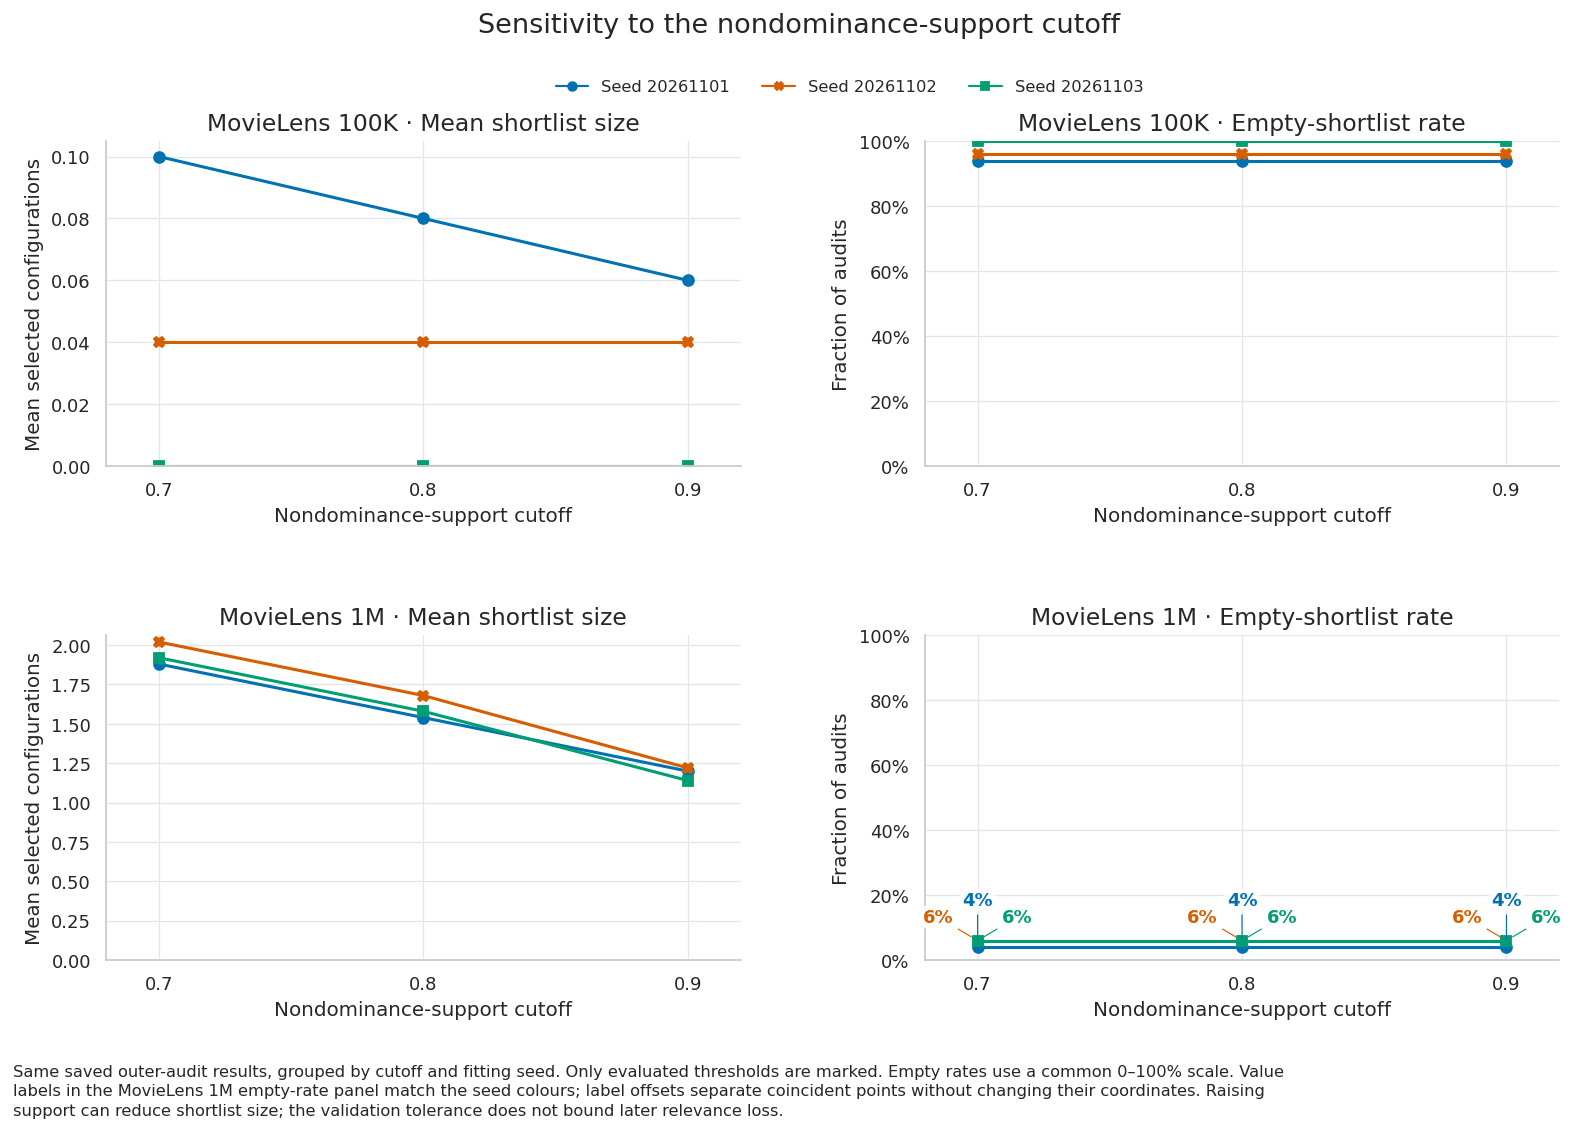

In [32]:
# RQ3: keep the original values, but show only the three evaluated support cutoffs.
patch_thresholds = patch_read_table('RQ3_threshold_sensitivity')

patch_threshold_summary = (
    patch_thresholds.groupby(['dataset', 'seed', 'threshold'])
    .agg(
        mean_size=('size', 'mean'),
        empty_rate=('size', lambda s: np.mean(s == 0))
    )
    .reset_index()
)

with mpl.rc_context(PATCH_STYLE):
    fig, axes = plt.subplots(
        len(PATCH_DATASETS), 2,
        figsize=(13, 9),
        squeeze=False
    )

    fig.subplots_adjust(
        left=.09, right=.95,
        top=.86, bottom=.16,
        hspace=.52, wspace=.29
    )

    fig.suptitle(
        'Sensitivity to the nondominance-support cutoff',
        y=.97, fontsize=15
    )

    seed_colors = dict(zip(
        PATCH_SEEDS,
        ['#0072B2', '#D55E00', '#009E73']
    ))

    # Separate labels for coincident points without changing their coordinates.
    label_offsets = [(0, 21), (-22, 8), (22, 8)]

    for row, tag in enumerate(PATCH_DATASETS):
        for col, metric in enumerate(['mean_size', 'empty_rate']):
            ax = axes[row, col]
            q = patch_threshold_summary[
                patch_threshold_summary.dataset == tag
            ]

            for seed, g in q.groupby('seed'):
                seed = int(seed)
                g = g.sort_values('threshold')

                ax.plot(
                    g.threshold,
                    g[metric],
                    marker=PATCH_MARKERS[seed],
                    color=seed_colors[seed],
                    linewidth=1.7,
                    markersize=6
                )

                # Add value labels ONLY to the MovieLens 1M empty-rate panel.
                if tag == '1m' and metric == 'empty_rate':
                    seed_index = PATCH_SEEDS.index(seed)
                    offset = label_offsets[seed_index]

                    for cutoff, value in zip(g.threshold, g[metric]):
                        if np.isfinite(value):
                            ax.annotate(
                                f'{value:.0%}',
                                xy=(cutoff, value),
                                xytext=offset,
                                textcoords='offset points',
                                ha='center',
                                va='bottom',
                                fontsize=10,
                                fontweight='semibold',
                                color=seed_colors[seed],
                                annotation_clip=False,
                                zorder=6,
                                bbox=dict(
                                    boxstyle='round,pad=0.12',
                                    facecolor='white',
                                    edgecolor='none',
                                    alpha=.9
                                ),
                                arrowprops=dict(
                                    arrowstyle='-',
                                    color=seed_colors[seed],
                                    linewidth=.65,
                                    shrinkA=2,
                                    shrinkB=4
                                )
                            )

            ax.set_xticks(sorted(q.threshold.unique()))
            ax.set_xlim(.68, .92)
            ax.set_xlabel('Nondominance-support cutoff')

            ax.set_title(
                f'MovieLens {tag.upper()} · ' +
                ('Mean shortlist size' if col == 0
                 else 'Empty-shortlist rate')
            )

            ax.set_ylabel(
                'Mean selected configurations' if col == 0
                else 'Fraction of audits'
            )

            if col == 1:
                ax.set_ylim(0, 1)
                ax.yaxis.set_major_formatter(
                    PercentFormatter(1, decimals=0)
                )
            else:
                ax.set_ylim(bottom=0)

            patch_grid(ax)

    fig.legend(
        handles=[
            Line2D(
                [], [],
                marker=PATCH_MARKERS[s],
                color=seed_colors[s],
                label=f'Seed {s}'
            )
            for s in PATCH_SEEDS
        ],
        loc='upper center',
        bbox_to_anchor=(.53, .925),
        ncol=3,
        frameon=False
    )

    patch_save(
        fig,
        'RQ3_Figure2_threshold_sensitivity',
        'Same saved outer-audit results, grouped by cutoff and fitting seed. '
        'Only evaluated thresholds are marked. Empty rates use a common '
        '0–100% scale. Value labels in the MovieLens 1M empty-rate panel '
        'match the seed colours; label offsets separate coincident points '
        'without changing their coordinates. Raising support can reduce '
        'shortlist size; the validation tolerance does not bound later '
        'relevance loss.'
    )

### Updated figure cell 61

Presentation only: use this run’s saved scientific estimates; retain the latest layout, legends and non-overlapping annotations.


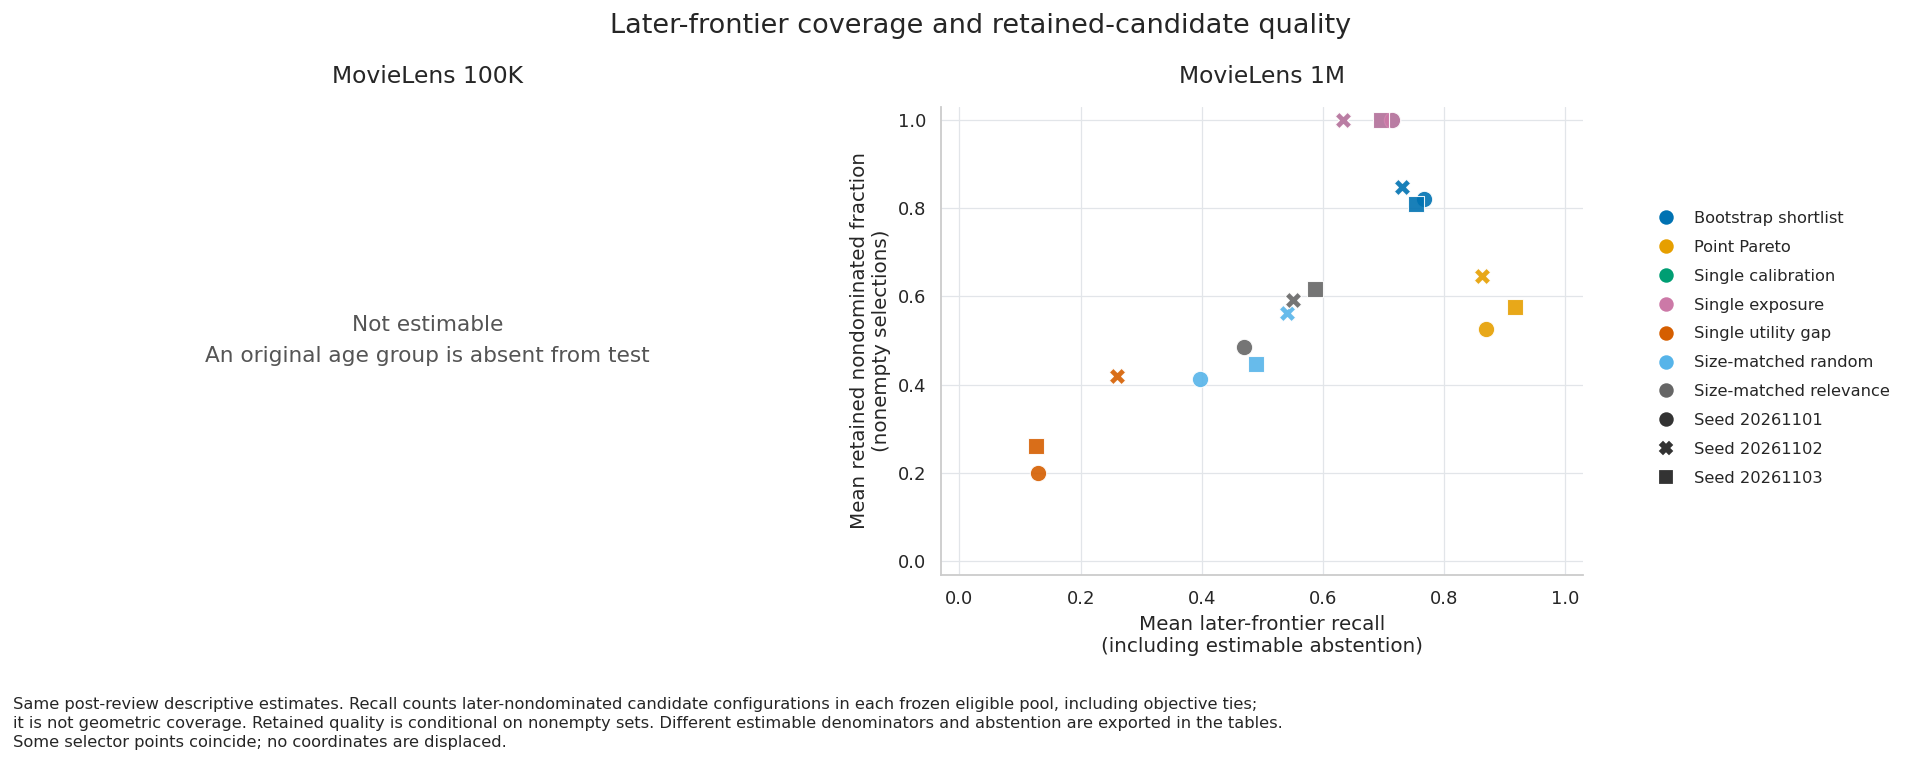

In [33]:
# RQ3: shorten the axis labels and move the selector/seed legends outside.
patch_coverage=patch_read_table('RQ3_frontier_recall_and_retained_quality')
with mpl.rc_context(PATCH_STYLE):
    fig,axes=plt.subplots(1,len(PATCH_DATASETS),figsize=(16,6),squeeze=False)
    fig.subplots_adjust(left=.08,right=.79,top=.85,bottom=.25,wspace=.3)
    fig.suptitle('Later-frontier coverage and retained-candidate quality',y=.97,fontsize=15)
    for ax,tag in zip(axes[0],PATCH_DATASETS):
        q=patch_coverage[patch_coverage.dataset==tag].copy()
        ax.set_title(f'MovieLens {tag.upper()}',pad=13)
        if q.mean_recall.notna().any():
            q['retained_nondominated_fraction']=1-q.mean_dominated
            patch_rule_points(ax,q,'mean_recall','retained_nondominated_fraction')
            ax.set(xlim=(-.03,1.03),ylim=(-.03,1.03),
                xlabel='Mean later-frontier recall\n(including estimable abstention)',
                ylabel='Mean retained nondominated fraction\n(nonempty selections)')
            patch_grid(ax)
        else:
            ax.set_axis_off()
            ax.text(.5,.5,'Not estimable\nAn original age group is absent from test',transform=ax.transAxes,
                    ha='center',va='center',fontsize=12,color='#555555',linespacing=1.7)
    patch_legend(fig)
    patch_save(fig,'RQ3_Figure3_frontier_coverage',
        'Same post-review descriptive estimates. Recall counts later-nondominated candidate configurations in each frozen eligible pool, including objective ties; '
        'it is not geometric coverage. Retained quality is conditional on nonempty sets. Different estimable denominators and abstention are exported in the tables. '
        'Some selector points coincide; no coordinates are displaced.')


### Updated figure cell 63

Presentation only: use this run’s saved scientific estimates; retain the latest layout, legends and non-overlapping annotations.


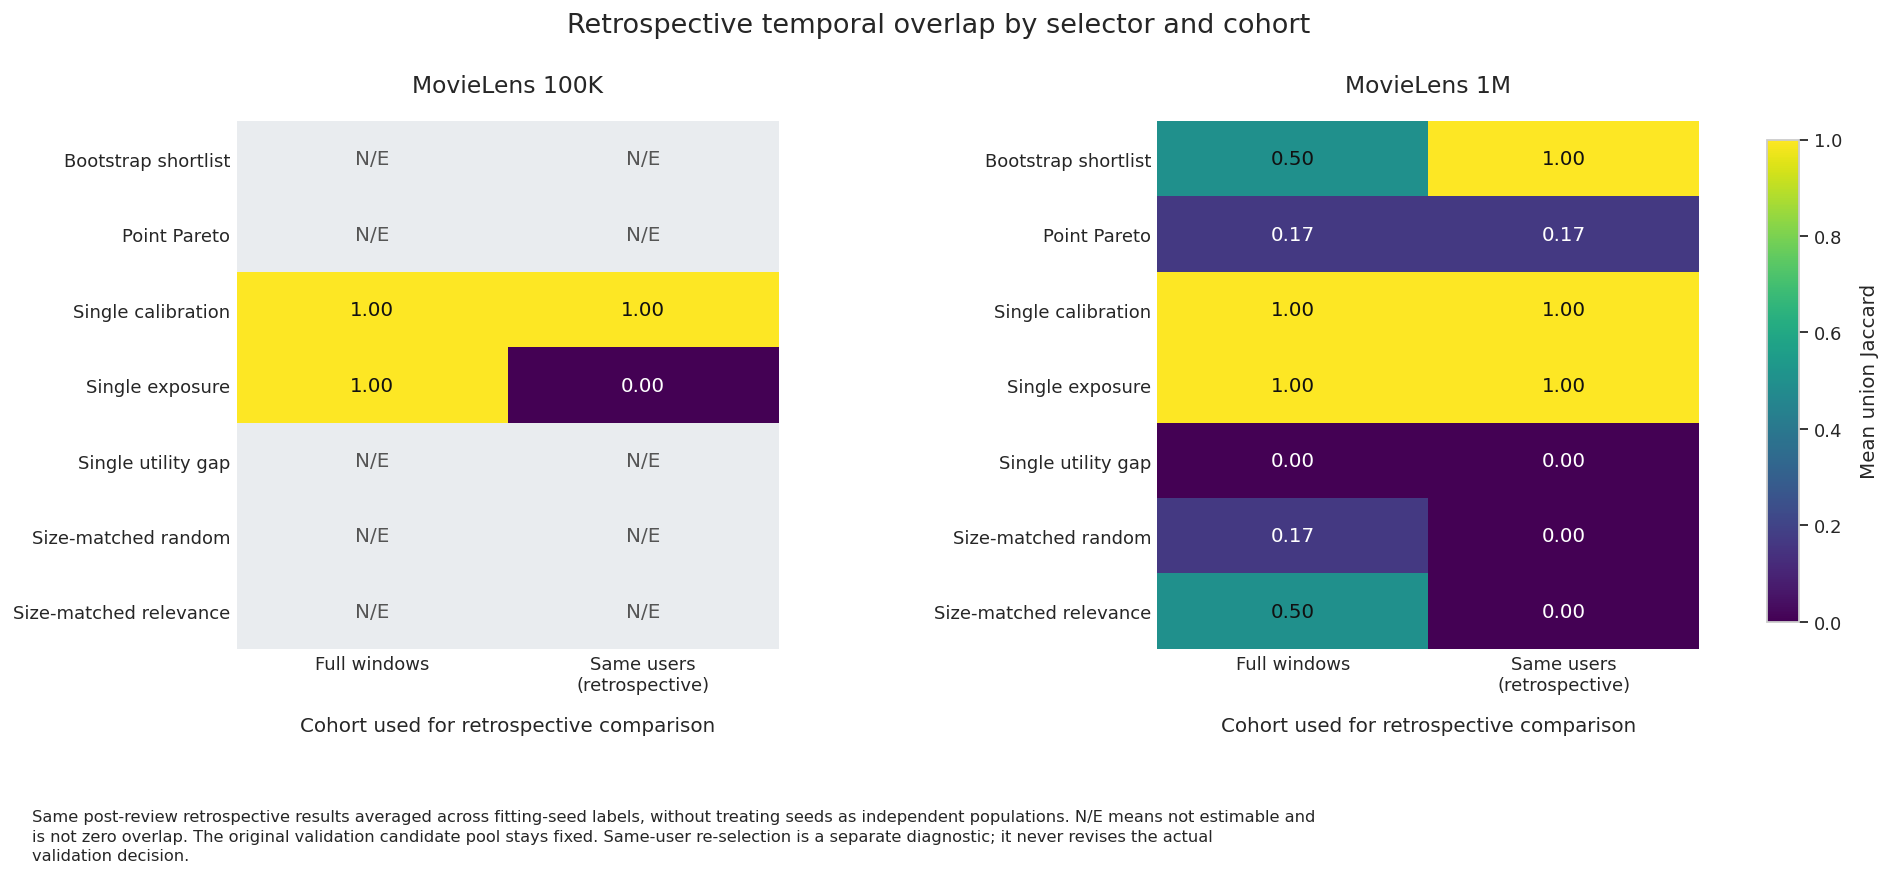

In [34]:
# RQ3: readable cohort names and explicit N/E cells instead of ambiguous blank cells.
patch_temporal=patch_read_table('RQ3_frozen_temporal_diagnostics')
patch_scopes=['full_windows','same_users_retrospective']
with mpl.rc_context(PATCH_STYLE):
    fig,axes=plt.subplots(1,len(PATCH_DATASETS),figsize=(15,7),squeeze=False)
    fig.subplots_adjust(left=.14,right=.89,top=.84,bottom=.26,wspace=.7)
    fig.suptitle('Retrospective temporal overlap by selector and cohort',y=.96,fontsize=15)
    cmap=plt.get_cmap('viridis').copy();cmap.set_bad('#E9ECEF')
    for ax,tag in zip(axes[0],PATCH_DATASETS):
        q=patch_temporal[(patch_temporal.dataset==tag)&(patch_temporal.metric_family=='three_fairness_objectives')]
        mat=q.groupby(['rule','scope']).union_jaccard.mean().unstack().reindex(index=PATCH_RULES,columns=patch_scopes)
        values=mat.to_numpy(float)
        im=ax.imshow(np.ma.masked_invalid(values),cmap=cmap,vmin=0,vmax=1,aspect='auto')
        for i in range(len(PATCH_RULES)):
            for j in range(len(patch_scopes)):
                val=values[i,j]
                ax.text(j,i,'N/E' if not np.isfinite(val) else f'{val:.2f}',ha='center',va='center',
                        fontsize=11,color='#555555' if not np.isfinite(val) else 'white' if val<.4 else '#111111')
        ax.set_xticks([0,1],['Full windows','Same users\n(retrospective)'])
        ax.set_yticks(range(len(PATCH_RULES)),[PATCH_RULE_LABELS[r] for r in PATCH_RULES])
        ax.set_xlabel('Cohort used for retrospective comparison',labelpad=12)
        ax.set_title(f'MovieLens {tag.upper()}',pad=16)
        ax.tick_params(axis='both',length=0)
        for spine in ax.spines.values():spine.set_visible(False)
    cax=fig.add_axes([.925,.29,.016,.53]);cb=fig.colorbar(im,cax=cax);cb.set_label('Mean union Jaccard',labelpad=10)
    patch_save(fig,'RQ3_Figure4_comparative_turnover',
        'Same post-review retrospective results averaged across fitting-seed labels, without treating seeds as independent populations. N/E means not estimable '
        'and is not zero overlap. The original validation candidate pool stays fixed. Same-user re-selection is a separate diagnostic; it never revises the actual validation decision.')


### Updated figure cell 65

Presentation only: use this run’s saved scientific estimates; retain the latest layout, legends and non-overlapping annotations.


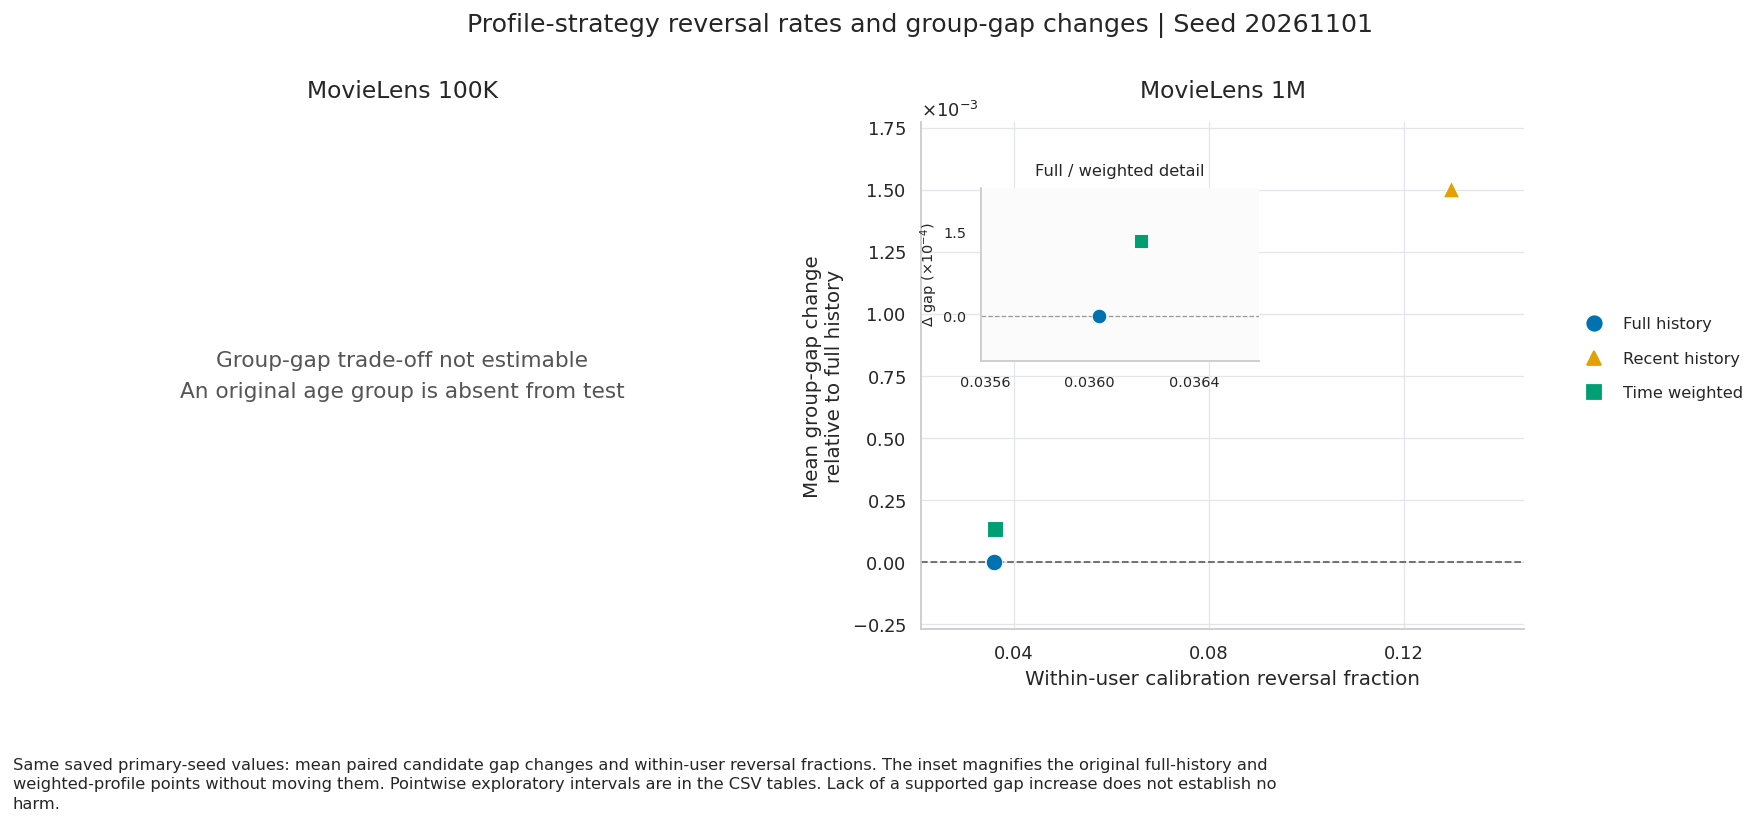

In [35]:
# RQ5: replace colliding direct labels with a legend; magnify the two near-zero points.
patch_profiles=patch_read_table('RQ5_profile_strategy_metrics')
patch_gaps=patch_read_table('RQ5_paired_group_gap_changes')
patch_metrics=patch_read_table('all_candidate_metrics')
with mpl.rc_context(PATCH_STYLE):
    fig,axes=plt.subplots(1,len(PATCH_DATASETS),figsize=(15,6.5),squeeze=False)
    fig.subplots_adjust(left=.08,right=.81,top=.84,bottom=.24,wspace=.36)
    fig.suptitle(f'Profile-strategy reversal rates and group-gap changes | Seed {PATCH_PRIMARY_SEED}',y=.97,fontsize=14)
    mode_markers={'full':'o','recent':'^','weighted':'s'}
    for ax,tag in zip(axes[0],PATCH_DATASETS):
        ax.set_title(f'MovieLens {tag.upper()}',pad=14)
        test=patch_metrics[(patch_metrics.dataset==tag)&(patch_metrics.seed==PATCH_PRIMARY_SEED)&
                           (patch_metrics.window=='test')&(patch_metrics.K==10)]
        if test.empty or not np.isfinite(test.group_gap).all():
            ax.set_axis_off()
            ax.text(.5,.5,'Group-gap trade-off not estimable\nAn original age group is absent from test',
                    transform=ax.transAxes,ha='center',va='center',fontsize=12,color='#555555',linespacing=1.7)
            continue
        q=patch_profiles[(patch_profiles.dataset==tag)&(patch_profiles.seed==PATCH_PRIMARY_SEED)&
                         (patch_profiles.window=='paired')]
        points={}
        for mode in ['full','recent','weighted']:
            x=q.loc[q.strategy==mode,'reversal_rate']
            g=patch_gaps[(patch_gaps.dataset==tag)&(patch_gaps.seed==PATCH_PRIMARY_SEED)&(patch_gaps.strategy==mode)]
            y=0. if mode=='full' else g.gap_change.mean()
            if len(x) and np.isfinite(x.iloc[0]) and np.isfinite(y):
                points[mode]=(float(x.iloc[0]),float(y))
                ax.scatter(*points[mode],s=85,color=PATCH_PROFILE_COLORS[mode],marker=mode_markers[mode],
                           edgecolors='white',linewidth=.6,zorder=4)
        ax.axhline(0,color='#666666',ls='--',lw=1)
        ax.set_xlabel('Within-user calibration reversal fraction')
        ax.set_ylabel('Mean group-gap change\nrelative to full history')
        ax.xaxis.set_major_locator(MaxNLocator(4));ax.margins(x=.16,y=.18);patch_grid(ax)
        formatter=ScalarFormatter(useMathText=True);formatter.set_powerlimits((-3,3));formatter.set_useOffset(False)
        ax.yaxis.set_major_formatter(formatter)
        if 'full' in points and 'weighted' in points:
            inset=ax.inset_axes([.1,.53,.46,.34]);inset.set_facecolor('#FBFBFB')
            for mode in ['full','weighted']:
                inset.scatter(*points[mode],s=65,color=PATCH_PROFILE_COLORS[mode],marker=mode_markers[mode],
                              edgecolors='white',linewidth=.5,zorder=3)
            xs=[points[m][0] for m in ['full','weighted']];ys=[points[m][1] for m in ['full','weighted']]
            dx=max(np.ptp(xs),.001);dy=max(np.ptp(ys),1e-5)
            inset.set_xlim(min(xs)-.45*dx,max(xs)+.45*dx);inset.set_ylim(min(ys)-.6*dy,max(ys)+.7*dy)
            inset.set_title('Full / weighted detail',fontsize=9,pad=7)
            inset.tick_params(labelsize=8);inset.xaxis.set_major_locator(MaxNLocator(3))
            inset.yaxis.set_major_locator(MaxNLocator(3));inset.axhline(0,color='#999999',ls='--',lw=.7)
            magnitude=max(abs(np.asarray(ys)))
            power=int(np.floor(np.log10(magnitude))) if magnitude>0 else 0
            unit=10.**power
            inset.yaxis.set_major_formatter(FuncFormatter(lambda value,pos,scale=unit:f'{value/scale:.1f}'))
            inset.set_ylabel(r'$\Delta$ gap ($\times 10^{'+str(power)+'}$)',fontsize=8,labelpad=2)
    fig.legend(handles=[Line2D([],[],marker=mode_markers[m],ls='',color=PATCH_PROFILE_COLORS[m],
                label=PATCH_PROFILE_LABELS[m],markersize=8) for m in ['full','recent','weighted']],
               loc='center left',bbox_to_anchor=(.83,.56),frameon=False,labelspacing=1.2)
    patch_save(fig,'RQ5_Figure2_profile_tradeoffs',
        'Same saved primary-seed values: mean paired candidate gap changes and within-user reversal fractions. The inset magnifies the original full-history '
        'and weighted-profile points without moving them. Pointwise exploratory intervals are in the CSV tables. Lack of a supported gap increase does not establish no harm.')


### Updated figure cell 67

Presentation only: use this run’s saved scientific estimates; retain the latest layout, legends and non-overlapping annotations.


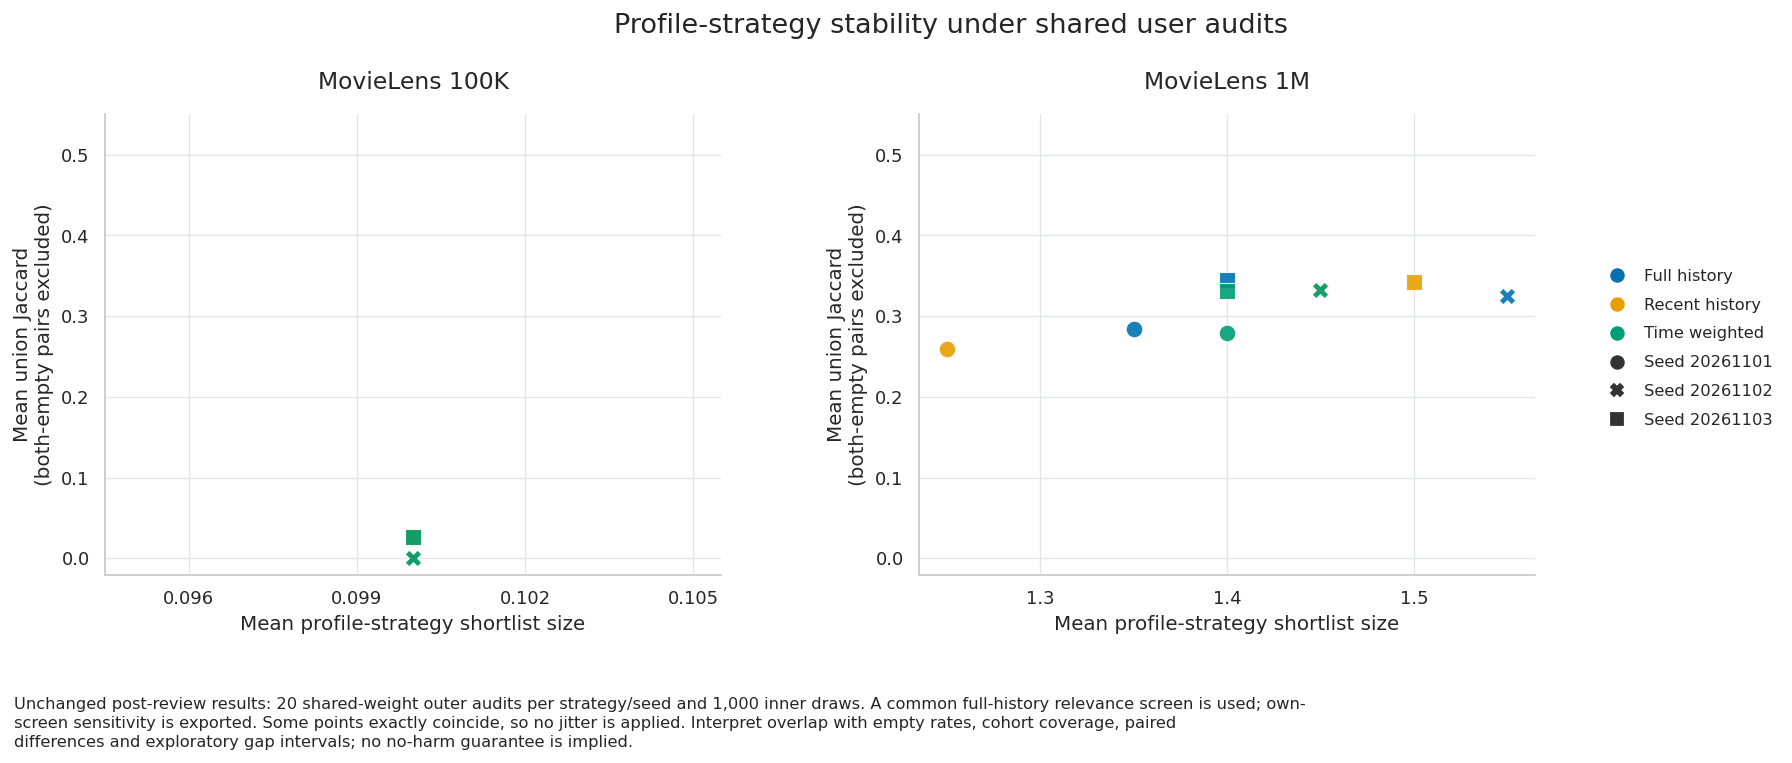

In [36]:
# RQ5: shared outside legend and shorter labels; data coordinates are unchanged.
patch_profile_stability=patch_read_table('RQ5_profile_nested_stability')
with mpl.rc_context(PATCH_STYLE):
    fig,axes=plt.subplots(1,len(PATCH_DATASETS),figsize=(15.5,6),squeeze=False)
    fig.subplots_adjust(left=.08,right=.79,top=.84,bottom=.25,wspace=.32)
    fig.suptitle('Profile-strategy stability under shared user audits',y=.97,fontsize=15)
    for ax,tag in zip(axes[0],PATCH_DATASETS):
        q=patch_profile_stability[(patch_profile_stability.dataset==tag)&(patch_profile_stability.rule=='Bootstrap')&
                                  (patch_profile_stability.pool_definition=='common_full_history_screen')]
        if q.mean_union_jaccard.notna().any():
            for mode in ['full','recent','weighted']:
                for seed in PATCH_SEEDS:
                    g=q[(q.strategy==mode)&(q.seed==seed)]
                    ax.scatter(g.mean_size,g.mean_union_jaccard,s=85,marker=PATCH_MARKERS[seed],
                               color=PATCH_PROFILE_COLORS[mode],edgecolors='white',linewidth=.6,alpha=.9,zorder=3)
        else:ax.text(.5,.5,'No estimable audit pairs',transform=ax.transAxes,ha='center')
        ax.set_title(f'MovieLens {tag.upper()}',pad=14)
        ax.set_xlabel('Mean profile-strategy shortlist size')
        ax.set_ylabel('Mean union Jaccard\n(both-empty pairs excluded)')
        ax.set_ylim(-.02,.55);ax.xaxis.set_major_locator(MaxNLocator(4));patch_grid(ax)
    patch_legend(fig,profiles=True)
    patch_save(fig,'RQ5_Figure3_profile_audit_stability',
        'Unchanged post-review results: 20 shared-weight outer audits per strategy/seed and 1,000 inner draws. A common full-history relevance screen is used; '
        'own-screen sensitivity is exported. Some points exactly coincide, so no jitter is applied. Interpret overlap with empty rates, cohort coverage, paired differences '
        'and exploratory gap intervals; no no-harm guarantee is implied.')


## 27. Validation report and COMPLETE results ZIP — run last

Audit counts, original-group feasibility, pinned-author reference statuses, independent-domain completion and full-family calibration are summarized as evidence checks. A technical gate failure is retained in the package and prevents claiming the analysis is validated; no cell declares the work novel or accepted. Export all PDF figures, CSV tables, protocol/source/assumption records and checksums into one ZIP. The link points to the ZIP from this run only.


,dataset,stage,seconds,seed,window
0,100k,deterministic_fit,0.188895,NaN,NaN
1,1m,deterministic_fit,1.069322,NaN,NaN
2,100k,Popularity_retrieval_reranking,1.937783,20261101.0,val
3,100k,ItemKNN_retrieval_reranking,0.237438,20261101.0,val
4,100k,MF_retrieval_reranking,0.211515,20261101.0,val
5,100k,Popularity_retrieval_reranking,0.099801,20261101.0,test
6,100k,ItemKNN_retrieval_reranking,0.112514,20261101.0,test
7,100k,MF_retrieval_reranking,0.100134,20261101.0,test
8,100k,Popularity_retrieval_reranking,0.218930,20261102.0,val
9,100k,ItemKNN_retrieval_reranking,0.247661,20261102.0,val


,dataset,window,users,k,status,steps,seconds,detail,commit,variant,termination,global_oracle_claim
0,100k,val,77,10,reference_failed:IndexError,119,0.909338,index 0 is out of bounds for axis 0 with size 0,d5ca1dfbcbe67f587d55493381d5601fbcd21c61,strict_original,failed,False
1,100k,val,77,10,complete,932,6.189879,documented feasibility guards plus explicit pa...,d5ca1dfbcbe67f587d55493381d5601fbcd21c61,feasibility_adapted,author_stopping_rule,False
2,1m,val,182,10,complete,1900,18.668779,strict original algorithm with explicit pandas...,d5ca1dfbcbe67f587d55493381d5601fbcd21c61,strict_original,author_stopping_rule,False
3,1m,val,182,10,complete,1900,19.404812,documented feasibility guards plus explicit pa...,d5ca1dfbcbe67f587d55493381d5601fbcd21c61,feasibility_adapted,author_stopping_rule,False
4,100k,val,77,10,complete,1004,6.678768,documented feasibility guards plus explicit pa...,d5ca1dfbcbe67f587d55493381d5601fbcd21c61,feasibility_adapted,author_stopping_rule,False
...,...,...,...,...,...,...,...,...,...,...,...,...
305,1m,val,182,10,complete,2258,20.399850,documented feasibility guards plus explicit pa...,d5ca1dfbcbe67f587d55493381d5601fbcd21c61,feasibility_adapted,author_stopping_rule,False
306,1m,val,182,10,complete,2252,20.808744,documented feasibility guards plus explicit pa...,d5ca1dfbcbe67f587d55493381d5601fbcd21c61,feasibility_adapted,author_stopping_rule,False
307,1m,val,182,10,complete,2256,20.060360,documented feasibility guards plus explicit pa...,d5ca1dfbcbe67f587d55493381d5601fbcd21c61,feasibility_adapted,author_stopping_rule,False
308,1m,val,182,10,complete,2235,20.159420,documented feasibility guards plus explicit pa...,d5ca1dfbcbe67f587d55493381d5601fbcd21c61,feasibility_adapted,author_stopping_rule,False


,dataset,window,users,k,status,steps,seconds,detail,commit,variant,termination,global_oracle_claim
0,100k,val,77,10,reference_failed:IndexError,119,0.909338,index 0 is out of bounds for axis 0 with size 0,d5ca1dfbcbe67f587d55493381d5601fbcd21c61,strict_original,failed,False
2,1m,val,182,10,complete,1900,18.668779,strict original algorithm with explicit pandas...,d5ca1dfbcbe67f587d55493381d5601fbcd21c61,strict_original,author_stopping_rule,False


,check,passed,detail
0,pinned_author_metric_equivalence,True,Original NDCG/Gini metric methods compared wit...
1,feasibility_adapted_references_complete,True,Completion of the explicitly modified feasibil...
2,full_family_simulation_diagnostic,True,Diagnostic tolerance is three Monte Carlo stan...
3,independent_partial_replication_complete,True,Only tag-calibration/exposure endpoints transf...
4,dense_original_marginal_groups_present,True,Checks original age marginals. Intersection co...
5,dense_profile_endpoints_recorded,True,A null association or failed noninferiority co...
6,100k_tuning_audit_users_disjoint,True,Model hyperparameters use tuning-user validati...
7,1m_tuning_audit_users_disjoint,True,Model hyperparameters use tuning-user validati...
8,1m_userchron_tuning_audit_users_disjoint,True,Model hyperparameters use tuning-user validati...
9,lastfm_tag_tuning_audit_users_disjoint,True,Model hyperparameters use tuning-user validati...


,dataset,seed,base,reranker,objective,validation_status,reversal,outcome_status,interval_method
0,100k,20261101,Popularity__lambda_0.0,Popularity__lambda_0.1,group_gap,unsupported,NaN,unavailable,simultaneous_Hoeffding_coordinate_envelope
1,100k,20261101,Popularity__lambda_0.0,Popularity__lambda_0.1,genre_JSD,unsupported,0.0,same_sign,simultaneous_Hoeffding_coordinate_envelope
2,100k,20261101,Popularity__lambda_0.0,Popularity__lambda_0.1,exposure_Gini,unsupported,1.0,opposite_sign,simultaneous_Hoeffding_coordinate_envelope
3,100k,20261101,Popularity__lambda_0.0,Popularity__lambda_0.3,group_gap,unsupported,NaN,unavailable,simultaneous_Hoeffding_coordinate_envelope
4,100k,20261101,Popularity__lambda_0.0,Popularity__lambda_0.3,genre_JSD,unsupported,0.0,same_sign,simultaneous_Hoeffding_coordinate_envelope
...,...,...,...,...,...,...,...,...,...
292,lastfm_tag,20261103,MF__lambda_0.0,MF__lambda_0.1,exposure_Gini,unsupported,1.0,opposite_sign,simultaneous_Hoeffding_coordinate_envelope
293,lastfm_tag,20261103,MF__lambda_0.0,MF__lambda_0.3,genre_JSD,unsupported,0.0,same_sign,simultaneous_Hoeffding_coordinate_envelope
294,lastfm_tag,20261103,MF__lambda_0.0,MF__lambda_0.3,exposure_Gini,unsupported,0.0,same_sign,simultaneous_Hoeffding_coordinate_envelope
295,lastfm_tag,20261103,MF__lambda_0.0,MF__lambda_0.5,genre_JSD,unsupported,0.0,same_sign,simultaneous_Hoeffding_coordinate_envelope


,dataset,seed,validation_status,planned,observed,reversals,missing,reversal_rate
0,100k,20261101,unsupported,27,18,2.0,9,0.111111
1,100k,20261102,unsupported,27,18,2.0,9,0.111111
2,100k,20261103,unsupported,27,18,2.0,9,0.111111
3,1m,20261101,unsupported,27,27,6.0,0,0.222222
4,1m,20261102,unsupported,27,27,8.0,0,0.296296
5,1m,20261103,unsupported,27,27,8.0,0,0.296296
6,1m_userchron,20261101,unsupported,27,27,3.0,0,0.111111
7,1m_userchron,20261102,unsupported,27,27,2.0,0,0.074074
8,1m_userchron,20261103,unsupported,27,27,5.0,0,0.185185
9,lastfm_tag,20261101,unsupported,18,18,4.0,0,0.222222


,dataset,seed,window,eligible,confidence_admissible_size,mean_primary_contrast_width,supported_positive_contrasts,caution
0,100k,20261101,val,4,4,1.701996,0,Confidence admissibility is distinct from boot...
1,100k,20261101,test,4,4,1.801731,0,Confidence admissibility is distinct from boot...
2,100k,20261102,val,4,4,1.700862,0,Confidence admissibility is distinct from boot...
3,100k,20261102,test,4,4,1.801283,0,Confidence admissibility is distinct from boot...
4,100k,20261103,val,4,4,1.702110,0,Confidence admissibility is distinct from boot...
5,100k,20261103,test,4,4,1.800754,0,Confidence admissibility is distinct from boot...
6,1m,20261101,val,8,8,1.624750,0,Confidence admissibility is distinct from boot...
7,1m,20261101,test,4,4,1.505197,0,Confidence admissibility is distinct from boot...
8,1m,20261102,val,8,8,1.624750,0,Confidence admissibility is distinct from boot...
9,1m,20261102,test,4,4,1.498189,0,Confidence admissibility is distinct from boot...


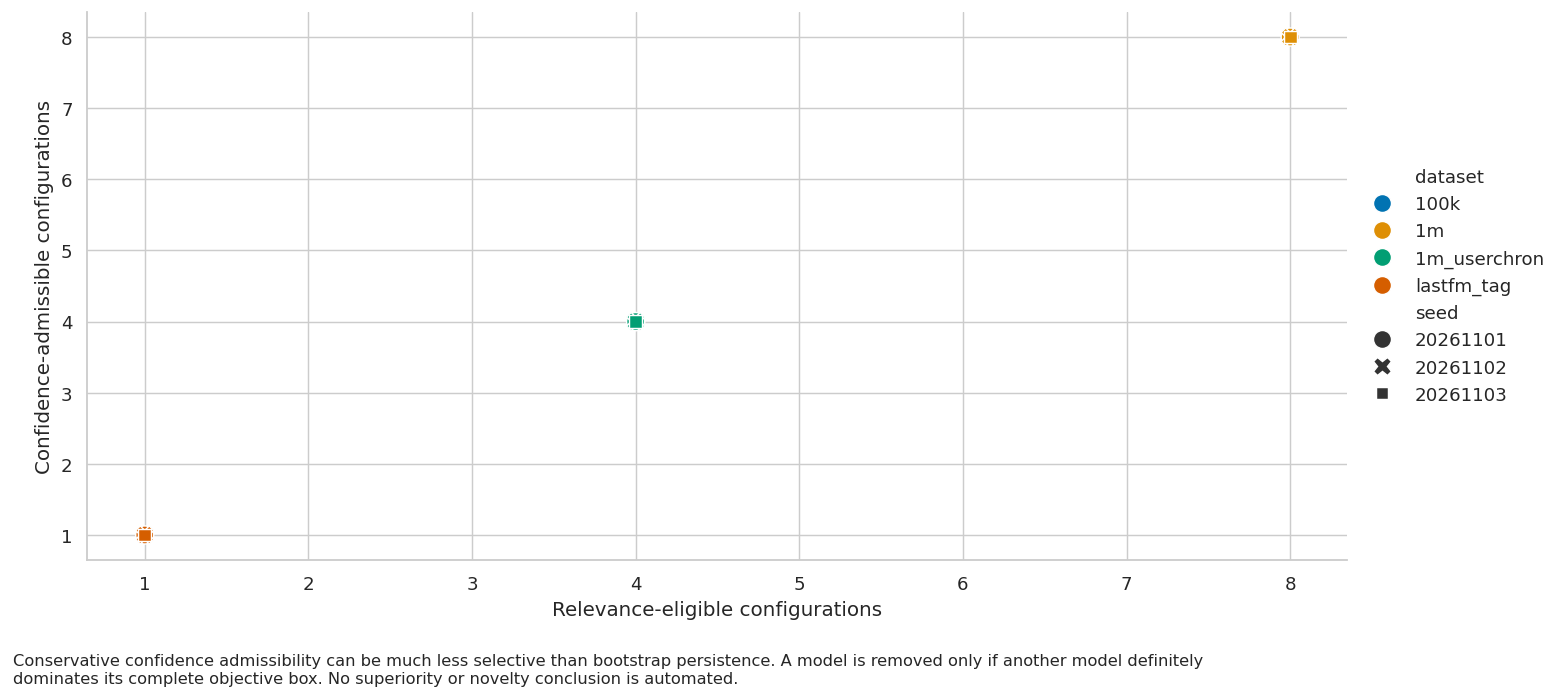

,kind,name,path,caption
0,table,release_audit,tables/release_audit.csv,NaN
1,table,chronological_split_audit,tables/chronological_split_audit.csv,NaN
2,table,100k_val_exclusion_counts,tables/100k_val_exclusion_counts.csv,NaN
3,table,100k_test_exclusion_counts,tables/100k_test_exclusion_counts.csv,NaN
4,table,1m_val_exclusion_counts,tables/1m_val_exclusion_counts.csv,NaN
...,...,...,...,...
104,table,technical_validation_gates,tables/technical_validation_gates.csv,NaN
105,table,Primary_RQ2_reversal_registry,tables/Primary_RQ2_reversal_registry.csv,NaN
106,table,Primary_RQ2_reversal_denominators,tables/Primary_RQ2_reversal_denominators.csv,NaN
107,table,Selection_confidence_persistence_boundary,tables/Selection_confidence_persistence_bounda...,NaN


Technical checks passed: True
Complete new-run results ZIP: Phantom_Troupe_Project9_Feasibility_Corrected_All_Results_20261109T180151_afe6d1.zip


/kaggle/working/Phantom_Troupe_Project9_Feasibility_Corrected_All_Results_20261109T180151_afe6d1.zip

Save a Kaggle version to persist the outputs, then download this ZIP from the saved version.


In [37]:
# All RQs: factual endpoint/gate report; archive is created even when scientific gates fail.
table(TIMINGS,'runtime_seconds')
AUTHOR_REFERENCE_LOG=table(AUTHOR_REFERENCE_LOG,'DPFR_author_reference_registry')
checks=[]
def gate(name,passed,detail):checks.append(dict(check=name,passed=bool(passed),detail=detail))
gate('pinned_author_metric_equivalence',AUTHOR_METRIC_PARITY,'Original NDCG/Gini metric methods compared with project metric collection on fixed fixtures.')
adapted_log=AUTHOR_REFERENCE_LOG.query("variant=='feasibility_adapted'")
strict_log=AUTHOR_REFERENCE_LOG.query("variant=='strict_original'")
table(strict_log,'DPFR_strict_original_diagnostics')
write_json('DPFR_original_parity_status',dict(end_to_end_parity_verified=False,
    strict_attempts=len(strict_log),strict_completed=int(strict_log.status.eq('complete').sum()),
    performance_comparator='FeasibilityAdaptedDPFR',
    instruction='Do not claim original DPFR superiority or end-to-end original-author parity.'))
gate('feasibility_adapted_references_complete',len(adapted_log)>0 and adapted_log.status.eq('complete').all(),
     'Completion of the explicitly modified feasibility-adapted comparator, not original DPFR parity. Constrained local optima remain labelled.')
q=FULL_CALIBRATION.query('method==@BOUND_METHOD');se=np.sqrt(.95*.05/C.calibration_repeats)
gate('full_family_simulation_diagnostic',len(q)>0 and (q.coverage>=.95-3*se).all(),
     'Diagnostic tolerance is three Monte Carlo standard errors; not a proof of coverage for real data or all DGPs. Inspect width and exact binomial intervals.')
gate('independent_partial_replication_complete','lastfm_tag' in set(REPLICATION_SUMMARY.dataset),
     'Only tag-calibration/exposure endpoints transfer; no demographic or listening-outcome claims.')
gate('dense_original_marginal_groups_present',DENSE_GROUPS.groupby(['window','age']).distinct_users.sum().gt(0).all(),
     'Checks original age marginals. Intersection counts and activity-stratum failures are retained; presence is not adequate power.')
gate('dense_profile_endpoints_recorded',len(DENSE_ASSOC)==len(C.seeds) and len(DENSE_GAPS)>0,
     'A null association or failed noninferiority conclusion is retained as a result, not converted to success.')
for tag,d in {**DATA,**REPLICATION_DATA}.items():
    gate(tag+'_tuning_audit_users_disjoint',not(d['tuning_users']&d['evaluation_users']),
         'Model hyperparameters use tuning-user validation outcomes; audit-user outcomes are not used for this choice.')
gate('no_error_guarantee_from_bootstrap_support',True,'Support frequency remains a descriptive persistence endpoint; all main confidence claims use the declared bounded-envelope construction.')
GATES=table(checks,'technical_validation_gates')
# Audit primary RQ2 denominators from the revised interval procedure.
rr=[]
for frame in [CONTRASTS,REPLICATION_CONTRASTS]:
    keys=['dataset','seed','base','reranker','objective']
    va=frame.query("window=='val'");te=frame.query("window=='test'")
    merged=va.merge(te,on=keys,suffixes=('_val','_test'))
    for r in merged.itertuples():
        status='undefined' if not (np.isfinite(r.low_val) and np.isfinite(r.gain_val)) else 'supported' if r.low_val>0 else 'unsupported'
        outcome,reason=reversal_endpoint(r.gain_val,r.gain_test)
        rr.append(dict(dataset=r.dataset,seed=r.seed,base=r.base,reranker=r.reranker,objective=r.objective,
            validation_status=status,reversal=outcome,outcome_status=reason,interval_method=BOUND_METHOD))
rr=table(rr,'Primary_RQ2_reversal_registry')
if len(rr):
    den=rr.groupby(['dataset','seed','validation_status']).agg(planned=('outcome_status','size'),observed=('reversal','count'),reversals=('reversal','sum')).reset_index()
    den['missing']=den.planned-den.observed;den['reversal_rate']=den.reversals/den.observed.replace(0,np.nan)
    table(den,'Primary_RQ2_reversal_denominators')
# Support-vs-confidence is measured, not declared novel/successful in advance.
confidence_rows=[]
for key,a in {**{k[:3]:v for k,v in AUDITS.items() if k[3]==10},**REPLICATION_AUDITS}.items():
    tag,seed,window=key;pt=metrics(a,np.ones(len(a.users)))[0]
    low,high,_=bounded_contrasts(a,BOUND_ALPHA)
    objectives=(2,3) if tag=='lastfm_tag' else (1,2,3)
    L,U,_=bounded_envelope(a,BOUND_ALPHA);pool=eligibility(pt)
    # Definitely dominated requires one other model whose upper objective box is
    # <= this model's lower box in all objectives, and strictly better in one.
    admissible=[]
    for m in pool:
        dominated=any(np.all(U[j,list(objectives)]<=L[m,list(objectives)]) and
                      np.any(U[j,list(objectives)]<L[m,list(objectives)]) for j in pool if j!=m)
        if not dominated:admissible.append(m)
    confidence_rows.append(dict(dataset=tag,seed=seed,window=window,eligible=len(pool),
        confidence_admissible_size=len(admissible),mean_primary_contrast_width=float(np.mean(high-low)),
        supported_positive_contrasts=int((low>0).sum()),
        caution='Confidence admissibility is distinct from bootstrap support and can retain all candidates.'))
CONFIDENCE=table(confidence_rows,'Selection_confidence_persistence_boundary')
fig,ax=plt.subplots(figsize=(12,5));q=CONFIDENCE.query("window=='val'")
sns.scatterplot(data=q,x='eligible',y='confidence_admissible_size',hue='dataset',style='seed',s=100,ax=ax)
ax.set(xlabel='Relevance-eligible configurations',ylabel='Confidence-admissible configurations');ax.legend(loc='center left',bbox_to_anchor=(1,.5),frameon=False)
fig.tight_layout();figure(fig,'Validation_Figure2_confidence_selectivity',
    'Conservative confidence admissibility can be much less selective than bootstrap persistence. A model is removed only if another model definitely dominates its complete objective box. No superiority or novelty conclusion is automated.')
# Check the figure-layout patch without relying on a stale completion marker.
for name in PATCH_TARGETS:
    item=PATCH_LOG['figures'][name]
    assert hashlib.sha256((ROOT/item['path']).read_bytes()).hexdigest()==item['updated_sha256']
for name,old_hash in PATCH_ORIGINAL_TABLE_HASHES.items():
    assert hashlib.sha256((ROOT/'tables'/name).read_bytes()).hexdigest()==old_hash
PATCH_LOG['packaged_utc']=pd.Timestamp.now(tz='UTC').isoformat();PATCH_LOG['scientific_csv_tables_unchanged']=True
PATCH_LOG_PATH.write_text(json.dumps(PATCH_LOG,indent=2))
write_json('technical_validation_report',dict(checks=checks,all_recorded_checks_passed=bool(GATES.passed.all()),
    publication_readiness='requires researcher/supervisor review; not automatically certified',
    novelty='proposed empirical contribution must be assessed against literature and newly executed results',
    historical_test_inspection=True,full_run_elapsed_seconds=time.time()-START))
write_json('run_status',dict(completed=True,all_technical_checks_passed=bool(GATES.passed.all()),config=asdict(C),
    original_global_protocols=list(DATA),additional_protocols=list(REPLICATION_DATA),elapsed_seconds=time.time()-START))
write_json('sources_and_scope',dict(
    movielens='https://grouplens.org/datasets/movielens/',lastfm='https://grouplens.org/datasets/hetrec-2011/',
    bound_source='https://www.learningtheory.org/colt2009/papers/012.pdf',
    dpfr='https://doi.org/10.1145/3696410.3714589',dpfr_repository='https://github.com/theresiavr/DPFR-recsys-evaluation',
    lastfm_citation='Cantador, Brusilovsky and Kuflik, HetRec 2011; Last.fm website. Dataset is non-commercial.',
    mathematical_novelty_claim=False,universal_stability_claim=False,causal_fairness_claim=False))
table(REGISTRY,'displayed_output_inventory')
checksum_path=ROOT/'manifest/output_checksums.json'
entries=[]
for path in sorted(ROOT.rglob('*')):
    if path.is_file() and path!=checksum_path:
        entries.append(dict(path=str(path.relative_to(ROOT)),bytes=path.stat().st_size,sha256=hashlib.sha256(path.read_bytes()).hexdigest()))
checksum_path.write_text(json.dumps(entries,indent=2))
ZIP=WORK/f'Phantom_Troupe_Project9_Feasibility_Corrected_All_Results_{RUN_ID}.zip'
temp=ZIP.with_suffix('.zip.tmp')
try:
    with zipfile.ZipFile(temp,'w',compression=zipfile.ZIP_DEFLATED) as bundle:
        for path in sorted(ROOT.rglob('*')):
            if path.is_file():bundle.write(path,arcname=str(Path(ROOT.name)/path.relative_to(ROOT)))
    with zipfile.ZipFile(temp) as bundle:
        assert bundle.testzip() is None
        for item in entries:
            assert hashlib.sha256(bundle.read(str(Path(ROOT.name)/item['path']))).hexdigest()==item['sha256']
    os.replace(temp,ZIP)
finally:
    if temp.exists():temp.unlink()
print('Technical checks passed:',bool(GATES.passed.all()))
if not GATES.passed.all():print('Inspect technical_validation_gates.csv before making publication-level claims.')
print('Complete new-run results ZIP:',ZIP.name)
os.chdir(WORK);display(FileLink(ZIP.name))
print('Save a Kaggle version to persist the outputs, then download this ZIP from the saved version.')


In [38]:
# Cell 1 — RQ1–RQ5: locate the completed run and prepare a separate figure-update copy.
# Copy cells below your completed project notebook and execute in order.
# No training, bootstrap, inference or scientific CSV table is changed.
# Optional: FIGURE_SOURCE_ROOT = '/kaggle/working/phantom_troupe_feasibility_revision_...'
from pathlib import Path
from datetime import datetime, timezone
import hashlib, json, os, shutil, textwrap, zipfile
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator, PercentFormatter, ScalarFormatter
import seaborn as sns
from IPython.display import display, FileLink

FP_WORK=Path('/kaggle/working') if Path('/kaggle/working').is_dir() else Path.cwd()
_fp_source=globals().get('FIGURE_SOURCE_ROOT',globals().get('ROOT'))
if _fp_source is None:
    candidates=[p for p in FP_WORK.glob('phantom_troupe_feasibility_revision_*')
                if p.is_dir() and not p.name.endswith('_readability_v2')
                and (p/'manifest/run_status.json').is_file()]
    if len(candidates)!=1:
        raise RuntimeError('Set FIGURE_SOURCE_ROOT to the completed results folder. Candidates: '+str(candidates))
    _fp_source=candidates[0]
FP_SOURCE=Path(_fp_source).resolve()
assert (FP_SOURCE/'manifest/run_status.json').is_file(),'Completed source results folder not found.'
assert json.loads((FP_SOURCE/'manifest/run_status.json').read_text())['completed'],'Source run is incomplete.'
FP_SOURCE_INDEX=FP_SOURCE/'manifest/output_checksums.json'
FP_SOURCE_DIGEST=hashlib.sha256(FP_SOURCE_INDEX.read_bytes()).hexdigest()
for entry in json.loads(FP_SOURCE_INDEX.read_text()):
    path=FP_SOURCE/entry['path']
    assert path.is_file() and hashlib.sha256(path.read_bytes()).hexdigest()==entry['sha256'],f'Source file changed: {path}'
FP_ROOT=FP_WORK/(FP_SOURCE.name+'_readability_v2')
FP_LOG=FP_ROOT/'manifest/publication_figure_update.json'
if FP_ROOT.exists():
    assert FP_LOG.is_file(),'Existing destination has no patch identity; choose another directory.'
    FP_META=json.loads(FP_LOG.read_text())
    assert FP_META['source_index_sha256']==FP_SOURCE_DIGEST,'Destination belongs to another source version.'
else:
    shutil.copytree(FP_SOURCE,FP_ROOT)
    FP_META=dict(patch='publication_readability_v2',source_root=FP_SOURCE.name,
        source_index_sha256=FP_SOURCE_DIGEST,created_utc=datetime.now(timezone.utc).isoformat(),
        scientific_values_changed=False,coordinate_jitter=False,
        print_width_mm=180,figures={})
    FP_LOG.write_text(json.dumps(FP_META,indent=2))
FP_SOURCE_TABLE_HASHES={p.name:hashlib.sha256(p.read_bytes()).hexdigest() for p in (FP_SOURCE/'tables').glob('*.csv')}
FP_SEEDS=tuple(json.loads((FP_SOURCE/'manifest/protocol.json').read_text())['seeds'])
FP_PRIMARY=FP_SEEDS[0]
FP_DATASETS=['100k','1m']
FP_AGES={1:'Under 18',18:'18–24',25:'25–34',35:'35–44',45:'45–49',50:'50–55',56:'56+'}
FP_RULES=['Bootstrap','PointPareto','SingleCalibration','SingleExposure','SingleGap','SizeMatchedRandom','SizeMatchedRelevance']
FP_LABELS=dict(zip(FP_RULES,['Bootstrap','Point Pareto','Calibration','Exposure','Utility gap','Random (matched size)','Relevance (matched size)']))
FP_ABBR=dict(zip(FP_RULES,['Boot','Pareto','Cal','Exp','Gap','Random','Rel']))
FP_COLORS=dict(zip(FP_RULES,['#0072B2','#E69F00','#009E73','#CC79A7','#D55E00','#56B4E9','#666666']))
FP_PROFILES=['full','recent','weighted']
FP_PROFILE_LABELS={'full':'Full history','recent':'Recent history','weighted':'Time weighted'}
FP_PROFILE_COLORS={'full':'#0072B2','recent':'#E69F00','weighted':'#009E73'}
FP_STYLE={'font.size':9,'axes.titlesize':10,'axes.labelsize':9,
          'xtick.labelsize':8,'ytick.labelsize':8,'legend.fontsize':8.5,
          'pdf.fonttype':42,'ps.fonttype':42,'figure.dpi':150,
          'axes.spines.top':False,'axes.spines.right':False,'axes.grid':False,
          'savefig.bbox':None}
FP_UPDATED=[]
FP_TARGETS=['Validation_Figure1_full_family_coverage','Dense_Figure1_group_resolution',
    'RQ4_Figure2_resolution_map','RQ1_Figure1_disagreement','RQ1_Figure2_winner_support',
    'RQ2_Figure1_simultaneous_intervals','RQ2_Figure2_later_reversals',
    'RQ3_Figure1_stability_size','RQ3_Figure2_threshold_sensitivity',
    'RQ3_Figure3_frontier_coverage','RQ3_Figure4_comparative_turnover',
    'RQ4_Figure1_composition_stress','RQ5_Figure1_prior_change',
    'RQ5_Figure2_profile_tradeoffs','RQ5_Figure3_profile_audit_stability',
    'Dense_Figure2_profile_stability','Replication_Figure1_coverage_quality',
    'Validation_Figure2_confidence_selectivity']

def fp_read(name):return pd.read_csv(FP_SOURCE/'tables'/f'{name}.csv')
def fp_grid(ax):
    ax.grid(True,color='#E5E8ED',linewidth=.55);ax.set_axisbelow(True)
def fp_figure(rows=1,cols=1,height=4.2,title='',bottom=.25):
    fig,axes=plt.subplots(rows,cols,figsize=(180/25.4,height),squeeze=False)
    fig.subplots_adjust(left=.11,right=.97,bottom=bottom,top=.87,wspace=.50,hspace=.65)
    fig.suptitle(title,fontsize=11.5,y=.98)
    return fig,axes

def fp_finish(fig,name,note,handles=None,ncol=3):
    # Export exactly 180 mm wide. Do not shrink the figure below this width in the paper.
    lines=textwrap.fill(note,106)
    footer_points=len(lines.splitlines())*8.5*1.2+8
    legend_points=(int(np.ceil(len(handles)/ncol))*14+8) if handles else 0
    page_points=fig.get_figheight()*72
    needed_bottom=(footer_points+legend_points+50)/page_points
    fig.subplots_adjust(bottom=max(fig.subplotpars.bottom,needed_bottom))
    if handles:
        legend_bottom=.018+(footer_points+3)/page_points
        fig.legend(handles=handles,loc='lower center',bbox_to_anchor=(.5,legend_bottom),
                   ncol=ncol,frameon=False,fontsize=8.5,columnspacing=1.2,handletextpad=.5)
    fig.text(.035,.018,lines,ha='left',va='bottom',fontsize=8.5,linespacing=1.2)
    target=FP_ROOT/'figures'/f'{name}.pdf'
    temporary=target.with_suffix('.pdf.tmp')
    with mpl.rc_context({'savefig.bbox':None}):fig.savefig(temporary,format='pdf',bbox_inches=None,facecolor='white')
    os.replace(temporary,target)
    FP_META['figures'][name]=dict(path=str(target.relative_to(FP_ROOT)),
        source_sha256=hashlib.sha256((FP_SOURCE/'figures'/target.name).read_bytes()).hexdigest(),
        updated_sha256=hashlib.sha256(target.read_bytes()).hexdigest(),
        updated_utc=datetime.now(timezone.utc).isoformat(),caption=note,
        width_mm=180,height_mm=fig.get_figheight()*25.4)
    FP_LOG.write_text(json.dumps(FP_META,indent=2))
    if name not in FP_UPDATED:FP_UPDATED.append(name)
    plt.show();plt.close(fig)

def fp_handles(keys,colors,labels):
    return [Line2D([],[],marker='o',ls='',markerfacecolor='none',markeredgecolor=colors[k],
                   markeredgewidth=1.5,label=labels[k],markersize=6) for k in keys]

def fp_points(ax,frame,x,y,key,colors,abbreviations=None):
    # Exact duplicates are concentric outlines; every coordinate is unchanged.
    valid=frame.loc[np.isfinite(frame[x])&np.isfinite(frame[y])].copy()
    for (xx,yy),group in valid.groupby([x,y],sort=False,dropna=False):
        group=group.sort_values(key,kind='stable')
        for j,(_,row) in reversed(list(enumerate(group.iterrows()))):
            diameter=5.2+3.2*j
            ax.scatter([xx],[yy],s=diameter**2,facecolors='none',edgecolors=colors[row[key]],
                       linewidths=1.35,zorder=3+len(group)-j,clip_on=False)
        if len(group)>1 and abbreviations:
            label=f'×{len(group)}'
            mid=sum(ax.get_xlim())/2
            ax.annotate(label,(xx,yy),xytext=(5 if xx<=mid else -5,10),textcoords='offset points',
                ha='left' if xx<=mid else 'right',fontsize=7.5,color='#333333',annotation_clip=False)
    fp_grid(ax)

print('Ready: drawing from saved CSVs only. Original results and ZIP are preserved.')
print('Output folder:',FP_ROOT.name)
print('Run every figure cell below, then the final ZIP cell. Figures are designed for 180 mm print width.')


Ready: drawing from saved CSVs only. Original results and ZIP are preserved.
Output folder: phantom_troupe_feasibility_revision_20261109T180151_afe6d1_readability_v2
Run every figure cell below, then the final ZIP cell. Figures are designed for 180 mm print width.


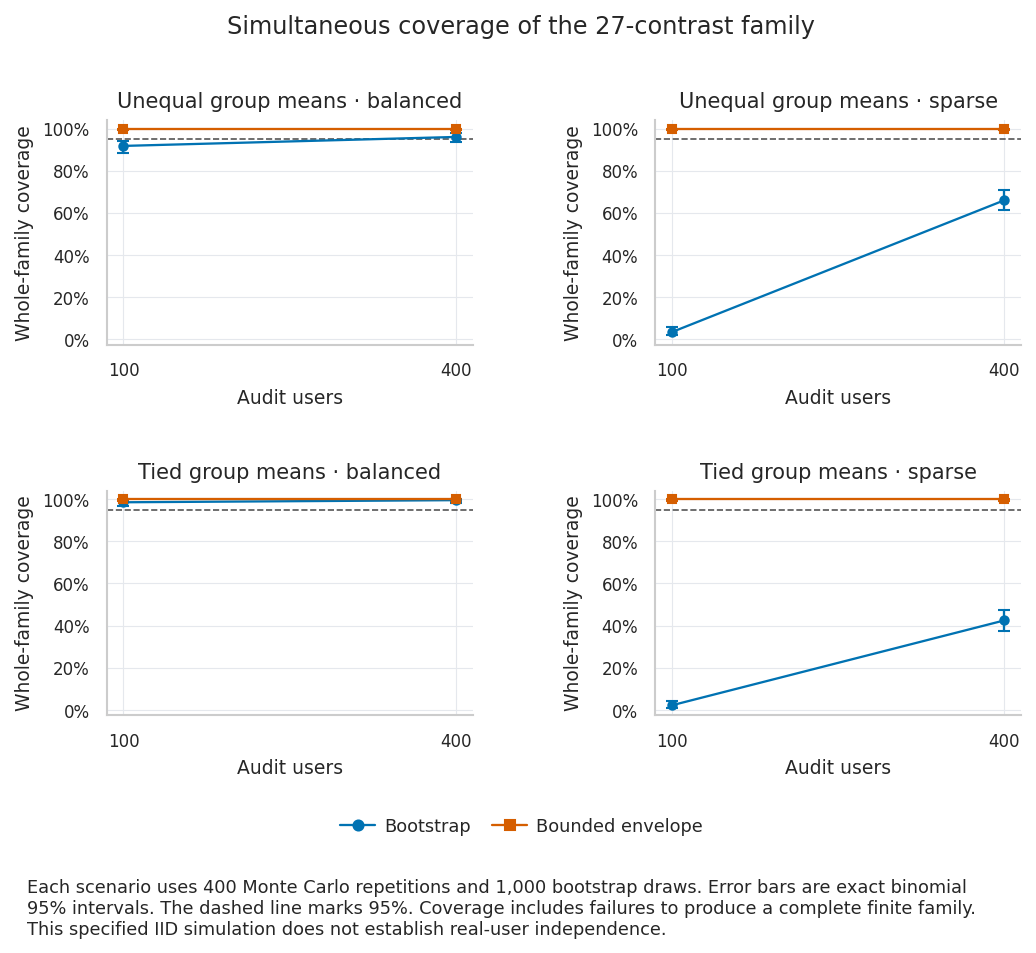

In [39]:
# Cell 2 — RQ2: readable full-family simulation coverage; original estimates and CIs.
fp_cov=fp_read('inference_full_family_calibration')
with mpl.rc_context(FP_STYLE):
    fig,axes=fp_figure(2,2,height=6.4,title='Simultaneous coverage of the 27-contrast family',bottom=.25)
    styles=[('legacy_bootstrap_max_deviation','Bootstrap','#0072B2','o'),
            ('simultaneous_Hoeffding_coordinate_envelope','Bounded envelope','#D55E00','s')]
    for row,tied in enumerate([False,True]):
        for col,sparse in enumerate([False,True]):
            ax=axes[row,col];q=fp_cov[(fp_cov.tied==tied)&(fp_cov.sparse_group==sparse)]
            for method,label,color,marker in styles:
                g=q[q.method==method].sort_values('n')
                ax.errorbar(g.n,g.coverage,yerr=[g.coverage-g.coverage_low,g.coverage_high-g.coverage],
                    marker=marker,color=color,ls='-',linewidth=1.1,capsize=3,markersize=4,label=label)
            ax.axhline(.95,color='#555555',ls='--',lw=.8)
            ax.set(title=('Tied' if tied else 'Unequal')+' group means · '+('sparse' if sparse else 'balanced'),
                   xlabel='Audit users',ylabel='Whole-family coverage',ylim=(-.025,1.04))
            ax.set_xticks(sorted(q.n.unique()));ax.yaxis.set_major_formatter(PercentFormatter(1));fp_grid(ax)
    fp_finish(fig,'Validation_Figure1_full_family_coverage',
        'Each scenario uses 400 Monte Carlo repetitions and 1,000 bootstrap draws. Error bars are exact binomial 95% intervals. The dashed line marks 95%. Coverage includes failures to produce a complete finite family. This specified IID simulation does not establish real-user independence.',
        handles=[Line2D([],[],color=c,marker=m,label=l,linewidth=1.1) for _,l,c,m in styles],ncol=2)


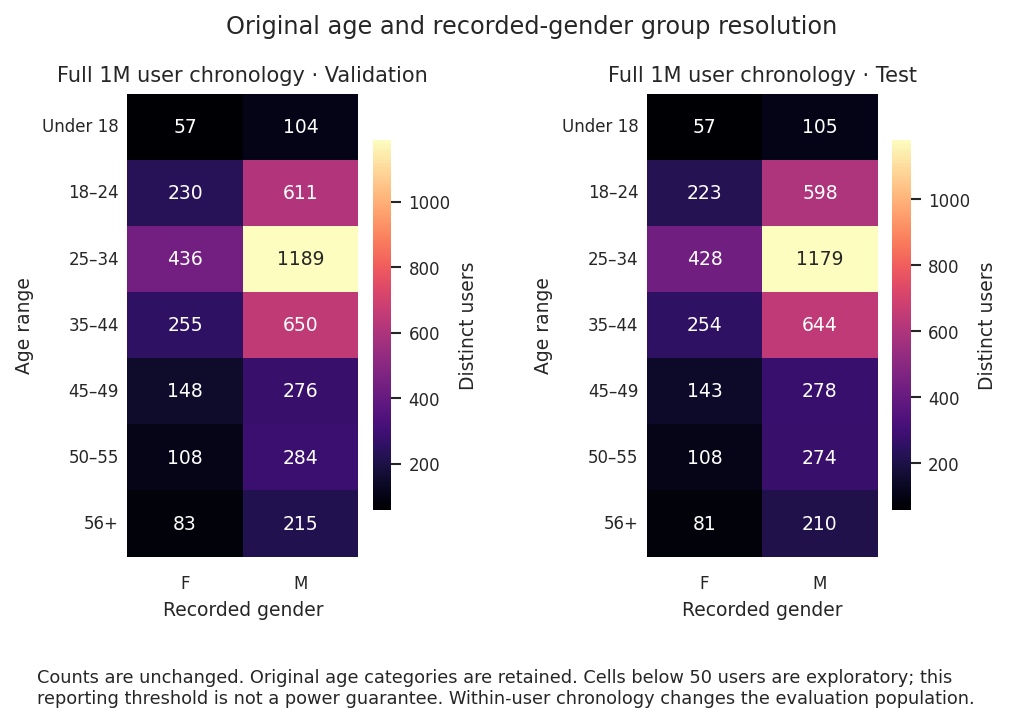

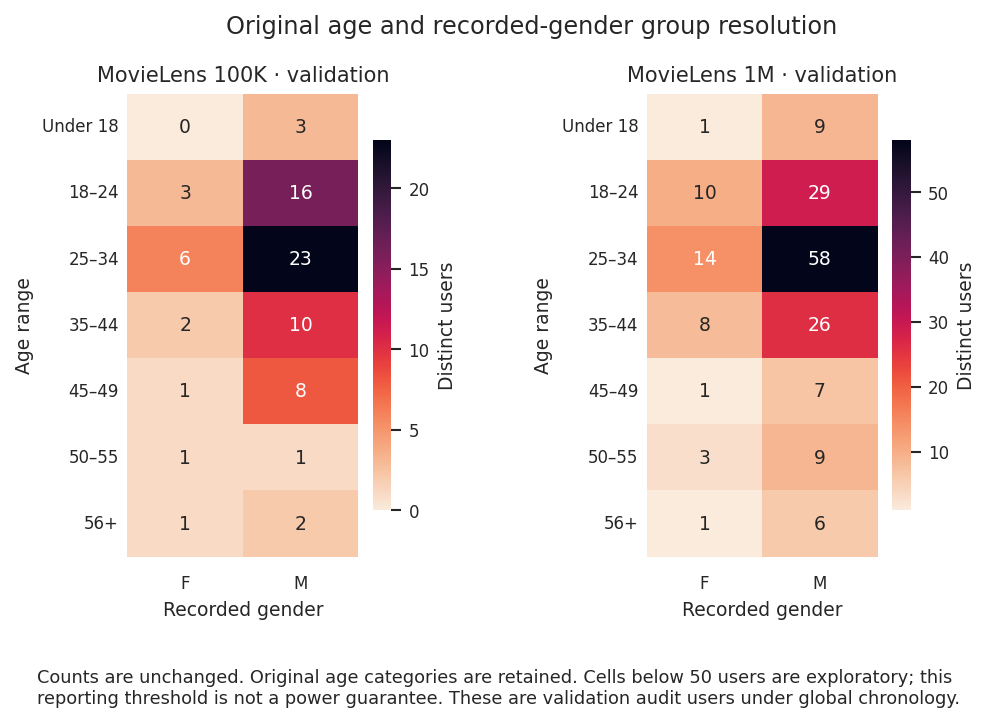

In [40]:
# Cell 3 — RQ4: horizontal age labels in both subgroup heatmaps; counts unchanged.
with mpl.rc_context(FP_STYLE):
    for name,dense in [('Dense_Figure1_group_resolution',True),('RQ4_Figure2_resolution_map',False)]:
        data=fp_read('Dense_RQ4_original_group_counts' if dense else 'RQ4_Table1_original_group_counts')
        fig,axes=fp_figure(1,2,height=4.8,title='Original age and recorded-gender group resolution',bottom=.22)
        for ax,tag in zip(axes[0],['val','test'] if dense else FP_DATASETS):
            if dense:
                q=data[data.window==tag];mat=q.pivot(index='age',columns='gender',values='distinct_users').reindex(list(FP_AGES))
                title='Full 1M user chronology · '+('Validation' if tag=='val' else 'Test')
            else:
                q=data[(data.dataset==tag)&(data.window=='val')&(data.attribute=='age_by_gender')].copy()
                q[['age','gender']]=q.group.str.split(':',expand=True);q.age=q.age.astype(int)
                mat=q.pivot(index='age',columns='gender',values='distinct_users').reindex(list(FP_AGES));title='MovieLens '+tag.upper()+' · validation'
            mat.index=mat.index.map(FP_AGES)
            sns.heatmap(mat,annot=True,fmt='.0f',cmap='magma' if dense else 'rocket_r',ax=ax,
                        annot_kws={'fontsize':9},cbar_kws={'label':'Distinct users','shrink':.8})
            ax.set(title=title,xlabel='Recorded gender',ylabel='Age range');ax.set_yticklabels(ax.get_yticklabels(),rotation=0)
            ax.tick_params(axis='y',length=0,pad=4)
        fig.subplots_adjust(left=.12,right=.88,wspace=.80)
        fp_finish(fig,name,'Counts are unchanged. Original age categories are retained. Cells below 50 users are exploratory; this reporting threshold is not a power guarantee. '+('Within-user chronology changes the evaluation population.' if dense else 'These are validation audit users under global chronology.'))


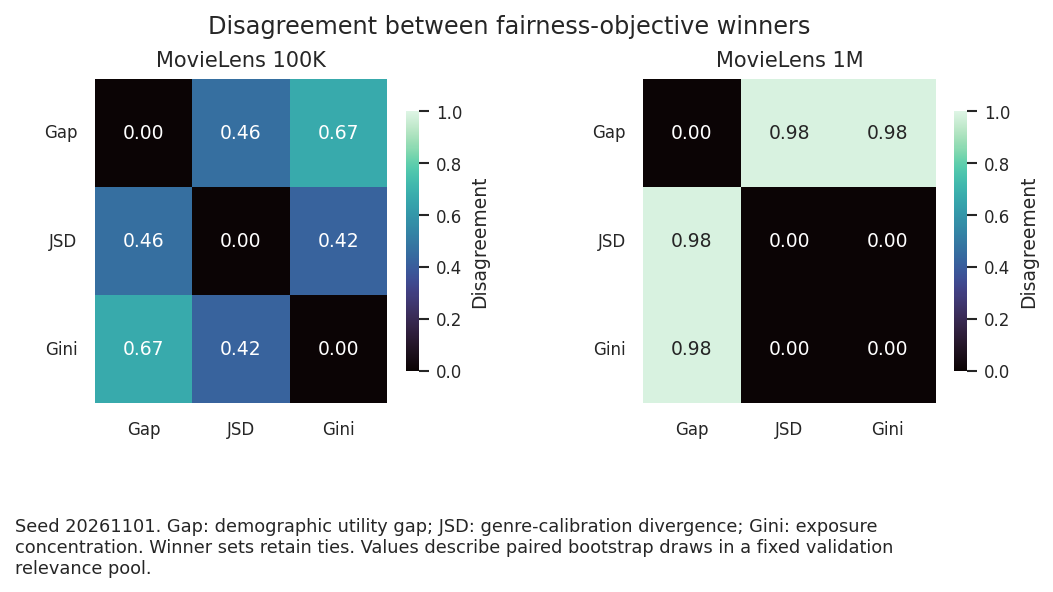

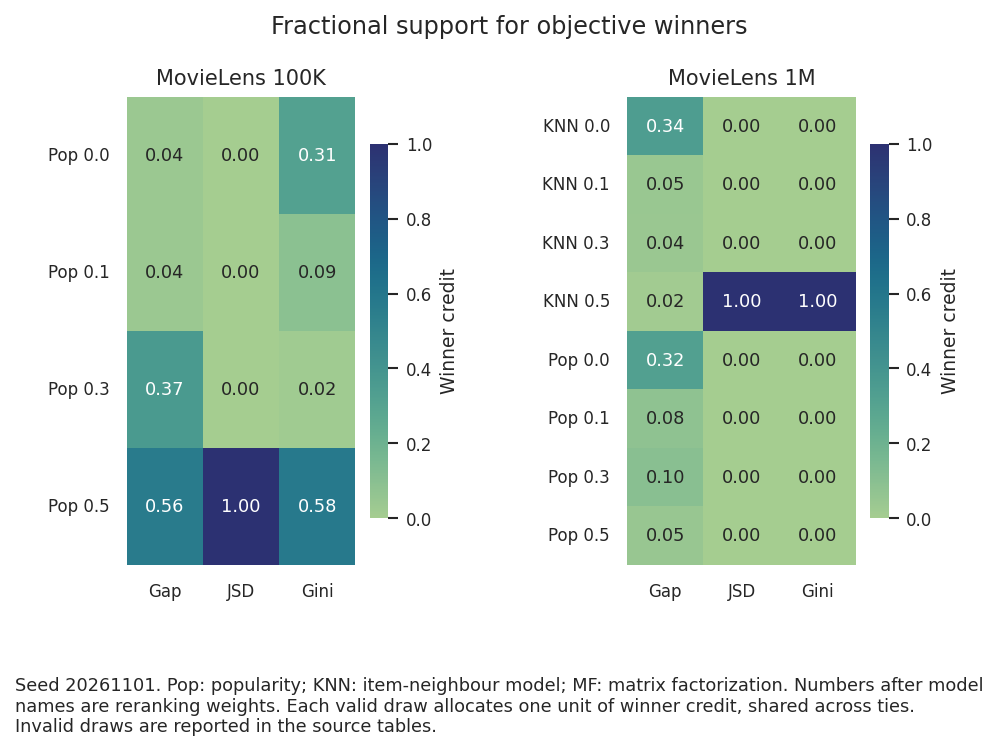

In [41]:
# Cell 4 — RQ1: compact scientific labels and legible heatmap annotations at print size.
with mpl.rc_context(FP_STYLE):
    data=fp_read('RQ1_objective_agreement')
    fig,axes=fp_figure(1,2,height=3.9,title='Disagreement between fairness-objective winners',bottom=.23)
    for ax,tag in zip(axes[0],FP_DATASETS):
        q=data[(data.dataset==tag)&(data.seed==FP_PRIMARY)]
        mat=q.pivot(index='objective_x',columns='objective_y',values='disagreement').reindex(index=[1,2,3],columns=[1,2,3])
        sns.heatmap(mat,annot=True,fmt='.2f',vmin=0,vmax=1,cmap='mako',ax=ax,
            xticklabels=['Gap','JSD','Gini'],yticklabels=['Gap','JSD','Gini'],annot_kws={'fontsize':9},
            cbar_kws={'label':'Disagreement','shrink':.8})
        ax.set(title='MovieLens '+tag.upper(),xlabel='',ylabel='');ax.tick_params(axis='y',rotation=0)
    fp_finish(fig,'RQ1_Figure1_disagreement',f'Seed {FP_PRIMARY}. Gap: demographic utility gap; JSD: genre-calibration divergence; Gini: exposure concentration. Winner sets retain ties. Values describe paired bootstrap draws in a fixed validation relevance pool.')
    data=fp_read('RQ1_winner_support')
    fig,axes=fp_figure(1,2,height=5.0,title='Fractional support for objective winners',bottom=.22)
    for ax,tag in zip(axes[0],FP_DATASETS):
        q=data[(data.dataset==tag)&(data.seed==FP_PRIMARY)]
        mat=q.pivot(index='candidate',columns='objective',values='fractional_winner_support').reindex(columns=['group_gap','genre_JSD','exposure_Gini'])
        mat.index=[s.replace('Popularity__lambda_','Pop ').replace('ItemKNN__lambda_','KNN ').replace('MF__lambda_','MF ') for s in mat.index]
        sns.heatmap(mat,annot=True,fmt='.2f',vmin=0,vmax=1,cmap='crest',ax=ax,
            xticklabels=['Gap','JSD','Gini'],annot_kws={'fontsize':8.5},cbar_kws={'label':'Winner credit','shrink':.8})
        ax.set(title='MovieLens '+tag.upper(),xlabel='',ylabel='');ax.tick_params(axis='y',rotation=0)
    fig.subplots_adjust(left=.14,right=.88,wspace=.75)
    fp_finish(fig,'RQ1_Figure2_winner_support',f'Seed {FP_PRIMARY}. Pop: popularity; KNN: item-neighbour model; MF: matrix factorization. Numbers after model names are reranking weights. Each valid draw allocates one unit of winner credit, shared across ties. Invalid draws are reported in the source tables.')


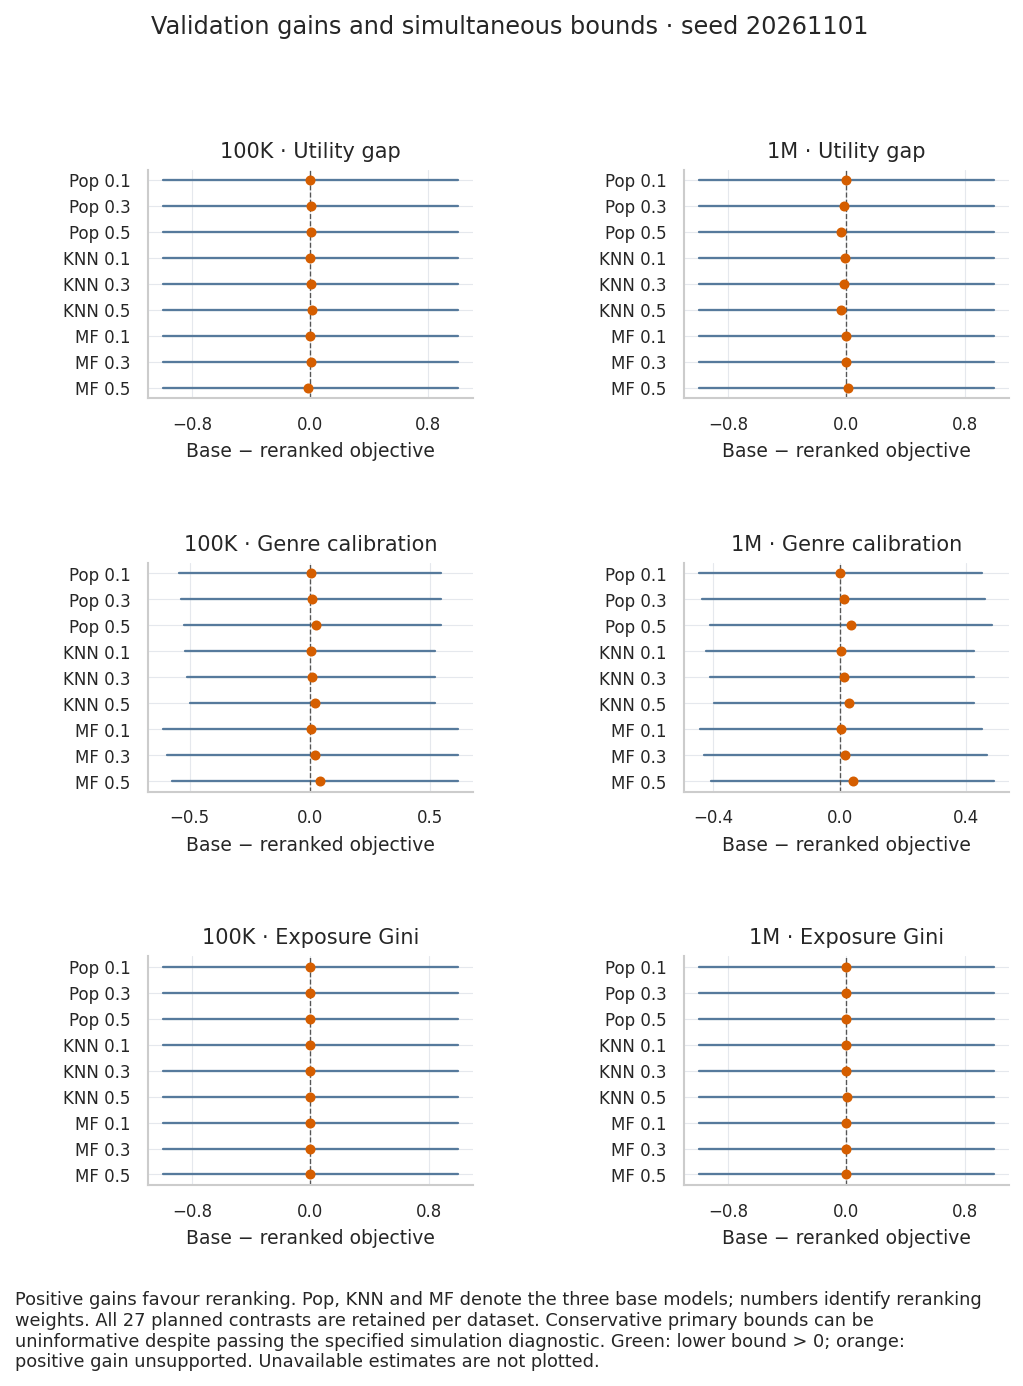

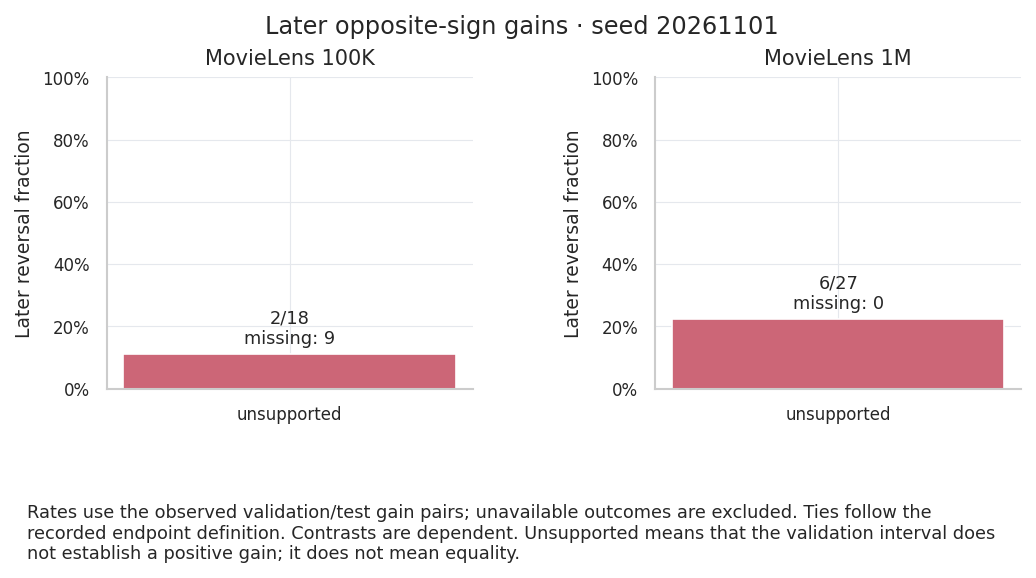

In [42]:
# Cell 5 — RQ2: readable primary contrast intervals and later reversal denominators.
with mpl.rc_context(FP_STYLE):
    data=fp_read('RQ2_Table1_simultaneous_contrasts')
    objectives=[('group_gap','Utility gap'),('genre_JSD','Genre calibration'),('exposure_Gini','Exposure Gini')]
    fig,axes=fp_figure(3,2,height=9.4,title=f'Validation gains and simultaneous bounds · seed {FP_PRIMARY}',bottom=.15)
    fig.subplots_adjust(left=.16,right=.97,hspace=.72,wspace=.65)
    for row,(objective,label) in enumerate(objectives):
        for col,tag in enumerate(FP_DATASETS):
            ax=axes[row,col];q=data[(data.dataset==tag)&(data.seed==FP_PRIMARY)&(data.objective==objective)].reset_index(drop=True)
            for j,r in q.iterrows():
                if np.isfinite(r.low) and np.isfinite(r.high):ax.plot([r.low,r.high],[j,j],color='#567A9C',lw=1.1)
                if np.isfinite(r.gain):ax.scatter(r.gain,j,s=16,color='#009E73' if r.low>0 else '#D55E00',zorder=3)
            labels=[r.reranker.replace('Popularity__lambda_','Pop ').replace('ItemKNN__lambda_','KNN ').replace('MF__lambda_','MF ') for r in q.itertuples()]
            ax.set_yticks(range(len(q)),labels);ax.invert_yaxis();ax.axvline(0,color='#555555',lw=.65,ls='--')
            ax.set_title(tag.upper()+' · '+label);ax.set_xlabel('Base − reranked objective');ax.xaxis.set_major_locator(MaxNLocator(3));fp_grid(ax)
    fp_finish(fig,'RQ2_Figure1_simultaneous_intervals','Positive gains favour reranking. Pop, KNN and MF denote the three base models; numbers identify reranking weights. All 27 planned contrasts are retained per dataset. Conservative primary bounds can be uninformative despite passing the specified simulation diagnostic. Green: lower bound > 0; orange: positive gain unsupported. Unavailable estimates are not plotted.')
    data=fp_read('Primary_RQ2_reversal_denominators')
    fig,axes=fp_figure(1,2,height=3.8,title=f'Later opposite-sign gains · seed {FP_PRIMARY}',bottom=.25)
    for ax,tag in zip(axes[0],FP_DATASETS):
        q=data[(data.dataset==tag)&(data.seed==FP_PRIMARY)]
        xx=np.arange(len(q));ax.bar(xx,q.reversal_rate,color='#CC6677',width=.6)
        for j,r in enumerate(q.itertuples()):
            if np.isfinite(r.reversal_rate):ax.annotate(f'{int(r.reversals)}/{int(r.observed)}\nmissing: {int(r.missing)}',(j,r.reversal_rate),xytext=(0,5),textcoords='offset points',ha='center',fontsize=8.5)
        ax.set_xticks(xx,q.validation_status);ax.set(title='MovieLens '+tag.upper(),ylabel='Later reversal fraction',ylim=(0,1));ax.yaxis.set_major_formatter(PercentFormatter(1));fp_grid(ax)
    fp_finish(fig,'RQ2_Figure2_later_reversals','Rates use the observed validation/test gain pairs; unavailable outcomes are excluded. Ties follow the recorded endpoint definition. Contrasts are dependent. Unsupported means that the validation interval does not establish a positive gain; it does not mean equality.')


In [43]:
# Cell 6 — RQ3/RQ5 and validation: seed panels and exact-coordinate overlap glyphs.
# This only defines plotting helpers; the next cells display the updated figures.
def fp_seed_scatter(data,name,title,x,y,xlabel,ylabel,datasets,colors,labels,key='rule',
                    keys=None,abbreviations=None,unit_x=False,unit_y=True,note=''):
    keys=list(colors) if keys is None else keys
    with mpl.rc_context(FP_STYLE):
        rows=len(datasets);height=6.8 if rows==2 else 4.4
        fig,axes=fp_figure(rows,3,height=height,title=title,bottom=.28 if rows==2 else .36)
        fig.subplots_adjust(left=.10,right=.97,wspace=.37,hspace=.62)
        for row,(tag,cohort_name) in enumerate(datasets):
            q=data[data.dataset==tag]
            finite=q.loc[np.isfinite(q[x])&np.isfinite(q[y])]
            if unit_x:limits=(-.06,1.06)
            elif len(finite):
                lo=float(finite[x].min());hi=float(finite[x].max());pad=max((hi-lo)*.18,.03)
                limits=(lo-pad,hi+pad)
            else:limits=(0,1)
            for col,seed in enumerate(FP_SEEDS):
                ax=axes[row,col];g=q[q.seed==seed]
                ax.set_xlim(*limits)
                if unit_y:ax.set_ylim(-.06,1.10)
                ax.set_title(f'{cohort_name} · S{col+1}',fontsize=9)
                ax.set_xlabel(xlabel,fontsize=8.5)
                if col==0:ax.set_ylabel(ylabel,fontsize=8.5)
                ax.xaxis.set_major_locator(MaxNLocator(3));ax.yaxis.set_major_locator(MaxNLocator(4))
                if not (np.isfinite(g[x])&np.isfinite(g[y])).any():
                    ax.text(.5,.5,'Not estimable',transform=ax.transAxes,ha='center',fontsize=9)
                else:fp_points(ax,g,x,y,key,colors,abbreviations)
        seeds='; '.join(f'S{i+1}={seed}' for i,seed in enumerate(FP_SEEDS))
        fp_finish(fig,name,note+' Exact coincidences use concentric coloured outlines; centres are unchanged. Ring diameter identifies overlap only, not magnitude; ×n counts coincident series. '+seeds+'.',
                  fp_handles(keys,colors,labels),ncol=3 if len(keys)>4 else len(keys))


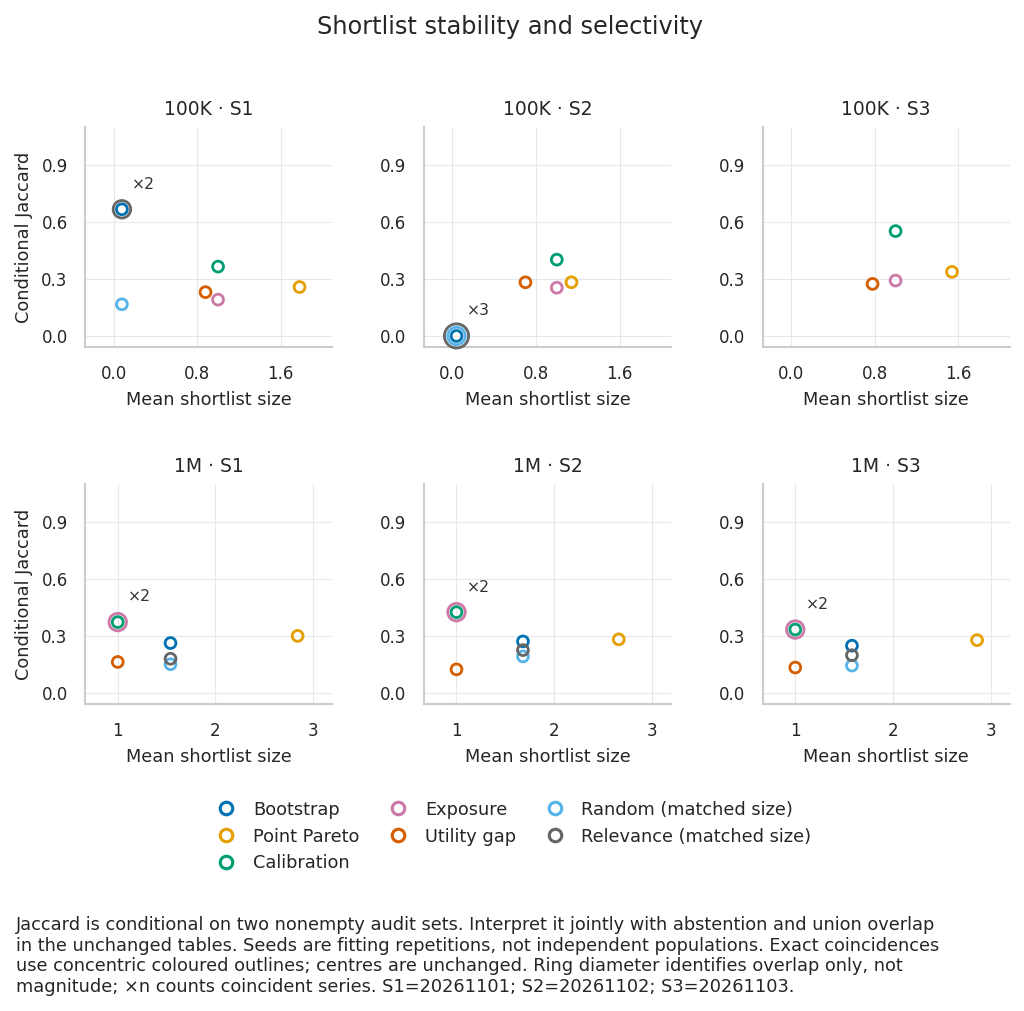

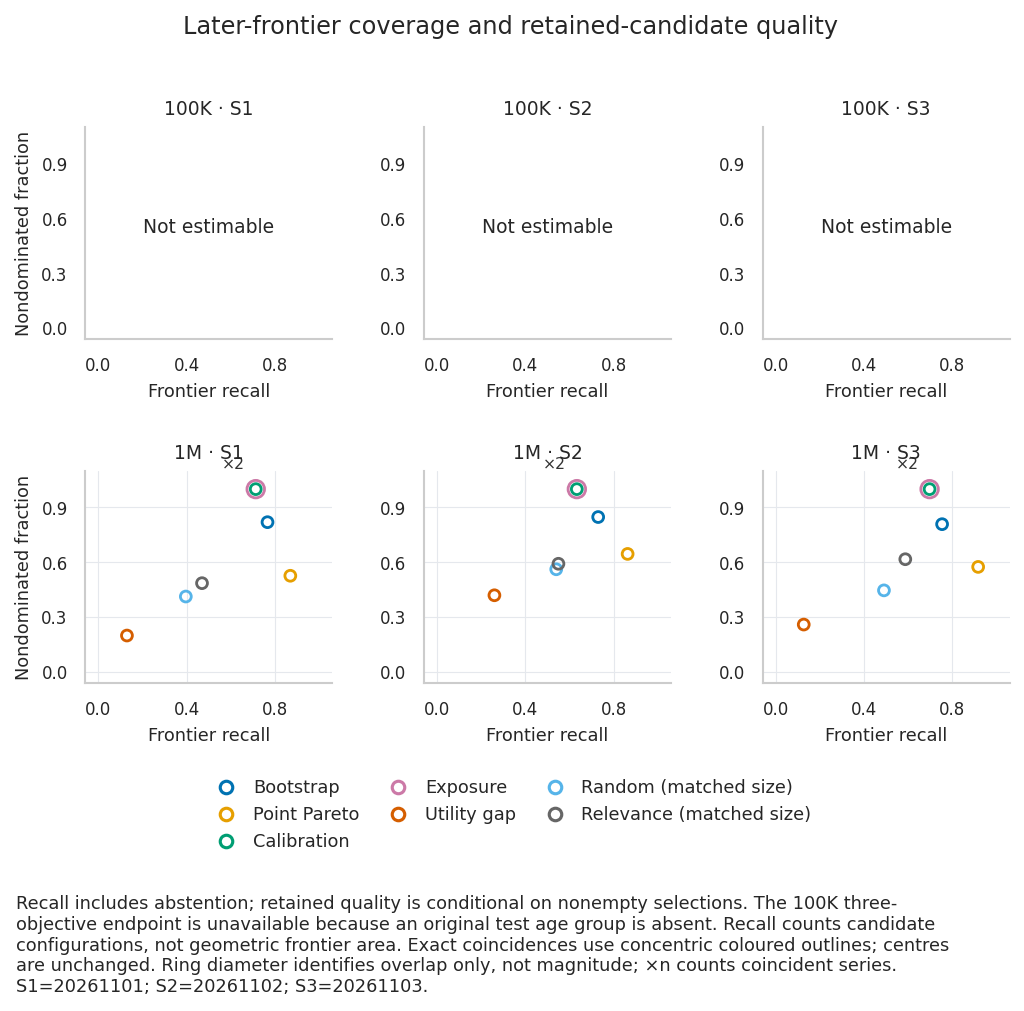

In [44]:
# Cell 7 — RQ3: stability/size and frontier coverage; no coordinate jitter.
fp_data=fp_read('RQ3_Table1_stability_selectivity_quality')
fp_seed_scatter(fp_data,'RQ3_Figure1_stability_size','Shortlist stability and selectivity',
    'mean_size','mean_jaccard','Mean shortlist size','Conditional Jaccard',
    [('100k','100K'),('1m','1M')],FP_COLORS,FP_LABELS,keys=FP_RULES,abbreviations=FP_ABBR,
    note='Jaccard is conditional on two nonempty audit sets. Interpret it jointly with abstention and union overlap in the unchanged tables. Seeds are fitting repetitions, not independent populations.')
fp_data=fp_read('RQ3_frontier_recall_and_retained_quality').copy()
fp_data['retained_quality']=1-fp_data.mean_dominated
fp_seed_scatter(fp_data,'RQ3_Figure3_frontier_coverage','Later-frontier coverage and retained-candidate quality',
    'mean_recall','retained_quality','Frontier recall','Nondominated fraction',
    [('100k','100K'),('1m','1M')],FP_COLORS,FP_LABELS,keys=FP_RULES,abbreviations=FP_ABBR,unit_x=True,
    note='Recall includes abstention; retained quality is conditional on nonempty selections. The 100K three-objective endpoint is unavailable because an original test age group is absent. Recall counts candidate configurations, not geometric frontier area.')


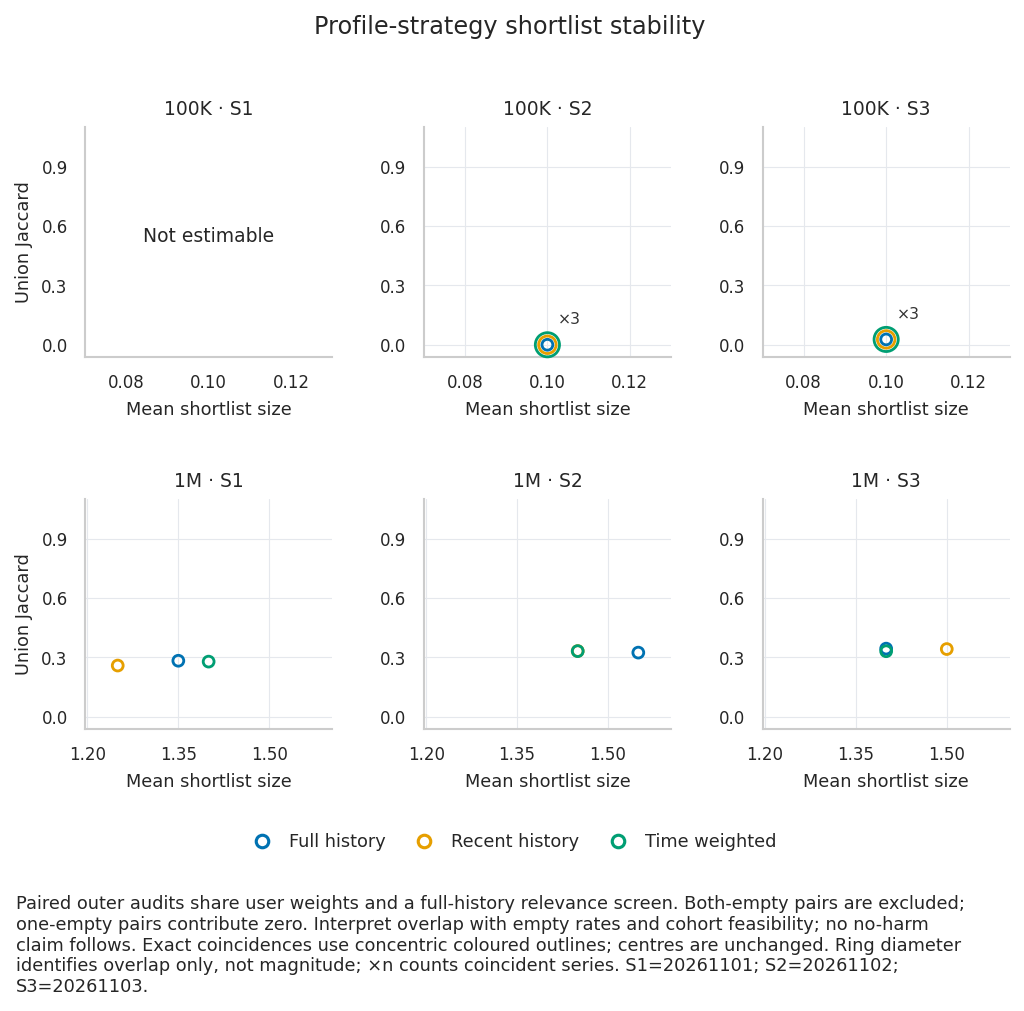

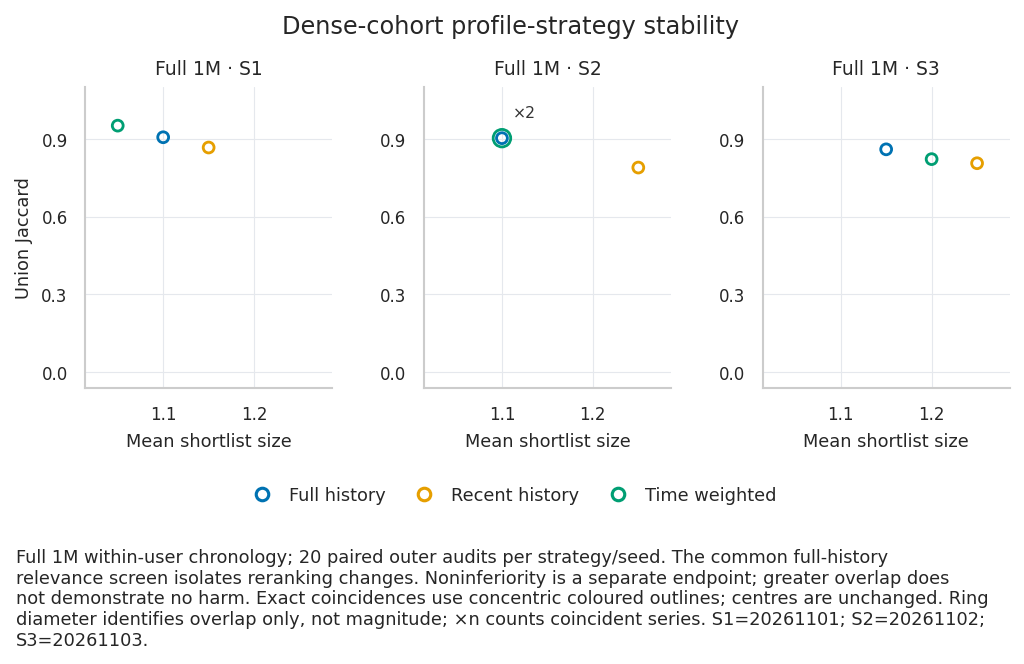

In [45]:
# Cell 8 — RQ5: strategy stability in separate seed panels; all saved values retained.
fp_data=fp_read('RQ5_profile_nested_stability')
fp_data=fp_data[(fp_data.rule=='Bootstrap')&(fp_data.pool_definition=='common_full_history_screen')]
fp_seed_scatter(fp_data,'RQ5_Figure3_profile_audit_stability','Profile-strategy shortlist stability',
    'mean_size','mean_union_jaccard','Mean shortlist size','Union Jaccard',
    [('100k','100K'),('1m','1M')],FP_PROFILE_COLORS,FP_PROFILE_LABELS,key='strategy',keys=FP_PROFILES,
    abbreviations={'full':'Full','recent':'Recent','weighted':'Weighted'},
    note='Paired outer audits share user weights and a full-history relevance screen. Both-empty pairs are excluded; one-empty pairs contribute zero. Interpret overlap with empty rates and cohort feasibility; no no-harm claim follows.')
fp_data=fp_read('Dense_RQ5_profile_stability')
fp_data=fp_data[(fp_data.rule=='Bootstrap')&(fp_data.pool_definition=='common_full_history_screen')].copy()
fp_data['dataset']='1m_userchron'
fp_seed_scatter(fp_data,'Dense_Figure2_profile_stability','Dense-cohort profile-strategy stability',
    'mean_size','mean_union_jaccard','Mean shortlist size','Union Jaccard',
    [('1m_userchron','Full 1M')],FP_PROFILE_COLORS,FP_PROFILE_LABELS,key='strategy',keys=FP_PROFILES,
    abbreviations={'full':'Full','recent':'Recent','weighted':'Weighted'},
    note='Full 1M within-user chronology; 20 paired outer audits per strategy/seed. The common full-history relevance screen isolates reranking changes. Noninferiority is a separate endpoint; greater overlap does not demonstrate no harm.')


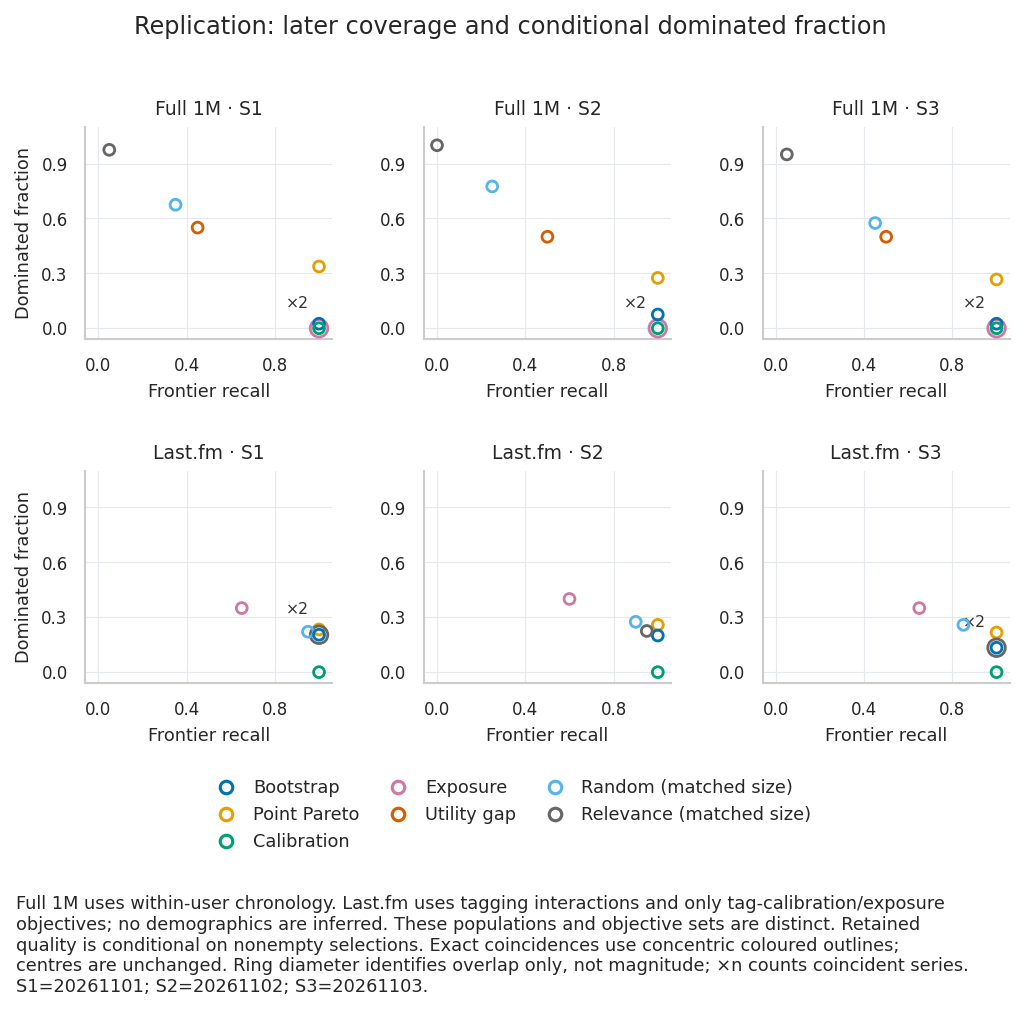

In [46]:
# Cell 9 — Partial-domain replication: consistent selector colours and separate seeds.
fp_data=fp_read('Replication_RQ3_stability')
fp_seed_scatter(fp_data,'Replication_Figure1_coverage_quality','Replication: later coverage and conditional dominated fraction',
    'mean_recall','mean_dominated','Frontier recall','Dominated fraction',
    [('1m_userchron','Full 1M'),('lastfm_tag','Last.fm')],FP_COLORS,FP_LABELS,keys=FP_RULES,abbreviations=FP_ABBR,unit_x=True,
    note='Full 1M uses within-user chronology. Last.fm uses tagging interactions and only tag-calibration/exposure objectives; no demographics are inferred. These populations and objective sets are distinct. Retained quality is conditional on nonempty selections.')


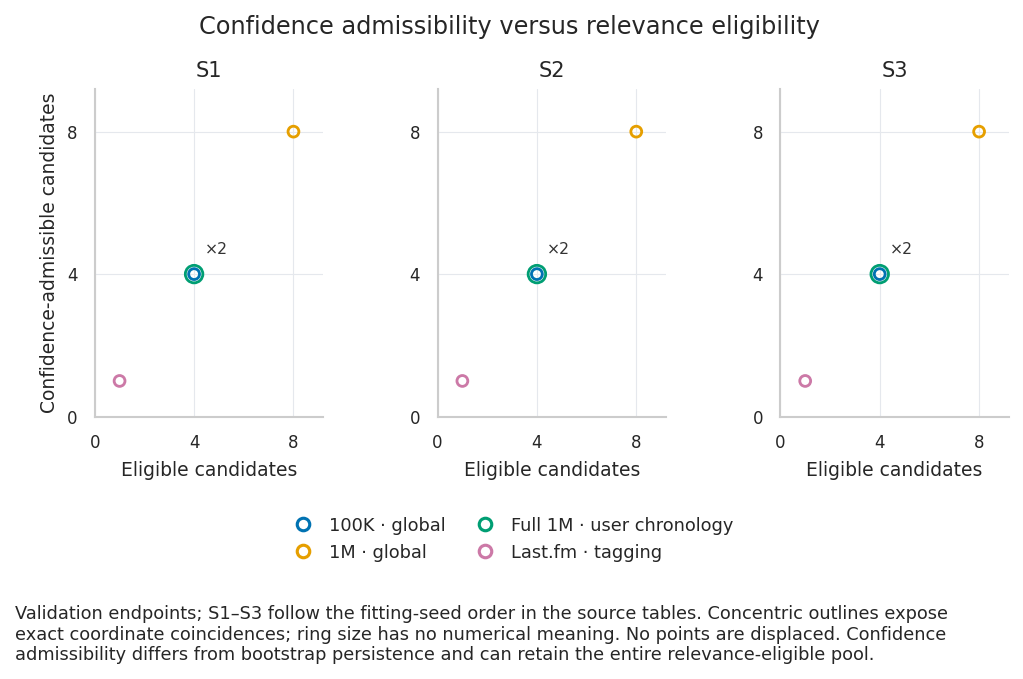

In [47]:
# Cell 10 — RQ2/RQ3: expose all overlapping support-versus-confidence points.
fp_data=fp_read('Selection_confidence_persistence_boundary')
fp_data=fp_data[fp_data.window=='val'].copy();fp_data['cohort']=fp_data.dataset;fp_data['dataset']='all'
fp_cohorts=['100k','1m','1m_userchron','lastfm_tag']
fp_cohort_colors=dict(zip(fp_cohorts,['#0072B2','#E69F00','#009E73','#CC79A7']))
fp_cohort_labels=dict(zip(fp_cohorts,['100K · global','1M · global','Full 1M · user chronology','Last.fm · tagging']))
# Custom layout avoids a long x-axis label in narrow seed panels.
with mpl.rc_context(FP_STYLE):
    fig,axes=fp_figure(1,3,height=4.5,title='Confidence admissibility versus relevance eligibility',bottom=.36)
    for col,seed in enumerate(FP_SEEDS):
        ax=axes[0,col];g=fp_data[fp_data.seed==seed]
        ax.set(xlim=(0,9.2),ylim=(0,9.2),title=f'S{col+1}',xlabel='Eligible candidates')
        if col==0:ax.set_ylabel('Confidence-admissible candidates')
        ax.set_xticks([0,4,8]);ax.set_yticks([0,4,8])
        fp_points(ax,g,'eligible','confidence_admissible_size','cohort',fp_cohort_colors,
                  {'100k':'100K','1m':'1M','1m_userchron':'Full 1M','lastfm_tag':'Last.fm'})
    fp_finish(fig,'Validation_Figure2_confidence_selectivity',
        'Validation endpoints; S1–S3 follow the fitting-seed order in the source tables. Concentric outlines expose exact coordinate coincidences; ring size has no numerical meaning. No points are displaced. Confidence admissibility differs from bootstrap persistence and can retain the entire relevance-eligible pool.',
        fp_handles(fp_cohorts,fp_cohort_colors,fp_cohort_labels),ncol=2)


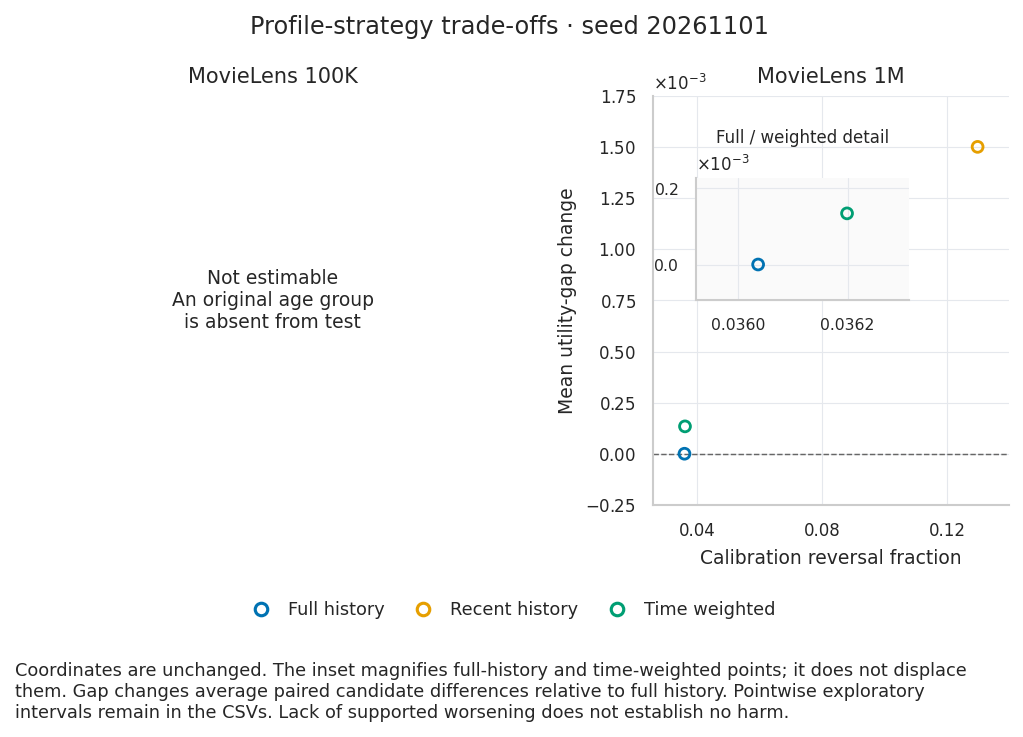

In [48]:
# Cell 11 — RQ5: exact profile trade-off coordinates, with a readable near-zero inset.
fp_profiles=fp_read('RQ5_profile_strategy_metrics');fp_gaps=fp_read('RQ5_paired_group_gap_changes')
fp_metrics=fp_read('all_candidate_metrics')
with mpl.rc_context(FP_STYLE):
    fig,axes=fp_figure(1,2,height=4.9,title=f'Profile-strategy trade-offs · seed {FP_PRIMARY}',bottom=.29)
    fig.subplots_adjust(wspace=.57)
    for ax,tag in zip(axes[0],FP_DATASETS):
        ax.set_title('MovieLens '+tag.upper())
        test=fp_metrics[(fp_metrics.dataset==tag)&(fp_metrics.seed==FP_PRIMARY)&(fp_metrics.window=='test')&(fp_metrics.K==10)]
        if test.empty or not np.isfinite(test.group_gap).all():
            ax.set_axis_off();ax.text(.5,.5,'Not estimable\nAn original age group\nis absent from test',transform=ax.transAxes,ha='center',va='center',fontsize=9);continue
        q=fp_profiles[(fp_profiles.dataset==tag)&(fp_profiles.seed==FP_PRIMARY)&(fp_profiles.window=='paired')]
        points=[]
        for mode in FP_PROFILES:
            x=q.loc[q.strategy==mode,'reversal_rate'];g=fp_gaps[(fp_gaps.dataset==tag)&(fp_gaps.seed==FP_PRIMARY)&(fp_gaps.strategy==mode)]
            y=0. if mode=='full' else g.gap_change.mean()
            if len(x) and np.isfinite(x.iloc[0]) and np.isfinite(y):points.append(dict(strategy=mode,x=float(x.iloc[0]),y=float(y)))
        points=pd.DataFrame(points)
        ax.set_xlim(points.x.min()-.01,points.x.max()+.01);ax.set_ylim(min(points.y.min(),0)-.00025,points.y.max()+.00025)
        fp_points(ax,points,'x','y','strategy',FP_PROFILE_COLORS)
        ax.axhline(0,color='#666666',ls='--',lw=.7)
        ax.set_xlabel('Calibration reversal fraction');ax.set_ylabel('Mean utility-gap change')
        ax.xaxis.set_major_locator(MaxNLocator(3));ax.ticklabel_format(axis='y',style='sci',scilimits=(-3,-3),useMathText=True)
        detail=points[points.strategy.isin(['full','weighted'])]
        if len(detail)==2:
            inset=ax.inset_axes([.12,.50,.60,.30]);inset.set_facecolor('#FAFAFA')
            dx=max(float(np.ptp(detail.x))*.7,.00005);dy=max(float(np.ptp(detail.y))*.7,.00002)
            inset.set_xlim(detail.x.min()-dx,detail.x.max()+dx);inset.set_ylim(detail.y.min()-dy,detail.y.max()+dy)
            fp_points(inset,detail,'x','y','strategy',FP_PROFILE_COLORS)
            inset.set_title('Full / weighted detail',fontsize=8);inset.tick_params(labelsize=7.5)
            inset.xaxis.set_major_locator(MaxNLocator(2));inset.yaxis.set_major_locator(MaxNLocator(2))
            inset.ticklabel_format(axis='y',style='sci',scilimits=(-3,-3),useMathText=True)
    fp_finish(fig,'RQ5_Figure2_profile_tradeoffs','Coordinates are unchanged. The inset magnifies full-history and time-weighted points; it does not displace them. Gap changes average paired candidate differences relative to full history. Pointwise exploratory intervals remain in the CSVs. Lack of supported worsening does not establish no harm.',
        fp_handles(FP_PROFILES,FP_PROFILE_COLORS,FP_PROFILE_LABELS),ncol=3)


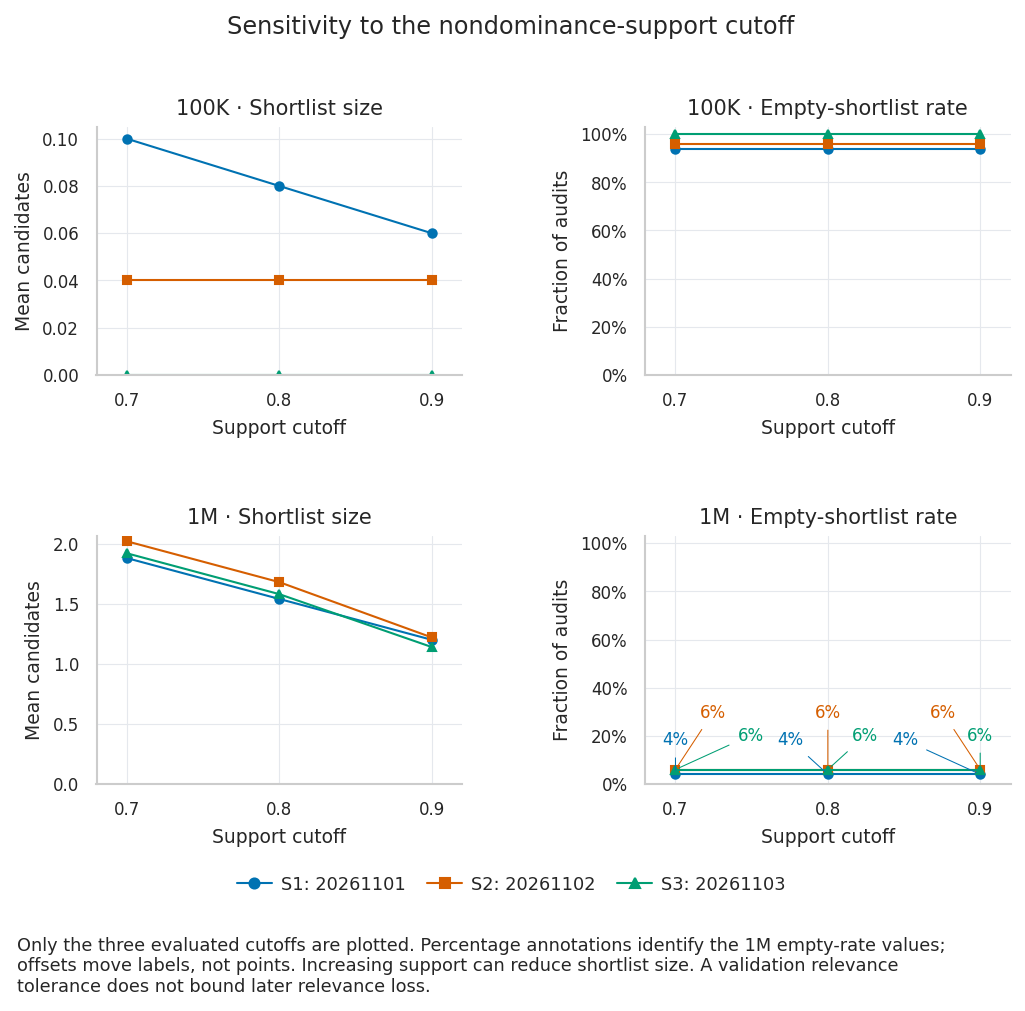

In [49]:
# Cell 12 — RQ3: support-cutoff sensitivity; evaluated cutoffs and values unchanged.
fp_thresholds=fp_read('RQ3_threshold_sensitivity')
fp_thresholds=fp_thresholds.groupby(['dataset','seed','threshold']).agg(mean_size=('size','mean'),empty_rate=('size',lambda x:np.mean(x==0))).reset_index()
fp_seed_colors=dict(zip(FP_SEEDS,['#0072B2','#D55E00','#009E73']))
with mpl.rc_context(FP_STYLE):
    fig,axes=fp_figure(2,2,height=6.8,title='Sensitivity to the nondominance-support cutoff',bottom=.22)
    for row,tag in enumerate(FP_DATASETS):
        for col,y in enumerate(['mean_size','empty_rate']):
            ax=axes[row,col]
            for j,seed in enumerate(FP_SEEDS):
                q=fp_thresholds[(fp_thresholds.dataset==tag)&(fp_thresholds.seed==seed)].sort_values('threshold')
                ax.plot(q.threshold,q[y],marker=['o','s','^'][j],markersize=4,color=fp_seed_colors[seed],lw=1)
                if tag=='1m' and y=='empty_rate':
                    for r in q.itertuples():
                        ax.annotate(f'{r.empty_rate:.0%}',(r.threshold,r.empty_rate),xytext=((([0,18,36] if r.threshold<.75 else [-36,-18,0] if r.threshold>.85 else [-18,0,18])[j]),(14,25,14)[j]),
                            textcoords='offset points',ha='center',fontsize=8,color=fp_seed_colors[seed],
                            arrowprops=dict(arrowstyle='-',color=fp_seed_colors[seed],lw=.5))
            ax.set_xticks(sorted(fp_thresholds.threshold.unique()));ax.set_xlim(.68,.92)
            ax.set_title(tag.upper()+' · '+('Shortlist size' if col==0 else 'Empty-shortlist rate'))
            ax.set_xlabel('Support cutoff');ax.set_ylabel('Mean candidates' if col==0 else 'Fraction of audits')
            if col:ax.set_ylim(0,1.03);ax.yaxis.set_major_formatter(PercentFormatter(1))
            else:ax.set_ylim(bottom=0)
            fp_grid(ax)
    fp_finish(fig,'RQ3_Figure2_threshold_sensitivity','Only the three evaluated cutoffs are plotted. Percentage annotations identify the 1M empty-rate values; offsets move labels, not points. Increasing support can reduce shortlist size. A validation relevance tolerance does not bound later relevance loss.',
        [Line2D([],[],color=fp_seed_colors[s],marker=['o','s','^'][j],label=f'S{j+1}: {s}',lw=1) for j,s in enumerate(FP_SEEDS)],ncol=3)


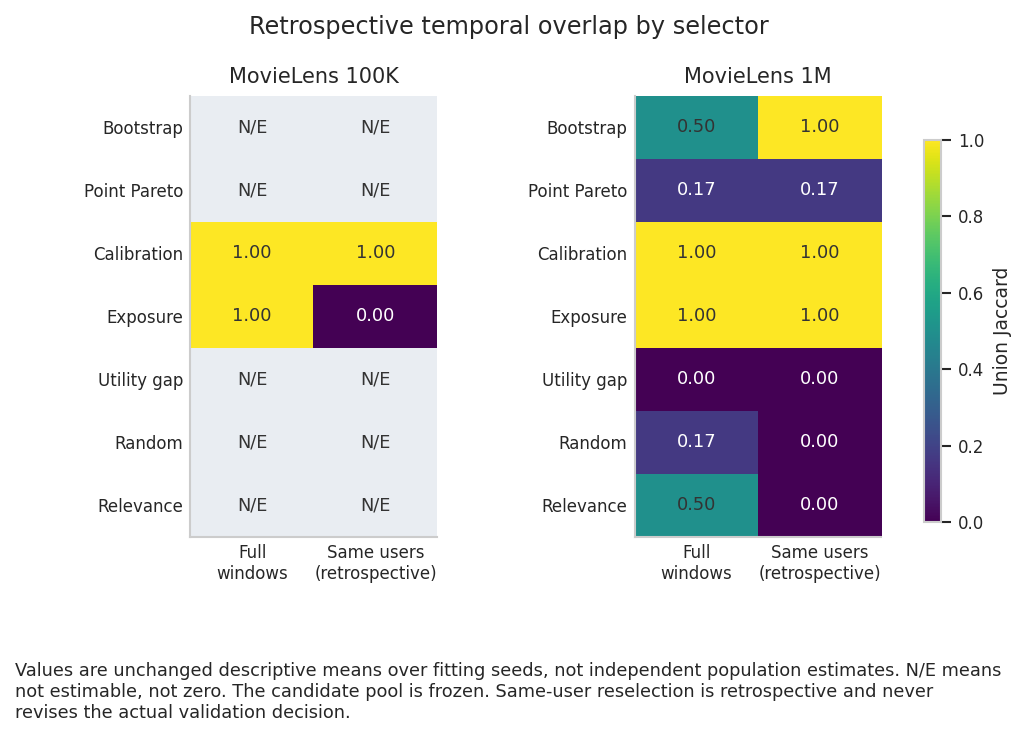

In [50]:
# Cell 13 — RQ3: readable temporal-overlap heatmap, preserving N/E outcomes.
fp_temporal=fp_read('RQ3_frozen_temporal_diagnostics')
fp_temporal=fp_temporal[(fp_temporal.metric_family=='three_fairness_objectives')&(fp_temporal.experiment=='main')]
with mpl.rc_context(FP_STYLE):
    fig,axes=fp_figure(1,2,height=4.9,title='Retrospective temporal overlap by selector',bottom=.27)
    fig.subplots_adjust(left=.20,right=.85,wspace=.80)
    for ax,tag in zip(axes[0],FP_DATASETS):
        q=fp_temporal[fp_temporal.dataset==tag]
        mat=q.groupby(['rule','scope']).union_jaccard.mean().unstack().reindex(index=FP_RULES,columns=['full_windows','same_users_retrospective'])
        cmap=mpl.colormaps['viridis'].copy();cmap.set_bad('#E9EDF2')
        im=ax.imshow(np.ma.masked_invalid(mat.to_numpy()),vmin=0,vmax=1,cmap=cmap,aspect='auto')
        for i in range(len(mat)):
            for j in range(2):
                v=mat.iloc[i,j];ax.text(j,i,f'{v:.2f}' if np.isfinite(v) else 'N/E',ha='center',va='center',fontsize=8.5,color='white' if np.isfinite(v) and v<.45 else '#333333')
        ax.set_yticks(range(len(mat)),[FP_LABELS[k].replace(' (matched size)','') for k in FP_RULES]);ax.set_xticks([0,1],['Full\nwindows','Same users\n(retrospective)'])
        ax.set_title('MovieLens '+tag.upper());ax.tick_params(length=0)
    cax=fig.add_axes([.89,.29,.016,.52]);fig.colorbar(im,cax=cax,label='Union Jaccard')
    fp_finish(fig,'RQ3_Figure4_comparative_turnover','Values are unchanged descriptive means over fitting seeds, not independent population estimates. N/E means not estimable, not zero. The candidate pool is frozen. Same-user reselection is retrospective and never revises the actual validation decision.')


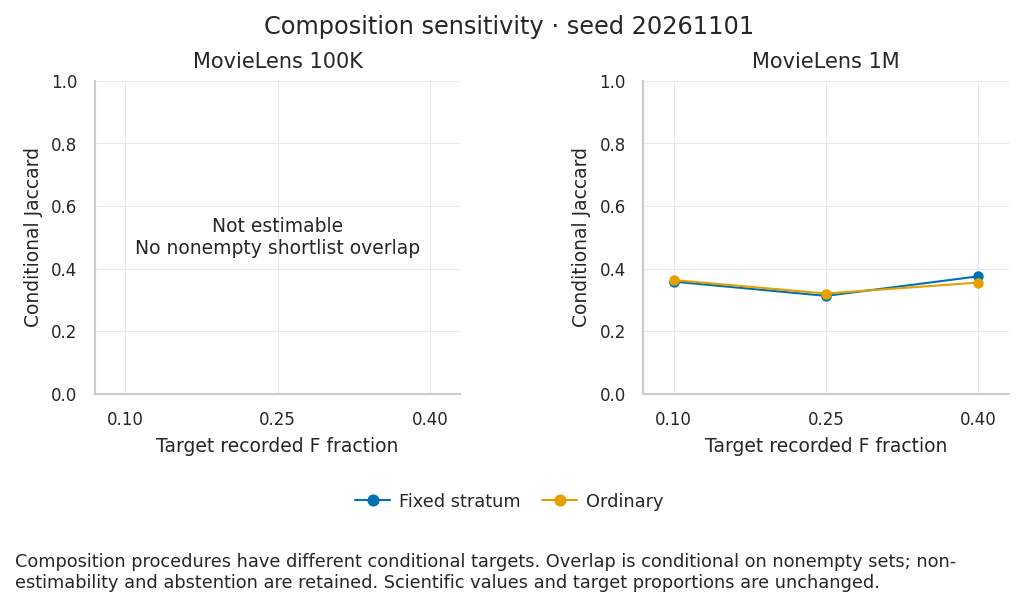

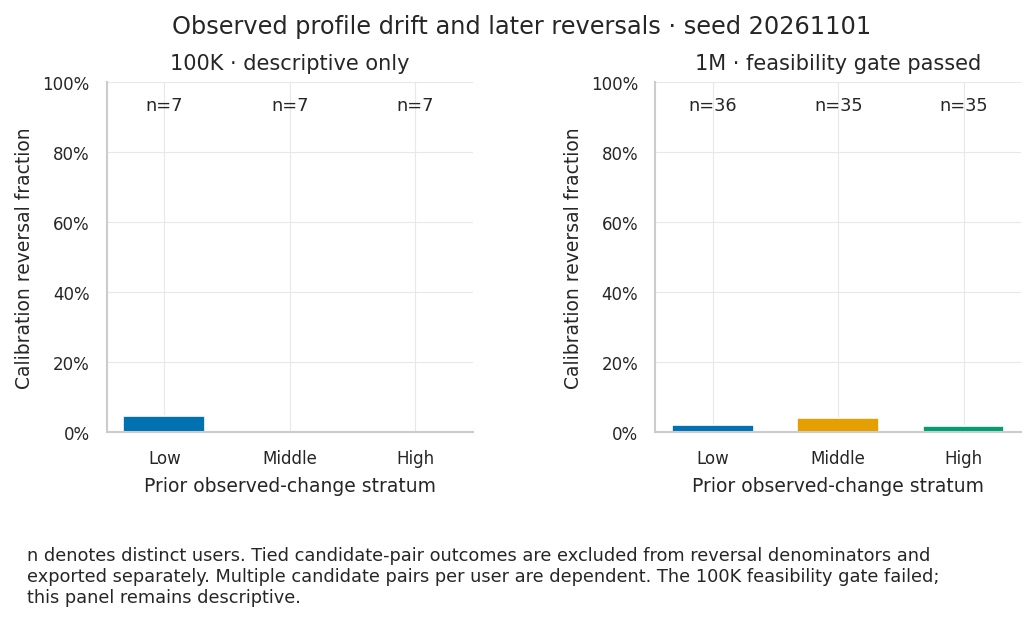

In [51]:
# Cell 14 — RQ4/RQ5: legible composition stress and drift-stratum summaries.
with mpl.rc_context(FP_STYLE):
    data=fp_read('RQ4_Table2_composition_resampling')
    fig,axes=fp_figure(1,2,height=4.0,title=f'Composition sensitivity · seed {FP_PRIMARY}',bottom=.28)
    colors={'fixed_stratum':'#0072B2','ordinary':'#E69F00'}
    for ax,tag in zip(axes[0],FP_DATASETS):
        q=data[(data.dataset==tag)&(data.seed==FP_PRIMARY)]
        if not q.mean_overlap.notna().any():ax.text(.5,.5,'Not estimable\nNo nonempty shortlist overlap',transform=ax.transAxes,ha='center',va='center',fontsize=9)
        else:
            for method,g in q.groupby('method'):
                g=g.sort_values('F_share');ax.plot(g.F_share,g.mean_overlap,color=colors[method],marker='o',lw=1,markersize=4)
        ax.set(title='MovieLens '+tag.upper(),xlabel='Target recorded F fraction',ylabel='Conditional Jaccard',ylim=(0,1),xlim=(.07,.43));ax.set_xticks([.1,.25,.4]);fp_grid(ax)
    fp_finish(fig,'RQ4_Figure1_composition_stress','Composition procedures have different conditional targets. Overlap is conditional on nonempty sets; non-estimability and abstention are retained. Scientific values and target proportions are unchanged.',
        [Line2D([],[],color=colors[k],marker='o',label={'fixed_stratum':'Fixed stratum','ordinary':'Ordinary'}[k],lw=1) for k in colors],ncol=2)
    data=fp_read('RQ5_prior_change_strata')
    fig,axes=fp_figure(1,2,height=4.1,title=f'Observed profile drift and later reversals · seed {FP_PRIMARY}',bottom=.25)
    for ax,tag in zip(axes[0],FP_DATASETS):
        q=data[(data.dataset==tag)&(data.seed==FP_PRIMARY)].sort_values('stratum')
        ax.bar(q.stratum,q.reversal_rate,color=['#0072B2','#E69F00','#009E73'],width=.65)
        for r in q.itertuples():ax.text(r.stratum,.96,f'n={int(r.distinct_users)}',ha='center',va='top',fontsize=8.5)
        ax.set_xticks([0,1,2],['Low','Middle','High']);ax.set_ylim(0,1);ax.yaxis.set_major_formatter(PercentFormatter(1))
        ax.set(title=tag.upper()+(' · descriptive only' if not q.feasible.all() else ' · feasibility gate passed'),xlabel='Prior observed-change stratum',ylabel='Calibration reversal fraction');fp_grid(ax)
    fp_finish(fig,'RQ5_Figure1_prior_change','n denotes distinct users. Tied candidate-pair outcomes are excluded from reversal denominators and exported separately. Multiple candidate pairs per user are dependent. The 100K feasibility gate failed; this panel remains descriptive.')


In [52]:
# Cell 15 — RQ1–RQ5: verify unchanged scientific tables and package the FULL updated run.
# This includes every original result, all updated PDFs, reference code and manifests.
# Run AFTER all preceding figure cells. Original results and original ZIP are preserved.
missing=[name for name in FP_TARGETS if name not in FP_META['figures']]
if missing:raise RuntimeError('Run the remaining figure cells first: '+', '.join(missing))
for name in FP_TARGETS:
    entry=FP_META['figures'][name]
    assert hashlib.sha256((FP_ROOT/entry['path']).read_bytes()).hexdigest()==entry['updated_sha256'],name
for name,digest in FP_SOURCE_TABLE_HASHES.items():
    if name=='displayed_output_inventory.csv':continue
    assert hashlib.sha256((FP_ROOT/'tables'/name).read_bytes()).hexdigest()==digest,'Source table changed: '+name
# Update only display-inventory captions, which are presentation metadata.
inventory_path=FP_ROOT/'tables/displayed_output_inventory.csv'
if inventory_path.is_file():
    inventory=pd.read_csv(inventory_path)
    if {'kind','name','caption'}.issubset(inventory.columns):
        for name,entry in FP_META['figures'].items():
            inventory.loc[(inventory.kind=='figure')&(inventory.name==name),'caption']=entry['caption']
        inventory.to_csv(inventory_path,index=False)
# Synchronize the earlier layout manifest so no recorded PDF hash is stale.
old_patch=FP_ROOT/'manifest/figure_layout_patch.json'
if old_patch.is_file():
    metadata=json.loads(old_patch.read_text())
    metadata['prior_source_run']=metadata.get('source_run');metadata['source_run']=FP_ROOT.name
    metadata['source_experiment_root']=FP_SOURCE.name
    for name,entry in metadata.get('figures',{}).items():
        if name in FP_META['figures']:
            new=FP_META['figures'][name]
            entry.update(updated_sha256=new['updated_sha256'],updated_utc=new['updated_utc'],caption=new['caption'])
    metadata['superseded_by']='publication_readability_v2'
    old_patch.write_text(json.dumps(metadata,indent=2))
FP_META.update(completed=True,completed_utc=datetime.now(timezone.utc).isoformat(),
    scientific_tables_unchanged=True,display_inventory_captions_updated=True,
    changed_figures=len(FP_TARGETS),source_run_completed=True,
    scientific_interpretation='Presentation-only update; no new scientific claims or publication certification.')
FP_LOG.write_text(json.dumps(FP_META,indent=2))
# Verify all scientific CSVs remain byte-identical, excluding only caption metadata.
for name,digest in FP_SOURCE_TABLE_HASHES.items():
    if name!='displayed_output_inventory.csv':
        assert hashlib.sha256((FP_ROOT/'tables'/name).read_bytes()).hexdigest()==digest,name
index_path=FP_ROOT/'manifest/output_checksums.json'
entries=[dict(path=str(p.relative_to(FP_ROOT)),bytes=p.stat().st_size,
              sha256=hashlib.sha256(p.read_bytes()).hexdigest())
         for p in sorted(FP_ROOT.rglob('*')) if p.is_file() and p!=index_path]
index_path.write_text(json.dumps(entries,indent=2))
FP_ZIP=FP_WORK/f'Phantom_Troupe_Project9_Full_Results_Readability_v2_{FP_SOURCE.name.removeprefix("phantom_troupe_feasibility_revision_")}.zip'
temporary=FP_ZIP.with_suffix('.zip.tmp')
try:
    with zipfile.ZipFile(temporary,'w',compression=zipfile.ZIP_DEFLATED) as archive:
        for path in sorted(FP_ROOT.rglob('*')):
            if path.is_file():archive.write(path,arcname=str(Path(FP_ROOT.name)/path.relative_to(FP_ROOT)))
    with zipfile.ZipFile(temporary) as archive:
        assert archive.testzip() is None
        for entry in entries:
            member=str(Path(FP_ROOT.name)/entry['path'])
            assert hashlib.sha256(archive.read(member)).hexdigest()==entry['sha256'],member
    os.replace(temporary,FP_ZIP)
finally:
    if temporary.exists():temporary.unlink()
print('Updated figures:',len(FP_TARGETS))
print('All scientific CSV tables remain unchanged; all archive checksums pass.')
print('FULL updated results ZIP:',FP_ZIP)
# Relative link is a convenience; Kaggle Output download is the reliable fallback.
os.chdir(FP_WORK);display(FileLink(FP_ZIP.name))
print('Save a Kaggle version, then download this ZIP from the saved version Output files.')
print('Use figures at 180 mm width. Check your final LaTeX/Word PDF after placement; shrinking changes effective type size.')


Updated figures: 18
All scientific CSV tables remain unchanged; all archive checksums pass.
FULL updated results ZIP: /kaggle/working/Phantom_Troupe_Project9_Full_Results_Readability_v2_20261109T180151_afe6d1.zip


/kaggle/working/Phantom_Troupe_Project9_Full_Results_Readability_v2_20261109T180151_afe6d1.zip

Save a Kaggle version, then download this ZIP from the saved version Output files.
Use figures at 180 mm width. Check your final LaTeX/Word PDF after placement; shrinking changes effective type size.
